OEE & DOWNTIME ANALYSIS - DATA AUDIT
Python version: 3.13.18 (main, Oct 28 2026, 14:29:13) [GCC 12.2.0]
Pandas version: 2.2.3
NumPy version: 2.4.6
Working directory: /datasets/_deepnote_work

FILES SUCCESSFULLY IMPORTED
production_records: 270 rows x 17 columns
downtime_events: 824 rows x 12 columns
product_master: 5 rows x 7 columns
equipment_master: 1 rows x 12 columns

CHECKING REQUIRED COLUMNS
production_records OK
downtime_events OK
product_master OK
equipment_master OK

DATA QUALITY AUDIT

--- PRODUCTION_RECORDS ---
Rows: 270
Columns: 17
Missing values: 11
Exact duplicate rows: 0

--- DOWNTIME_EVENTS ---
Rows: 824
Columns: 12
Missing values: 668
Exact duplicate rows: 0

--- PRODUCT_MASTER ---
Rows: 5
Columns: 7
Missing values: 0
Exact duplicate rows: 0

--- EQUIPMENT_MASTER ---
Rows: 1
Columns: 12
Missing values: 0
Exact duplicate rows: 0

STRING CONSISTENCY / POSSIBLE TYPO DETECTION
           File            Column                    Original_Value                  Normalized_V

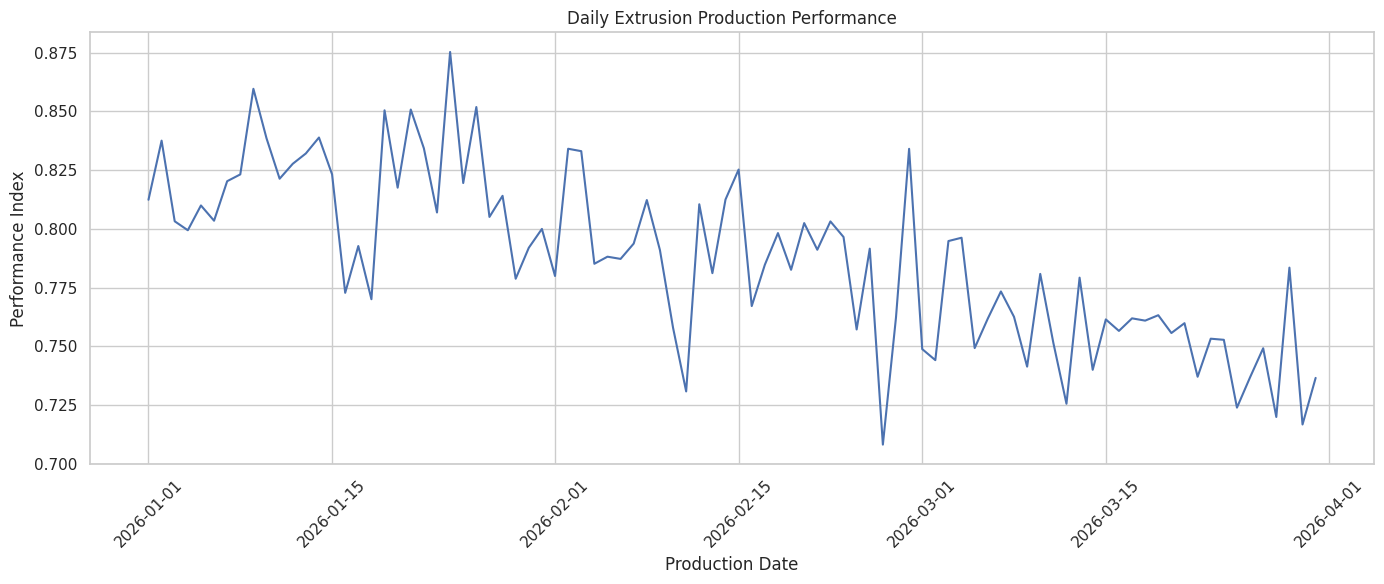

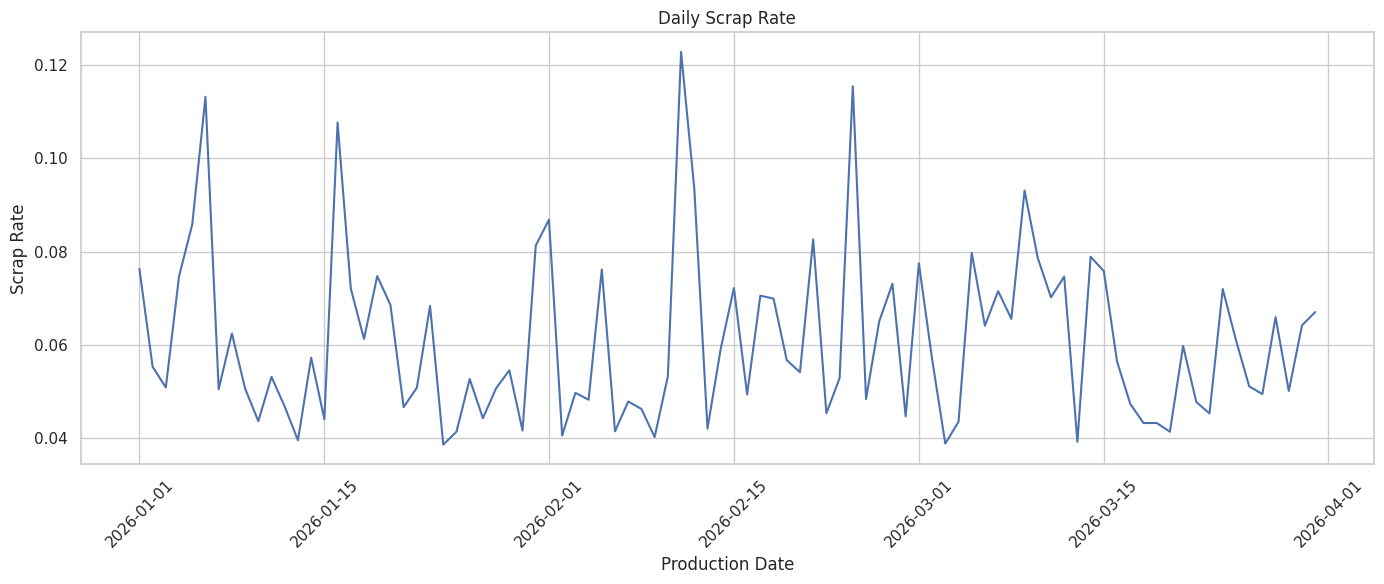

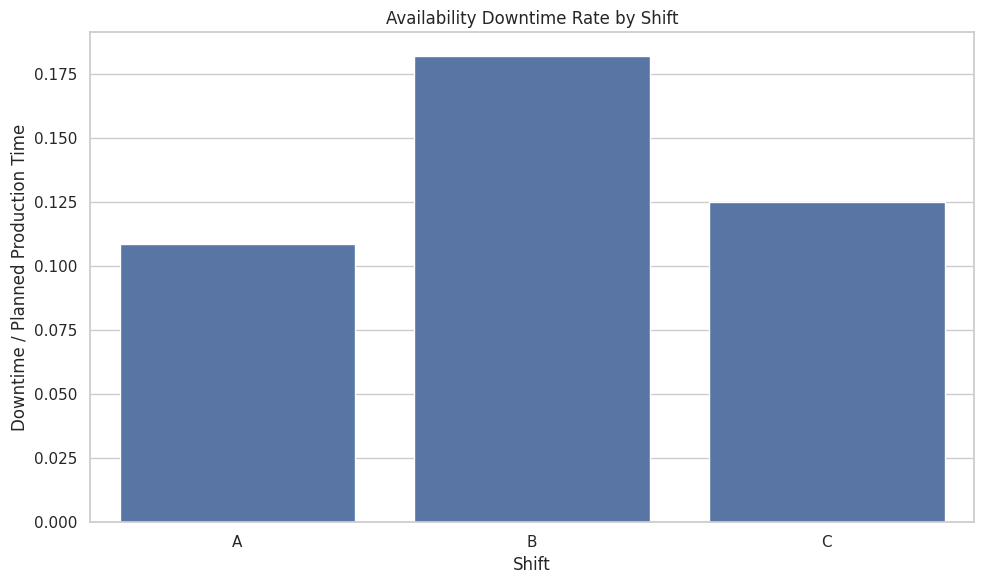

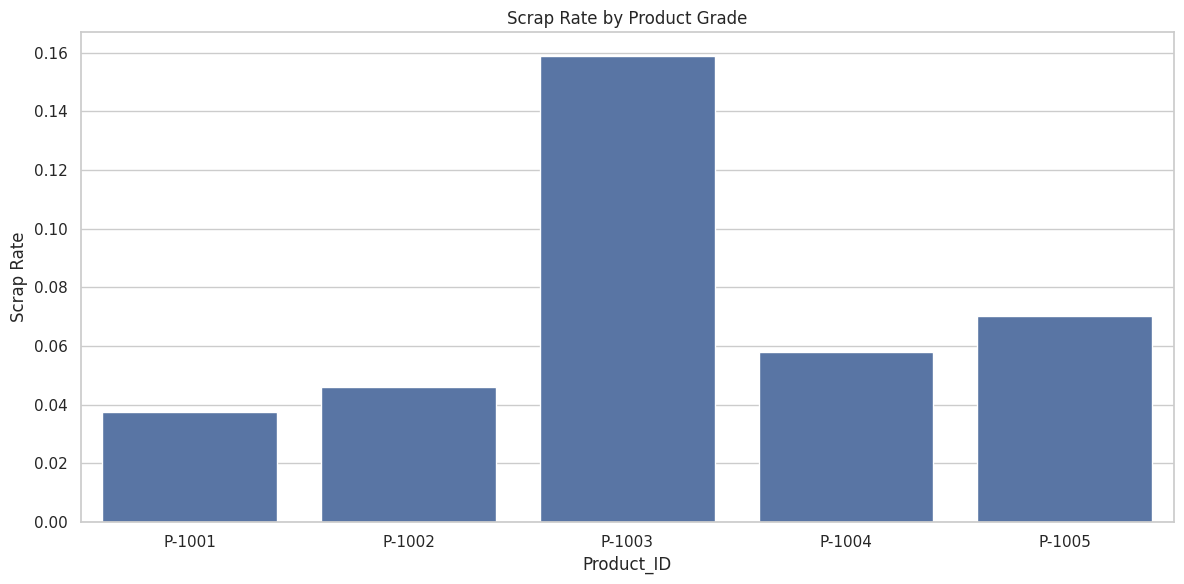

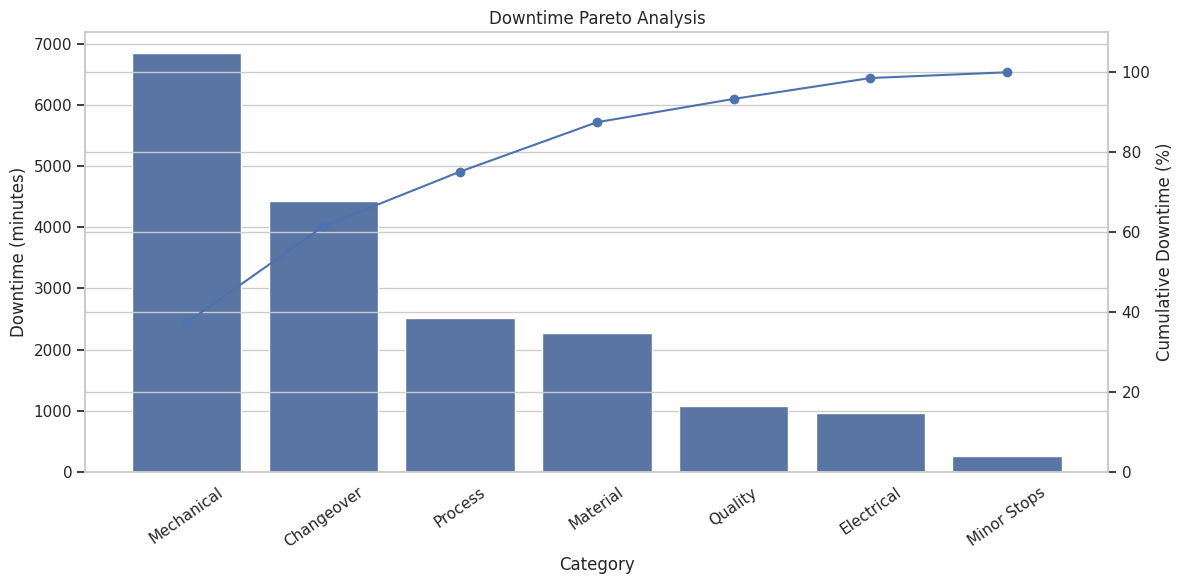

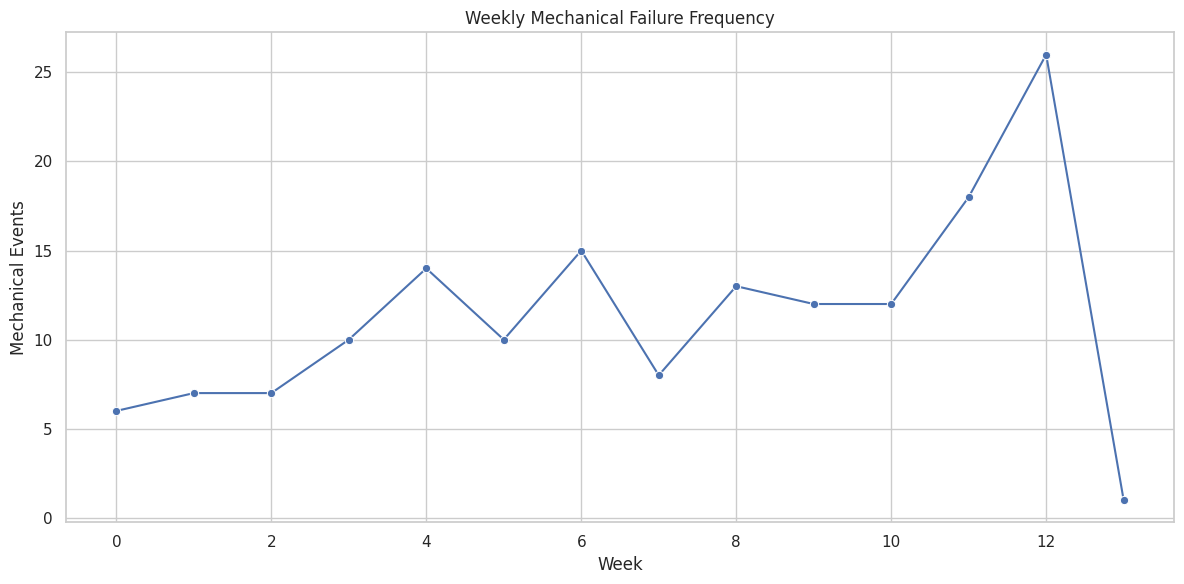


INVESTIGATION OF EXPECTED OPERATIONAL PATTERNS
                       Pattern                                        Observed_Result                                                         Interpretation
     Shift B elevated downtime          Shift B: 18.20%; other shifts average: 11.66%                                    Compare shift-level downtime rates.
         P-1003 elevated scrap            P-1003: 15.90%; other grades average: 5.29%                 Investigate grade-specific startup and quality losses.
Production speed deterioration                           Spearman correlation: -0.771       Negative correlation indicates decreasing performance over time.
  Mechanical failure frequency                            Spearman correlation: 0.426 Positive correlation suggests increasing mechanical failure frequency.
 Extended changeover durations Actual average: 34.47 min; standard average: 19.80 min        Compare observed changeover time with product master standards.

EXPORTING

In [1]:
# ================================================================
# MANUFACTURING & MATERIALS ANALYTICS LLC
# PROJECT 001: OEE & DOWNTIME ANALYSIS
# DATA QUALITY AUDIT + EXPLORATORY DATA ANALYSIS
# ================================================================

# IMPORTANT DEPENDENCY NOTE:
# Do not install/downgrade NumPy inside the same running kernel as this analysis.
# The previous pinned %pip install replaced NumPy files while the kernel still
# held the old NumPy module in memory, which caused the _no_nep50_warning error.
# If packages need installation, do it in a separate cell and restart the kernel
# before running this analysis. Required libraries are imported below.
# TITLE: Data Ingestion and Quality Assessment"
# ================================================================
# 1. IMPORT LIBRARIES
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.ensemble import IsolationForest
from pathlib import Path
from IPython.display import display
import warnings
import re

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid")

print("=" * 70)
print("OEE & DOWNTIME ANALYSIS - DATA AUDIT")
print("=" * 70)
print("Python version:", __import__("sys").version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Working directory:", Path.cwd())

# ================================================================
# 2. LOCATE AND IMPORT THE FOUR CSV FILES
# ================================================================

ROOT = Path.cwd()
OUTPUT_DIR = ROOT / "analysis_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

EXPECTED_FILES = [
    "production_records", "downtime_events",
    "product_master", "equipment_master"
]


def normalize_filename(filename):
    """Remove duplicate upload suffixes such as (1)."""
    name = Path(filename).stem.lower()
    return re.sub(r"\s*\(\d+\)$", "", name).strip()


def find_csv_file(expected_name):
    matches = [
        path for path in ROOT.rglob("*.csv")
        if normalize_filename(path.name) == expected_name
        and OUTPUT_DIR not in path.parents
    ]
    if not matches:
        raise FileNotFoundError(
            f"Could not find {expected_name}.csv. Upload it into the project root or a data folder."
        )
    matches.sort(key=lambda path: (
        0 if "data" in [part.lower() for part in path.parts] else 1,
        len(str(path))
    ))
    if len(matches) > 1:
        print(f"WARNING: Multiple copies of {expected_name} found. Using: {matches[0]}")
    return matches[0]


file_paths = {name: find_csv_file(name) for name in EXPECTED_FILES}
production = pd.read_csv(file_paths["production_records"]).copy()
downtime = pd.read_csv(file_paths["downtime_events"]).copy()
products = pd.read_csv(file_paths["product_master"]).copy()
equipment = pd.read_csv(file_paths["equipment_master"]).copy()

dataframes = {
    "production_records": production,
    "downtime_events": downtime,
    "product_master": products,
    "equipment_master": equipment
}

print("\nFILES SUCCESSFULLY IMPORTED")
for name, df in dataframes.items():
    print(f"{name}: {df.shape[0]} rows x {df.shape[1]} columns")

# ================================================================
# 3. REQUIRED STRUCTURE AND FINDING HELPER
# ================================================================

required_columns = {
    "production_records": [
        "Production_ID", "Date", "Shift", "Machine_ID", "Product_ID",
        "Planned_Time_Min", "Availability_Downtime_Min", "Run_Time_Min",
        "Total_Production_kg", "Good_Production_kg", "Scrap_Production_kg",
        "Ideal_Rate_kg_hr"
    ],
    "downtime_events": [
        "Event_ID", "Production_ID", "Machine_ID", "Event_Start", "Event_End",
        "Duration_Min", "Downtime_Category", "Downtime_Reason", "Loss_Type"
    ],
    "product_master": [
        "Product_ID", "Material", "Product_Name", "Ideal_Rate_kg_hr",
        "Typical_Changeover_Min"
    ],
    "equipment_master": [
        "Machine_ID", "Equipment_Type", "Rated_Capacity_kg_hr"
    ]
}
quality_findings = []


def add_finding(file, category, issue, count, details=""):
    quality_findings.append({
        "File": file,
        "Category": category,
        "Issue": issue,
        "Count": int(count),
        "Details": str(details)
    })


print("\nCHECKING REQUIRED COLUMNS")
missing_required = {}
for name, df in dataframes.items():
    missing = [col for col in required_columns[name] if col not in df.columns]
    missing_required[name] = missing
    if missing:
        add_finding(name, "Structure", "Missing required columns", len(missing), missing)
        print(name, "MISSING:", missing)
    else:
        print(name, "OK")

# Stop with a clear schema error rather than a later, less-informative KeyError.
if any(missing_required.values()):
    raise ValueError("Required CSV columns are missing; see the structure report above.")

# ================================================================
# 4. DATA TYPE CONVERSION
# ================================================================

date_columns = {
    "production_records": ["Date", "Shift_Start", "Shift_End"],
    "downtime_events": ["Event_Start", "Event_End"]
}
numeric_columns = {
    "production_records": [
        "Planned_Time_Min", "Availability_Downtime_Min", "Run_Time_Min",
        "Total_Production_kg", "Good_Production_kg", "Scrap_Production_kg",
        "Ideal_Rate_kg_hr", "Actual_Rate_kg_hr", "Target_Production_kg"
    ],
    "downtime_events": ["Duration_Min"],
    "product_master": ["Ideal_Rate_kg_hr", "Typical_Changeover_Min"],
    "equipment_master": ["Rated_Capacity_kg_hr"]
}
for name, columns in date_columns.items():
    for col in columns:
        if col in dataframes[name].columns:
            dataframes[name][col] = pd.to_datetime(dataframes[name][col], errors="coerce")
for name, columns in numeric_columns.items():
    for col in columns:
        if col in dataframes[name].columns:
            dataframes[name][col] = pd.to_numeric(dataframes[name][col], errors="coerce")

# ================================================================
# 5. GENERAL DATA QUALITY AUDIT
# ================================================================

print("\n" + "=" * 70)
print("DATA QUALITY AUDIT")
print("=" * 70)
missingness_results, duplicate_results = [], []
for name, df in dataframes.items():
    print(f"\n--- {name.upper()} ---")
    for col in df.columns:
        missing = int(df[col].isna().sum())
        percentage = missing / len(df) * 100 if len(df) else 0
        missingness_results.append({
            "File": name, "Column": col,
            "Missing_Count": missing, "Missing_Percent": percentage
        })
        if missing:
            add_finding(name, "Missing Data", f"Missing values in {col}", missing)
    exact_duplicates = int(df.duplicated().sum())
    duplicate_results.append({"File": name, "Exact_Duplicate_Rows": exact_duplicates})
    if exact_duplicates:
        add_finding(name, "Duplicates", "Exact duplicate rows", exact_duplicates)
    id_column = {
        "production_records": "Production_ID", "downtime_events": "Event_ID",
        "product_master": "Product_ID", "equipment_master": "Machine_ID"
    }[name]
    if id_column in df.columns:
        duplicate_ids = int(df[id_column].duplicated(keep=False).sum())
        if duplicate_ids:
            add_finding(name, "Duplicates", f"Duplicate values in {id_column}", duplicate_ids)
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Missing values:", int(df.isna().sum().sum()))
    print("Exact duplicate rows:", exact_duplicates)

missingness_df = pd.DataFrame(missingness_results)
duplicates_df = pd.DataFrame(duplicate_results)

# ================================================================
# 6. STRING CONSISTENCY / POSSIBLE TYPO DETECTION
# ================================================================

print("\n" + "=" * 70)
print("STRING CONSISTENCY / POSSIBLE TYPO DETECTION")
print("=" * 70)
string_issues = []
for name, df in dataframes.items():
    for col in df.select_dtypes(include=["object"]).columns:
        for value in df[col].dropna().astype(str).unique():
            normalized = " ".join(value.strip().lower().split())
            if value != value.strip():
                issue = "Leading/trailing whitespace"
            elif value != " ".join(value.split()):
                issue = "Repeated whitespace"
            elif value != value.strip().lower() and not value.isupper():
                issue = "Capitalization variation"
            else:
                continue
            string_issues.append({
                "File": name, "Column": col, "Original_Value": value,
                "Normalized_Value": normalized, "Issue": issue
            })

if "Downtime_Reason" in downtime.columns:
    reason_variants = downtime["Downtime_Reason"].dropna().astype(str).to_frame()
    reason_variants["Normalized_Reason"] = (
        reason_variants["Downtime_Reason"].str.strip().str.lower()
        .str.replace(r"\s+", " ", regex=True)
    )
    reason_counts = reason_variants.groupby("Normalized_Reason")["Downtime_Reason"].nunique()
    for reason, count in reason_counts[reason_counts > 1].items():
        add_finding(
            "downtime_events", "Text Consistency",
            "Multiple descriptions normalize to same reason", count, reason
        )
string_issues_df = pd.DataFrame(string_issues)
if not string_issues_df.empty:
    print(string_issues_df.head(30).to_string(index=False))
else:
    print("No obvious whitespace or capitalization issues detected.")

# ================================================================
# 7. PRODUCTION RECORD VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("PRODUCTION RECORD VALIDATION")
print("=" * 70)
p = production.copy()
p["Quantity_Difference_kg"] = (
    p["Total_Production_kg"] - p["Good_Production_kg"] - p["Scrap_Production_kg"]
)
quantity_errors = p[p["Quantity_Difference_kg"].abs() > 0.05]
add_finding("production_records", "Quantity Validation",
            "Total production does not equal good + scrap", len(quantity_errors))

p["Time_Difference_Min"] = (
    p["Planned_Time_Min"] - p["Availability_Downtime_Min"] - p["Run_Time_Min"]
)
time_errors = p[p["Time_Difference_Min"].abs() > 0.05]
add_finding("production_records", "Time Validation",
            "Planned time does not reconcile with run time and downtime", len(time_errors))

for col in [
    "Planned_Time_Min", "Availability_Downtime_Min", "Run_Time_Min",
    "Total_Production_kg", "Good_Production_kg", "Scrap_Production_kg"
]:
    invalid = int((p[col] < 0).sum())
    if invalid:
        add_finding("production_records", "Invalid Values", f"Negative values in {col}", invalid)

invalid_dates = int(p["Date"].isna().sum())
add_finding("production_records", "Date Validation",
            "Invalid or missing production dates", invalid_dates)

p["Calculated_Actual_Rate_kg_hr"] = (
    p["Total_Production_kg"] / (p["Run_Time_Min"] / 60)
).replace([np.inf, -np.inf], np.nan)
if "Actual_Rate_kg_hr" in p.columns:
    p["Rate_Difference_kg_hr"] = (
        p["Actual_Rate_kg_hr"] - p["Calculated_Actual_Rate_kg_hr"]
    ).abs()
    rate_errors = p[p["Rate_Difference_kg_hr"] > 0.5]
    add_finding("production_records", "Rate Validation",
                "Reported actual rate differs from calculated rate", len(rate_errors))
else:
    p["Actual_Rate_kg_hr"] = np.nan
    p["Rate_Difference_kg_hr"] = np.nan
    add_finding("production_records", "Rate Validation",
                "Actual_Rate_kg_hr column unavailable; comparison skipped", 0)

p["Scrap_Rate"] = (
    p["Scrap_Production_kg"] / p["Total_Production_kg"]
).replace([np.inf, -np.inf], np.nan)
p["Yield"] = (
    p["Good_Production_kg"] / p["Total_Production_kg"]
).replace([np.inf, -np.inf], np.nan)
p["Performance_Index"] = (
    p["Total_Production_kg"] /
    (p["Ideal_Rate_kg_hr"] * p["Run_Time_Min"] / 60)
).replace([np.inf, -np.inf], np.nan)
p["Availability"] = (
    p["Run_Time_Min"] / p["Planned_Time_Min"]
).replace([np.inf, -np.inf], np.nan)
unknown_products = p[~p["Product_ID"].isin(products["Product_ID"])]
add_finding("production_records", "Referential Integrity",
            "Production records reference unknown Product_ID", len(unknown_products))

# ================================================================
# 8. DOWNTIME EVENT VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("DOWNTIME EVENT VALIDATION")
print("=" * 70)
d = downtime.copy()
d["Calculated_Duration_Min"] = (
    d["Event_End"] - d["Event_Start"]
).dt.total_seconds() / 60
d["Duration_Difference_Min"] = (
    d["Duration_Min"] - d["Calculated_Duration_Min"]
).abs()
duration_errors = d[d["Duration_Difference_Min"] > 1]
add_finding("downtime_events", "Duration Validation",
            "Reported duration differs from timestamp duration by more than 1 minute",
            len(duration_errors))
negative_durations = d[d["Duration_Min"] <= 0]
add_finding("downtime_events", "Invalid Values",
            "Zero or negative downtime duration", len(negative_durations))
invalid_timestamps = d[
    (d["Event_End"] < d["Event_Start"]) |
    d["Event_Start"].isna() | d["Event_End"].isna()
]
add_finding("downtime_events", "Timestamp Validation",
            "Invalid event timestamps", len(invalid_timestamps))

duplicate_identity_columns = [col for col in [
    "Production_ID", "Machine_ID", "Event_Start", "Event_End", "Duration_Min",
    "Downtime_Category", "Downtime_Reason", "Loss_Type"
] if col in d.columns]
duplicate_like = d[d.duplicated(subset=duplicate_identity_columns, keep=False)]
add_finding("downtime_events", "Duplicates",
            "Potential duplicate-like events ignoring Event_ID", len(duplicate_like))
unknown_production = d[~d["Production_ID"].isin(p["Production_ID"])]
add_finding("downtime_events", "Referential Integrity",
            "Events referencing unknown Production_ID", len(unknown_production))

# Shift boundaries are optional in the required schema. Validate only when both exist.
has_shift_bounds = {"Shift_Start", "Shift_End"}.issubset(p.columns)
if has_shift_bounds:
    shift_lookup = p[["Production_ID", "Shift_Start", "Shift_End"]].drop_duplicates("Production_ID")
    d = d.merge(shift_lookup, on="Production_ID", how="left")
    outside_shift = d[
        (d["Event_Start"] < d["Shift_Start"]) |
        (d["Event_End"] > d["Shift_End"])
    ]
    add_finding("downtime_events", "Timestamp Validation",
                "Events outside associated production shift", len(outside_shift))
else:
    add_finding("downtime_events", "Timestamp Validation",
                "Shift_Start/Shift_End unavailable; outside-shift check skipped", 0)

expected_loss = np.where(
    d["Downtime_Category"].astype(str).str.strip().str.lower() == "minor stops",
    "performance", "availability"
)
classification_errors = d[
    d["Loss_Type"].astype(str).str.strip().str.lower() != expected_loss
]
add_finding("downtime_events", "Classification",
            "Downtime category and loss type inconsistent", len(classification_errors))

availability_events = d[
    d["Loss_Type"].astype(str).str.strip().str.lower() == "availability"
]
event_downtime = (
    availability_events.groupby("Production_ID")["Duration_Min"]
    .sum().rename("Event_Availability_Downtime_Min")
)
reconciliation = p.merge(event_downtime, on="Production_ID", how="left")
reconciliation["Event_Availability_Downtime_Min"] = (
    reconciliation["Event_Availability_Downtime_Min"].fillna(0)
)
reconciliation["Downtime_Reconciliation_Difference"] = (
    reconciliation["Availability_Downtime_Min"] -
    reconciliation["Event_Availability_Downtime_Min"]
)
reconciliation_errors = reconciliation[
    reconciliation["Downtime_Reconciliation_Difference"].abs() > 1
]
add_finding("production_records", "Cross-File Reconciliation",
            "Shift downtime differs from event-level downtime", len(reconciliation_errors))

# ================================================================
# 9. MASTER DATA VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("MASTER DATA VALIDATION")
print("=" * 70)
for name, df, key in [
    ("product_master", products, "Product_ID"),
    ("equipment_master", equipment, "Machine_ID")
]:
    add_finding(name, "Master Data", f"Missing {key}", int(df[key].isna().sum()))
    add_finding(name, "Master Data", f"Duplicate {key}", int(df[key].duplicated().sum()))

if "Ideal_Rate_kg_hr" in products.columns and "Rated_Capacity_kg_hr" in equipment.columns:
    rated_capacity = equipment["Rated_Capacity_kg_hr"].max()
    product_capacity_issues = products[products["Ideal_Rate_kg_hr"] > rated_capacity]
    add_finding("product_master", "Engineering Validation",
                "Product ideal rate exceeds equipment rated capacity",
                len(product_capacity_issues))

# ================================================================
# 10. SHIFT-LEVEL OPERATIONAL ANALYSIS
# ================================================================

print("\n" + "=" * 70)
print("SHIFT-LEVEL ANALYSIS")
print("=" * 70)
shift_summary = p.groupby("Shift").agg(
    Production_Records=("Production_ID", "count"),
    Planned_Time_Min=("Planned_Time_Min", "sum"),
    Run_Time_Min=("Run_Time_Min", "sum"),
    Downtime_Min=("Availability_Downtime_Min", "sum"),
    Total_Production_kg=("Total_Production_kg", "sum"),
    Good_Production_kg=("Good_Production_kg", "sum"),
    Scrap_Production_kg=("Scrap_Production_kg", "sum")
)
shift_summary["Downtime_Rate"] = shift_summary["Downtime_Min"] / shift_summary["Planned_Time_Min"]
shift_summary["Availability"] = shift_summary["Run_Time_Min"] / shift_summary["Planned_Time_Min"]
shift_summary["Scrap_Rate"] = shift_summary["Scrap_Production_kg"] / shift_summary["Total_Production_kg"]
ideal_by_shift = p.assign(
    Ideal_Production_kg=p["Ideal_Rate_kg_hr"] * p["Run_Time_Min"] / 60
).groupby("Shift")["Ideal_Production_kg"].sum()
shift_summary["Performance_Index"] = (
    p.groupby("Shift")["Total_Production_kg"].sum() / ideal_by_shift
)
print(shift_summary)

# ================================================================
# 11. PRODUCT-LEVEL ANALYSIS
# ================================================================

print("\n" + "=" * 70)
print("PRODUCT-LEVEL ANALYSIS")
print("=" * 70)
product_summary = p.groupby("Product_ID").agg(
    Production_Records=("Production_ID", "count"),
    Total_Production_kg=("Total_Production_kg", "sum"),
    Good_Production_kg=("Good_Production_kg", "sum"),
    Scrap_Production_kg=("Scrap_Production_kg", "sum"),
    Average_Performance=("Performance_Index", "mean")
).reset_index()
product_summary["Scrap_Rate"] = (
    product_summary["Scrap_Production_kg"] / product_summary["Total_Production_kg"]
)
product_summary = product_summary.merge(
    products[["Product_ID", "Material", "Product_Name",
              "Typical_Changeover_Min", "Ideal_Rate_kg_hr"]],
    on="Product_ID", how="left"
)
print(product_summary)

# ================================================================
# 12. CHANGEOVER ANALYSIS
# ================================================================

changeovers = d[
    d["Downtime_Category"].astype(str).str.strip().str.lower() == "changeover"
].copy()
changeovers = changeovers.merge(
    p[["Production_ID", "Product_ID"]], on="Production_ID", how="left",
    suffixes=("", "_production")
)
changeovers = changeovers.merge(
    products[["Product_ID", "Typical_Changeover_Min"]], on="Product_ID", how="left"
)
if not changeovers.empty:
    changeover_summary = changeovers.groupby("Product_ID").agg(
        Changeover_Count=("Event_ID", "count"),
        Average_Changeover_Min=("Duration_Min", "mean"),
        Median_Changeover_Min=("Duration_Min", "median"),
        Standard_Changeover_Min=("Typical_Changeover_Min", "first")
    )
    changeover_summary["Minutes_Above_Standard"] = (
        changeover_summary["Average_Changeover_Min"] -
        changeover_summary["Standard_Changeover_Min"]
    )
else:
    changeover_summary = pd.DataFrame(columns=[
        "Changeover_Count", "Average_Changeover_Min", "Median_Changeover_Min",
        "Standard_Changeover_Min", "Minutes_Above_Standard"
    ])
print("\nCHANGEOVER PERFORMANCE")
print(changeover_summary)

# ================================================================
# 13. DAILY PRODUCTION TRENDS
# ================================================================

daily = p.groupby("Date").agg(
    Planned_Time_Min=("Planned_Time_Min", "sum"),
    Run_Time_Min=("Run_Time_Min", "sum"),
    Downtime_Min=("Availability_Downtime_Min", "sum"),
    Total_Production_kg=("Total_Production_kg", "sum"),
    Good_Production_kg=("Good_Production_kg", "sum"),
    Scrap_Production_kg=("Scrap_Production_kg", "sum")
)
daily["Availability"] = daily["Run_Time_Min"] / daily["Planned_Time_Min"]
daily["Scrap_Rate"] = daily["Scrap_Production_kg"] / daily["Total_Production_kg"]
ideal_by_date = p.assign(
    Ideal_Production_kg=p["Ideal_Rate_kg_hr"] * p["Run_Time_Min"] / 60
).groupby("Date")["Ideal_Production_kg"].sum()
daily["Performance_Index"] = (
    p.groupby("Date")["Total_Production_kg"].sum() / ideal_by_date
)
daily["Date_Index"] = np.arange(len(daily))

trend_results = []
for metric in ["Availability", "Performance_Index", "Scrap_Rate", "Downtime_Min"]:
    valid = daily[metric].dropna()
    if len(valid) >= 3:
        correlation, p_value = stats.spearmanr(daily.loc[valid.index, "Date_Index"], valid)
        trend_results.append({
            "Metric": metric,
            "Spearman_Correlation": correlation,
            "P_Value": p_value,
            "Observation_Count": len(valid)
        })
trend_summary = pd.DataFrame(
    trend_results,
    columns=["Metric", "Spearman_Correlation", "P_Value", "Observation_Count"]
)
print("\nDAILY TREND CORRELATIONS")
print(trend_summary)

# ================================================================
# 14. MECHANICAL FAILURE TREND
# ================================================================

mechanical = d[
    d["Downtime_Category"].astype(str).str.strip().str.lower() == "mechanical"
].copy()
mechanical["Week"] = mechanical["Event_Start"].dt.to_period("W").astype(str)
mechanical_weekly = mechanical.groupby("Week").agg(
    Mechanical_Event_Count=("Event_ID", "count"),
    Mechanical_Downtime_Min=("Duration_Min", "sum")
).reset_index()
mechanical_weekly["Week_Index"] = np.arange(len(mechanical_weekly))
mechanical_corr, mechanical_p = np.nan, np.nan
if len(mechanical_weekly) >= 3:
    mechanical_corr, mechanical_p = stats.spearmanr(
        mechanical_weekly["Week_Index"], mechanical_weekly["Mechanical_Event_Count"]
    )
    print("\nMechanical failure count trend:", round(mechanical_corr, 3),
          "P-value:", round(mechanical_p, 4))

# ================================================================
# 15. STATISTICAL OUTLIER DETECTION
# ================================================================

print("\n" + "=" * 70)
print("STATISTICAL ANOMALY DETECTION")
print("=" * 70)


def iqr_outliers(df, column):
    series = pd.to_numeric(df[column], errors="coerce").dropna()
    if len(series) < 4:
        return pd.Series(False, index=df.index)
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((df[column] < lower) | (df[column] > upper)).fillna(False)


production_anomalies = p.copy()
production_anomalies["High_Downtime_Flag"] = iqr_outliers(p, "Availability_Downtime_Min")
production_anomalies["Unusual_Scrap_Flag"] = iqr_outliers(p, "Scrap_Rate")
production_anomalies["Unusual_Rate_Flag"] = iqr_outliers(p, "Performance_Index")
ml_columns = [
    "Availability_Downtime_Min", "Total_Production_kg",
    "Scrap_Production_kg", "Performance_Index"
]
valid_ml = p[ml_columns].replace([np.inf, -np.inf], np.nan).dropna()
production_anomalies["Isolation_Forest_Flag"] = False
if len(valid_ml) >= 20:
    model = IsolationForest(n_estimators=200, contamination=0.03, random_state=42)
    production_anomalies.loc[valid_ml.index, "Isolation_Forest_Flag"] = (
        model.fit_predict(valid_ml) == -1
    )
downtime_anomalies = d.copy()
downtime_anomalies["Long_Event_Flag"] = iqr_outliers(d, "Duration_Min")
print("Production records flagged by statistical methods:", int(
    production_anomalies[[
        "High_Downtime_Flag", "Unusual_Scrap_Flag", "Unusual_Rate_Flag",
        "Isolation_Forest_Flag"
    ]].any(axis=1).sum()
))
print("Downtime events flagged by duration:", int(downtime_anomalies["Long_Event_Flag"].sum()))

# ================================================================
# 16. VISUALIZATIONS
# ================================================================

print("\nGENERATING CHARTS")

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=150)
    plt.show()
    plt.close()


plt.figure(figsize=(14, 6))
sns.lineplot(data=daily.reset_index(), x="Date", y="Performance_Index")
plt.title("Daily Extrusion Production Performance")
plt.ylabel("Performance Index")
plt.xlabel("Production Date")
plt.xticks(rotation=45)
save_chart("01_daily_performance.png")

plt.figure(figsize=(14, 6))
sns.lineplot(data=daily.reset_index(), x="Date", y="Scrap_Rate")
plt.title("Daily Scrap Rate")
plt.ylabel("Scrap Rate")
plt.xlabel("Production Date")
plt.xticks(rotation=45)
save_chart("02_daily_scrap.png")

plt.figure(figsize=(10, 6))
sns.barplot(data=shift_summary.reset_index(), x="Shift", y="Downtime_Rate")
plt.title("Availability Downtime Rate by Shift")
plt.ylabel("Downtime / Planned Production Time")
save_chart("03_shift_downtime.png")

plt.figure(figsize=(12, 6))
sns.barplot(data=product_summary, x="Product_ID", y="Scrap_Rate")
plt.title("Scrap Rate by Product Grade")
plt.ylabel("Scrap Rate")
save_chart("04_product_scrap.png")

category_summary = d.groupby("Downtime_Category")["Duration_Min"].sum().sort_values(ascending=False)
pareto = category_summary.reset_index()
pareto.columns = ["Category", "Downtime_Min"]
total_pareto_downtime = pareto["Downtime_Min"].sum()
pareto["Cumulative_Percent"] = (
    pareto["Downtime_Min"].cumsum() / total_pareto_downtime * 100
    if total_pareto_downtime else 0
)
fig, ax1 = plt.subplots(figsize=(12, 6))
sns.barplot(data=pareto, x="Category", y="Downtime_Min", ax=ax1)
ax1.set_ylabel("Downtime (minutes)")
ax1.tick_params(axis="x", rotation=35)
ax2 = ax1.twinx()
ax2.plot(range(len(pareto)), pareto["Cumulative_Percent"], marker="o")
ax2.set_ylabel("Cumulative Downtime (%)")
ax2.set_ylim(0, 110)
plt.title("Downtime Pareto Analysis")
save_chart("05_downtime_pareto.png")

if not mechanical_weekly.empty:
    plt.figure(figsize=(12, 6))
    sns.lineplot(data=mechanical_weekly, x="Week_Index", y="Mechanical_Event_Count", marker="o")
    plt.title("Weekly Mechanical Failure Frequency")
    plt.xlabel("Week")
    plt.ylabel("Mechanical Events")
    save_chart("06_mechanical_failures.png")

# ================================================================
# 17. EXPECTED OPERATIONAL PATTERN INVESTIGATION
# ================================================================

print("\n" + "=" * 70)
print("INVESTIGATION OF EXPECTED OPERATIONAL PATTERNS")
print("=" * 70)
pattern_results = []


def record_pattern(name, result, interpretation):
    pattern_results.append({
        "Pattern": name, "Observed_Result": result,
        "Interpretation": interpretation
    })


if "B" in shift_summary.index:
    shift_b = shift_summary.loc["B", "Downtime_Rate"]
    other_shifts = shift_summary.drop(index="B")["Downtime_Rate"].mean()
    record_pattern("Shift B elevated downtime",
                   f"Shift B: {shift_b:.2%}; other shifts average: {other_shifts:.2%}",
                   "Compare shift-level downtime rates.")

if "P-1003" in product_summary["Product_ID"].values:
    p3_scrap = product_summary.loc[product_summary["Product_ID"] == "P-1003", "Scrap_Rate"].iloc[0]
    other_scrap = product_summary.loc[product_summary["Product_ID"] != "P-1003", "Scrap_Rate"].mean()
    record_pattern("P-1003 elevated scrap",
                   f"P-1003: {p3_scrap:.2%}; other grades average: {other_scrap:.2%}",
                   "Investigate grade-specific startup and quality losses.")

speed_trend = trend_summary[trend_summary["Metric"] == "Performance_Index"]
if not speed_trend.empty:
    corr = speed_trend.iloc[0]["Spearman_Correlation"]
    record_pattern("Production speed deterioration", f"Spearman correlation: {corr:.3f}",
                   "Negative correlation indicates decreasing performance over time.")
if len(mechanical_weekly) >= 3:
    record_pattern("Mechanical failure frequency", f"Spearman correlation: {mechanical_corr:.3f}",
                   "Positive correlation suggests increasing mechanical failure frequency.")
if not changeover_summary.empty:
    avg_changeover = changeover_summary["Average_Changeover_Min"].mean()
    avg_standard = changeover_summary["Standard_Changeover_Min"].mean()
    record_pattern("Extended changeover durations",
                   f"Actual average: {avg_changeover:.2f} min; standard average: {avg_standard:.2f} min",
                   "Compare observed changeover time with product master standards.")
pattern_summary = pd.DataFrame(
    pattern_results, columns=["Pattern", "Observed_Result", "Interpretation"]
)
print(pattern_summary.to_string(index=False))

# ================================================================
# 18. EXPORT ANALYTICAL RESULTS
# ================================================================

print("\n" + "=" * 70)
print("EXPORTING RESULTS")
print("=" * 70)
quality_df = pd.DataFrame(
    quality_findings, columns=["File", "Category", "Issue", "Count", "Details"]
)
exports = {
    "data_quality_findings.csv": (quality_df, False),
    "missing_values.csv": (missingness_df, False),
    "duplicate_summary.csv": (duplicates_df, False),
    "string_consistency_issues.csv": (string_issues_df, False),
    "downtime_reconciliation.csv": (reconciliation, False),
    "production_anomaly_flags.csv": (production_anomalies, False),
    "downtime_anomaly_flags.csv": (downtime_anomalies, False),
    "daily_production_trends.csv": (daily, True),
    "shift_analysis.csv": (shift_summary, True),
    "product_analysis.csv": (product_summary, False),
    "changeover_analysis.csv": (changeover_summary, True),
    "trend_correlations.csv": (trend_summary, False),
    "mechanical_failure_trends.csv": (mechanical_weekly, False),
    "expected_pattern_investigation.csv": (pattern_summary, False),
    "downtime_pareto.csv": (pareto, False)
}
for filename, (df, keep_index) in exports.items():
    df.to_csv(OUTPUT_DIR / filename, index=keep_index)

# ================================================================
# 19. FINAL AUDIT SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("FINAL DATA QUALITY REPORT")
print("=" * 70)
print("\nTOTAL RECORDS")
for name, df in dataframes.items():
    print(f"{name}: {len(df)}")
print("\nDATA QUALITY FINDINGS")
if not quality_df.empty:
    print(quality_df.groupby(["File", "Category"])["Count"].sum().to_string())
print("\nTOP OPERATIONAL TRENDS")
if not trend_summary.empty:
    print(trend_summary.to_string(index=False))
print("\nOUTPUT DIRECTORY:")
print(OUTPUT_DIR)
print("\nFILES GENERATED:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name)
print("\n" + "=" * 70)
print("DATA AUDIT COMPLETE")
print("=" * 70)
print(
    "\nIMPORTANT: No original records were automatically deleted or corrected. "
    "Review all flagged records before producing a validated dataset or final OEE calculations."
)

BLOCK 2: PERFORMANCE TREND INVESTIGATION

INPUT DATA
Production records: 270
Downtime events: 824
Product grades: 5
Shifts: 3
Date range: 2026-01-01 to 2026-03-31

DAILY PERFORMANCE SUMMARY


,Production_Records,Planned_Time_Min,Run_Time_Min,Downtime_Min,Total_Production_kg,Good_Production_kg,Scrap_Production_kg,Ideal_Production_kg,Performance_Index,Availability,Scrap_Rate,Downtime_Rate,Day_Index,Performance_7Day_Rolling,Scrap_Rate_7Day_Rolling
Date,,,,,,,,,,,,,,,
2026-01-01,3,1440,"1,204.3300",235.6700,"1,349.5700","1,246.5900",102.9800,"1,661.1975",0.8124,0.8363,0.0763,0.1637,0,NaN,NaN
2026-01-02,3,1440,"1,230.9900",209.0100,"1,659.2600","1,567.5200",91.7400,"1,981.0000",0.8376,0.8549,0.0553,0.1451,1,NaN,NaN
2026-01-03,3,1440,"1,341.6500",98.3500,"1,514.0400","1,437.0600",76.9800,"1,884.9142",0.8032,0.9317,0.0508,0.0683,2,NaN,NaN
2026-01-04,3,1440,"1,316.1400",123.8600,"1,371.8500","1,269.3500",102.5000,"1,716.0417",0.7994,0.9140,0.0747,0.0860,3,0.8132,0.0643
2026-01-05,3,1440,"1,277.0200",162.9800,"1,414.2300","1,292.8100",121.4200,"1,746.0050",0.8100,0.8868,0.0859,0.1132,4,0.8125,0.0686
2026-01-06,3,1440,"1,285.9400",154.0600,"1,476.6500","1,309.4200",167.2300,"1,837.8100",0.8035,0.8930,0.1132,0.1070,5,0.8110,0.0760
2026-01-07,3,1440,"1,226.0700",213.9300,"1,450.5100","1,377.2700",73.2400,"1,768.2425",0.8203,0.8514,0.0505,0.1486,6,0.8123,0.0724
2026-01-08,3,1440,"1,183.6100",256.3900,"1,555.1100","1,458.0200",97.0900,"1,889.0992",0.8232,0.8220,0.0624,0.1780,7,0.8139,0.0704
2026-01-09,3,1440,"1,243.4500",196.5500,"1,853.2400","1,759.4100",93.8300,"2,155.8067",0.8597,0.8635,0.0506,0.1365,8,0.8170,0.0697



OVERALL TREND STATISTICS


,Metric,Observation_Count,Spearman_Correlation,Spearman_P_Value,Pearson_Correlation,Pearson_P_Value,Linear_Slope_Per_Day,Linear_Regression_P_Value,R_Squared
0,Performance_Index,90,-0.7706,0.0000,-0.7486,0.0000,-0.0010,0.0000,0.5604
1,Availability,90,-0.1952,0.0652,-0.1917,0.0702,-0.0005,0.0702,0.0368
2,Scrap_Rate,90,0.0026,0.9808,-0.0301,0.7785,-0.0000,0.7785,0.0009
3,Downtime_Rate,90,0.1952,0.0652,0.1917,0.0702,0.0005,0.0702,0.0368



FIRST 15 DAYS VS FINAL 15 DAYS


,Metric,First_15_Day_Average,Final_15_Day_Average,Absolute_Change,Relative_Change_Percent
0,Performance_Index,0.8234,0.7474,-0.0760,-9.2289
1,Availability,0.8824,0.8227,-0.0598,-6.7751
2,Scrap_Rate,0.0603,0.0539,-0.0064,-10.5523
3,Downtime_Rate,0.1176,0.1773,0.0598,50.8599


... (6 outputs left out)


MECHANICAL FAILURE TREND STATISTICS


,Metric,Observation_Count,Spearman_Correlation,Spearman_P_Value,Pearson_Correlation,Pearson_P_Value,Linear_Slope_Per_Day,Linear_Regression_P_Value,R_Squared
0,Mechanical_Event_Count,14,0.4256,0.1292,0.3803,0.1799,0.5473,0.1799,0.1446
1,Mechanical_Downtime_Min,14,0.4549,0.1022,0.4649,0.0940,36.8540,0.0940,0.2161



AUTOCORRELATION CHECK


,Metric,Lag_1_Autocorrelation,Observation_Count
0,Performance_Index,0.5631,90


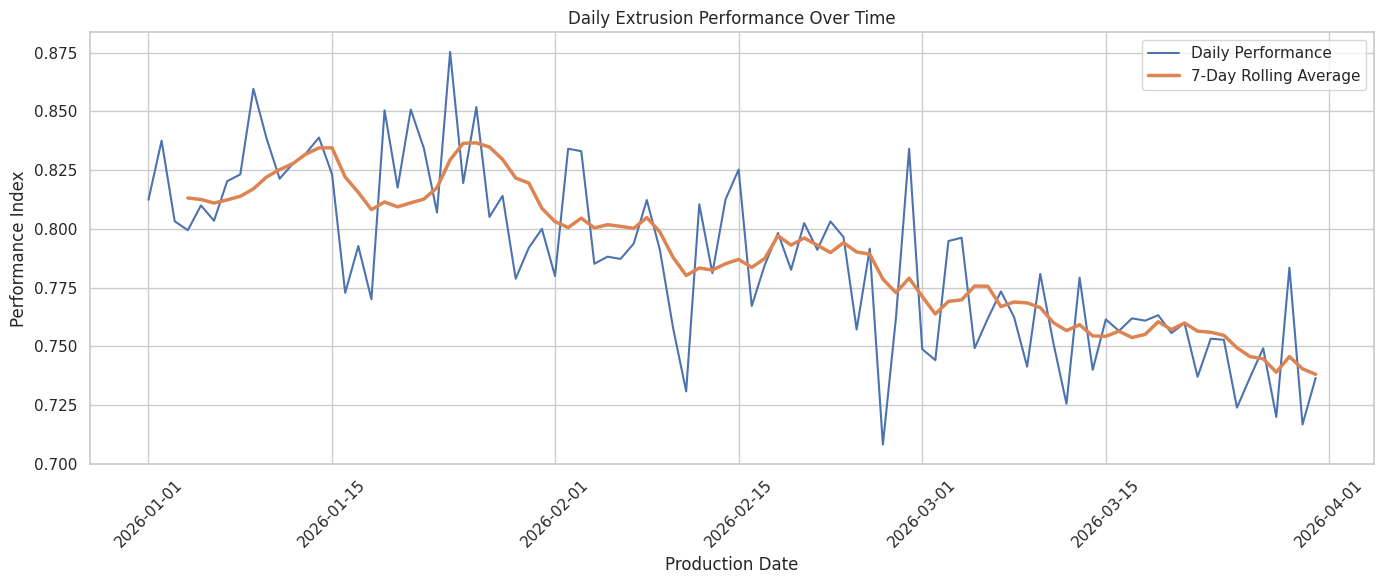

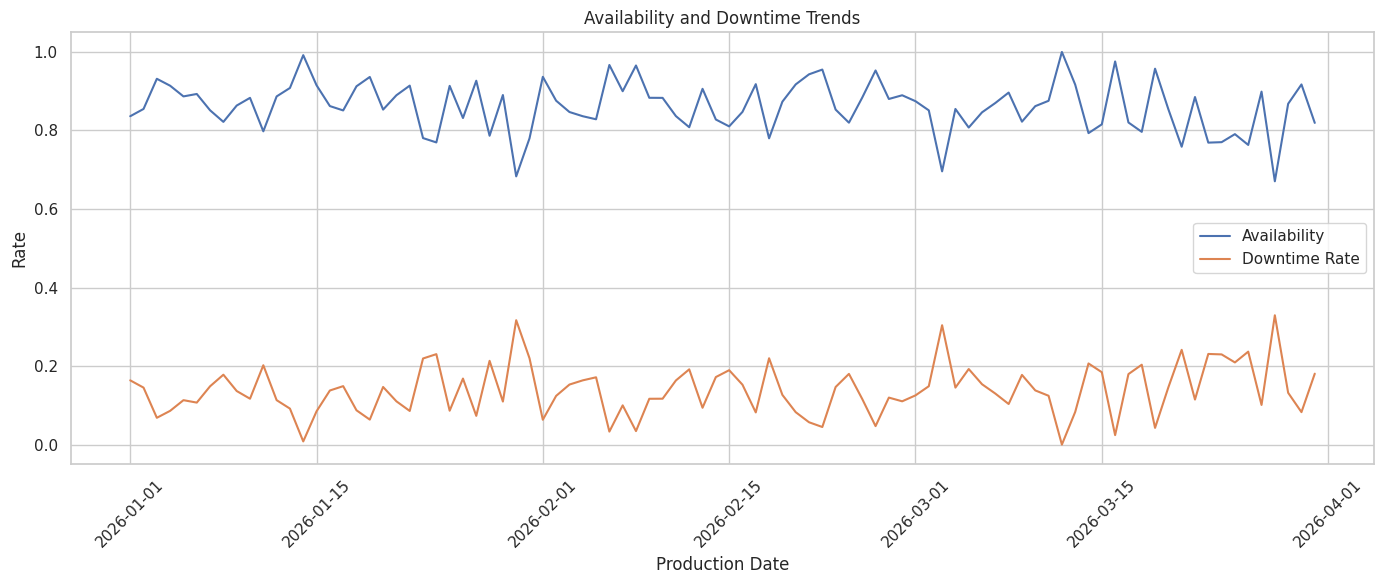

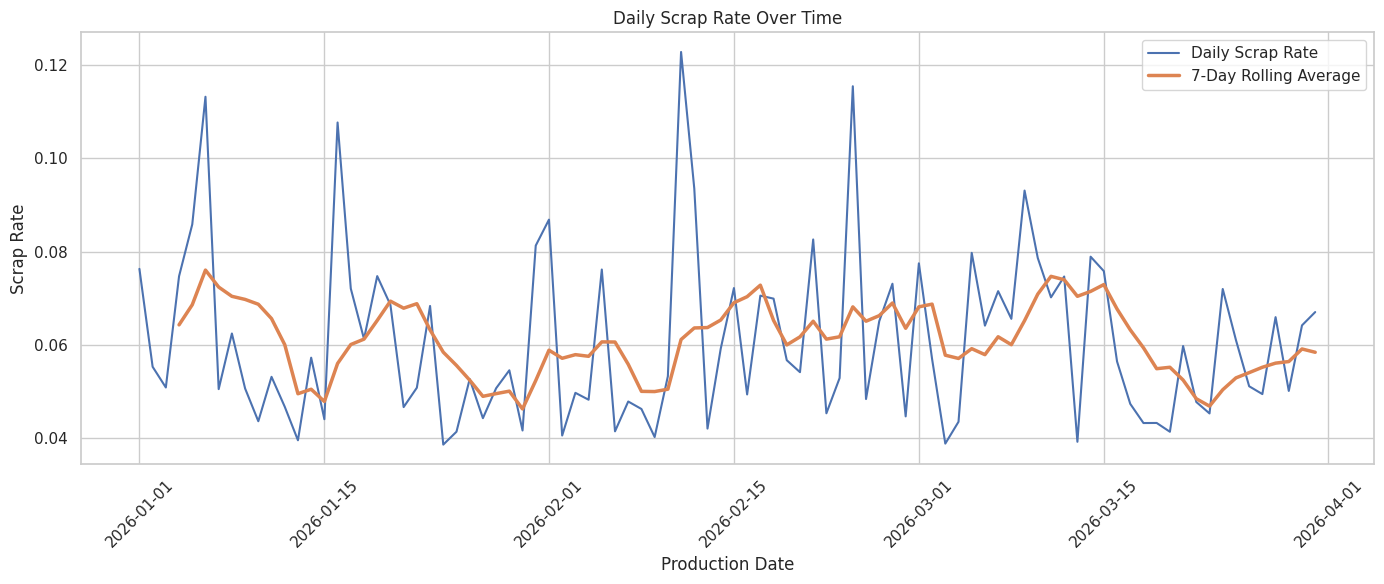

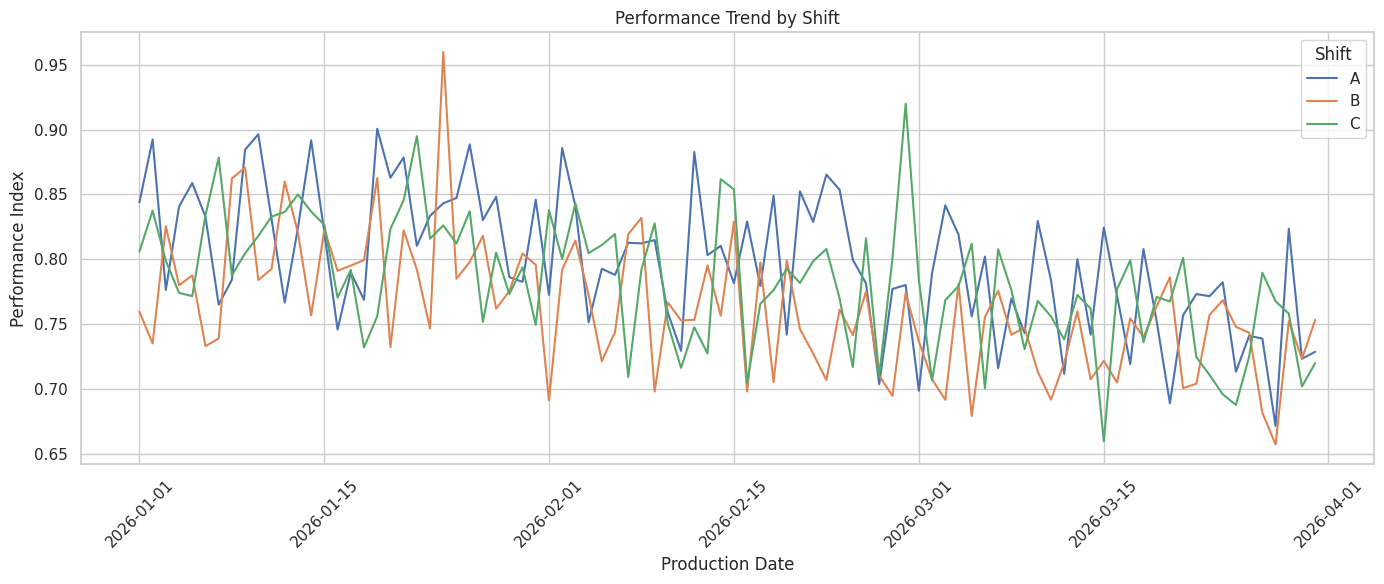

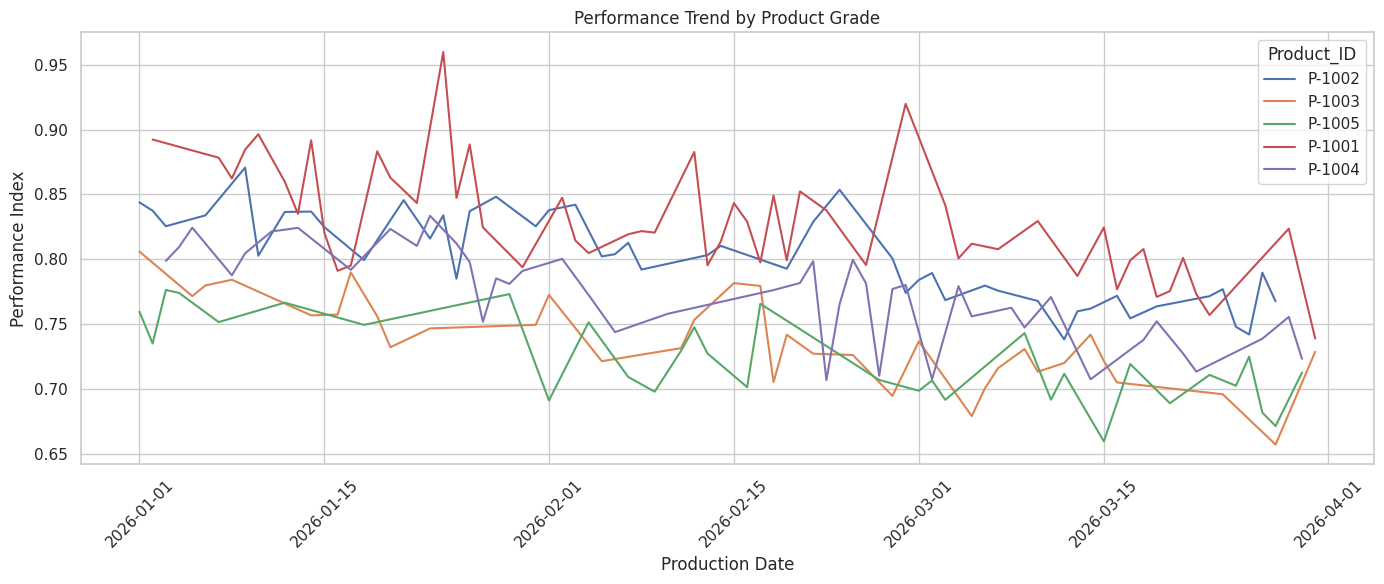

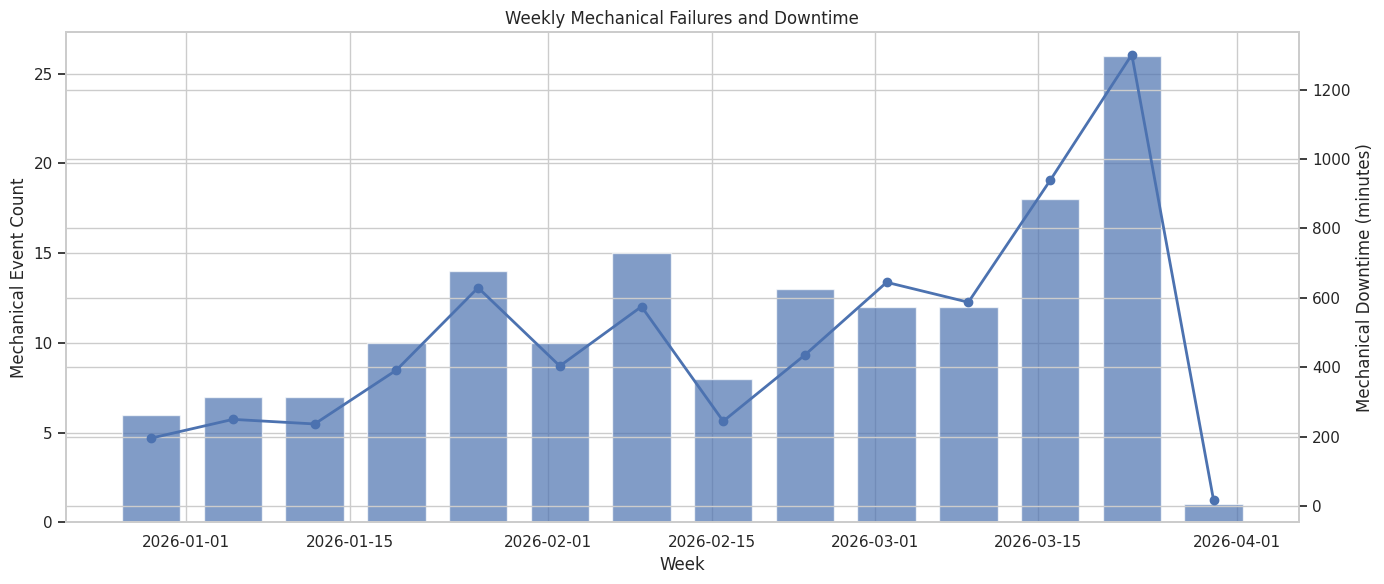


PERFORMANCE TREND INVESTIGATION COMPLETE

OVERALL PERFORMANCE TREND
Spearman correlation: -0.7706
Spearman p-value: 0.0
Linear slope per day: -0.001047
Linear regression R-squared: 0.5604

FIRST 15 DAYS VS FINAL 15 DAYS
           Metric  First_15_Day_Average  Final_15_Day_Average  Absolute_Change  Relative_Change_Percent
Performance_Index                0.8234                0.7474          -0.0760                  -9.2289
     Availability                0.8824                0.8227          -0.0598                  -6.7751
       Scrap_Rate                0.0603                0.0539          -0.0064                 -10.5523
    Downtime_Rate                0.1176                0.1773           0.0598                  50.8599

SHIFT TREND RESULTS
           Metric  Observation_Count  Spearman_Correlation  Spearman_P_Value  Pearson_Correlation  Pearson_P_Value  Linear_Slope_Per_Day  Linear_Regression_P_Value  R_Squared Shift
Performance_Index                 90               -0.548

In [2]:

# ================================================================
# MANUFACTURING & MATERIALS ANALYTICS LLC
# PROJECT 001: OEE & DOWNTIME ANALYSIS
# BLOCK 2: PERFORMANCE TREND INVESTIGATION
# ================================================================
#
# PURPOSE:
# 1. Determine whether production performance changes over time.
# 2. Quantify the size and direction of any performance trend.
# 3. Compare early-period and late-period performance.
# 4. Investigate whether trends differ by shift or product grade.
# 5. Examine whether mechanical failures are increasing over time.
#
# INPUTS:
# Uses production, downtime, and products DataFrames imported in Block 1.
#
# OUTPUTS:
# Creates a separate "performance_trend_outputs" folder containing
# summary CSV files and charts.
#
# IMPORTANT:
# This block does not modify or delete the original imported records.
# Correlation indicates association, not proof of a root cause.
# ================================================================


# ================================================================
# 1. IMPORT LIBRARIES AND SET UP OUTPUT FOLDER
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.4f}".format)

TREND_OUTPUT_DIR = Path.cwd() / "performance_trend_outputs"
TREND_OUTPUT_DIR.mkdir(exist_ok=True)

print("=" * 70)
print("BLOCK 2: PERFORMANCE TREND INVESTIGATION")
print("=" * 70)


# ================================================================
# 2. VERIFY INPUT DATASETS AND PREPARE ANALYSIS DATA
# ================================================================

required_objects = ["production", "downtime", "products"]

for object_name in required_objects:
    if object_name not in globals():
        raise NameError(
            f"'{object_name}' was not found. Run Block 1 successfully first."
        )

# Work with copies so Block 1's original DataFrames remain unchanged.
trend_production = production.copy()
trend_downtime = downtime.copy()
trend_products = products.copy()

# Convert dates and numeric fields.
trend_production["Date"] = pd.to_datetime(
    trend_production["Date"], errors="coerce"
)

numeric_fields = [
    "Planned_Time_Min",
    "Availability_Downtime_Min",
    "Run_Time_Min",
    "Total_Production_kg",
    "Good_Production_kg",
    "Scrap_Production_kg",
    "Ideal_Rate_kg_hr"
]

for column in numeric_fields:
    trend_production[column] = pd.to_numeric(
        trend_production[column], errors="coerce"
    )

trend_downtime["Event_Start"] = pd.to_datetime(
    trend_downtime["Event_Start"], errors="coerce"
)

trend_downtime["Duration_Min"] = pd.to_numeric(
    trend_downtime["Duration_Min"], errors="coerce"
)

# Remove only records that cannot be used in the relevant calculations.
# The original DataFrames are not changed.
trend_production = trend_production.dropna(
    subset=[
        "Date", "Total_Production_kg",
        "Run_Time_Min", "Ideal_Rate_kg_hr"
    ]
).copy()

trend_production = trend_production[
    (trend_production["Run_Time_Min"] > 0) &
    (trend_production["Ideal_Rate_kg_hr"] > 0)
].copy()

trend_production["Ideal_Production_kg"] = (
    trend_production["Ideal_Rate_kg_hr"] *
    trend_production["Run_Time_Min"] / 60
)

trend_production["Performance_Index"] = (
    trend_production["Total_Production_kg"] /
    trend_production["Ideal_Production_kg"]
)

trend_production["Scrap_Rate"] = (
    trend_production["Scrap_Production_kg"] /
    trend_production["Total_Production_kg"]
).replace([np.inf, -np.inf], np.nan)

trend_production["Availability"] = (
    trend_production["Run_Time_Min"] /
    trend_production["Planned_Time_Min"]
).replace([np.inf, -np.inf], np.nan)

print("\nINPUT DATA")
print("Production records:", len(trend_production))
print("Downtime events:", len(trend_downtime))
print("Product grades:", trend_production["Product_ID"].nunique())
print("Shifts:", trend_production["Shift"].nunique())
print(
    "Date range:",
    trend_production["Date"].min().date(),
    "to",
    trend_production["Date"].max().date()
)


# ================================================================
# 3. CREATE DAILY PERFORMANCE METRICS
# ================================================================
#
# Performance Index:
# Actual production (kg) / Ideal production (kg)
#
# For daily aggregation, we calculate:
# Sum of actual production / Sum of ideal production.
#
# This is a weighted calculation. It avoids simply averaging
# individual shift performance percentages.
#
# Note:
# Performance Index measures production speed relative to the
# product-specific ideal rate. It is not the complete OEE metric.
# ================================================================

daily_trend = trend_production.groupby("Date").agg(
    Production_Records=("Production_ID", "count"),
    Planned_Time_Min=("Planned_Time_Min", "sum"),
    Run_Time_Min=("Run_Time_Min", "sum"),
    Downtime_Min=("Availability_Downtime_Min", "sum"),
    Total_Production_kg=("Total_Production_kg", "sum"),
    Good_Production_kg=("Good_Production_kg", "sum"),
    Scrap_Production_kg=("Scrap_Production_kg", "sum"),
    Ideal_Production_kg=("Ideal_Production_kg", "sum")
).sort_index()

daily_trend["Performance_Index"] = (
    daily_trend["Total_Production_kg"] /
    daily_trend["Ideal_Production_kg"]
)

daily_trend["Availability"] = (
    daily_trend["Run_Time_Min"] /
    daily_trend["Planned_Time_Min"]
)

daily_trend["Scrap_Rate"] = (
    daily_trend["Scrap_Production_kg"] /
    daily_trend["Total_Production_kg"]
)

daily_trend["Downtime_Rate"] = (
    daily_trend["Downtime_Min"] /
    daily_trend["Planned_Time_Min"]
)

# Add a sequential time index for statistical trend analysis.
daily_trend["Day_Index"] = np.arange(len(daily_trend))

# Seven-observation rolling average.
# This smooths short-term fluctuations and helps reveal the broader trend.
daily_trend["Performance_7Day_Rolling"] = (
    daily_trend["Performance_Index"]
    .rolling(window=7, min_periods=4)
    .mean()
)

daily_trend["Scrap_Rate_7Day_Rolling"] = (
    daily_trend["Scrap_Rate"]
    .rolling(window=7, min_periods=4)
    .mean()
)

print("\nDAILY PERFORMANCE SUMMARY")
display(daily_trend.head(10))


# ================================================================
# 4. CALCULATE SPEARMAN, PEARSON, AND LINEAR TREND
# ================================================================
#
# Spearman:
# Measures whether performance generally moves upward or downward
# over time, based on ranked values.
#
# Pearson:
# Measures the strength of a linear relationship between time
# and performance.
#
# Linear regression:
# Estimates the average change in Performance Index per day.
#
# A negative slope means performance is declining.
# ================================================================

def calculate_trend_statistics(data, metric, time_column="Day_Index"):
    valid = data[[time_column, metric]].dropna()

    if len(valid) < 3:
        return {
            "Metric": metric,
            "Observation_Count": len(valid),
            "Spearman_Correlation": np.nan,
            "Spearman_P_Value": np.nan,
            "Pearson_Correlation": np.nan,
            "Pearson_P_Value": np.nan,
            "Linear_Slope_Per_Day": np.nan,
            "Linear_Regression_P_Value": np.nan,
            "R_Squared": np.nan
        }

    spearman_r, spearman_p = stats.spearmanr(
        valid[time_column], valid[metric]
    )

    pearson_r, pearson_p = stats.pearsonr(
        valid[time_column], valid[metric]
    )

    regression = stats.linregress(
        valid[time_column], valid[metric]
    )

    return {
        "Metric": metric,
        "Observation_Count": len(valid),
        "Spearman_Correlation": spearman_r,
        "Spearman_P_Value": spearman_p,
        "Pearson_Correlation": pearson_r,
        "Pearson_P_Value": pearson_p,
        "Linear_Slope_Per_Day": regression.slope,
        "Linear_Regression_P_Value": regression.pvalue,
        "R_Squared": regression.rvalue ** 2
    }


metrics_to_test = [
    "Performance_Index",
    "Availability",
    "Scrap_Rate",
    "Downtime_Rate"
]

overall_trend_results = pd.DataFrame([
    calculate_trend_statistics(daily_trend, metric)
    for metric in metrics_to_test
])

print("\nOVERALL TREND STATISTICS")
display(overall_trend_results)


# ================================================================
# 5. COMPARE FIRST 15 DAYS WITH FINAL 15 DAYS
# ================================================================
#
# This gives a practical measure of the size of the change.
#
# Percentage-point change:
# Final average minus initial average.
#
# Relative percentage change:
# (Final average - initial average) / initial average.
#
# These are different measures. For example, a change from 0.90
# to 0.85 is a decrease of 5 percentage points and approximately
# a 5.56% relative decrease.
# ================================================================

comparison_period = 15

first_period = daily_trend.head(comparison_period)
last_period = daily_trend.tail(comparison_period)

comparison_results = []

for metric in [
    "Performance_Index",
    "Availability",
    "Scrap_Rate",
    "Downtime_Rate"
]:
    first_mean = first_period[metric].mean()
    last_mean = last_period[metric].mean()

    percentage_point_change = last_mean - first_mean

    relative_change = (
        (last_mean - first_mean) / first_mean
        if pd.notna(first_mean) and first_mean != 0
        else np.nan
    )

    comparison_results.append({
        "Metric": metric,
        "First_15_Day_Average": first_mean,
        "Final_15_Day_Average": last_mean,
        "Absolute_Change": percentage_point_change,
        "Relative_Change_Percent": relative_change * 100
    })

period_comparison = pd.DataFrame(comparison_results)

print("\nFIRST 15 DAYS VS FINAL 15 DAYS")
display(period_comparison)


# ================================================================
# 6. PERFORMANCE TREND BY SHIFT
# ================================================================
#
# This investigates whether a trend is concentrated in one shift.
#
# Each shift's daily performance is calculated using its total
# production divided by its total ideal production.
# ================================================================

shift_daily = trend_production.groupby(
    ["Date", "Shift"]
).agg(
    Total_Production_kg=("Total_Production_kg", "sum"),
    Ideal_Production_kg=("Ideal_Production_kg", "sum"),
    Run_Time_Min=("Run_Time_Min", "sum"),
    Planned_Time_Min=("Planned_Time_Min", "sum"),
    Downtime_Min=("Availability_Downtime_Min", "sum"),
    Scrap_Production_kg=("Scrap_Production_kg", "sum")
).reset_index()

shift_daily["Performance_Index"] = (
    shift_daily["Total_Production_kg"] /
    shift_daily["Ideal_Production_kg"]
)

shift_daily["Availability"] = (
    shift_daily["Run_Time_Min"] /
    shift_daily["Planned_Time_Min"]
)

shift_daily["Downtime_Rate"] = (
    shift_daily["Downtime_Min"] /
    shift_daily["Planned_Time_Min"]
)

shift_daily["Scrap_Rate"] = (
    shift_daily["Scrap_Production_kg"] /
    shift_daily["Total_Production_kg"]
)

shift_trend_results = []

for shift_name, group in shift_daily.groupby("Shift"):
    group = group.sort_values("Date").copy()
    group["Day_Index"] = np.arange(len(group))

    result = calculate_trend_statistics(group, "Performance_Index")
    result["Shift"] = shift_name
    shift_trend_results.append(result)

shift_trend_summary = pd.DataFrame(shift_trend_results)

print("\nPERFORMANCE TREND BY SHIFT")
display(shift_trend_summary)


# ================================================================
# 7. PERFORMANCE TREND BY PRODUCT GRADE
# ================================================================
#
# Product mix can affect overall performance.
#
# This analysis checks whether performance trends are also visible
# within individual product grades.
#
# Important:
# Only compare grades across dates where they have production data.
# Some grades may have fewer observations than others.
# ================================================================

product_daily = trend_production.groupby(
    ["Date", "Product_ID"]
).agg(
    Total_Production_kg=("Total_Production_kg", "sum"),
    Ideal_Production_kg=("Ideal_Production_kg", "sum"),
    Run_Time_Min=("Run_Time_Min", "sum"),
    Scrap_Production_kg=("Scrap_Production_kg", "sum")
).reset_index()

product_daily["Performance_Index"] = (
    product_daily["Total_Production_kg"] /
    product_daily["Ideal_Production_kg"]
)

product_daily["Scrap_Rate"] = (
    product_daily["Scrap_Production_kg"] /
    product_daily["Total_Production_kg"]
)

product_trend_results = []

for product_id, group in product_daily.groupby("Product_ID"):
    group = group.sort_values("Date").copy()
    group["Day_Index"] = np.arange(len(group))

    result = calculate_trend_statistics(group, "Performance_Index")
    result["Product_ID"] = product_id
    product_trend_results.append(result)

product_trend_summary = pd.DataFrame(product_trend_results)

# Add product names and material descriptions where available.
product_trend_summary = product_trend_summary.merge(
    trend_products[
        ["Product_ID", "Product_Name", "Material"]
    ].drop_duplicates("Product_ID"),
    on="Product_ID",
    how="left"
)

print("\nPERFORMANCE TREND BY PRODUCT")
display(product_trend_summary)


# ================================================================
# 8. MECHANICAL FAILURE TREND OVER TIME
# ================================================================
#
# Investigates whether mechanical events become more frequent
# or account for more downtime as the project progresses.
#
# Event count and downtime duration are separate measurements:
# A higher event count does not necessarily mean more total downtime.
# ================================================================

mechanical_events = trend_downtime[
    trend_downtime["Downtime_Category"]
    .astype(str).str.strip().str.lower() == "mechanical"
].copy()

mechanical_events = mechanical_events.dropna(
    subset=["Event_Start", "Duration_Min"]
)

if not mechanical_events.empty:
    mechanical_events["Week"] = (
        mechanical_events["Event_Start"].dt.to_period("W")
    )

    mechanical_weekly = mechanical_events.groupby("Week").agg(
        Mechanical_Event_Count=("Event_ID", "count"),
        Mechanical_Downtime_Min=("Duration_Min", "sum")
    ).reset_index()

    mechanical_weekly["Week_Start"] = (
        mechanical_weekly["Week"].dt.start_time
    )

    mechanical_weekly["Week_Index"] = np.arange(
        len(mechanical_weekly)
    )

    mechanical_count_trend = calculate_trend_statistics(
        mechanical_weekly,
        "Mechanical_Event_Count",
        time_column="Week_Index"
    )

    mechanical_downtime_trend = calculate_trend_statistics(
        mechanical_weekly,
        "Mechanical_Downtime_Min",
        time_column="Week_Index"
    )

    mechanical_trend_summary = pd.DataFrame([
        mechanical_count_trend,
        mechanical_downtime_trend
    ])

else:
    mechanical_weekly = pd.DataFrame()
    mechanical_trend_summary = pd.DataFrame()

print("\nWEEKLY MECHANICAL FAILURE SUMMARY")
display(mechanical_weekly)

print("\nMECHANICAL FAILURE TREND STATISTICS")
display(mechanical_trend_summary)


# ================================================================
# 9. CHECK FOR SHORT-TERM SERIAL CORRELATION
# ================================================================
#
# Daily observations may be related to the previous day's results.
# This is called autocorrelation.
#
# If performance on one day is related to performance on the next,
# ordinary statistical p-values may overstate the amount of
# independent information in the time series.
#
# This is a diagnostic, not a complete time-series model.
# ================================================================

performance_series = daily_trend["Performance_Index"].dropna()

if len(performance_series) >= 4:
    lag1_autocorrelation = performance_series.autocorr(lag=1)
else:
    lag1_autocorrelation = np.nan

autocorrelation_summary = pd.DataFrame([{
    "Metric": "Performance_Index",
    "Lag_1_Autocorrelation": lag1_autocorrelation,
    "Observation_Count": len(performance_series)
}])

print("\nAUTOCORRELATION CHECK")
display(autocorrelation_summary)


# ================================================================
# 10. CREATE PERFORMANCE TREND CHARTS
# ================================================================

def save_trend_chart(filename):
    plt.tight_layout()
    plt.savefig(
        TREND_OUTPUT_DIR / filename,
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


# Chart 1: Daily performance and 7-day rolling average.
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_trend.reset_index(),
    x="Date",
    y="Performance_Index",
    label="Daily Performance"
)

sns.lineplot(
    data=daily_trend.reset_index(),
    x="Date",
    y="Performance_7Day_Rolling",
    label="7-Day Rolling Average",
    linewidth=2.5
)

plt.title("Daily Extrusion Performance Over Time")
plt.ylabel("Performance Index")
plt.xlabel("Production Date")
plt.xticks(rotation=45)
save_trend_chart("01_overall_performance_trend.png")


# Chart 2: Availability and downtime rate.
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    daily_trend.index,
    daily_trend["Availability"],
    label="Availability"
)

ax.plot(
    daily_trend.index,
    daily_trend["Downtime_Rate"],
    label="Downtime Rate"
)

ax.set_title("Availability and Downtime Trends")
ax.set_xlabel("Production Date")
ax.set_ylabel("Rate")
ax.legend()
plt.xticks(rotation=45)
save_trend_chart("02_availability_downtime_trends.png")


# Chart 3: Scrap rate.
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_trend.reset_index(),
    x="Date",
    y="Scrap_Rate",
    label="Daily Scrap Rate"
)

sns.lineplot(
    data=daily_trend.reset_index(),
    x="Date",
    y="Scrap_Rate_7Day_Rolling",
    label="7-Day Rolling Average",
    linewidth=2.5
)

plt.title("Daily Scrap Rate Over Time")
plt.ylabel("Scrap Rate")
plt.xlabel("Production Date")
plt.xticks(rotation=45)
save_trend_chart("03_scrap_rate_trend.png")


# Chart 4: Performance by shift.
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=shift_daily,
    x="Date",
    y="Performance_Index",
    hue="Shift",
    estimator=None
)

plt.title("Performance Trend by Shift")
plt.ylabel("Performance Index")
plt.xlabel("Production Date")
plt.xticks(rotation=45)
save_trend_chart("04_performance_by_shift.png")


# Chart 5: Performance by product.
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=product_daily,
    x="Date",
    y="Performance_Index",
    hue="Product_ID",
    estimator=None
)

plt.title("Performance Trend by Product Grade")
plt.ylabel("Performance Index")
plt.xlabel("Production Date")
plt.xticks(rotation=45)
save_trend_chart("05_performance_by_product.png")


# Chart 6: Weekly mechanical event count and downtime.
if not mechanical_weekly.empty:
    fig, ax1 = plt.subplots(figsize=(14, 6))

    ax1.bar(
        mechanical_weekly["Week_Start"],
        mechanical_weekly["Mechanical_Event_Count"],
        width=5,
        alpha=0.7
    )

    ax1.set_xlabel("Week")
    ax1.set_ylabel("Mechanical Event Count")
    ax1.set_title("Weekly Mechanical Failures and Downtime")

    ax2 = ax1.twinx()
    ax2.plot(
        mechanical_weekly["Week_Start"],
        mechanical_weekly["Mechanical_Downtime_Min"],
        marker="o",
        linewidth=2
    )

    ax2.set_ylabel("Mechanical Downtime (minutes)")
    save_trend_chart("06_weekly_mechanical_failures.png")


# ================================================================
# 11. EXPORT PERFORMANCE TREND RESULTS
# ================================================================

exports = {
    "daily_performance_trends.csv": daily_trend,
    "overall_trend_statistics.csv": overall_trend_results,
    "first_vs_final_15_days.csv": period_comparison,
    "shift_daily_performance.csv": shift_daily,
    "shift_trend_statistics.csv": shift_trend_summary,
    "product_daily_performance.csv": product_daily,
    "product_trend_statistics.csv": product_trend_summary,
    "mechanical_weekly_trends.csv": mechanical_weekly,
    "mechanical_trend_statistics.csv": mechanical_trend_summary,
    "performance_autocorrelation.csv": autocorrelation_summary
}

for filename, dataframe in exports.items():
    dataframe.to_csv(
        TREND_OUTPUT_DIR / filename,
        index=False
    )


# ================================================================
# 12. FINAL INVESTIGATION SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("PERFORMANCE TREND INVESTIGATION COMPLETE")
print("=" * 70)

print("\nOVERALL PERFORMANCE TREND")
performance_result = overall_trend_results[
    overall_trend_results["Metric"] == "Performance_Index"
]

if not performance_result.empty:
    result = performance_result.iloc[0]

    print(
        "Spearman correlation:",
        round(result["Spearman_Correlation"], 4)
    )

    print(
        "Spearman p-value:",
        round(result["Spearman_P_Value"], 6)
    )

    print(
        "Linear slope per day:",
        round(result["Linear_Slope_Per_Day"], 6)
    )

    print(
        "Linear regression R-squared:",
        round(result["R_Squared"], 4)
    )

print("\nFIRST 15 DAYS VS FINAL 15 DAYS")
print(period_comparison.to_string(index=False))

print("\nSHIFT TREND RESULTS")
print(shift_trend_summary.to_string(index=False))

print("\nPRODUCT TREND RESULTS")
print(product_trend_summary.to_string(index=False))

print("\nOUTPUT FOLDER:")
print(TREND_OUTPUT_DIR)

print("\nFILES GENERATED:")
for output_file in sorted(TREND_OUTPUT_DIR.iterdir()):
    print(output_file.name)

print("\n" + "=" * 70)
print("END OF BLOCK 2")
print("=" * 70)

print(
    "\nINTERPRETATION NOTE: A negative Spearman coefficient indicates "
    "that performance tends to decline over time. A negative linear "
    "slope estimates the average daily change. Neither result proves "
    "the cause of deterioration. Review product mix, shift patterns, "
    "autocorrelation, and data quality before assigning a root cause."
)



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
BLOCK 2.1: PERFORMANCE TREND VALIDATION

DATA CHECK
Observations: 90
First date: 2026-01-01
Last date: 2026-03-31
Average performance: 0.7874

ORDINARY OLS REGRESSION
                            OLS Regression Results                            
Dep. Variable:      Performance_Index   R-squared:                       0.560
Model:                            OLS   Adj. R-squared:                  0.555
Method:                 Least Squares   F-statistic:                     112.2
Date:                Sat, 14 Nov 2026   Prob (F-statistic):           2.22e-17
Time:                        18:47:44   Log-Likelihood:                 207.64
No. Observations:                  90   AIC:                            -411.3
Df Residuals:                      88   BIC:                            -406.3
Df Model:               

,Method,HAC_Max_Lags,Slope_Per_Day,Slope_Per_30_Days,Standard_Error,P_Value,Confidence_Interval_Lower,Confidence_Interval_Upper,R_Squared
0,Ordinary OLS,0,-0.00105,-0.03140,0.00010,0.00000,-0.00124,-0.00085,0.56038
1,HAC / Newey-West,3,-0.00105,-0.03140,0.00010,0.00000,-0.00124,-0.00085,0.56038
2,HAC / Newey-West,7,-0.00105,-0.03140,0.00010,0.00000,-0.00124,-0.00085,0.56038
3,HAC / Newey-West,14,-0.00105,-0.03140,0.00009,0.00000,-0.00122,-0.00088,0.56038



PRIMARY HAC MODEL: 7 LAGS
--------------------------------------------------
Estimated slope per day: -0.0010468
Estimated change per day (percentage points): -0.10468
Estimated change per 30 days (percentage points): -3.1403
HAC standard error: 9.68e-05
HAC p-value: 0.0
95% confidence interval: (np.float64(-0.0012391), np.float64(-0.0008545))

Interpretation: The estimated time trend is statistically distinguishable from zero at the 5% level under this HAC specification.

RESIDUAL AUTOCORRELATION: LJUNG-BOX TEST


,Lag,lb_stat,lb_pvalue
0,7,2.90237,0.89388
1,14,19.52186,0.14595



ROLLING PERFORMANCE DATA


,Date,Performance_Index,Performance_7Day_Rolling,Performance_15Day_Rolling,Rolling_15Day_Change
70,2026-03-12,0.72556,0.75670,0.76232,-0.00440
71,2026-03-13,0.77924,0.75919,0.76706,0.00474
72,2026-03-14,0.74000,0.75443,0.76557,-0.00149
73,2026-03-15,0.76146,0.75427,0.76073,-0.00484
74,2026-03-16,0.75657,0.75644,0.76124,0.00052
75,2026-03-17,0.76192,0.75374,0.76243,0.00119
76,2026-03-18,0.76094,0.75510,0.76017,-0.00226
77,2026-03-19,0.76325,0.76048,0.75797,-0.00220
78,2026-03-20,0.75567,0.75711,0.75840,0.00043
79,2026-03-21,0.75986,0.75995,0.75827,-0.00013



SIX CONSECUTIVE 15-OBSERVATION PERIODS


,Period_Number,Start_Date,End_Date,Observation_Count,Average_Performance,Median_Performance,Standard_Deviation,Minimum_Performance,Maximum_Performance,Change_From_First_Period,Change_From_First_Period_Points,Relative_Change_Percent
0,1,2026-01-01,2026-01-15,15,0.82341,0.82320,0.01642,0.79943,0.85965,0.00000,0.00000,0.00000
1,2,2026-01-16,2026-01-30,15,0.81549,0.81409,0.03190,0.77006,0.87533,-0.00792,-0.79205,-0.96191
2,3,2026-01-31,2026-02-14,15,0.79317,0.79098,0.02664,0.73080,0.83412,-0.03024,-3.02426,-3.67283
3,4,2026-02-15,2026-03-01,15,0.78356,0.79112,0.03146,0.70816,0.83410,-0.03985,-3.98528,-4.83994
4,5,2026-03-02,2026-03-16,15,0.76124,0.76146,0.02050,0.72556,0.79624,-0.06217,-6.21715,-7.55045
5,6,2026-03-17,2026-03-31,15,0.74742,0.75278,0.01856,0.71672,0.78351,-0.07599,-7.59925,-9.22895



10 LARGEST NEGATIVE CHANGES IN ROLLING PERFORMANCE


,Date,Performance_15Day_Rolling,Rolling_15Day_Change,Change_Percentage_Points
40,2026-02-10,0.79684,-0.00626,-0.62644
60,2026-03-02,0.77815,-0.00541,-0.54098
41,2026-02-11,0.79188,-0.00495,-0.49532
73,2026-03-15,0.76073,-0.00484,-0.48424
70,2026-03-12,0.76232,-0.00440,-0.44022
59,2026-03-01,0.78356,-0.00425,-0.42462
38,2026-02-08,0.80501,-0.00420,-0.42035
35,2026-02-05,0.81323,-0.00418,-0.41771
67,2026-03-09,0.76815,-0.00412,-0.41221
28,2026-01-29,0.81758,-0.00401,-0.40086


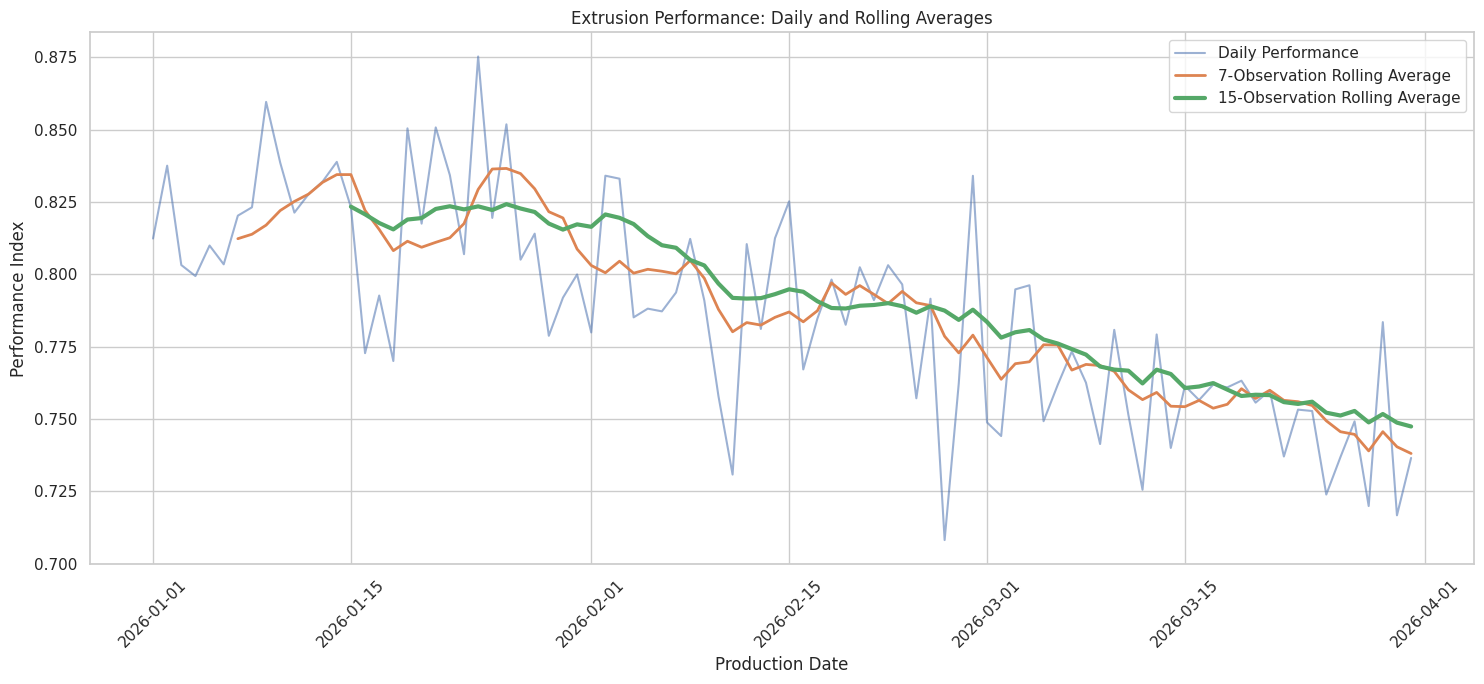

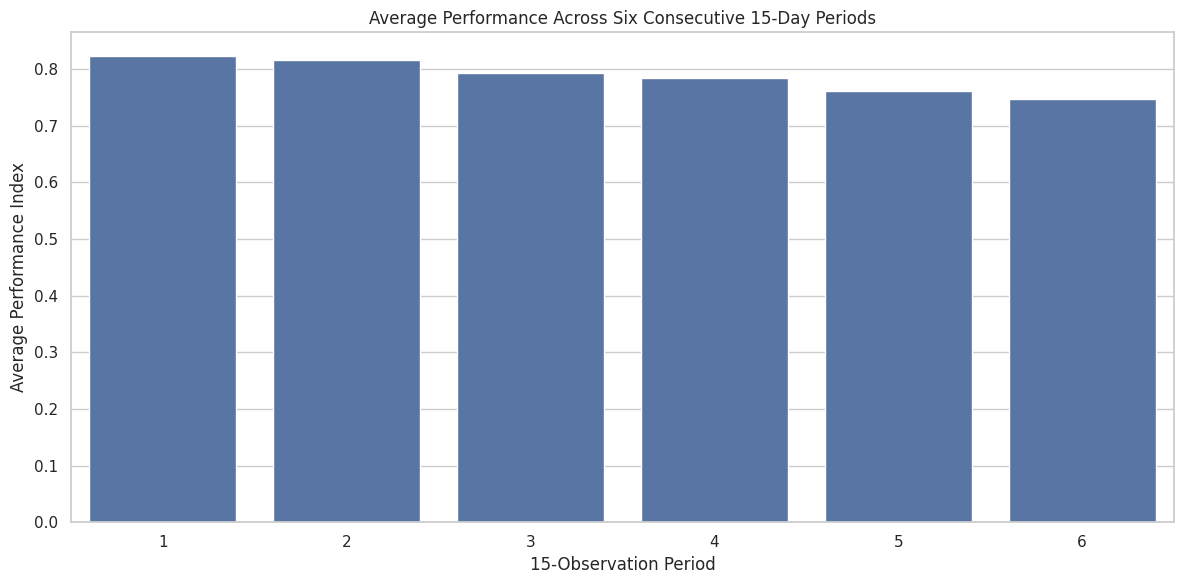

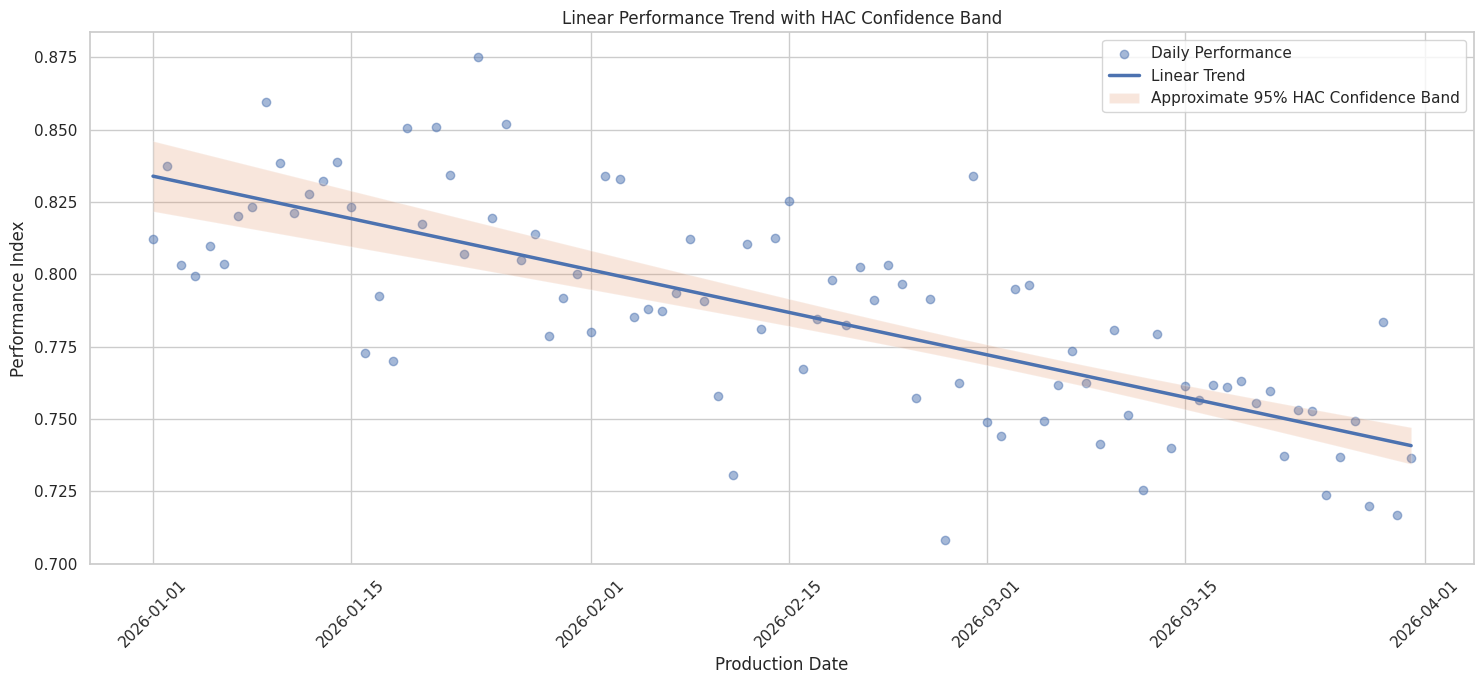


BLOCK 2.1 COMPLETE

PRIMARY HAC REGRESSION RESULT
HAC lag choice: 7
Slope per day: -0.0010468
Slope per 30 days (percentage points): -3.1403
HAC p-value: 0.0

SIX-PERIOD PERFORMANCE COMPARISON
 Period_Number Start_Date   End_Date  Average_Performance  Change_From_First_Period_Points
             1 2026-01-01 2026-01-15              0.82341                          0.00000
             2 2026-01-16 2026-01-30              0.81549                         -0.79205
             3 2026-01-31 2026-02-14              0.79317                         -3.02426
             4 2026-02-15 2026-03-01              0.78356                         -3.98528
             5 2026-03-02 2026-03-16              0.76124                         -6.21715
             6 2026-03-17 2026-03-31              0.74742                         -7.59925

OUTPUT DIRECTORY:
/datasets/_deepnote_work/performance_validation_outputs

GENERATED FILES:
01_daily_and_rolling_performance.png
02_six_period_performance_comparison.pn

In [3]:

# ================================================================
# MANUFACTURING & MATERIALS ANALYTICS LLC
# PROJECT 001: OEE & DOWNTIME ANALYSIS
#
# BLOCK 2.1: HAC/NEWey-WEST REGRESSION
#            AND ROLLING PERFORMANCE COMPARISON
# ================================================================
#
# PURPOSE:
# 1. Reassess the performance trend while accounting for
#    autocorrelation and heteroskedasticity.
# 2. Compare ordinary regression results with HAC/Newey-West results.
# 3. Test sensitivity to different HAC lag choices.
# 4. Examine performance using rolling 15-observation windows.
# 5. Compare six consecutive 15-observation periods.
# 6. Identify when the largest performance changes occurred.
#
# INPUT:
#    daily_trend from Block 2.
#
# OUTPUT:
#    A new folder named "performance_validation_outputs"
#    containing CSV reports and charts.
#
# IMPORTANT:
# HAC adjusts the estimated uncertainty around the regression slope.
# It does NOT change the underlying slope estimate.
#
# Rolling averages help describe the trend but do not establish cause.
# ================================================================


# ================================================================
# 1. IMPORT LIBRARIES AND CHECK INPUT DATA
# ================================================================

%pip install statsmodels -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.5f}".format)

VALIDATION_OUTPUT_DIR = (
    Path.cwd() / "performance_validation_outputs"
)
VALIDATION_OUTPUT_DIR.mkdir(exist_ok=True)

if "daily_trend" not in globals():
    raise NameError(
        "daily_trend was not found. Run Blocks 1 and 2 first."
    )

print("=" * 70)
print("BLOCK 2.1: PERFORMANCE TREND VALIDATION")
print("=" * 70)


# ================================================================
# 2. PREPARE DAILY PERFORMANCE DATA
# ================================================================
#
# We use the daily data created in Block 2.
#
# Day_Index provides the time variable.
# Performance_Index is the primary response variable.
#
# We sort chronologically and remove observations missing
# the fields required for regression.
# ================================================================

validation_data = daily_trend.copy()

# Recover dates if Date is currently stored as the DataFrame index.
if "Date" not in validation_data.columns:
    validation_data = validation_data.reset_index()

# Standardize the date column name if needed.
if "Date" not in validation_data.columns:
    possible_date_columns = [
        col for col in validation_data.columns
        if str(col).lower() in ["index", "date"]
    ]

    if possible_date_columns:
        validation_data = validation_data.rename(
            columns={possible_date_columns[0]: "Date"}
        )

validation_data["Date"] = pd.to_datetime(
    validation_data["Date"], errors="coerce"
)

validation_data["Performance_Index"] = pd.to_numeric(
    validation_data["Performance_Index"], errors="coerce"
)

validation_data = validation_data.dropna(
    subset=["Date", "Performance_Index"]
).sort_values("Date").reset_index(drop=True)

# Rebuild a sequential time index to ensure chronological ordering.
validation_data["Day_Index"] = np.arange(
    len(validation_data)
)

if len(validation_data) < 30:
    raise ValueError(
        "Fewer than 30 valid daily observations were found. "
        "Review the input data before proceeding."
    )

print("\nDATA CHECK")
print("Observations:", len(validation_data))
print("First date:", validation_data["Date"].min().date())
print("Last date:", validation_data["Date"].max().date())
print(
    "Average performance:",
    round(validation_data["Performance_Index"].mean(), 4)
)


# ================================================================
# 3. ORDINARY LINEAR REGRESSION
# ================================================================
#
# First, calculate a standard OLS regression.
#
# Model:
# Performance Index = Intercept + Slope * Day Index
#
# The slope estimates the average daily change.
#
# Ordinary OLS standard errors assume independent errors
# under the conventional inference framework.
#
# Our earlier autocorrelation analysis suggests this assumption
# may not be appropriate for these daily observations.
# ================================================================

X = sm.add_constant(validation_data["Day_Index"])
y = validation_data["Performance_Index"]

ordinary_model = sm.OLS(y, X).fit()

print("\nORDINARY OLS REGRESSION")
print(ordinary_model.summary())


# ================================================================
# 4. HAC / NEWEY-WEST REGRESSION
# ================================================================
#
# HAC = Heteroskedasticity and Autocorrelation Consistent.
#
# Newey-West standard errors adjust inference to account for
# serial correlation and heteroskedasticity in the residuals.
#
# We use 7 lags as the primary specification because the data
# are daily and a week is a practical initial lag horizon.
#
# We also test 3 and 14 lags to see whether conclusions
# are sensitive to the lag choice.
#
# Important:
# The regression slope remains the same for every HAC lag choice.
# The standard error, confidence interval, and p-value can change.
# ================================================================

hac_lag_choices = [3, 7, 14]

hac_results = {}

for lag in hac_lag_choices:
    hac_results[lag] = ordinary_model.get_robustcov_results(
        cov_type="HAC",
        maxlags=lag
    )

hac_comparison_rows = []

# Ordinary OLS reference result.
ordinary_ci = ordinary_model.conf_int().iloc[1]

hac_comparison_rows.append({
    "Method": "Ordinary OLS",
    "HAC_Max_Lags": 0,
    "Slope_Per_Day": ordinary_model.params.iloc[1],
    "Slope_Per_30_Days": ordinary_model.params.iloc[1] * 30,
    "Standard_Error": ordinary_model.bse.iloc[1],
    "P_Value": ordinary_model.pvalues.iloc[1],
    "Confidence_Interval_Lower": ordinary_ci.iloc[0],
    "Confidence_Interval_Upper": ordinary_ci.iloc[1],
    "R_Squared": ordinary_model.rsquared
})

for lag, result in hac_results.items():

    confidence_interval = result.conf_int()[1]

    hac_comparison_rows.append({
        "Method": "HAC / Newey-West",
        "HAC_Max_Lags": lag,
        "Slope_Per_Day": result.params[1],
        "Slope_Per_30_Days": result.params[1] * 30,
        "Standard_Error": result.bse[1],
        "P_Value": result.pvalues[1],
        "Confidence_Interval_Lower": confidence_interval[0],
        "Confidence_Interval_Upper": confidence_interval[1],
        "R_Squared": result.rsquared
    })

hac_comparison = pd.DataFrame(hac_comparison_rows)

print("\nORDINARY OLS VS HAC / NEWEY-WEST")
display(hac_comparison)


# ================================================================
# 5. INTERPRET THE PRIMARY HAC RESULT
# ================================================================
#
# Our primary model uses 7 HAC lags.
#
# We extract:
# - Estimated slope
# - HAC standard error
# - HAC p-value
# - 95% confidence interval
#
# The slope is expressed in Performance Index units.
# Multiply by 100 to express it in percentage points.
# ================================================================

primary_hac = hac_results[7]

primary_slope = primary_hac.params[1]
primary_p_value = primary_hac.pvalues[1]
primary_standard_error = primary_hac.bse[1]
primary_ci = primary_hac.conf_int()[1]

print("\nPRIMARY HAC MODEL: 7 LAGS")
print("-" * 50)

print(
    "Estimated slope per day:",
    round(primary_slope, 7)
)

print(
    "Estimated change per day (percentage points):",
    round(primary_slope * 100, 5)
)

print(
    "Estimated change per 30 days (percentage points):",
    round(primary_slope * 30 * 100, 4)
)

print(
    "HAC standard error:",
    round(primary_standard_error, 7)
)

print(
    "HAC p-value:",
    round(primary_p_value, 6)
)

print(
    "95% confidence interval:",
    (
        round(primary_ci[0], 7),
        round(primary_ci[1], 7)
    )
)

if primary_p_value < 0.05:
    print(
        "\nInterpretation: The estimated time trend is "
        "statistically distinguishable from zero at the "
        "5% level under this HAC specification."
    )
else:
    print(
        "\nInterpretation: The estimated time trend is not "
        "statistically distinguishable from zero at the "
        "5% level under this HAC specification."
    )


# ================================================================
# 6. RESIDUAL AUTOCORRELATION CHECK
# ================================================================
#
# Residuals are the differences between actual performance
# and the performance predicted by the linear trend.
#
# We use the Ljung-Box test to check whether residuals still
# show autocorrelation at selected lag horizons.
#
# A small p-value indicates evidence of remaining autocorrelation.
#
# This is a diagnostic, not proof that the model is correct
# or incorrect.
# ================================================================

model_residuals = ordinary_model.resid

ljung_box_results = acorr_ljungbox(
    model_residuals,
    lags=[7, 14],
    return_df=True
).reset_index()

ljung_box_results = ljung_box_results.rename(
    columns={"index": "Lag"}
)

print("\nRESIDUAL AUTOCORRELATION: LJUNG-BOX TEST")
display(ljung_box_results)


# ================================================================
# 7. CREATE ROLLING PERFORMANCE COMPARISONS
# ================================================================
#
# A rolling 15-observation average calculates the mean of the
# most recent 15 daily performance observations.
#
# Unlike a single first-versus-last comparison, this lets us
# see how performance evolves throughout the 90-day period.
#
# The rolling average is trailing:
# Each point uses the current day and the previous 14 observations.
# ================================================================

ROLLING_WINDOW = 15

validation_data["Performance_7Day_Rolling"] = (
    validation_data["Performance_Index"]
    .rolling(window=7, min_periods=7)
    .mean()
)

validation_data["Performance_15Day_Rolling"] = (
    validation_data["Performance_Index"]
    .rolling(window=ROLLING_WINDOW, min_periods=ROLLING_WINDOW)
    .mean()
)

validation_data["Performance_15Day_Rolling_Median"] = (
    validation_data["Performance_Index"]
    .rolling(window=ROLLING_WINDOW, min_periods=ROLLING_WINDOW)
    .median()
)

# Calculate the rolling change from the previous 15-observation window.
validation_data["Rolling_15Day_Change"] = (
    validation_data["Performance_15Day_Rolling"].diff()
)

print("\nROLLING PERFORMANCE DATA")
display(
    validation_data[
        [
            "Date",
            "Performance_Index",
            "Performance_7Day_Rolling",
            "Performance_15Day_Rolling",
            "Rolling_15Day_Change"
        ]
    ].tail(20)
)


# ================================================================
# 8. COMPARE SIX CONSECUTIVE 15-OBSERVATION PERIODS
# ================================================================
#
# Ninety observations divided into six groups of fifteen.
#
# This makes it easier to identify when performance changed.
#
# We calculate:
# - Average performance
# - Median performance
# - Standard deviation
# - Minimum and maximum
# - Change from the first period
#
# These are descriptive comparisons, not independent statistical
# tests between six groups.
# ================================================================

validation_data["Period_Number"] = (
    validation_data["Day_Index"] // ROLLING_WINDOW + 1
)

period_comparison = validation_data.groupby(
    "Period_Number"
).agg(
    Start_Date=("Date", "min"),
    End_Date=("Date", "max"),
    Observation_Count=("Performance_Index", "count"),
    Average_Performance=("Performance_Index", "mean"),
    Median_Performance=("Performance_Index", "median"),
    Standard_Deviation=("Performance_Index", "std"),
    Minimum_Performance=("Performance_Index", "min"),
    Maximum_Performance=("Performance_Index", "max")
).reset_index()

first_period_average = period_comparison.loc[
    period_comparison["Period_Number"] == 1,
    "Average_Performance"
].iloc[0]

period_comparison["Change_From_First_Period"] = (
    period_comparison["Average_Performance"] -
    first_period_average
)

period_comparison["Change_From_First_Period_Points"] = (
    period_comparison["Change_From_First_Period"] * 100
)

period_comparison["Relative_Change_Percent"] = (
    period_comparison["Change_From_First_Period"] /
    first_period_average * 100
)

print("\nSIX CONSECUTIVE 15-OBSERVATION PERIODS")
display(period_comparison)


# ================================================================
# 9. IDENTIFY THE LARGEST ROLLING PERFORMANCE CHANGES
# ================================================================
#
# We examine the difference between consecutive 15-day rolling
# averages.
#
# The largest negative changes identify where the rolling
# performance average dropped most sharply.
#
# This is a screening tool. It does not establish what caused
# a particular change.
# ================================================================

rolling_change_events = validation_data.dropna(
    subset=["Rolling_15Day_Change"]
).copy()

largest_drops = rolling_change_events.nsmallest(
    10,
    "Rolling_15Day_Change"
)[
    [
        "Date",
        "Performance_15Day_Rolling",
        "Rolling_15Day_Change"
    ]
].copy()

largest_drops["Change_Percentage_Points"] = (
    largest_drops["Rolling_15Day_Change"] * 100
)

print("\n10 LARGEST NEGATIVE CHANGES IN ROLLING PERFORMANCE")
display(largest_drops)


# ================================================================
# 10. CREATE CHART: DAILY PERFORMANCE WITH ROLLING AVERAGES
# ================================================================

plt.figure(figsize=(15, 7))

plt.plot(
    validation_data["Date"],
    validation_data["Performance_Index"],
    label="Daily Performance",
    alpha=0.55
)

plt.plot(
    validation_data["Date"],
    validation_data["Performance_7Day_Rolling"],
    label="7-Observation Rolling Average",
    linewidth=2
)

plt.plot(
    validation_data["Date"],
    validation_data["Performance_15Day_Rolling"],
    label="15-Observation Rolling Average",
    linewidth=3
)

plt.title(
    "Extrusion Performance: Daily and Rolling Averages"
)
plt.xlabel("Production Date")
plt.ylabel("Performance Index")
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(
    VALIDATION_OUTPUT_DIR /
    "01_daily_and_rolling_performance.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ================================================================
# 11. CREATE CHART: SIX 15-OBSERVATION PERIODS
# ================================================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=period_comparison,
    x="Period_Number",
    y="Average_Performance"
)

plt.title(
    "Average Performance Across Six Consecutive 15-Day Periods"
)
plt.xlabel("15-Observation Period")
plt.ylabel("Average Performance Index")

plt.tight_layout()
plt.savefig(
    VALIDATION_OUTPUT_DIR /
    "02_six_period_performance_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ================================================================
# 12. CREATE CHART: HAC REGRESSION TREND
# ================================================================
#
# The regression line shows the estimated linear time trend.
# The confidence interval is based on the HAC 7-lag standard error.
#
# The band represents uncertainty in the estimated mean trend,
# not a prediction interval for individual daily observations.
# ================================================================

x_values = validation_data["Day_Index"].to_numpy()

predicted_values = ordinary_model.predict(X)

critical_value = 1.96

trend_standard_error = (
    primary_standard_error * x_values
    / np.sqrt(np.sum(
        (x_values - x_values.mean()) ** 2
    ))
)

# For a regression with an intercept, the HAC variance of a
# fitted mean is more fully represented by the design matrix.
# Calculate the HAC covariance-based confidence band directly.

design_matrix = X.to_numpy()
hac_covariance = primary_hac.cov_params()

fitted_standard_errors = np.sqrt(
    np.diag(
        design_matrix @ hac_covariance @ design_matrix.T
    )
)

lower_band = predicted_values - critical_value * fitted_standard_errors
upper_band = predicted_values + critical_value * fitted_standard_errors

plt.figure(figsize=(15, 7))

plt.scatter(
    validation_data["Date"],
    validation_data["Performance_Index"],
    alpha=0.5,
    label="Daily Performance"
)

plt.plot(
    validation_data["Date"],
    predicted_values,
    linewidth=2.5,
    label="Linear Trend"
)

plt.fill_between(
    validation_data["Date"],
    lower_band,
    upper_band,
    alpha=0.2,
    label="Approximate 95% HAC Confidence Band"
)

plt.title(
    "Linear Performance Trend with HAC Confidence Band"
)
plt.xlabel("Production Date")
plt.ylabel("Performance Index")
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(
    VALIDATION_OUTPUT_DIR /
    "03_hac_regression_trend.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ================================================================
# 13. EXPORT RESULTS
# ================================================================

exports = {
    "hac_regression_comparison.csv": hac_comparison,
    "ljung_box_residual_diagnostics.csv": ljung_box_results,
    "rolling_performance_data.csv": validation_data,
    "six_period_performance_comparison.csv": period_comparison,
    "largest_rolling_performance_drops.csv": largest_drops
}

for filename, dataframe in exports.items():
    dataframe.to_csv(
        VALIDATION_OUTPUT_DIR / filename,
        index=False
    )


# ================================================================
# 14. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("BLOCK 2.1 COMPLETE")
print("=" * 70)

print("\nPRIMARY HAC REGRESSION RESULT")
print("HAC lag choice: 7")
print("Slope per day:", round(primary_slope, 7))
print(
    "Slope per 30 days (percentage points):",
    round(primary_slope * 30 * 100, 4)
)
print("HAC p-value:", round(primary_p_value, 6))

print("\nSIX-PERIOD PERFORMANCE COMPARISON")
print(
    period_comparison[
        [
            "Period_Number",
            "Start_Date",
            "End_Date",
            "Average_Performance",
            "Change_From_First_Period_Points"
        ]
    ].to_string(index=False)
)

print("\nOUTPUT DIRECTORY:")
print(VALIDATION_OUTPUT_DIR)

print("\nGENERATED FILES:")
for output_file in sorted(VALIDATION_OUTPUT_DIR.iterdir()):
    print(output_file.name)

print("\nIMPORTANT INTERPRETATION NOTES:")
print(
    "1. HAC changes standard errors and inference, not the slope."
)
print(
    "2. The 7-lag HAC model is our primary specification; "
    "3 and 14 lags are sensitivity checks."
)
print(
    "3. Rolling averages describe how performance evolves over time."
)
print(
    "4. A trend does not identify its operational root cause."
)
print(
    "5. The confidence band describes uncertainty in the fitted "
    "mean trend, not individual daily performance."
)

print("\n" + "=" * 70)
print("END OF BLOCK 2.1")
print("=" * 70)


BLOCK 3: OEE CALCULATION AND LOSS ANALYSIS

INPUT DATA CHECK
Original production records: 270
Records excluded from core calculations: 0
Valid production records: 270
Downtime event records: 824
Product grades: 5
Shifts: 3

PRODUCTION DATA VALIDATION


,Validation,Records_Failing
0,Time reconciliation,0
1,Production quantity reconciliation,0
2,Negative production/time values,0
3,Excluded incomplete records,0



OEE FORMULA CROSS-CHECK
Maximum absolute difference: 0.0
Records with an OEE component outside the expected 0-100% range: 0

OVERALL EXTRUSION LINE OEE


,Production_Records,Planned_Time_Min,Run_Time_Min,Availability_Downtime_Min,Total_Production_kg,Good_Production_kg,Scrap_Production_kg,Availability,Performance,Quality,OEE
0,270,129600,"111,664.4500","17,935.5500","138,720.5900","130,485.2400","8,235.3500",0.8616,0.7901,0.9406,0.6403



OEE BY SHIFT


,Shift,Production_Records,Total_Production_kg,Good_Production_kg,Availability,Performance,Quality,OEE
0,A,90,"49,576.1800","46,777.1800",0.8915,0.8084,0.9435,0.6801
1,B,90,"42,500.9700","39,675.3200",0.8180,0.7699,0.9335,0.5879
2,C,90,"46,643.4400","44,032.7400",0.8752,0.7900,0.9440,0.6527


... (24 outputs left out)


WEEKLY MECHANICAL DOWNTIME


,Week,Mechanical_Event_Count,Mechanical_Downtime_Min,Average_Event_Min,Week_Start
0,2025-12-29/2026-01-04,6,195.7600,32.6267,2025-12-29
1,2026-01-05/2026-01-11,7,249.8000,35.6857,2026-01-05
2,2026-01-12/2026-01-18,7,236.5700,33.7957,2026-01-12
3,2026-01-19/2026-01-25,10,391.6800,39.1680,2026-01-19
4,2026-01-26/2026-02-01,14,629.1200,44.9371,2026-01-26
5,2026-02-02/2026-02-08,10,403.5700,40.3570,2026-02-02
6,2026-02-09/2026-02-15,15,574.7500,38.3167,2026-02-09
7,2026-02-16/2026-02-22,8,244.5100,30.5637,2026-02-16
8,2026-02-23/2026-03-01,13,435.4800,33.4985,2026-02-23
9,2026-03-02/2026-03-08,12,644.6900,53.7242,2026-03-02



DOWNTIME EVENT RECONCILIATION
Production records with >1 minute difference: 5
Total production-record availability downtime: 17935.55 minutes
Total event-level availability downtime: 18092.34 minutes


,Production_ID,Availability_Downtime_Min,Event_Availability_Downtime_Min,Difference_Min,Absolute_Difference_Min
229,PR-077-B,87.5300,142.7400,-55.2100,55.2100
191,PR-064-C,210.0100,259.0500,-49.0400,49.0400
132,PR-045-A,73.5900,98.2600,-24.6700,24.6700
75,PR-026-A,19.9300,39.8600,-19.9300,19.9300
182,PR-061-C,112.9400,120.8800,-7.9400,7.9400
247,PR-083-B,210.0100,210.0100,-0.0000,0.0000
185,PR-062-C,206.3900,206.3900,-0.0000,0.0000
228,PR-077-A,182.2700,182.2700,0.0000,0.0000
89,PR-030-C,203.2400,203.2400,0.0000,0.0000
67,PR-023-B,179.3900,179.3900,-0.0000,0.0000


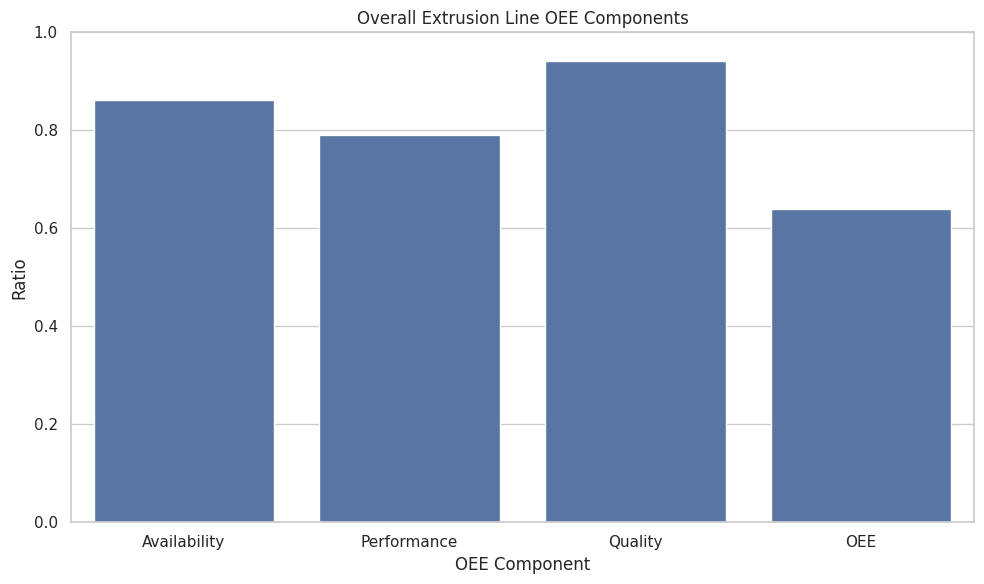

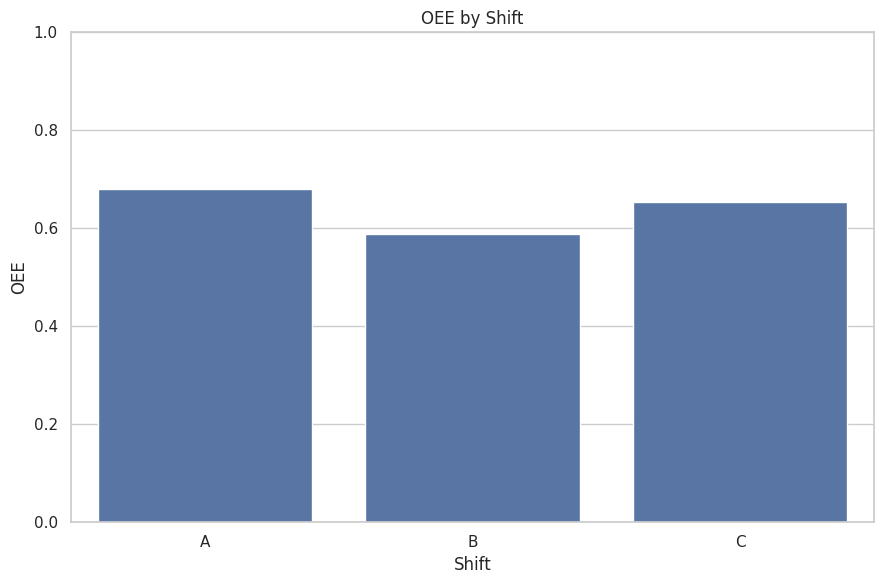

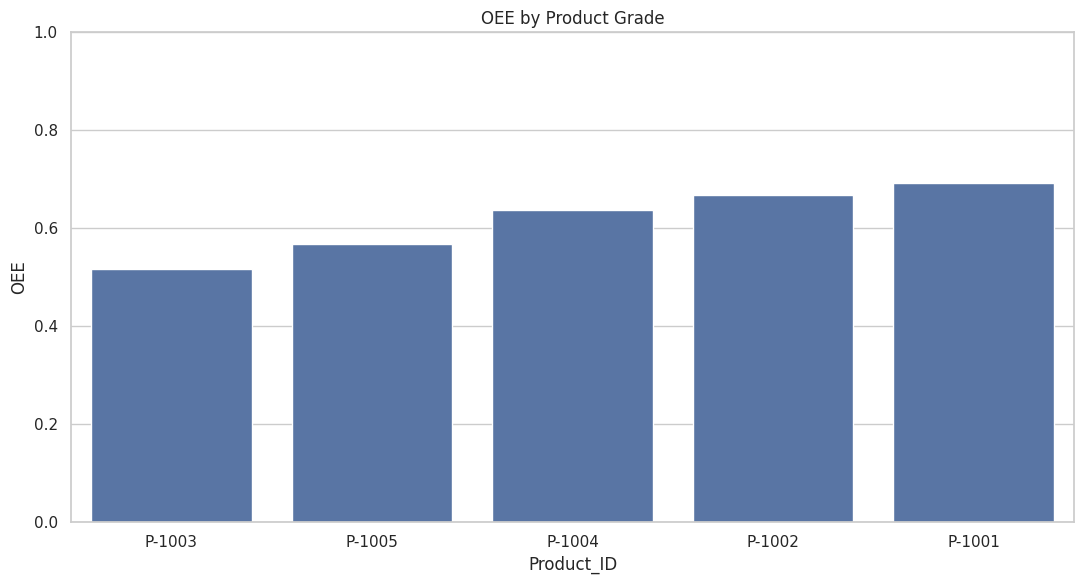

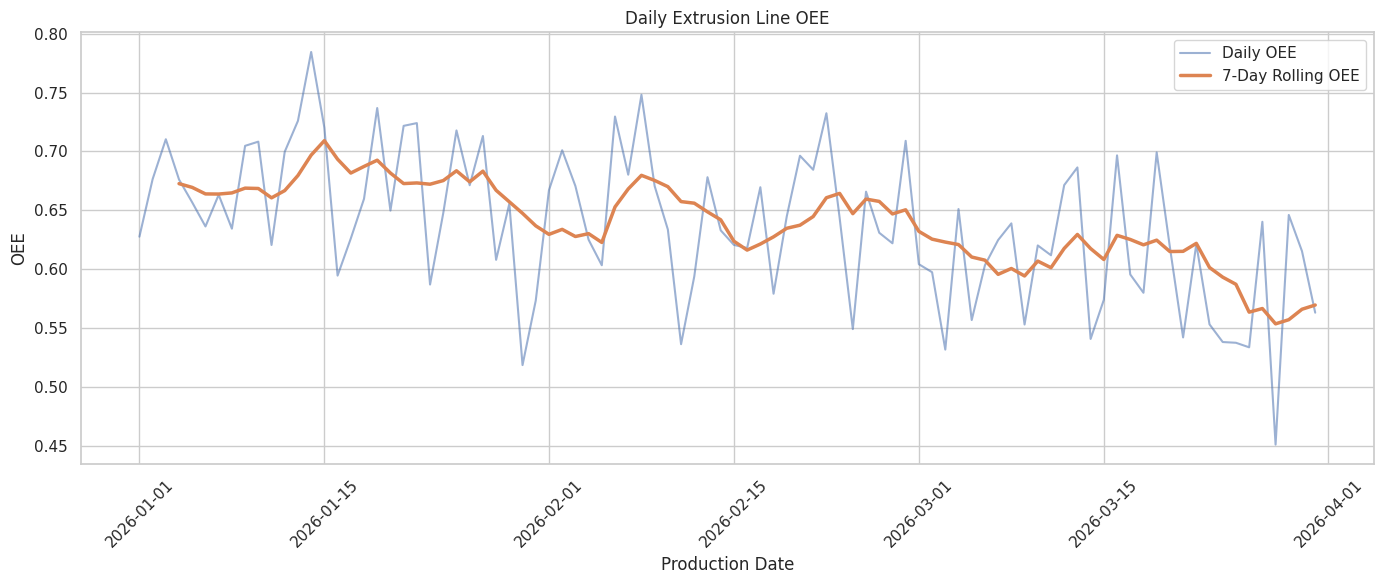

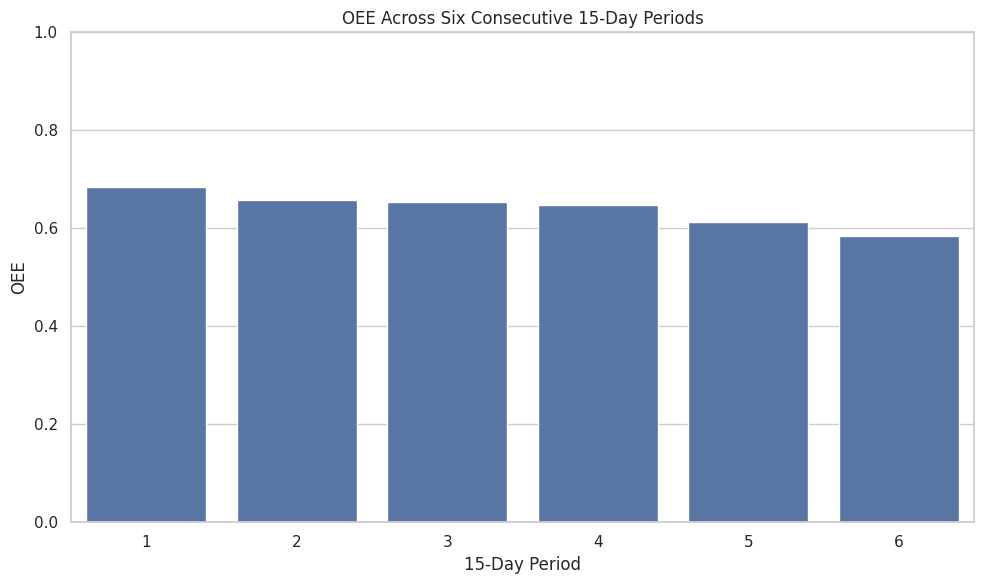

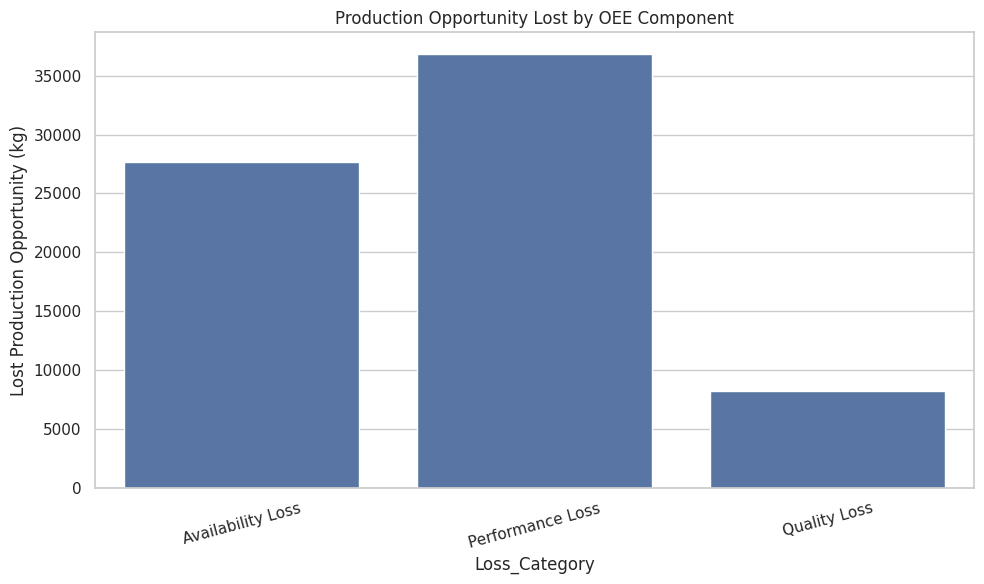

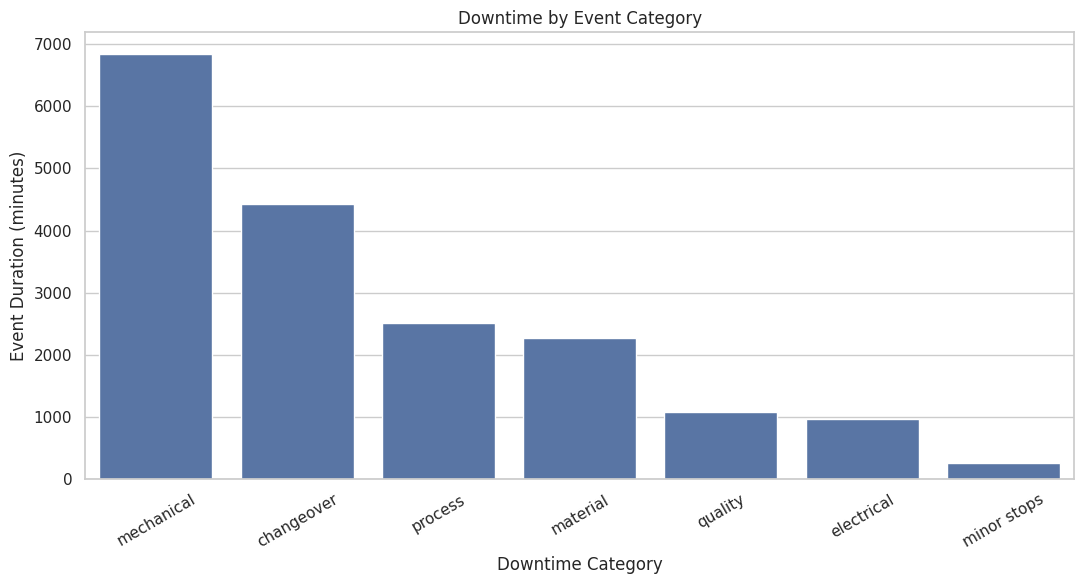

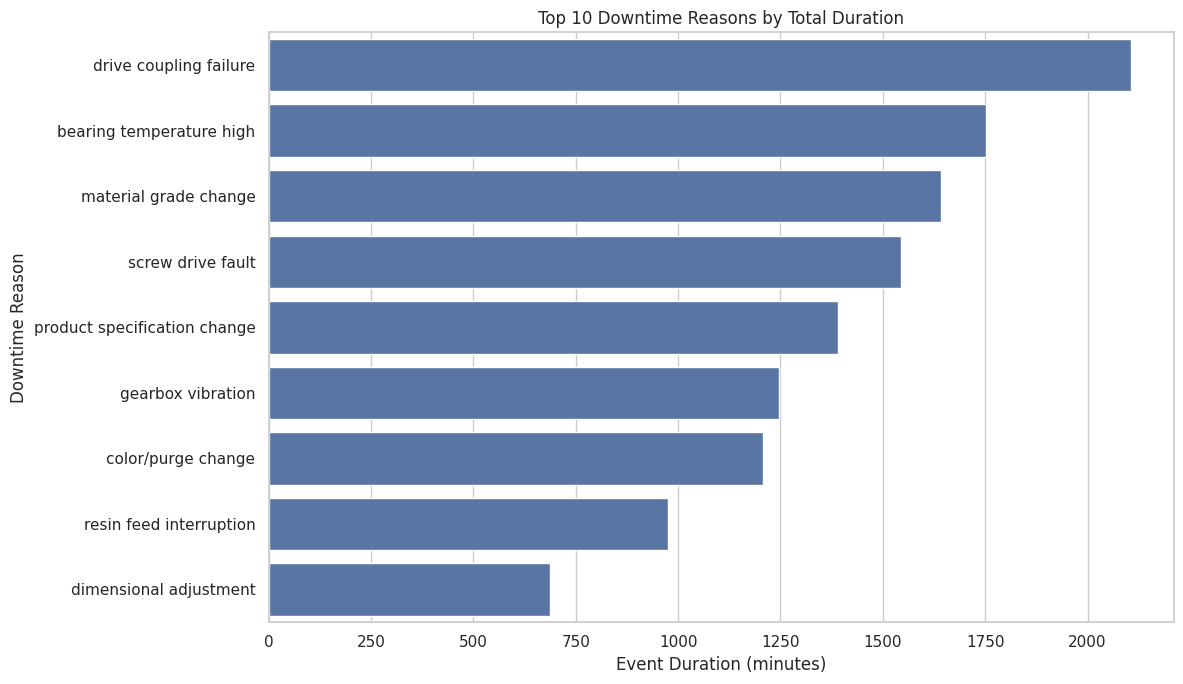


BLOCK 3 COMPLETE: OEE AND LOSS ANALYSIS

OVERALL OEE RESULTS
Availability: 86.16%
Performance: 79.01%
Quality: 94.06%
OEE: 64.03%

PRODUCTION QUANTITIES
Total production: 138720.59 kg
Good production: 130485.24 kg
Scrap production: 8235.35 kg

PRODUCTION LOSS COMPONENTS
Availability Loss: 27668.02 kg
Performance Loss: 36851.39 kg
Quality Loss: 8235.35 kg
Total Loss: 72754.76 kg

OEE BY SHIFT
Shift  Availability  Performance  Quality    OEE
    A        0.8915       0.8084   0.9435 0.6801
    B        0.8180       0.7699   0.9335 0.5879
    C        0.8752       0.7900   0.9440 0.6527

OEE BY PRODUCT
Product_ID  Availability  Performance  Quality    OEE
    P-1003        0.8314       0.7397   0.8410 0.5172
    P-1005        0.8432       0.7239   0.9298 0.5675
    P-1004        0.8740       0.7727   0.9419 0.6362
    P-1002        0.8723       0.8024   0.9541 0.6678
    P-1001        0.8690       0.8282   0.9625 0.6928

OUTPUT FOLDER:
/datasets/_deepnote_work/oee_loss_analysis_outputs



In [4]:

# ================================================================
# MANUFACTURING & MATERIALS ANALYTICS LLC
# PROJECT 001: OEE & DOWNTIME ANALYSIS
#
# BLOCK 3: OEE CALCULATION AND LOSS ANALYSIS
# ================================================================
#
# PURPOSE:
# 1. Calculate Availability, Performance, Quality, and OEE.
# 2. Calculate OEE by shift, product, and day.
# 3. Compare six consecutive 15-day periods.
# 4. Quantify availability, performance, and quality losses in kg.
# 5. Investigate downtime by category, reason, and loss type.
# 6. Examine changeover and mechanical downtime.
#
# OEE CONVENTION:
# Changeovers count as availability losses.
# Planned production time includes changeover time.
#
# CALCULATION BASIS:
# Product-specific Ideal_Rate_kg_hr is used.
# Production records are authoritative for time and quantities.
# Downtime event records are used for loss categorization only.
#
# INPUTS:
# production, downtime, products, equipment from Block 1.
#
# OUTPUT:
# oee_loss_analysis_outputs/
#
# IMPORTANT:
# Do not add downtime event durations to production-record
# downtime. They represent two views of the same operating losses.
# ================================================================


# ================================================================
# 1. IMPORT LIBRARIES AND CREATE OUTPUT FOLDER
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.4f}".format)

OEE_OUTPUT_DIR = Path.cwd() / "oee_loss_analysis_outputs"
OEE_OUTPUT_DIR.mkdir(exist_ok=True)

print("=" * 75)
print("BLOCK 3: OEE CALCULATION AND LOSS ANALYSIS")
print("=" * 75)


# ================================================================
# 2. VERIFY INPUT DATASETS
# ================================================================

required_objects = [
    "production", "downtime", "products", "equipment"
]

for object_name in required_objects:
    if object_name not in globals():
        raise NameError(
            f"'{object_name}' was not found. "
            "Run Block 1 successfully before running Block 3."
        )

# Work with copies to protect the original imported DataFrames.
oee_production = production.copy()
oee_downtime = downtime.copy()
oee_products = products.copy()
oee_equipment = equipment.copy()

required_production_columns = [
    "Production_ID",
    "Date",
    "Shift",
    "Machine_ID",
    "Product_ID",
    "Planned_Time_Min",
    "Availability_Downtime_Min",
    "Run_Time_Min",
    "Total_Production_kg",
    "Good_Production_kg",
    "Scrap_Production_kg",
    "Ideal_Rate_kg_hr"
]

required_downtime_columns = [
    "Event_ID",
    "Production_ID",
    "Duration_Min",
    "Downtime_Category",
    "Downtime_Reason",
    "Loss_Type"
]

required_product_columns = [
    "Product_ID",
    "Material",
    "Product_Name",
    "Ideal_Rate_kg_hr",
    "Typical_Changeover_Min"
]

for column in required_production_columns:
    if column not in oee_production.columns:
        raise ValueError(
            f"Production data is missing required column: {column}"
        )

for column in required_downtime_columns:
    if column not in oee_downtime.columns:
        raise ValueError(
            f"Downtime data is missing required column: {column}"
        )

for column in required_product_columns:
    if column not in oee_products.columns:
        raise ValueError(
            f"Product master is missing required column: {column}"
        )


# ================================================================
# 3. DATA TYPE CONVERSION AND VALIDATION
# ================================================================

oee_production["Date"] = pd.to_datetime(
    oee_production["Date"], errors="coerce"
)

production_numeric_columns = [
    "Planned_Time_Min",
    "Availability_Downtime_Min",
    "Run_Time_Min",
    "Total_Production_kg",
    "Good_Production_kg",
    "Scrap_Production_kg",
    "Ideal_Rate_kg_hr"
]

for column in production_numeric_columns:
    oee_production[column] = pd.to_numeric(
        oee_production[column], errors="coerce"
    )

oee_downtime["Duration_Min"] = pd.to_numeric(
    oee_downtime["Duration_Min"], errors="coerce"
)

oee_products["Ideal_Rate_kg_hr"] = pd.to_numeric(
    oee_products["Ideal_Rate_kg_hr"], errors="coerce"
)

# Normalize text fields for consistent grouping.
for column in [
    "Shift", "Product_ID", "Machine_ID"
]:
    oee_production[column] = (
        oee_production[column].astype("string").str.strip()
    )

for column in [
    "Downtime_Category", "Downtime_Reason", "Loss_Type"
]:
    oee_downtime[column] = (
        oee_downtime[column]
        .astype("string")
        .str.strip()
    )

# Remove records that cannot support the core calculations.
# Original imported data remains unchanged.
invalid_required = oee_production[
    oee_production[required_production_columns].isna().any(axis=1)
].copy()

oee_data = oee_production.dropna(
    subset=required_production_columns
).copy()

# Positive planned time and ideal rate are required.
oee_data = oee_data[
    (oee_data["Planned_Time_Min"] > 0) &
    (oee_data["Ideal_Rate_kg_hr"] > 0)
].copy()

if oee_data.empty:
    raise ValueError(
        "No valid production records remain after input validation."
    )

print("\nINPUT DATA CHECK")
print("Original production records:", len(oee_production))
print("Records excluded from core calculations:", len(invalid_required))
print("Valid production records:", len(oee_data))
print("Downtime event records:", len(oee_downtime))
print("Product grades:", oee_data["Product_ID"].nunique())
print("Shifts:", oee_data["Shift"].nunique())


# ================================================================
# 4. PRODUCTION DATA RECONCILIATION
# ================================================================
#
# Validate:
# Planned time = Run time + Availability downtime
# Total production = Good production + Scrap production
#
# These checks help establish whether the source data reconciles.
# ================================================================

oee_data["Time_Reconciliation_Difference_Min"] = (
    oee_data["Planned_Time_Min"]
    - oee_data["Run_Time_Min"]
    - oee_data["Availability_Downtime_Min"]
)

oee_data["Quantity_Reconciliation_Difference_kg"] = (
    oee_data["Total_Production_kg"]
    - oee_data["Good_Production_kg"]
    - oee_data["Scrap_Production_kg"]
)

time_reconciliation_errors = oee_data[
    oee_data["Time_Reconciliation_Difference_Min"].abs() > 0.05
]

quantity_reconciliation_errors = oee_data[
    oee_data["Quantity_Reconciliation_Difference_kg"].abs() > 0.05
]

negative_value_errors = oee_data[
    (oee_data[
        [
            "Planned_Time_Min",
            "Availability_Downtime_Min",
            "Run_Time_Min",
            "Total_Production_kg",
            "Good_Production_kg",
            "Scrap_Production_kg"
        ]
    ] < 0).any(axis=1)
]

validation_summary = pd.DataFrame([
    {
        "Validation": "Time reconciliation",
        "Records_Failing": len(time_reconciliation_errors)
    },
    {
        "Validation": "Production quantity reconciliation",
        "Records_Failing": len(quantity_reconciliation_errors)
    },
    {
        "Validation": "Negative production/time values",
        "Records_Failing": len(negative_value_errors)
    },
    {
        "Validation": "Excluded incomplete records",
        "Records_Failing": len(invalid_required)
    }
])

print("\nPRODUCTION DATA VALIDATION")
display(validation_summary)

if len(time_reconciliation_errors) > 0:
    print(
        "WARNING: Time reconciliation issues exist. "
        "Investigate before treating OEE as final."
    )

if len(quantity_reconciliation_errors) > 0:
    print(
        "WARNING: Production quantity reconciliation issues exist."
    )


# ================================================================
# 5. DEFINE THE OEE CALCULATION
# ================================================================
#
# AVAILABILITY:
# Run Time / Planned Production Time
#
# PERFORMANCE:
# Actual Total Production / Ideal Production During Run Time
#
# QUALITY:
# Good Production / Total Production
#
# OEE:
# Availability x Performance x Quality
#
# PRODUCT-SPECIFIC IDEAL PRODUCTION:
# Ideal Rate (kg/hr) x Time (minutes) / 60
#
# For aggregate calculations, use the ratio of summed quantities.
# Do not average individual shift or product OEE percentages.
#
# This ensures that larger production records carry appropriate
# weight in the aggregate result.
# ================================================================

oee_data["Ideal_Production_Run_kg"] = (
    oee_data["Ideal_Rate_kg_hr"]
    * oee_data["Run_Time_Min"] / 60
)

oee_data["Ideal_Production_Planned_kg"] = (
    oee_data["Ideal_Rate_kg_hr"]
    * oee_data["Planned_Time_Min"] / 60
)

# Individual record OEE components.
oee_data["Availability"] = (
    oee_data["Run_Time_Min"]
    / oee_data["Planned_Time_Min"]
)

oee_data["Performance"] = (
    oee_data["Total_Production_kg"]
    / oee_data["Ideal_Production_Run_kg"]
).replace([np.inf, -np.inf], np.nan)

oee_data["Quality"] = (
    oee_data["Good_Production_kg"]
    / oee_data["Total_Production_kg"]
).replace([np.inf, -np.inf], np.nan)

oee_data["OEE"] = (
    oee_data["Availability"]
    * oee_data["Performance"]
    * oee_data["Quality"]
)

# Direct formula cross-check:
# Good production / ideal production at planned time.
oee_data["OEE_Direct_Check"] = (
    oee_data["Good_Production_kg"]
    / oee_data["Ideal_Production_Planned_kg"]
)

oee_data["OEE_Calculation_Difference"] = (
    oee_data["OEE"] - oee_data["OEE_Direct_Check"]
)

print("\nOEE FORMULA CROSS-CHECK")
print(
    "Maximum absolute difference:",
    round(oee_data["OEE_Calculation_Difference"].abs().max(), 10)
)

# Identify unusual values instead of silently clipping them.
oee_out_of_range = oee_data[
    (oee_data["Availability"] > 1.0001) |
    (oee_data["Performance"] > 1.0001) |
    (oee_data["Quality"] > 1.0001) |
    (oee_data["Availability"] < 0) |
    (oee_data["Performance"] < 0) |
    (oee_data["Quality"] < 0)
].copy()

print(
    "Records with an OEE component outside the expected 0-100% range:",
    len(oee_out_of_range)
)

if not oee_out_of_range.empty:
    print(
        "Review these records. Values above 100% can indicate "
        "a rate standard or data issue; they are not automatically capped."
    )


# ================================================================
# 6. CREATE A REUSABLE OEE SUMMARY FUNCTION
# ================================================================
#
# The function calculates aggregate OEE from summed production
# quantities and summed time.
#
# This avoids the common mistake of taking a simple average
# of individual OEE percentages.
# ================================================================

def calculate_oee_summary(data, group_columns=None):

    if group_columns is None:
        group_columns = []

    if group_columns:
        grouped = data.groupby(
            group_columns,
            dropna=False
        )
    else:
        grouped = [( "Overall", data )]

    results = []

    for group_name, group in grouped:

        if not isinstance(group_name, tuple):
            group_name = (group_name,)

        row = {}

        for column, value in zip(group_columns, group_name):
            row[column] = value

        planned_time = group["Planned_Time_Min"].sum()
        run_time = group["Run_Time_Min"].sum()
        downtime = group["Availability_Downtime_Min"].sum()

        total_production = group["Total_Production_kg"].sum()
        good_production = group["Good_Production_kg"].sum()
        scrap_production = group["Scrap_Production_kg"].sum()

        ideal_run_production = (
            group["Ideal_Production_Run_kg"].sum()
        )

        ideal_planned_production = (
            group["Ideal_Production_Planned_kg"].sum()
        )

        availability = (
            run_time / planned_time
            if planned_time > 0 else np.nan
        )

        performance = (
            total_production / ideal_run_production
            if ideal_run_production > 0 else np.nan
        )

        quality = (
            good_production / total_production
            if total_production > 0 else np.nan
        )

        oee = (
            availability * performance * quality
            if pd.notna(availability)
            and pd.notna(performance)
            and pd.notna(quality)
            else np.nan
        )

        row.update({
            "Production_Records": len(group),
            "Planned_Time_Min": planned_time,
            "Run_Time_Min": run_time,
            "Availability_Downtime_Min": downtime,
            "Total_Production_kg": total_production,
            "Good_Production_kg": good_production,
            "Scrap_Production_kg": scrap_production,
            "Ideal_Production_Run_kg": ideal_run_production,
            "Ideal_Production_Planned_kg": ideal_planned_production,
            "Availability": availability,
            "Performance": performance,
            "Quality": quality,
            "OEE": oee,
            "OEE_Direct_Check": (
                good_production / ideal_planned_production
                if ideal_planned_production > 0 else np.nan
            )
        })

        results.append(row)

    return pd.DataFrame(results)


# ================================================================
# 7. OVERALL FACILITY / LINE OEE
# ================================================================

overall_oee = calculate_oee_summary(oee_data)

overall_oee["Availability_Loss_Points"] = (
    overall_oee["OEE_Direct_Check"] * 0
    + (1 - overall_oee["Availability"]) * 100
)

overall_oee["Performance_Loss_Points"] = (
    (1 - overall_oee["Performance"]) * 100
)

overall_oee["Quality_Loss_Points"] = (
    (1 - overall_oee["Quality"]) * 100
)

print("\n" + "=" * 75)
print("OVERALL EXTRUSION LINE OEE")
print("=" * 75)

display(
    overall_oee[
        [
            "Production_Records",
            "Planned_Time_Min",
            "Run_Time_Min",
            "Availability_Downtime_Min",
            "Total_Production_kg",
            "Good_Production_kg",
            "Scrap_Production_kg",
            "Availability",
            "Performance",
            "Quality",
            "OEE"
        ]
    ]
)


# ================================================================
# 8. OEE BY SHIFT
# ================================================================

shift_oee = calculate_oee_summary(
    oee_data,
    group_columns=["Shift"]
).sort_values("Shift")

print("\nOEE BY SHIFT")
display(
    shift_oee[
        [
            "Shift",
            "Production_Records",
            "Total_Production_kg",
            "Good_Production_kg",
            "Availability",
            "Performance",
            "Quality",
            "OEE"
        ]
    ]
)


# ================================================================
# 9. OEE BY PRODUCT GRADE
# ================================================================

product_oee = calculate_oee_summary(
    oee_data,
    group_columns=["Product_ID"]
)

product_oee = product_oee.merge(
    oee_products[
        [
            "Product_ID",
            "Material",
            "Product_Name",
            "Ideal_Rate_kg_hr",
            "Typical_Changeover_Min"
        ]
    ].drop_duplicates("Product_ID"),
    on="Product_ID",
    how="left"
)

product_oee = product_oee.sort_values("OEE")

print("\nOEE BY PRODUCT GRADE")
display(
    product_oee[
        [
            "Product_ID",
            "Material",
            "Product_Name",
            "Production_Records",
            "Total_Production_kg",
            "Availability",
            "Performance",
            "Quality",
            "OEE"
        ]
    ]
)


# ================================================================
# 10. DAILY OEE TREND
# ================================================================

daily_oee = calculate_oee_summary(
    oee_data,
    group_columns=["Date"]
).sort_values("Date")

daily_oee["Day_Index"] = np.arange(len(daily_oee))

daily_oee["OEE_7Day_Rolling"] = (
    daily_oee["OEE"].rolling(7, min_periods=4).mean()
)

daily_oee["OEE_15Day_Rolling"] = (
    daily_oee["OEE"].rolling(15, min_periods=10).mean()
)

print("\nDAILY OEE TREND")
display(daily_oee.head(10))


# ================================================================
# 11. COMPARE SIX CONSECUTIVE 15-DAY PERIODS
# ================================================================
#
# Uses the same six 15-observation periods from Block 2.1.
#
# Each period's OEE is calculated from aggregate quantities,
# not by averaging the daily OEE values.
# ================================================================

daily_oee["Period_Number"] = (
    daily_oee["Day_Index"] // 15 + 1
)

period_oee = calculate_oee_summary(
    oee_data.assign(
        Period_Number=(
            oee_data["Date"]
            .map(
                daily_oee.set_index("Date")["Period_Number"]
            )
        )
    ),
    group_columns=["Period_Number"]
).sort_values("Period_Number")

period_oee = period_oee.merge(
    daily_oee.groupby("Period_Number").agg(
        Start_Date=("Date", "min"),
        End_Date=("Date", "max"),
        Number_of_Days=("Date", "nunique")
    ).reset_index(),
    on="Period_Number",
    how="left"
)

print("\nOEE BY 15-DAY PERIOD")
display(
    period_oee[
        [
            "Period_Number",
            "Start_Date",
            "End_Date",
            "Number_of_Days",
            "Availability",
            "Performance",
            "Quality",
            "OEE"
        ]
    ]
)


# ================================================================
# 12. PRODUCTION LOSS ANALYSIS
# ================================================================
#
# We quantify lost production opportunity in kg.
#
# IDEAL PLANNED PRODUCTION:
# Ideal rate x planned time
#
# IDEAL PRODUCTION DURING RUN TIME:
# Ideal rate x actual run time
#
# AVAILABILITY LOSS:
# Ideal planned production - ideal production during run time
#
# PERFORMANCE LOSS:
# Ideal production during run time - actual total production
#
# QUALITY LOSS:
# Total production - good production
#
# TOTAL LOSS:
# Ideal planned production - good production
#
# The components reconcile:
# Availability loss + Performance loss + Quality loss = Total loss
#
# Performance loss can be negative if actual production exceeds
# the specified ideal rate. Do not silently cap it at zero.
# ================================================================

oee_data["Availability_Loss_kg"] = (
    oee_data["Ideal_Production_Planned_kg"]
    - oee_data["Ideal_Production_Run_kg"]
)

oee_data["Performance_Loss_kg"] = (
    oee_data["Ideal_Production_Run_kg"]
    - oee_data["Total_Production_kg"]
)

oee_data["Quality_Loss_kg"] = (
    oee_data["Total_Production_kg"]
    - oee_data["Good_Production_kg"]
)

oee_data["Total_Loss_kg"] = (
    oee_data["Ideal_Production_Planned_kg"]
    - oee_data["Good_Production_kg"]
)

oee_data["Loss_Reconciliation_Difference_kg"] = (
    oee_data["Availability_Loss_kg"]
    + oee_data["Performance_Loss_kg"]
    + oee_data["Quality_Loss_kg"]
    - oee_data["Total_Loss_kg"]
)

loss_summary = pd.DataFrame([
    {
        "Loss_Category": "Availability Loss",
        "Lost_Production_kg": oee_data["Availability_Loss_kg"].sum()
    },
    {
        "Loss_Category": "Performance Loss",
        "Lost_Production_kg": oee_data["Performance_Loss_kg"].sum()
    },
    {
        "Loss_Category": "Quality Loss",
        "Lost_Production_kg": oee_data["Quality_Loss_kg"].sum()
    },
    {
        "Loss_Category": "Total Loss",
        "Lost_Production_kg": oee_data["Total_Loss_kg"].sum()
    }
])

component_loss_total = loss_summary[
    loss_summary["Loss_Category"] != "Total Loss"
]["Lost_Production_kg"].sum()

total_loss_value = loss_summary.loc[
    loss_summary["Loss_Category"] == "Total Loss",
    "Lost_Production_kg"
].iloc[0]

loss_reconciliation = pd.DataFrame([{
    "Sum_of_Component_Losses_kg": component_loss_total,
    "Direct_Total_Loss_kg": total_loss_value,
    "Difference_kg": component_loss_total - total_loss_value
}])

print("\nPRODUCTION LOSS BREAKDOWN")
display(loss_summary)

print("\nLOSS RECONCILIATION")
display(loss_reconciliation)

print(
    "Maximum record-level loss reconciliation difference:",
    round(
        oee_data["Loss_Reconciliation_Difference_kg"]
        .abs().max(),
        8
    )
)


# ================================================================
# 13. LOSS ANALYSIS BY SHIFT
# ================================================================

shift_loss = oee_data.groupby("Shift").agg(
    Availability_Loss_kg=("Availability_Loss_kg", "sum"),
    Performance_Loss_kg=("Performance_Loss_kg", "sum"),
    Quality_Loss_kg=("Quality_Loss_kg", "sum"),
    Total_Loss_kg=("Total_Loss_kg", "sum"),
    Good_Production_kg=("Good_Production_kg", "sum")
).reset_index()

print("\nPRODUCTION LOSSES BY SHIFT")
display(shift_loss)


# ================================================================
# 14. LOSS ANALYSIS BY PRODUCT
# ================================================================

product_loss = oee_data.groupby("Product_ID").agg(
    Availability_Loss_kg=("Availability_Loss_kg", "sum"),
    Performance_Loss_kg=("Performance_Loss_kg", "sum"),
    Quality_Loss_kg=("Quality_Loss_kg", "sum"),
    Total_Loss_kg=("Total_Loss_kg", "sum"),
    Good_Production_kg=("Good_Production_kg", "sum")
).reset_index()

product_loss = product_loss.merge(
    oee_products[
        ["Product_ID", "Material", "Product_Name"]
    ].drop_duplicates("Product_ID"),
    on="Product_ID",
    how="left"
)

print("\nPRODUCTION LOSSES BY PRODUCT")
display(product_loss)


# ================================================================
# 15. DOWNTIME EVENT ANALYSIS
# ================================================================
#
# Production-record downtime is used for the OEE Availability
# calculation.
#
# Event-level downtime is used here to identify categories,
# reasons, and loss classifications.
#
# Do not add these event durations to production-record downtime.
# ================================================================

event_data = oee_downtime.copy()

event_data["Downtime_Category_Normalized"] = (
    event_data["Downtime_Category"]
    .astype("string")
    .str.strip()
    .str.lower()
)

event_data["Loss_Type_Normalized"] = (
    event_data["Loss_Type"]
    .astype("string")
    .str.strip()
    .str.lower()
)

event_data["Downtime_Reason_Normalized"] = (
    event_data["Downtime_Reason"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

event_data["Duration_Min"] = pd.to_numeric(
    event_data["Duration_Min"], errors="coerce"
)

valid_events = event_data[
    event_data["Duration_Min"].notna()
    & (event_data["Duration_Min"] > 0)
].copy()

downtime_category_summary = valid_events.groupby(
    "Downtime_Category_Normalized",
    dropna=False
).agg(
    Event_Count=("Event_ID", "count"),
    Total_Downtime_Min=("Duration_Min", "sum"),
    Average_Event_Min=("Duration_Min", "mean"),
    Median_Event_Min=("Duration_Min", "median")
).reset_index().sort_values(
    "Total_Downtime_Min", ascending=False
)

downtime_reason_summary = valid_events.groupby(
    "Downtime_Reason_Normalized",
    dropna=False
).agg(
    Event_Count=("Event_ID", "count"),
    Total_Downtime_Min=("Duration_Min", "sum"),
    Average_Event_Min=("Duration_Min", "mean")
).reset_index().sort_values(
    "Total_Downtime_Min", ascending=False
)

loss_type_summary = valid_events.groupby(
    "Loss_Type_Normalized",
    dropna=False
).agg(
    Event_Count=("Event_ID", "count"),
    Total_Downtime_Min=("Duration_Min", "sum"),
    Average_Event_Min=("Duration_Min", "mean")
).reset_index().sort_values(
    "Total_Downtime_Min", ascending=False
)

print("\nDOWNTIME BY CATEGORY")
display(downtime_category_summary)

print("\nDOWNTIME BY REASON")
display(downtime_reason_summary.head(20))

print("\nDOWNTIME BY LOSS TYPE")
display(loss_type_summary)


# ================================================================
# 16. CHANGEOVER ANALYSIS
# ================================================================
#
# Changeovers are included in availability downtime by convention.
#
# Event-level changeover duration is compared with the product
# master typical changeover standard.
#
# This comparison is descriptive. It does not change OEE.
# ================================================================

changeover_events = valid_events[
    valid_events["Downtime_Category_Normalized"] == "changeover"
].copy()

changeover_events = changeover_events.merge(
    oee_production[
        ["Production_ID", "Product_ID"]
    ].drop_duplicates("Production_ID"),
    on="Production_ID",
    how="left"
)

changeover_events = changeover_events.merge(
    oee_products[
        [
            "Product_ID",
            "Product_Name",
            "Typical_Changeover_Min"
        ]
    ].drop_duplicates("Product_ID"),
    on="Product_ID",
    how="left"
)

if not changeover_events.empty:

    changeover_summary = changeover_events.groupby(
        "Product_ID",
        dropna=False
    ).agg(
        Product_Name=("Product_Name", "first"),
        Changeover_Count=("Event_ID", "count"),
        Average_Changeover_Min=("Duration_Min", "mean"),
        Median_Changeover_Min=("Duration_Min", "median"),
        Typical_Changeover_Min=("Typical_Changeover_Min", "first"),
        Total_Changeover_Min=("Duration_Min", "sum")
    ).reset_index()

    changeover_summary["Average_Minutes_Above_Standard"] = (
        changeover_summary["Average_Changeover_Min"]
        - changeover_summary["Typical_Changeover_Min"]
    )

else:
    changeover_summary = pd.DataFrame(columns=[
        "Product_ID",
        "Product_Name",
        "Changeover_Count",
        "Average_Changeover_Min",
        "Median_Changeover_Min",
        "Typical_Changeover_Min",
        "Total_Changeover_Min",
        "Average_Minutes_Above_Standard"
    ])

print("\nCHANGEOVER ANALYSIS BY PRODUCT")
display(changeover_summary)


# ================================================================
# 17. MECHANICAL DOWNTIME ANALYSIS
# ================================================================

mechanical_events = valid_events[
    valid_events["Downtime_Category_Normalized"] == "mechanical"
].copy()

if "Event_Start" in mechanical_events.columns:

    mechanical_events["Event_Start"] = pd.to_datetime(
        mechanical_events["Event_Start"], errors="coerce"
    )

    mechanical_events["Week"] = (
        mechanical_events["Event_Start"].dt.to_period("W")
    )

    mechanical_weekly = mechanical_events.groupby("Week").agg(
        Mechanical_Event_Count=("Event_ID", "count"),
        Mechanical_Downtime_Min=("Duration_Min", "sum"),
        Average_Event_Min=("Duration_Min", "mean")
    ).reset_index()

    mechanical_weekly["Week_Start"] = (
        mechanical_weekly["Week"].dt.start_time
    )

else:
    mechanical_weekly = pd.DataFrame()

mechanical_summary = pd.DataFrame([{
    "Mechanical_Event_Count": len(mechanical_events),
    "Mechanical_Downtime_Min": mechanical_events["Duration_Min"].sum(),
    "Average_Mechanical_Event_Min": (
        mechanical_events["Duration_Min"].mean()
        if len(mechanical_events) else np.nan
    )
}])

print("\nMECHANICAL DOWNTIME SUMMARY")
display(mechanical_summary)

print("\nWEEKLY MECHANICAL DOWNTIME")
display(mechanical_weekly)


# ================================================================
# 18. DOWNTIME EVENT-TO-PRODUCTION RECONCILIATION
# ================================================================
#
# Compare event-level availability downtime against the
# Availability_Downtime_Min recorded on each production record.
#
# Changeovers are included because their Loss_Type is availability.
#
# Minor stops classified as performance losses are not included
# in this availability reconciliation.
#
# This is a data-quality check, not a second OEE calculation.
# ================================================================

availability_events = valid_events[
    valid_events["Loss_Type_Normalized"] == "availability"
].copy()

event_availability_by_production = (
    availability_events.groupby("Production_ID")["Duration_Min"]
    .sum()
    .rename("Event_Availability_Downtime_Min")
)

downtime_reconciliation = oee_data[
    ["Production_ID", "Availability_Downtime_Min"]
].merge(
    event_availability_by_production,
    on="Production_ID",
    how="left"
)

downtime_reconciliation[
    "Event_Availability_Downtime_Min"
] = downtime_reconciliation[
    "Event_Availability_Downtime_Min"
].fillna(0)

downtime_reconciliation["Difference_Min"] = (
    downtime_reconciliation["Availability_Downtime_Min"]
    - downtime_reconciliation["Event_Availability_Downtime_Min"]
)

downtime_reconciliation["Absolute_Difference_Min"] = (
    downtime_reconciliation["Difference_Min"].abs()
)

print("\nDOWNTIME EVENT RECONCILIATION")
print(
    "Production records with >1 minute difference:",
    int(
        (
            downtime_reconciliation["Absolute_Difference_Min"] > 1
        ).sum()
    )
)

print(
    "Total production-record availability downtime:",
    round(oee_data["Availability_Downtime_Min"].sum(), 2),
    "minutes"
)

print(
    "Total event-level availability downtime:",
    round(
        downtime_reconciliation[
            "Event_Availability_Downtime_Min"
        ].sum(),
        2
    ),
    "minutes"
)

display(
    downtime_reconciliation.sort_values(
        "Absolute_Difference_Min", ascending=False
    ).head(15)
)


# ================================================================
# 19. CREATE CHARTS
# ================================================================

def save_oee_chart(filename):
    plt.tight_layout()
    plt.savefig(
        OEE_OUTPUT_DIR / filename,
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


# Chart 1: Overall OEE components.
component_chart = pd.DataFrame({
    "OEE Component": [
        "Availability",
        "Performance",
        "Quality",
        "OEE"
    ],
    "Value": [
        overall_oee.loc[0, "Availability"],
        overall_oee.loc[0, "Performance"],
        overall_oee.loc[0, "Quality"],
        overall_oee.loc[0, "OEE"]
    ]
})

plt.figure(figsize=(10, 6))
sns.barplot(
    data=component_chart,
    x="OEE Component",
    y="Value"
)
plt.title("Overall Extrusion Line OEE Components")
plt.ylabel("Ratio")
plt.ylim(0, 1)
save_oee_chart("01_overall_oee_components.png")


# Chart 2: OEE by shift.
plt.figure(figsize=(9, 6))
sns.barplot(
    data=shift_oee,
    x="Shift",
    y="OEE"
)
plt.title("OEE by Shift")
plt.ylabel("OEE")
plt.ylim(0, 1)
save_oee_chart("02_oee_by_shift.png")


# Chart 3: OEE by product.
plt.figure(figsize=(11, 6))
sns.barplot(
    data=product_oee,
    x="Product_ID",
    y="OEE"
)
plt.title("OEE by Product Grade")
plt.ylabel("OEE")
plt.ylim(0, 1)
save_oee_chart("03_oee_by_product.png")


# Chart 4: Daily OEE trend.
plt.figure(figsize=(14, 6))

plt.plot(
    daily_oee["Date"],
    daily_oee["OEE"],
    label="Daily OEE",
    alpha=0.55
)

plt.plot(
    daily_oee["Date"],
    daily_oee["OEE_7Day_Rolling"],
    label="7-Day Rolling OEE",
    linewidth=2.5
)

plt.title("Daily Extrusion Line OEE")
plt.xlabel("Production Date")
plt.ylabel("OEE")
plt.legend()
plt.xticks(rotation=45)
save_oee_chart("04_daily_oee_trend.png")


# Chart 5: Six-period OEE comparison.
plt.figure(figsize=(10, 6))
sns.barplot(
    data=period_oee,
    x="Period_Number",
    y="OEE"
)
plt.title("OEE Across Six Consecutive 15-Day Periods")
plt.xlabel("15-Day Period")
plt.ylabel("OEE")
plt.ylim(0, 1)
save_oee_chart("05_oee_by_15_day_period.png")


# Chart 6: Production losses.
loss_chart = loss_summary[
    loss_summary["Loss_Category"] != "Total Loss"
].copy()

plt.figure(figsize=(10, 6))
sns.barplot(
    data=loss_chart,
    x="Loss_Category",
    y="Lost_Production_kg"
)
plt.title("Production Opportunity Lost by OEE Component")
plt.ylabel("Lost Production Opportunity (kg)")
plt.xticks(rotation=15)
save_oee_chart("06_production_loss_breakdown.png")


# Chart 7: Downtime by category.
if not downtime_category_summary.empty:

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=downtime_category_summary,
        x="Downtime_Category_Normalized",
        y="Total_Downtime_Min"
    )

    plt.title("Downtime by Event Category")
    plt.xlabel("Downtime Category")
    plt.ylabel("Event Duration (minutes)")
    plt.xticks(rotation=30)
    save_oee_chart("07_downtime_by_category.png")


# Chart 8: Top 10 downtime reasons.
top_reasons = downtime_reason_summary.head(10).copy()

if not top_reasons.empty:

    plt.figure(figsize=(12, 7))

    sns.barplot(
        data=top_reasons,
        y="Downtime_Reason_Normalized",
        x="Total_Downtime_Min"
    )

    plt.title("Top 10 Downtime Reasons by Total Duration")
    plt.xlabel("Event Duration (minutes)")
    plt.ylabel("Downtime Reason")
    save_oee_chart("08_top_downtime_reasons.png")


# ================================================================
# 20. EXPORT RESULTS
# ================================================================

exports = {
    "overall_oee.csv": overall_oee,
    "shift_oee.csv": shift_oee,
    "product_oee.csv": product_oee,
    "daily_oee.csv": daily_oee,
    "period_oee.csv": period_oee,
    "production_loss_summary.csv": loss_summary,
    "shift_loss_summary.csv": shift_loss,
    "product_loss_summary.csv": product_loss,
    "downtime_category_summary.csv": downtime_category_summary,
    "downtime_reason_summary.csv": downtime_reason_summary,
    "downtime_loss_type_summary.csv": loss_type_summary,
    "changeover_summary.csv": changeover_summary,
    "mechanical_summary.csv": mechanical_summary,
    "mechanical_weekly.csv": mechanical_weekly,
    "production_validation_summary.csv": validation_summary,
    "downtime_reconciliation.csv": downtime_reconciliation,
    "production_oee_detail.csv": oee_data
}

for filename, dataframe in exports.items():
    dataframe.to_csv(
        OEE_OUTPUT_DIR / filename,
        index=False
    )


# ================================================================
# 21. FINAL EXECUTIVE SUMMARY
# ================================================================

print("\n" + "=" * 75)
print("BLOCK 3 COMPLETE: OEE AND LOSS ANALYSIS")
print("=" * 75)

print("\nOVERALL OEE RESULTS")

for metric in [
    "Availability",
    "Performance",
    "Quality",
    "OEE"
]:
    print(
        f"{metric}: "
        f"{overall_oee.loc[0, metric] * 100:.2f}%"
    )

print("\nPRODUCTION QUANTITIES")

print(
    "Total production:",
    round(overall_oee.loc[0, "Total_Production_kg"], 2),
    "kg"
)

print(
    "Good production:",
    round(overall_oee.loc[0, "Good_Production_kg"], 2),
    "kg"
)

print(
    "Scrap production:",
    round(overall_oee.loc[0, "Scrap_Production_kg"], 2),
    "kg"
)

print("\nPRODUCTION LOSS COMPONENTS")

for _, row in loss_summary.iterrows():
    print(
        row["Loss_Category"] + ":",
        round(row["Lost_Production_kg"], 2),
        "kg"
    )

print("\nOEE BY SHIFT")
print(
    shift_oee[
        ["Shift", "Availability", "Performance", "Quality", "OEE"]
    ].to_string(index=False)
)

print("\nOEE BY PRODUCT")
print(
    product_oee[
        ["Product_ID", "Availability", "Performance", "Quality", "OEE"]
    ].to_string(index=False)
)

print("\nOUTPUT FOLDER:")
print(OEE_OUTPUT_DIR)

print("\nFILES GENERATED:")
for output_file in sorted(OEE_OUTPUT_DIR.iterdir()):
    print(output_file.name)

print("\nMETHODOLOGY NOTES:")
print(
    "1. Changeovers are included as availability losses."
)
print(
    "2. Product-specific ideal production rates are used."
)
print(
    "3. Aggregate OEE is calculated from summed quantities and times."
)
print(
    "4. Downtime event durations are not added to production-record downtime."
)
print(
    "5. Performance loss is not capped at zero; negative values "
    "can indicate actual production exceeded the ideal rate."
)
print(
    "6. OEE is a ratio to the defined ideal-rate standards, "
    "not a direct measure of financial performance."
)

print("\n" + "=" * 75)
print("END OF BLOCK 3")
print("=" * 75)


In [5]:

# ================================================================
# MANUFACTURING & MATERIALS ANALYTICS LLC
# PROJECT 001: OEE & DOWNTIME ANALYSIS
#
# BLOCK 3.1: MIXED-PRODUCT OEE AGGREGATION CORRECTION
# ================================================================
#
# PURPOSE:
# Correct aggregate OEE calculations when multiple products have
# different ideal production rates.
#
# WHY THIS CORRECTION IS NECESSARY:
# A simple time-based availability calculation can produce an
# inconsistency when aggregating products with different ideal
# production rates.
#
# CORRECTED WEIGHTED AVAILABILITY:
#
# Ideal Production During Run Time
# --------------------------------
# Ideal Production During Planned Time
#
# PERFORMANCE:
# Actual Total Production
# -----------------------
# Ideal Production During Run Time
#
# QUALITY:
# Good Production
# ---------------
# Actual Total Production
#
# OEE:
# Weighted Availability x Performance x Quality
#
# DIRECT OEE CHECK:
# Good Production
# ---------------
# Ideal Production During Planned Time
#
# The component-based OEE should reconcile to the direct OEE.
#
# REQUIREMENTS:
# Run Block 3 successfully first.
# This block uses the oee_data, daily_oee, OEE_OUTPUT_DIR,
# and calculate_oee_summary objects created in Block 3.
#
# OUTPUTS:
# corrected_overall_oee.csv
# corrected_shift_oee.csv
# corrected_product_oee.csv
# corrected_daily_oee.csv
# corrected_period_oee.csv
# ================================================================


# ================================================================
# 1. VERIFY REQUIRED DATA AND VARIABLES
# ================================================================

required_objects = [
    "oee_data",
    "daily_oee",
    "OEE_OUTPUT_DIR"
]

for object_name in required_objects:
    if object_name not in globals():
        raise NameError(
            f"'{object_name}' was not found. "
            "Run Block 3 before running Block 3.1."
        )

print("=" * 70)
print("BLOCK 3.1: MIXED-PRODUCT OEE AGGREGATION CORRECTION")
print("=" * 70)

print("\nProduction records available:", len(oee_data))


# ================================================================
# 2. DEFINE THE CORRECTED OEE CALCULATION FUNCTION
# ================================================================

def calculate_weighted_oee(data, group_columns=None):

    if group_columns is None:
        group_columns = []

    # Group data for the requested level of analysis.
    if group_columns:
        grouped = data.groupby(
            group_columns,
            dropna=False
        )
    else:
        grouped = [("Overall", data)]

    results = []

    for group_name, group in grouped:

        if not isinstance(group_name, tuple):
            group_name = (group_name,)

        row = dict(zip(group_columns, group_name))

        # --------------------------------------------------------
        # SUM PRODUCTION AND IDEAL PRODUCTION
        # --------------------------------------------------------

        planned_ideal = (
            group["Ideal_Production_Planned_kg"].sum()
        )

        run_ideal = (
            group["Ideal_Production_Run_kg"].sum()
        )

        total_production = (
            group["Total_Production_kg"].sum()
        )

        good_production = (
            group["Good_Production_kg"].sum()
        )

        scrap_production = (
            group["Scrap_Production_kg"].sum()
        )

        planned_time = (
            group["Planned_Time_Min"].sum()
        )

        run_time = (
            group["Run_Time_Min"].sum()
        )

        # --------------------------------------------------------
        # WEIGHTED AVAILABILITY
        # --------------------------------------------------------

        if planned_ideal > 0:
            availability = run_ideal / planned_ideal
        else:
            availability = np.nan

        # --------------------------------------------------------
        # PERFORMANCE
        # --------------------------------------------------------

        if run_ideal > 0:
            performance = total_production / run_ideal
        else:
            performance = np.nan

        # --------------------------------------------------------
        # QUALITY
        # --------------------------------------------------------

        if total_production > 0:
            quality = good_production / total_production
        else:
            quality = np.nan

        # --------------------------------------------------------
        # OEE
        # --------------------------------------------------------

        if (
            pd.notna(availability)
            and pd.notna(performance)
            and pd.notna(quality)
        ):
            oee = availability * performance * quality
        else:
            oee = np.nan

        # --------------------------------------------------------
        # DIRECT OEE CALCULATION
        # --------------------------------------------------------

        if planned_ideal > 0:
            direct_oee = good_production / planned_ideal
        else:
            direct_oee = np.nan

        # --------------------------------------------------------
        # STORE RESULTS
        # --------------------------------------------------------

        row.update({

            "Production_Records": len(group),

            "Planned_Time_Min": planned_time,

            "Run_Time_Min": run_time,

            "Total_Production_kg": total_production,

            "Good_Production_kg": good_production,

            "Scrap_Production_kg": scrap_production,

            "Ideal_Production_Planned_kg": planned_ideal,

            "Ideal_Production_Run_kg": run_ideal,

            "Availability": availability,

            "Performance": performance,

            "Quality": quality,

            "OEE": oee,

            "OEE_Direct_Check": direct_oee

        })

        results.append(row)

    return pd.DataFrame(results)


# ================================================================
# 3. RECALCULATE OVERALL OEE
# ================================================================

corrected_overall_oee = calculate_weighted_oee(
    oee_data
)

print("\nCORRECTED OVERALL OEE")
display(corrected_overall_oee)


# ================================================================
# 4. RECALCULATE OEE BY SHIFT
# ================================================================

corrected_shift_oee = calculate_weighted_oee(
    oee_data,
    group_columns=["Shift"]
).sort_values("Shift")

print("\nCORRECTED OEE BY SHIFT")

display(
    corrected_shift_oee[
        [
            "Shift",
            "Production_Records",
            "Planned_Time_Min",
            "Run_Time_Min",
            "Availability",
            "Performance",
            "Quality",
            "OEE"
        ]
    ]
)


# ================================================================
# 5. RECALCULATE OEE BY PRODUCT
# ================================================================

corrected_product_oee = calculate_weighted_oee(
    oee_data,
    group_columns=["Product_ID"]
).sort_values("Product_ID")

print("\nCORRECTED OEE BY PRODUCT")

display(
    corrected_product_oee[
        [
            "Product_ID",
            "Production_Records",
            "Total_Production_kg",
            "Availability",
            "Performance",
            "Quality",
            "OEE"
        ]
    ]
)


# ================================================================
# 6. RECALCULATE DAILY OEE
# ================================================================

corrected_daily_oee = calculate_weighted_oee(
    oee_data,
    group_columns=["Date"]
).sort_values("Date")

# Add a sequential day index.
corrected_daily_oee["Day_Index"] = range(
    len(corrected_daily_oee)
)

# Calculate rolling OEE averages.
corrected_daily_oee["OEE_7Day_Rolling"] = (
    corrected_daily_oee["OEE"]
    .rolling(window=7, min_periods=4)
    .mean()
)

corrected_daily_oee["OEE_15Day_Rolling"] = (
    corrected_daily_oee["OEE"]
    .rolling(window=15, min_periods=10)
    .mean()
)

print("\nCORRECTED DAILY OEE")
display(corrected_daily_oee.head(10))


# ================================================================
# 7. RECALCULATE OEE BY SIX 15-DAY PERIODS
# ================================================================

# Assign period numbers based on the chronological daily records.
date_to_period = (
    corrected_daily_oee.set_index("Date")["Day_Index"]
    .floordiv(15)
    .add(1)
)

period_data = oee_data.copy()

period_data["Period_Number"] = (
    period_data["Date"].map(date_to_period)
)

corrected_period_oee = calculate_weighted_oee(
    period_data,
    group_columns=["Period_Number"]
).sort_values("Period_Number")

# Add date boundaries for each period.
period_dates = (
    corrected_daily_oee.assign(
        Period_Number=(
            corrected_daily_oee["Day_Index"] // 15 + 1
        )
    )
    .groupby("Period_Number")
    .agg(
        Start_Date=("Date", "min"),
        End_Date=("Date", "max"),
        Number_of_Days=("Date", "nunique")
    )
    .reset_index()
)

corrected_period_oee = corrected_period_oee.merge(
    period_dates,
    on="Period_Number",
    how="left"
)

print("\nCORRECTED OEE BY 15-DAY PERIOD")

display(
    corrected_period_oee[
        [
            "Period_Number",
            "Start_Date",
            "End_Date",
            "Number_of_Days",
            "Availability",
            "Performance",
            "Quality",
            "OEE"
        ]
    ]
)


# ================================================================
# 8. VERIFY OEE CALCULATION RECONCILIATION
# ================================================================
#
# Component-based OEE should equal direct OEE.
#
# OEE = Availability x Performance x Quality
#
# Direct OEE = Good Production / Ideal Planned Production
#
# The difference should be extremely close to zero.
# ================================================================

def check_oee_reconciliation(name, dataframe):

    dataframe["OEE_Reconciliation_Difference"] = (
        dataframe["OEE"] - dataframe["OEE_Direct_Check"]
    )

    max_difference = (
        dataframe["OEE_Reconciliation_Difference"]
        .abs()
        .max()
    )

    print(
        f"{name}: Maximum absolute difference = "
        f"{max_difference:.12f}"
    )

    if pd.notna(max_difference) and max_difference < 1e-9:
        print("  PASS: OEE calculations reconcile.")
    else:
        print("  REVIEW: OEE calculations do not fully reconcile.")


print("\nOEE RECONCILIATION CHECKS")

check_oee_reconciliation(
    "Overall OEE",
    corrected_overall_oee
)

check_oee_reconciliation(
    "Shift OEE",
    corrected_shift_oee
)

check_oee_reconciliation(
    "Product OEE",
    corrected_product_oee
)

check_oee_reconciliation(
    "Daily OEE",
    corrected_daily_oee
)

check_oee_reconciliation(
    "15-Day Period OEE",
    corrected_period_oee
)


# ================================================================
# 9. EXPORT CORRECTED RESULTS
# ================================================================

corrected_outputs = {

    "corrected_overall_oee.csv":
        corrected_overall_oee,

    "corrected_shift_oee.csv":
        corrected_shift_oee,

    "corrected_product_oee.csv":
        corrected_product_oee,

    "corrected_daily_oee.csv":
        corrected_daily_oee,

    "corrected_period_oee.csv":
        corrected_period_oee

}

for filename, dataframe in corrected_outputs.items():

    dataframe.to_csv(
        OEE_OUTPUT_DIR / filename,
        index=False
    )

    print("Saved:", filename)


# ================================================================
# 10. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("BLOCK 3.1 COMPLETE")
print("=" * 70)

overall = corrected_overall_oee.iloc[0]

print("\nCORRECTED OVERALL OEE RESULTS")

print(
    f"Weighted Availability: "
    f"{overall['Availability'] * 100:.2f}%"
)

print(
    f"Performance: "
    f"{overall['Performance'] * 100:.2f}%"
)

print(
    f"Quality: "
    f"{overall['Quality'] * 100:.2f}%"
)

print(
    f"Corrected OEE: "
    f"{overall['OEE'] * 100:.2f}%"
)

print(
    f"Direct OEE Check: "
    f"{overall['OEE_Direct_Check'] * 100:.2f}%"
)

print("\nOUTPUT LOCATION:")
print(OEE_OUTPUT_DIR)

print("\nCORRECTED FILES:")
for filename in corrected_outputs:
    print(filename)

print("\nMETHODOLOGY:")
print(
    "1. Availability is weighted by product-specific ideal production."
)

print(
    "2. Performance is actual production divided by ideal production "
    "during run time."
)

print(
    "3. Quality is good production divided by total production."
)

print(
    "4. OEE is the product of weighted availability, performance, "
    "and quality."
)

print(
    "5. Corrected OEE is verified against the direct good-production "
    "to ideal-planned-production calculation."
)

print("\n" + "=" * 70)
print("END OF BLOCK 3.1")
print("=" * 70)


BLOCK 3.1: MIXED-PRODUCT OEE AGGREGATION CORRECTION

Production records available: 270

CORRECTED OVERALL OEE


,Production_Records,Planned_Time_Min,Run_Time_Min,Total_Production_kg,Good_Production_kg,Scrap_Production_kg,Ideal_Production_Planned_kg,Ideal_Production_Run_kg,Availability,Performance,Quality,OEE,OEE_Direct_Check
0,270,129600,"111,664.4500","138,720.5900","130,485.2400","8,235.3500","203,240.0000","175,571.9792",0.8639,0.7901,0.9406,0.6420,0.6420



CORRECTED OEE BY SHIFT


,Shift,Production_Records,Planned_Time_Min,Run_Time_Min,Availability,Performance,Quality,OEE
0,A,90,43200,"38,514.7200",0.8971,0.8084,0.9435,0.6843
1,B,90,43200,"35,338.9800",0.8186,0.7699,0.9335,0.5883
2,C,90,43200,"37,810.7500",0.8755,0.7900,0.9440,0.6529



CORRECTED OEE BY PRODUCT


,Product_ID,Production_Records,Total_Production_kg,Availability,Performance,Quality,OEE
0,P-1001,71,"49,058.7600",0.8690,0.8282,0.9625,0.6928
1,P-1002,58,"34,100.7500",0.8723,0.8024,0.9541,0.6678
2,P-1003,39,"14,390.7000",0.8314,0.7397,0.8410,0.5172
3,P-1004,62,"28,474.3400",0.8740,0.7727,0.9419,0.6362
4,P-1005,40,"12,696.0400",0.8432,0.7239,0.9298,0.5675



CORRECTED DAILY OEE


,Date,Production_Records,Planned_Time_Min,Run_Time_Min,Total_Production_kg,Good_Production_kg,Scrap_Production_kg,Ideal_Production_Planned_kg,Ideal_Production_Run_kg,Availability,Performance,Quality,OEE,OEE_Direct_Check,Day_Index,OEE_7Day_Rolling,OEE_15Day_Rolling
0,2026-01-01,3,1440,"1,204.3300","1,349.5700","1,246.5900",102.9800,"1,960.0000","1,661.1975",0.8475,0.8124,0.9237,0.6360,0.6360,0,NaN,NaN
1,2026-01-02,3,1440,"1,230.9900","1,659.2600","1,567.5200",91.7400,"2,320.0000","1,981.0000",0.8539,0.8376,0.9447,0.6757,0.6757,1,NaN,NaN
2,2026-01-03,3,1440,"1,341.6500","1,514.0400","1,437.0600",76.9800,"2,040.0000","1,884.9142",0.9240,0.8032,0.9492,0.7044,0.7044,2,NaN,NaN
3,2026-01-04,3,1440,"1,316.1400","1,371.8500","1,269.3500",102.5000,"1,880.0000","1,716.0417",0.9128,0.7994,0.9253,0.6752,0.6752,3,0.6728,NaN
4,2026-01-05,3,1440,"1,277.0200","1,414.2300","1,292.8100",121.4200,"1,960.0000","1,746.0050",0.8908,0.8100,0.9141,0.6596,0.6596,4,0.6702,NaN
5,2026-01-06,3,1440,"1,285.9400","1,476.6500","1,309.4200",167.2300,"2,040.0000","1,837.8100",0.9009,0.8035,0.8868,0.6419,0.6419,5,0.6655,NaN
6,2026-01-07,3,1440,"1,226.0700","1,450.5100","1,377.2700",73.2400,"2,000.0000","1,768.2425",0.8841,0.8203,0.9495,0.6886,0.6886,6,0.6688,NaN
7,2026-01-08,3,1440,"1,183.6100","1,555.1100","1,458.0200",97.0900,"2,240.0000","1,889.0992",0.8433,0.8232,0.9376,0.6509,0.6509,7,0.6709,NaN
8,2026-01-09,3,1440,"1,243.4500","1,853.2400","1,759.4100",93.8300,"2,480.0000","2,155.8067",0.8693,0.8597,0.9494,0.7094,0.7094,8,0.6757,NaN
9,2026-01-10,3,1440,"1,271.7100","1,960.2000","1,874.7400",85.4600,"2,640.0000","2,337.4975",0.8854,0.8386,0.9564,0.7101,0.7101,9,0.6765,0.6752



CORRECTED OEE BY 15-DAY PERIOD


,Period_Number,Start_Date,End_Date,Number_of_Days,Availability,Performance,Quality,OEE
0,1,2026-01-01,2026-01-15,15,0.8873,0.8248,0.9413,0.6889
1,2,2026-01-16,2026-01-30,15,0.8550,0.8183,0.9425,0.6594
2,3,2026-01-31,2026-02-14,15,0.8736,0.7956,0.9410,0.6541
3,4,2026-02-15,2026-03-01,15,0.8809,0.7860,0.9365,0.6485
4,5,2026-03-02,2026-03-16,15,0.8652,0.7626,0.9357,0.6173
5,6,2026-03-17,2026-03-31,15,0.8214,0.7489,0.9469,0.5825



OEE RECONCILIATION CHECKS
Overall OEE: Maximum absolute difference = 0.000000000000
  PASS: OEE calculations reconcile.
Shift OEE: Maximum absolute difference = 0.000000000000
  PASS: OEE calculations reconcile.
Product OEE: Maximum absolute difference = 0.000000000000
  PASS: OEE calculations reconcile.
Daily OEE: Maximum absolute difference = 0.000000000000
  PASS: OEE calculations reconcile.
15-Day Period OEE: Maximum absolute difference = 0.000000000000
  PASS: OEE calculations reconcile.
Saved: corrected_overall_oee.csv
Saved: corrected_shift_oee.csv
Saved: corrected_product_oee.csv
Saved: corrected_daily_oee.csv
Saved: corrected_period_oee.csv

BLOCK 3.1 COMPLETE

CORRECTED OVERALL OEE RESULTS
Weighted Availability: 86.39%
Performance: 79.01%
Quality: 94.06%
Corrected OEE: 64.20%
Direct OEE Check: 64.20%

OUTPUT LOCATION:
/datasets/_deepnote_work/oee_loss_analysis_outputs

CORRECTED FILES:
corrected_overall_oee.csv
corrected_shift_oee.csv
corrected_product_oee.csv
corrected_dail

In [6]:

# ============================================================
# BLOCK 4.0: ROOT-CAUSE INVESTIGATION FRAMEWORK
# 4.0.1 - Data Preparation, Joins, and Validation
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import re

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

OUTPUT_DIR = Path("root_cause_investigation_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Work from copies. Never modify the original imported DataFrames.
production_raw = production.copy()
downtime_raw = downtime.copy()
products_raw = products.copy()
equipment_raw = equipment.copy()


# ------------------------------------------------------------
# 2. STANDARDIZE COLUMN NAMES
# ------------------------------------------------------------

def standardize_column_names(df):
    """Trim column names and replace spaces/punctuation with underscores."""
    df = df.copy()
    df.columns = [
        re.sub(r"_+", "_",
               re.sub(r"[^A-Za-z0-9]+", "_", str(col).strip())
        ).strip("_")
        for col in df.columns
    ]
    return df


production_raw = standardize_column_names(production_raw)
downtime_raw = standardize_column_names(downtime_raw)
products_raw = standardize_column_names(products_raw)
equipment_raw = standardize_column_names(equipment_raw)


def find_column(df, candidates, table_name, required=True):
    """Find a column using case-insensitive candidate names."""
    lookup = {str(col).lower(): col for col in df.columns}

    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]

    if required:
        raise KeyError(
            f"Could not find a required column in {table_name}. "
            f"Tried: {candidates}. Available columns: {list(df.columns)}"
        )

    return None


def rename_to_standard(df, mapping, table_name):
    """Rename available source columns to consistent analysis names."""
    rename_dict = {}

    for standard_name, candidates in mapping.items():
        source_col = find_column(
            df, candidates, table_name, required=False
        )
        if source_col is not None and source_col != standard_name:
            rename_dict[source_col] = standard_name

    return df.rename(columns=rename_dict)


# Standard names and common source-name alternatives.
production_raw = rename_to_standard(
    production_raw,
    {
        "Production_ID": ["Production_ID", "ProductionID", "Prod_ID"],
        "Product_ID": ["Product_ID", "ProductID", "SKU"],
        "Machine_ID": ["Machine_ID", "MachineID", "Equipment_ID"],
        "Shift": ["Shift", "Shift_ID", "Shift_Name"],
        "Production_Date": [
            "Production_Date", "Date", "Shift_Date", "ProductionDay"
        ],
        "Operator_ID": ["Operator_ID", "OperatorID"],
        "Total_Production_kg": [
            "Total_Production_kg", "Total_Production",
            "Total_kg", "Actual_Production_kg"
        ],
        "Good_Production_kg": [
            "Good_Production_kg", "Good_Production",
            "Good_kg", "Good_Output_kg"
        ],
        "Scrap_kg": ["Scrap_kg", "Scrap", "Scrap_Quantity_kg"],
        "Planned_Time_Min": [
            "Planned_Time_Min", "Planned_Production_Min",
            "Planned_Minutes"
        ],
        "Run_Time_Min": ["Run_Time_Min", "Runtime_Min", "Operating_Time_Min"],
        "Availability_Downtime_Min": [
            "Availability_Downtime_Min", "Downtime_Min",
            "Availability_Loss_Min"
        ],
    },
    "production"
)

downtime_raw = rename_to_standard(
    downtime_raw,
    {
        "Event_ID": ["Event_ID", "EventID", "Downtime_ID"],
        "Production_ID": ["Production_ID", "ProductionID", "Prod_ID"],
        "Machine_ID": ["Machine_ID", "MachineID", "Equipment_ID"],
        "Event_Category": [
            "Event_Category", "Downtime_Category", "Category"
        ],
        "Event_Reason": [
            "Event_Reason", "Reason_Description", "Downtime_Reason",
            "Reason"
        ],
        "Loss_Type": ["Loss_Type", "Downtime_Type", "Event_Type"],
        "Duration_Min": [
            "Duration_Min", "Downtime_Min", "Duration",
            "Event_Duration_Min"
        ],
        "Event_Start": [
            "Event_Start", "Start_Time", "Downtime_Start"
        ],
        "Event_End": ["Event_End", "End_Time", "Downtime_End"],
    },
    "downtime"
)

products_raw = rename_to_standard(
    products_raw,
    {
        "Product_ID": ["Product_ID", "ProductID", "SKU"],
        "Product_Name": ["Product_Name", "Product", "Product_Description"],
        "Product_Family": ["Product_Family", "Family", "Material_Family"],
        "Ideal_Rate_kg_hr": [
            "Ideal_Rate_kg_hr", "Ideal_Rate", "Standard_Rate_kg_hr"
        ],
    },
    "products"
)

equipment_raw = rename_to_standard(
    equipment_raw,
    {
        "Machine_ID": ["Machine_ID", "MachineID", "Equipment_ID"],
        "Machine_Name": ["Machine_Name", "Equipment_Name", "Machine"],
        "Equipment_Type": ["Equipment_Type", "Machine_Type"],
        "Production_Line": ["Production_Line", "Line", "Line_ID"],
    },
    "equipment"
)


# ------------------------------------------------------------
# 3. CHECK REQUIRED KEYS
# ------------------------------------------------------------

required_keys = {
    "production": ["Production_ID", "Product_ID"],
    "downtime": ["Production_ID"],
    "products": ["Product_ID"],
    "equipment": ["Machine_ID"],
}

for table_name, df in {
    "production": production_raw,
    "downtime": downtime_raw,
    "products": products_raw,
    "equipment": equipment_raw,
}.items():
    for key in required_keys[table_name]:
        if key not in df.columns:
            raise KeyError(
                f"{table_name} is missing required key {key}. "
                f"Available columns: {list(df.columns)}"
            )

# Machine_ID is needed to enrich equipment information.
if "Machine_ID" not in production_raw.columns:
    raise KeyError(
        "production is missing Machine_ID. "
        "Check the production source column name before continuing."
    )

if "Machine_ID" not in downtime_raw.columns:
    print(
        "WARNING: downtime has no Machine_ID column. "
        "Equipment information will be attached through Production_ID."
    )


# ------------------------------------------------------------
# 4. NORMALIZE JOIN KEYS
# ------------------------------------------------------------

def normalize_key(series):
    """Normalize IDs without changing the original source data."""
    return series.astype("string").str.strip().replace("", pd.NA)


for df in [production_raw, downtime_raw]:
    for key in ["Production_ID", "Product_ID", "Machine_ID"]:
        if key in df.columns:
            df[key] = normalize_key(df[key])

for df in [products_raw]:
    df["Product_ID"] = normalize_key(df["Product_ID"])

equipment_raw["Machine_ID"] = normalize_key(equipment_raw["Machine_ID"])


# ------------------------------------------------------------
# 5. VALIDATE MASTER AND PRODUCTION KEY DUPLICATES
# ------------------------------------------------------------

def duplicate_key_report(df, key, table_name):
    duplicate_rows = df[df[key].notna() & df[key].duplicated(keep=False)].copy()

    return {
        "Table": table_name,
        "Key": key,
        "Duplicate_Rows": len(duplicate_rows),
        "Duplicate_Key_Count": duplicate_rows[key].nunique(),
    }


duplicate_reports = [
    duplicate_key_report(production_raw, "Production_ID", "Production"),
    duplicate_key_report(products_raw, "Product_ID", "Product Master"),
    duplicate_key_report(equipment_raw, "Machine_ID", "Equipment Master"),
]

duplicate_key_summary = pd.DataFrame(duplicate_reports)

# Only use unique keys for joins. Ambiguous keys are excluded rather
# than arbitrarily choosing one record and potentially misattributing data.
def unique_lookup(df, key):
    valid = df[df[key].notna()].copy()
    unique_keys = valid.loc[
        ~valid[key].duplicated(keep=False), key
    ]
    return valid[valid[key].isin(unique_keys)].copy()


production_lookup = unique_lookup(production_raw, "Production_ID")
product_lookup = unique_lookup(products_raw, "Product_ID")
equipment_lookup = unique_lookup(equipment_raw, "Machine_ID")


# ------------------------------------------------------------
# 6. BUILD PRODUCTION-LEVEL ANALYTICAL DATASET
#    Expected grain: one row per production shift record.
# ------------------------------------------------------------

root_cause_production = production_raw.copy()

# Attach product master information.
product_attributes = [
    col for col in products_raw.columns
    if col != "Product_ID"
]

root_cause_production = root_cause_production.merge(
    product_lookup[["Product_ID"] + product_attributes],
    on="Product_ID",
    how="left",
    validate="many_to_one",
    suffixes=("", "_Product")
)

# Attach equipment master information.
equipment_attributes = [
    col for col in equipment_raw.columns
    if col != "Machine_ID"
]

root_cause_production = root_cause_production.merge(
    equipment_lookup[["Machine_ID"] + equipment_attributes],
    on="Machine_ID",
    how="left",
    validate="many_to_one",
    suffixes=("", "_Equipment")
)

# Record master-data match status.
root_cause_production["Product_Master_Match"] = (
    root_cause_production["Product_ID"].isin(product_lookup["Product_ID"])
)

root_cause_production["Equipment_Master_Match"] = (
    root_cause_production["Machine_ID"].isin(equipment_lookup["Machine_ID"])
)


# ------------------------------------------------------------
# 7. BUILD EVENT-LEVEL ANALYTICAL DATASET
#    Expected grain: one row per downtime event.
# ------------------------------------------------------------

root_cause_events = downtime_raw.copy()

# Attach production context using only unambiguous Production_ID values.
production_attributes = [
    col for col in production_lookup.columns
    if col != "Production_ID"
]

# Avoid overwriting event-level values if the event table already has
# a column with the same name. Production context gets a suffix.
production_context = production_lookup[
    ["Production_ID"] + production_attributes
].copy()

root_cause_events = root_cause_events.merge(
    production_context,
    on="Production_ID",
    how="left",
    validate="many_to_one",
    suffixes=("", "_Production")
)

# Attach product master data using the production-associated Product_ID.
if "Product_ID" in root_cause_events.columns:
    root_cause_events["Product_Master_Match"] = (
        root_cause_events["Product_ID"].isin(product_lookup["Product_ID"])
    )

    root_cause_events = root_cause_events.merge(
        product_lookup[["Product_ID"] + product_attributes],
        on="Product_ID",
        how="left",
        validate="many_to_one",
        suffixes=("", "_Product")
    )
else:
    root_cause_events["Product_Master_Match"] = False

# Attach equipment master data.
# Prefer the event's Machine_ID if available; otherwise use production context.
if "Machine_ID" in root_cause_events.columns:
    root_cause_events["Equipment_Master_Match"] = (
        root_cause_events["Machine_ID"].isin(equipment_lookup["Machine_ID"])
    )

    root_cause_events = root_cause_events.merge(
        equipment_lookup[["Machine_ID"] + equipment_attributes],
        on="Machine_ID",
        how="left",
        validate="many_to_one",
        suffixes=("", "_Equipment")
    )
else:
    root_cause_events["Equipment_Master_Match"] = False


# ------------------------------------------------------------
# 8. NORMALIZE EVENT DESCRIPTIONS AND CATEGORIES
# ------------------------------------------------------------

def normalize_text(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )


for col in ["Event_Category", "Event_Reason", "Loss_Type"]:
    if col in root_cause_events.columns:
        root_cause_events[f"{col}_Original"] = root_cause_events[col]
        root_cause_events[col] = normalize_text(root_cause_events[col])

if "Event_Category" in root_cause_events.columns:
    root_cause_events["Event_Category_Normalized"] = (
        root_cause_events["Event_Category"]
        .str.lower()
        .str.replace(r"[^a-z0-9]+", " ", regex=True)
        .str.strip()
    )
else:
    root_cause_events["Event_Category_Normalized"] = pd.NA

if "Event_Reason" in root_cause_events.columns:
    root_cause_events["Event_Reason_Normalized"] = (
        root_cause_events["Event_Reason"]
        .str.lower()
        .str.replace(r"[^a-z0-9]+", " ", regex=True)
        .str.strip()
    )
    root_cause_events["Reason_Missing"] = (
        root_cause_events["Event_Reason"].isna()
        | root_cause_events["Event_Reason"].eq("")
    )
    root_cause_events["Event_Reason_Normalized"] = (
        root_cause_events["Event_Reason_Normalized"]
        .fillna("unknown missing")
        .replace("", "unknown missing")
    )
else:
    root_cause_events["Reason_Missing"] = True
    root_cause_events["Event_Reason_Normalized"] = "unknown missing"

if "Loss_Type" in root_cause_events.columns:
    root_cause_events["Loss_Type_Normalized"] = (
        root_cause_events["Loss_Type"]
        .str.lower()
        .str.replace(r"[^a-z0-9]+", " ", regex=True)
        .str.strip()
    )
else:
    root_cause_events["Loss_Type_Normalized"] = pd.NA


# ------------------------------------------------------------
# 9. CREATE ANALYSIS GROUPS
# ------------------------------------------------------------

category_text = (
    root_cause_events["Event_Category_Normalized"]
    .fillna("")
)

reason_text = (
    root_cause_events["Event_Reason_Normalized"]
    .fillna("")
)

combined_event_text = category_text + " " + reason_text

root_cause_events["Analysis_Group"] = np.select(
    [
        combined_event_text.str.contains(
            r"mechanical|bearing|gearbox|coupling|screw drive|drive fault",
            regex=True
        ),
        combined_event_text.str.contains(
            r"changeover|grade change|product specification|purge|color change",
            regex=True
        ),
        combined_event_text.str.contains(
            r"minor stop|micro stop|short stop",
            regex=True
        ),
        combined_event_text.str.contains(
            r"electrical|process|material|quality",
            regex=True
        ),
    ],
    [
        "Mechanical",
        "Changeover",
        "Minor Stop",
        "Other Identified",
    ],
    default="Other / Review"
)

# These are investigation filters, not a replacement for the original
# source category or reason fields.
mechanical_events = root_cause_events[
    root_cause_events["Analysis_Group"] == "Mechanical"
].copy()

changeover_events = root_cause_events[
    root_cause_events["Analysis_Group"] == "Changeover"
].copy()

minor_stop_events = root_cause_events[
    root_cause_events["Analysis_Group"] == "Minor Stop"
].copy()


# ------------------------------------------------------------
# 10. JOIN AND DATA-QUALITY VALIDATION
# ------------------------------------------------------------

# Row-count preservation checks.
production_rows_before = len(production_raw)
production_rows_after = len(root_cause_production)

event_rows_before = len(downtime_raw)
event_rows_after = len(root_cause_events)

# Orphan event references: events that cannot be linked to a unique
# production record.
valid_production_ids = set(production_lookup["Production_ID"].dropna())

orphan_events = root_cause_events[
    ~root_cause_events["Production_ID"].isin(valid_production_ids)
].copy()

# Missing and unmatched master keys.
unmatched_product_production = root_cause_production[
    ~root_cause_production["Product_Master_Match"]
].copy()

unmatched_equipment_production = root_cause_production[
    ~root_cause_production["Equipment_Master_Match"]
].copy()

# Duplicate event identifiers, if the source includes Event_ID.
if "Event_ID" in root_cause_events.columns:
    duplicate_event_ids = root_cause_events[
        root_cause_events["Event_ID"].notna()
        & root_cause_events["Event_ID"].duplicated(keep=False)
    ].copy()
else:
    duplicate_event_ids = pd.DataFrame()

# Duration checks.
if "Duration_Min" in root_cause_events.columns:
    root_cause_events["Duration_Min"] = pd.to_numeric(
        root_cause_events["Duration_Min"], errors="coerce"
    )

    invalid_event_durations = root_cause_events[
        root_cause_events["Duration_Min"].isna()
        | (root_cause_events["Duration_Min"] < 0)
    ].copy()
else:
    invalid_event_durations = pd.DataFrame()


# ------------------------------------------------------------
# 11. CREATE VALIDATION SUMMARY
# ------------------------------------------------------------

validation_rows = [
    {
        "Check": "Production row count preserved",
        "Result": production_rows_after == production_rows_before,
        "Value": f"{production_rows_before} before / {production_rows_after} after",
    },
    {
        "Check": "Downtime event row count preserved",
        "Result": event_rows_after == event_rows_before,
        "Value": f"{event_rows_before} before / {event_rows_after} after",
    },
    {
        "Check": "Duplicate Production_ID rows",
        "Result": len(production_raw[
            production_raw["Production_ID"].duplicated(keep=False)
            & production_raw["Production_ID"].notna()
        ]) == 0,
        "Value": int(production_raw[
            production_raw["Production_ID"].duplicated(keep=False)
            & production_raw["Production_ID"].notna()
        ].shape[0]),
    },
    {
        "Check": "Orphan downtime events",
        "Result": len(orphan_events) == 0,
        "Value": len(orphan_events),
    },
    {
        "Check": "Production records missing product master match",
        "Result": len(unmatched_product_production) == 0,
        "Value": len(unmatched_product_production),
    },
    {
        "Check": "Production records missing equipment master match",
        "Result": len(unmatched_equipment_production) == 0,
        "Value": len(unmatched_equipment_production),
    },
    {
        "Check": "Duplicate event IDs",
        "Result": len(duplicate_event_ids) == 0,
        "Value": len(duplicate_event_ids),
    },
    {
        "Check": "Invalid or missing event durations",
        "Result": len(invalid_event_durations) == 0,
        "Value": len(invalid_event_durations),
    },
]

validation_summary = pd.DataFrame(validation_rows)


# ------------------------------------------------------------
# 12. CREATE EVENT CATEGORY SUMMARY
# ------------------------------------------------------------

if "Duration_Min" in root_cause_events.columns:
    event_group_summary = (
        root_cause_events
        .groupby("Analysis_Group", dropna=False)
        .agg(
            Event_Count=("Production_ID", "size"),
            Total_Duration_Min=("Duration_Min", "sum"),
            Average_Duration_Min=("Duration_Min", "mean"),
            Median_Duration_Min=("Duration_Min", "median"),
        )
        .reset_index()
        .sort_values("Total_Duration_Min", ascending=False)
    )
else:
    event_group_summary = (
        root_cause_events
        .groupby("Analysis_Group", dropna=False)
        .size()
        .reset_index(name="Event_Count")
    )


# ------------------------------------------------------------
# 13. EXPORT DATASETS AND VALIDATION REPORTS
# ------------------------------------------------------------

root_cause_production.to_csv(
    OUTPUT_DIR / "root_cause_production.csv", index=False
)

root_cause_events.to_csv(
    OUTPUT_DIR / "root_cause_events.csv", index=False
)

mechanical_events.to_csv(
    OUTPUT_DIR / "mechanical_events.csv", index=False
)

changeover_events.to_csv(
    OUTPUT_DIR / "changeover_events.csv", index=False
)

minor_stop_events.to_csv(
    OUTPUT_DIR / "minor_stop_events.csv", index=False
)

orphan_events.to_csv(
    OUTPUT_DIR / "orphan_events.csv", index=False
)

duplicate_event_ids.to_csv(
    OUTPUT_DIR / "duplicate_event_ids.csv", index=False
)

invalid_event_durations.to_csv(
    OUTPUT_DIR / "invalid_event_durations.csv", index=False
)

unmatched_product_production.to_csv(
    OUTPUT_DIR / "unmatched_product_master.csv", index=False
)

unmatched_equipment_production.to_csv(
    OUTPUT_DIR / "unmatched_equipment_master.csv", index=False
)

duplicate_key_summary.to_csv(
    OUTPUT_DIR / "duplicate_key_summary.csv", index=False
)

validation_summary.to_csv(
    OUTPUT_DIR / "validation_summary.csv", index=False
)

event_group_summary.to_csv(
    OUTPUT_DIR / "event_group_summary.csv", index=False
)


# ------------------------------------------------------------
# 14. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 65)
print("BLOCK 4.0: ROOT-CAUSE DATA PREPARATION COMPLETE")
print("=" * 65)

print("\nDATASET ROW COUNTS")
print(f"Production source rows: {production_rows_before:,}")
print(f"Production analysis rows: {production_rows_after:,}")
print(f"Downtime source events: {event_rows_before:,}")
print(f"Downtime analysis events: {event_rows_after:,}")

print("\nEVENT INVESTIGATION GROUPS")
print(f"Mechanical events: {len(mechanical_events):,}")
print(f"Changeover events: {len(changeover_events):,}")
print(f"Minor stop events: {len(minor_stop_events):,}")
print(f"Orphan events: {len(orphan_events):,}")

print("\nVALIDATION SUMMARY")
display(validation_summary)

print("\nDUPLICATE KEY SUMMARY")
display(duplicate_key_summary)

print("\nEVENT GROUP SUMMARY")
display(event_group_summary)

print("\nOUTPUT FILES")
print(f"All files saved to: {OUTPUT_DIR.resolve()}")


BLOCK 4.0: ROOT-CAUSE DATA PREPARATION COMPLETE

DATASET ROW COUNTS
Production source rows: 270
Production analysis rows: 270
Downtime source events: 824
Downtime analysis events: 824

EVENT INVESTIGATION GROUPS
Mechanical events: 159
Changeover events: 133
Minor stop events: 158
Orphan events: 0

VALIDATION SUMMARY


,Check,Result,Value
0,Production row count preserved,True,270 before / 270 after
1,Downtime event row count preserved,True,824 before / 824 after
2,Duplicate Production_ID rows,True,0
3,Orphan downtime events,True,0
4,Production records missing product master match,True,0
5,Production records missing equipment master match,True,0
6,Duplicate event IDs,True,0
7,Invalid or missing event durations,True,0



DUPLICATE KEY SUMMARY


,Table,Key,Duplicate_Rows,Duplicate_Key_Count
0,Production,Production_ID,0,0
1,Product Master,Product_ID,0,0
2,Equipment Master,Machine_ID,0,0



EVENT GROUP SUMMARY


,Analysis_Group,Event_Count,Total_Duration_Min,Average_Duration_Min,Median_Duration_Min
1,Mechanical,159,"6,849.4500",43.0783,38.4500
3,Other Identified,374,"6,812.0500",18.2140,15.1950
0,Changeover,133,"4,430.8400",33.3146,31.7600
2,Minor Stop,158,264.6400,1.6749,1.6350



OUTPUT FILES
All files saved to: /datasets/_deepnote_work/root_cause_investigation_outputs


OVERALL MECHANICAL DOWNTIME


,Mechanical_Event_Count,Total_Downtime_Min,Total_Downtime_Hours,Average_Event_Duration_Min,Median_Event_Duration_Min,Longest_Event_Duration_Min,Invalid_Duration_Rows_Excluded
0,159,"6,849.4500",114.1575,43.0783,38.4500,105.0000,0



MECHANICAL FAILURE MODE PARETO


,Analysis_Reason,Event_Count,Total_Downtime_Min,Average_Duration_Min,Median_Duration_Min,Maximum_Duration_Min,Downtime_Share_Pct,Cumulative_Downtime_Share_Pct
1,drive coupling failure,47,"2,105.9100",44.8066,40.0400,105.0000,30.7457,30.7457
0,bearing temperature high,40,"1,752.5800",43.8145,35.7800,105.0000,25.5872,56.3328
3,screw drive fault,38,"1,545.5500",40.6724,35.0400,105.0000,22.5646,78.8974
2,gearbox vibration,30,"1,246.1300",41.5377,36.6500,105.0000,18.1931,97.0906
4,unknown missing,4,199.2800,49.8200,50.8100,59.4500,2.9094,100.0000



MECHANICAL DOWNTIME BY SHIFT


,Analysis_Shift,Event_Count,Total_Downtime_Min,Average_Duration_Min,Median_Duration_Min,Downtime_Share_Pct
1,B,72,"2,911.3500",40.4354,37.1350,42.5049
2,C,47,"2,151.7400",45.7817,40.8500,31.4148
0,A,40,"1,786.3600",44.6590,41.2700,26.0803


... (6 outputs left out)


WEEKLY TREND CORRELATIONS


,Metric,Spearman_Correlation,P_Value,Number_of_Weeks
0,Weekly event count,0.4256,0.1292,14
1,Weekly downtime minutes,0.4549,0.1022,14



MECHANICAL EVENT DURATION DISTRIBUTION


,Duration_Band,Event_Count,Total_Downtime_Min,Event_Share_Pct,Downtime_Share_Pct
0,0-15 min,22,215.5500,13.8365,3.1470
1,15-30 min,40,869.5100,25.1572,12.6946
2,30-60 min,54,"2,342.8200",33.9623,34.2045
3,1-2 hours,43,"3,421.5700",27.0440,49.9539
4,2-4 hours,0,0.0000,0.0000,0.0000
5,Over 4 hours,0,0.0000,0.0000,0.0000


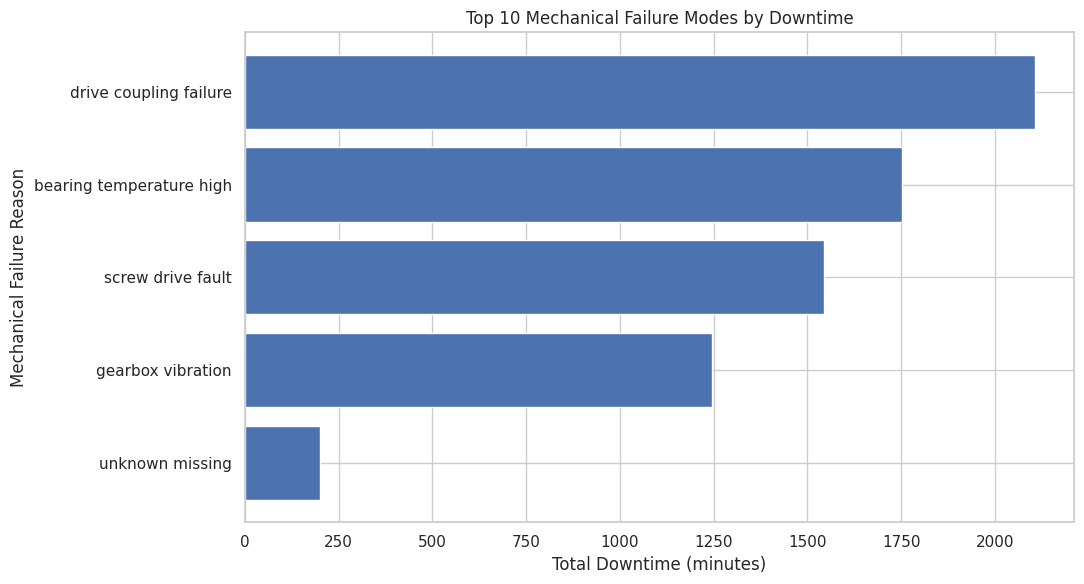

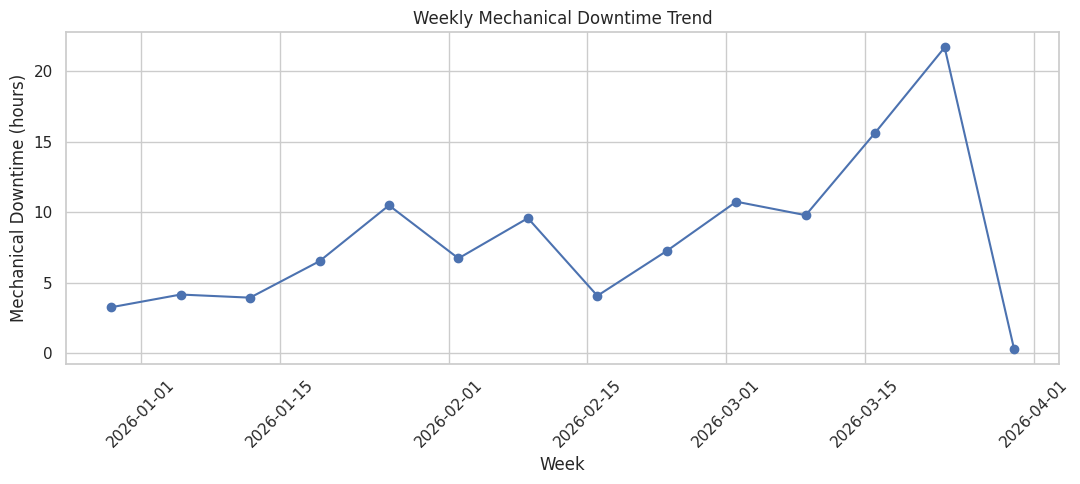

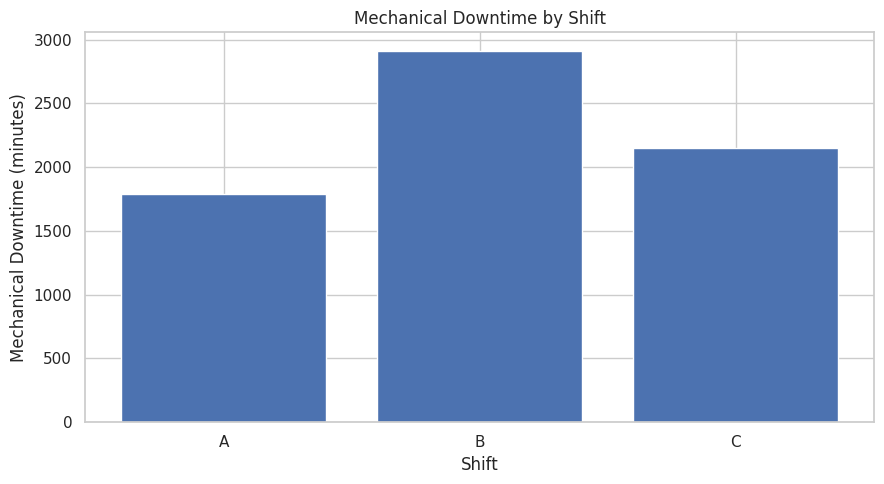

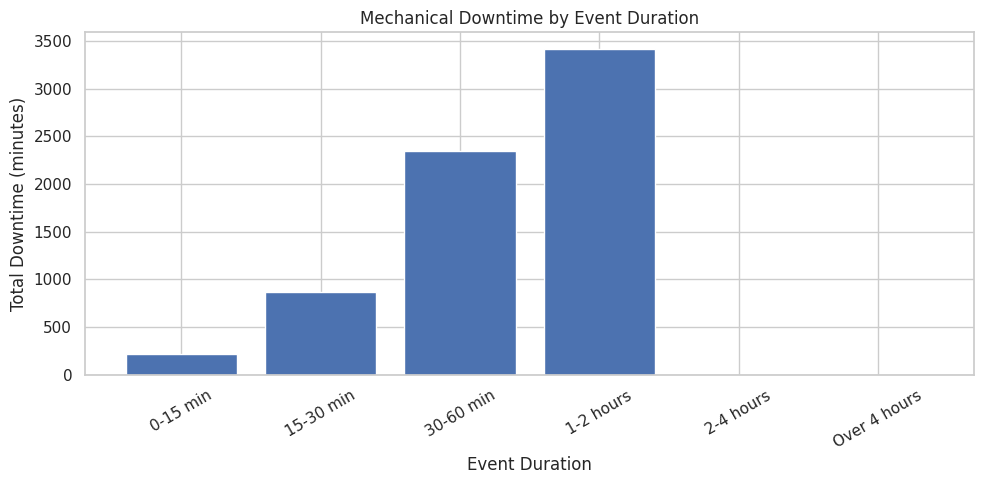


BLOCK 4.1: MECHANICAL DOWNTIME ANALYSIS COMPLETE
Valid mechanical events analyzed: 159
Total mechanical downtime: 6,849.5 minutes
Total mechanical downtime: 114.16 hours
Average event duration: 43.1 minutes
Median event duration: 38.5 minutes
Invalid duration rows excluded: 0

Top 5 failure modes by downtime:


,Analysis_Reason,Event_Count,Total_Downtime_Min,Average_Duration_Min,Median_Duration_Min,Maximum_Duration_Min,Downtime_Share_Pct,Cumulative_Downtime_Share_Pct
1,drive coupling failure,47,"2,105.9100",44.8066,40.0400,105.0000,30.7457,30.7457
0,bearing temperature high,40,"1,752.5800",43.8145,35.7800,105.0000,25.5872,56.3328
3,screw drive fault,38,"1,545.5500",40.6724,35.0400,105.0000,22.5646,78.8974
2,gearbox vibration,30,"1,246.1300",41.5377,36.6500,105.0000,18.1931,97.0906
4,unknown missing,4,199.2800,49.8200,50.8100,59.4500,2.9094,100.0000



Outputs saved to: /datasets/_deepnote_work/root_cause_investigation_outputs


In [7]:

# ============================================================
# BLOCK 4.1: MECHANICAL DOWNTIME AND RELIABILITY ANALYSIS
# 4.1.1 - Failure Frequency, Duration, Pareto, and Trends
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    from scipy.stats import spearmanr
except ImportError:
    spearmanr = None


# ------------------------------------------------------------
# 1. CONFIGURATION AND INPUT VALIDATION
# ------------------------------------------------------------

OUTPUT_DIR = Path("root_cause_investigation_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

if "mechanical_events" not in globals():
    raise NameError(
        "mechanical_events was not found. Run Block 4.0 first."
    )

df = mechanical_events.copy()

if df.empty:
    raise ValueError(
        "mechanical_events is empty. Check the Block 4.0 event grouping."
    )

if "Duration_Min" not in df.columns:
    raise KeyError(
        "Duration_Min is missing from mechanical_events."
    )

df["Duration_Min"] = pd.to_numeric(
    df["Duration_Min"], errors="coerce"
)

# Exclude invalid durations from duration-based calculations,
# but preserve the count of excluded records for reporting.
invalid_duration_count = (
    df["Duration_Min"].isna() | (df["Duration_Min"] < 0)
).sum()

df = df[
    df["Duration_Min"].notna()
    & (df["Duration_Min"] >= 0)
].copy()

if df.empty:
    raise ValueError("No valid mechanical event durations remain.")


# ------------------------------------------------------------
# 2. IDENTIFY ANALYSIS COLUMNS
# ------------------------------------------------------------

def choose_column(data, candidates):
    for col in candidates:
        if col in data.columns:
            return col
    return None


reason_col = choose_column(
    df,
    [
        "Event_Reason_Normalized",
        "Event_Reason",
        "Reason_Description",
        "Downtime_Reason",
    ]
)

category_col = choose_column(
    df,
    [
        "Event_Category_Normalized",
        "Event_Category",
        "Downtime_Category",
    ]
)

shift_col = choose_column(
    df,
    ["Shift", "Shift_Production", "Shift_ID", "Shift_Name"]
)

product_col = choose_column(
    df,
    ["Product_ID", "Product_ID_Production"]
)

machine_col = choose_column(
    df,
    ["Machine_ID", "Machine_ID_Production"]
)

date_col = choose_column(
    df,
    [
        "Event_Start",
        "Start_Time",
        "Downtime_Start",
        "Production_Date",
        "Production_Date_Production",
        "Date",
    ]
)

if reason_col is None:
    df["Analysis_Reason"] = "Unknown / Missing"
else:
    df["Analysis_Reason"] = (
        df[reason_col]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .fillna("Unknown / Missing")
    )

if shift_col is None:
    df["Analysis_Shift"] = "Unknown"
else:
    df["Analysis_Shift"] = (
        df[shift_col]
        .astype("string")
        .str.strip()
        .fillna("Unknown")
    )

if product_col is None:
    df["Analysis_Product"] = "Unknown"
else:
    df["Analysis_Product"] = (
        df[product_col]
        .astype("string")
        .str.strip()
        .fillna("Unknown")
    )

if machine_col is None:
    df["Analysis_Machine"] = "Unknown"
else:
    df["Analysis_Machine"] = (
        df[machine_col]
        .astype("string")
        .str.strip()
        .fillna("Unknown")
    )


# ------------------------------------------------------------
# 3. CREATE EVENT DATE AND WEEK
# ------------------------------------------------------------

if date_col is not None:
    df["Analysis_Date"] = pd.to_datetime(
        df[date_col], errors="coerce"
    )
else:
    df["Analysis_Date"] = pd.NaT

# If event timestamps are unavailable or invalid, use production date
# when that separate field exists.
if df["Analysis_Date"].isna().all():
    production_date_col = choose_column(
        df,
        [
            "Production_Date",
            "Production_Date_Production",
            "Date",
        ]
    )

    if production_date_col is not None:
        df["Analysis_Date"] = pd.to_datetime(
            df[production_date_col], errors="coerce"
        )

df["Analysis_Week"] = (
    df["Analysis_Date"].dt.to_period("W").dt.start_time
)

df["Analysis_Hours"] = df["Duration_Min"] / 60


# ------------------------------------------------------------
# 4. OVERALL MECHANICAL DOWNTIME KPIs
# ------------------------------------------------------------

total_events = len(df)
total_downtime_min = df["Duration_Min"].sum()
average_duration_min = df["Duration_Min"].mean()
median_duration_min = df["Duration_Min"].median()
longest_event_min = df["Duration_Min"].max()

overall_summary = pd.DataFrame(
    [{
        "Mechanical_Event_Count": total_events,
        "Total_Downtime_Min": total_downtime_min,
        "Total_Downtime_Hours": total_downtime_min / 60,
        "Average_Event_Duration_Min": average_duration_min,
        "Median_Event_Duration_Min": median_duration_min,
        "Longest_Event_Duration_Min": longest_event_min,
        "Invalid_Duration_Rows_Excluded": invalid_duration_count,
    }]
)

print("OVERALL MECHANICAL DOWNTIME")
display(overall_summary)


# ------------------------------------------------------------
# 5. FAILURE MODE PARETO
# ------------------------------------------------------------

reason_summary = (
    df.groupby("Analysis_Reason", dropna=False)
    .agg(
        Event_Count=("Duration_Min", "size"),
        Total_Downtime_Min=("Duration_Min", "sum"),
        Average_Duration_Min=("Duration_Min", "mean"),
        Median_Duration_Min=("Duration_Min", "median"),
        Maximum_Duration_Min=("Duration_Min", "max"),
    )
    .reset_index()
    .sort_values("Total_Downtime_Min", ascending=False)
)

reason_summary["Downtime_Share_Pct"] = (
    reason_summary["Total_Downtime_Min"]
    / total_downtime_min * 100
)

reason_summary["Cumulative_Downtime_Share_Pct"] = (
    reason_summary["Downtime_Share_Pct"].cumsum()
)

print("\nMECHANICAL FAILURE MODE PARETO")
display(reason_summary.head(20))

reason_summary.to_csv(
    OUTPUT_DIR / "mechanical_failure_mode_pareto.csv",
    index=False
)


# ------------------------------------------------------------
# 6. SHIFT ANALYSIS
# ------------------------------------------------------------

shift_summary = (
    df.groupby("Analysis_Shift", dropna=False)
    .agg(
        Event_Count=("Duration_Min", "size"),
        Total_Downtime_Min=("Duration_Min", "sum"),
        Average_Duration_Min=("Duration_Min", "mean"),
        Median_Duration_Min=("Duration_Min", "median"),
    )
    .reset_index()
    .sort_values("Total_Downtime_Min", ascending=False)
)

shift_summary["Downtime_Share_Pct"] = (
    shift_summary["Total_Downtime_Min"]
    / total_downtime_min * 100
)

print("\nMECHANICAL DOWNTIME BY SHIFT")
display(shift_summary)

shift_summary.to_csv(
    OUTPUT_DIR / "mechanical_downtime_by_shift.csv",
    index=False
)


# ------------------------------------------------------------
# 7. PRODUCT ANALYSIS
# ------------------------------------------------------------

product_summary = (
    df.groupby("Analysis_Product", dropna=False)
    .agg(
        Event_Count=("Duration_Min", "size"),
        Total_Downtime_Min=("Duration_Min", "sum"),
        Average_Duration_Min=("Duration_Min", "mean"),
        Median_Duration_Min=("Duration_Min", "median"),
    )
    .reset_index()
    .sort_values("Total_Downtime_Min", ascending=False)
)

product_summary["Downtime_Share_Pct"] = (
    product_summary["Total_Downtime_Min"]
    / total_downtime_min * 100
)

print("\nMECHANICAL DOWNTIME BY PRODUCT")
display(product_summary)

product_summary.to_csv(
    OUTPUT_DIR / "mechanical_downtime_by_product.csv",
    index=False
)


# ------------------------------------------------------------
# 8. MACHINE / EQUIPMENT ANALYSIS
# ------------------------------------------------------------

machine_summary = (
    df.groupby("Analysis_Machine", dropna=False)
    .agg(
        Event_Count=("Duration_Min", "size"),
        Total_Downtime_Min=("Duration_Min", "sum"),
        Average_Duration_Min=("Duration_Min", "mean"),
        Median_Duration_Min=("Duration_Min", "median"),
    )
    .reset_index()
    .sort_values("Total_Downtime_Min", ascending=False)
)

machine_summary["Downtime_Share_Pct"] = (
    machine_summary["Total_Downtime_Min"]
    / total_downtime_min * 100
)

print("\nMECHANICAL DOWNTIME BY MACHINE")
display(machine_summary)

machine_summary.to_csv(
    OUTPUT_DIR / "mechanical_downtime_by_machine.csv",
    index=False
)


# ------------------------------------------------------------
# 9. WEEKLY MECHANICAL DOWNTIME TREND
# ------------------------------------------------------------

weekly_df = df[df["Analysis_Week"].notna()].copy()

if not weekly_df.empty:
    weekly_summary = (
        weekly_df.groupby("Analysis_Week")
        .agg(
            Event_Count=("Duration_Min", "size"),
            Total_Downtime_Min=("Duration_Min", "sum"),
            Average_Duration_Min=("Duration_Min", "mean"),
            Median_Duration_Min=("Duration_Min", "median"),
        )
        .reset_index()
        .sort_values("Analysis_Week")
    )

    weekly_summary["Total_Downtime_Hours"] = (
        weekly_summary["Total_Downtime_Min"] / 60
    )

    weekly_summary["Downtime_Min_Per_Event"] = (
        weekly_summary["Total_Downtime_Min"]
        / weekly_summary["Event_Count"]
    )

    print("\nWEEKLY MECHANICAL DOWNTIME")
    display(weekly_summary)

    weekly_summary.to_csv(
        OUTPUT_DIR / "mechanical_downtime_weekly_trend.csv",
        index=False
    )

    if spearmanr is not None and len(weekly_summary) >= 4:
        week_index = np.arange(len(weekly_summary))

        count_corr, count_p = spearmanr(
            week_index,
            weekly_summary["Event_Count"]
        )

        duration_corr, duration_p = spearmanr(
            week_index,
            weekly_summary["Total_Downtime_Min"]
        )

        weekly_trend_stats = pd.DataFrame(
            [
                {
                    "Metric": "Weekly event count",
                    "Spearman_Correlation": count_corr,
                    "P_Value": count_p,
                    "Number_of_Weeks": len(weekly_summary),
                },
                {
                    "Metric": "Weekly downtime minutes",
                    "Spearman_Correlation": duration_corr,
                    "P_Value": duration_p,
                    "Number_of_Weeks": len(weekly_summary),
                },
            ]
        )

        print("\nWEEKLY TREND CORRELATIONS")
        display(weekly_trend_stats)

        weekly_trend_stats.to_csv(
            OUTPUT_DIR / "mechanical_weekly_trend_statistics.csv",
            index=False
        )

else:
    weekly_summary = pd.DataFrame()
    print(
        "\nNo valid event dates found. "
        "Weekly trend analysis was skipped."
    )


# ------------------------------------------------------------
# 10. EVENT DURATION DISTRIBUTION
# ------------------------------------------------------------

duration_bins = [0, 15, 30, 60, 120, 240, np.inf]
duration_labels = [
    "0-15 min",
    "15-30 min",
    "30-60 min",
    "1-2 hours",
    "2-4 hours",
    "Over 4 hours",
]

df["Duration_Band"] = pd.cut(
    df["Duration_Min"],
    bins=duration_bins,
    labels=duration_labels,
    right=False,
    include_lowest=True
)

duration_distribution = (
    df.groupby("Duration_Band", observed=False)
    .agg(
        Event_Count=("Duration_Min", "size"),
        Total_Downtime_Min=("Duration_Min", "sum"),
    )
    .reset_index()
)

duration_distribution["Event_Share_Pct"] = (
    duration_distribution["Event_Count"] / total_events * 100
)

duration_distribution["Downtime_Share_Pct"] = (
    duration_distribution["Total_Downtime_Min"]
    / total_downtime_min * 100
)

print("\nMECHANICAL EVENT DURATION DISTRIBUTION")
display(duration_distribution)

duration_distribution.to_csv(
    OUTPUT_DIR / "mechanical_event_duration_distribution.csv",
    index=False
)


# ------------------------------------------------------------
# 11. VISUALIZATIONS
# ------------------------------------------------------------

# Pareto chart: top 10 mechanical failure reasons.
top_reasons = reason_summary.head(10).sort_values(
    "Total_Downtime_Min", ascending=True
)

plt.figure(figsize=(11, 6))
plt.barh(
    top_reasons["Analysis_Reason"],
    top_reasons["Total_Downtime_Min"]
)
plt.xlabel("Total Downtime (minutes)")
plt.ylabel("Mechanical Failure Reason")
plt.title("Top 10 Mechanical Failure Modes by Downtime")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "mechanical_failure_mode_pareto.png",
    dpi=150
)
plt.show()


# Weekly downtime trend.
if not weekly_summary.empty:
    plt.figure(figsize=(11, 5))
    plt.plot(
        weekly_summary["Analysis_Week"],
        weekly_summary["Total_Downtime_Hours"],
        marker="o"
    )
    plt.xlabel("Week")
    plt.ylabel("Mechanical Downtime (hours)")
    plt.title("Weekly Mechanical Downtime Trend")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / "mechanical_weekly_downtime_trend.png",
        dpi=150
    )
    plt.show()


# Event count versus total downtime by shift.
shift_plot = shift_summary.sort_values(
    "Analysis_Shift"
)

plt.figure(figsize=(9, 5))
plt.bar(
    shift_plot["Analysis_Shift"].astype(str),
    shift_plot["Total_Downtime_Min"]
)
plt.xlabel("Shift")
plt.ylabel("Mechanical Downtime (minutes)")
plt.title("Mechanical Downtime by Shift")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "mechanical_downtime_by_shift.png",
    dpi=150
)
plt.show()


# Duration distribution.
plt.figure(figsize=(10, 5))
plt.bar(
    duration_distribution["Duration_Band"].astype(str),
    duration_distribution["Total_Downtime_Min"]
)
plt.xlabel("Event Duration")
plt.ylabel("Total Downtime (minutes)")
plt.title("Mechanical Downtime by Event Duration")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "mechanical_duration_distribution.png",
    dpi=150
)
plt.show()


# ------------------------------------------------------------
# 12. EXPORT ANALYSIS-READY EVENT DATA
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_DIR / "mechanical_events_analyzed.csv",
    index=False
)


# ------------------------------------------------------------
# 13. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("BLOCK 4.1: MECHANICAL DOWNTIME ANALYSIS COMPLETE")
print("=" * 65)

print(f"Valid mechanical events analyzed: {len(df):,}")
print(f"Total mechanical downtime: {total_downtime_min:,.1f} minutes")
print(f"Total mechanical downtime: {total_downtime_min / 60:,.2f} hours")
print(f"Average event duration: {average_duration_min:,.1f} minutes")
print(f"Median event duration: {median_duration_min:,.1f} minutes")
print(f"Invalid duration rows excluded: {invalid_duration_count:,}")

print("\nTop 5 failure modes by downtime:")
display(reason_summary.head(5))

print(f"\nOutputs saved to: {OUTPUT_DIR.resolve()}")


SHIFT PERFORMANCE


,Analysis_Shift,Production_Records,Planned_Min,Run_Min,Total_Production_kg,Good_Production_kg,Scrap_kg,Ideal_Planned_kg,Ideal_Run_kg,Availability_Pct,Performance_Pct,Quality_Pct,OEE_Pct,Scrap_Rate_Pct
0,A,90,43200,"38,514.7200","49,576.1800","46,777.1800","2,799.0000","68,360.0000","61,322.9175",89.1544,80.8445,94.3541,68.4277,5.6459
2,C,90,43200,"37,810.7500","46,643.4400","44,032.7400","2,610.7000","67,440.0000","59,045.9075",87.5249,78.9952,94.4029,65.2917,5.5971
1,B,90,43200,"35,338.9800","42,500.9700","39,675.3200","2,825.6500","67,440.0000","55,203.1542",81.8032,76.9901,93.3516,58.8305,6.6484



OPERATOR PERFORMANCE


,Analysis_Operator,Production_Records,Planned_Min,Run_Min,Total_Production_kg,Good_Production_kg,Scrap_kg,Ideal_Planned_kg,Ideal_Run_kg,Availability_Pct,Performance_Pct,Quality_Pct,OEE_Pct,Scrap_Rate_Pct
2,OP-003,26,12480,"11,081.8200","15,114.0600","14,352.5600",761.5000,"20,920.0000","18,691.3925",88.7966,80.8611,94.9616,68.6069,5.0384
1,OP-002,23,11040,"9,825.6300","12,158.8100","11,487.6400",671.1700,"17,320.0000","15,377.0433",89.0003,79.0712,94.4800,66.3259,5.5200
4,OP-005,16,7680,"6,843.7700","8,344.8100","7,809.2800",535.5300,"11,920.0000","10,575.2433",89.1116,78.9089,93.5825,65.5141,6.4175
11,OP-012,22,10560,"9,179.1100","11,237.3100","10,580.1900",657.1200,"16,160.0000","14,352.9492",86.9234,78.2927,94.1523,65.4715,5.8477
7,OP-008,22,10560,"9,259.6100","11,292.6200","10,627.2200",665.4000,"16,240.0000","14,278.9975",87.6857,79.0855,94.1077,65.4385,5.8923
3,OP-004,30,14400,"12,355.3000","15,579.6700","14,523.1600","1,056.5100","22,840.0000","19,666.4925",85.8007,79.2194,93.2187,63.5865,6.7813
10,OP-011,25,12000,"10,039.2400","12,931.0300","12,324.8500",606.1800,"19,400.0000","16,246.8667",83.6603,79.5909,95.3122,63.5302,4.6878
0,OP-001,18,8640,"7,332.8500","8,392.3000","7,897.8000",494.5000,"12,520.0000","10,706.8350",84.8709,78.3826,94.1077,63.0815,5.8923
5,OP-006,16,7680,"6,602.6800","8,251.4300","7,741.7800",509.6500,"12,280.0000","10,588.2367",85.9724,77.9302,93.8235,63.0438,6.1765
8,OP-009,27,12960,"10,787.2200","14,411.2800","13,502.2500",909.0300,"21,600.0000","17,927.4233",83.2347,80.3868,93.6922,62.5104,6.3078



SHIFT AND OPERATOR COMPARISON


,Analysis_Shift,Analysis_Operator,Production_Records,Planned_Min,Run_Min,Total_Production_kg,Good_Production_kg,Scrap_kg,Ideal_Planned_kg,Ideal_Run_kg,Availability_Pct,Performance_Pct,Quality_Pct,OEE_Pct,Scrap_Rate_Pct
7,A,OP-008,6,2880,"2,780.1600","3,438.8700","3,272.6900",166.1800,"4,320.0000","4,156.2167",96.5333,82.7404,95.1676,75.7567,4.8324
2,A,OP-003,9,4320,"3,940.1900","6,050.1800","5,770.9000",279.2800,"7,840.0000","7,203.5692",91.2081,83.9886,95.3839,73.6084,4.6161
3,A,OP-004,8,3840,"3,370.7200","5,460.2100","5,197.1200",263.0900,"7,320.0000","6,470.9150",87.7792,84.3808,95.1817,70.9989,4.8183
12,A,Unknown / Missing,4,1920,"1,813.5700","2,069.1200","1,969.2300",99.8900,"2,840.0000","2,686.5892",94.4568,77.0166,95.1723,69.3391,4.8277
10,A,OP-011,14,6720,"5,984.2900","7,846.9600","7,510.9200",336.0400,"10,920.0000","9,767.8375",89.0519,80.3347,95.7176,68.7813,4.2824
1,A,OP-002,11,5280,"4,772.3000","5,704.6800","5,363.4300",341.2500,"7,920.0000","7,129.3308",90.3845,80.0170,94.0181,67.7201,5.9819
4,A,OP-005,5,2400,"2,170.6100","2,677.5800","2,516.1100",161.4700,"3,720.0000","3,381.7175",90.4421,79.1781,93.9696,67.6374,6.0304
5,A,OP-006,6,2880,"2,577.5000","3,118.2800","2,900.1200",218.1600,"4,320.0000","3,902.3208",89.4965,79.9083,93.0038,67.1324,6.9962
6,A,OP-007,4,1920,"1,701.7600","2,329.0900","2,174.3200",154.7700,"3,240.0000","2,842.2275",88.6333,81.9459,93.3549,67.1086,6.6451
0,A,OP-001,3,1440,"1,260.5100","1,418.3700","1,348.1800",70.1900,"2,040.0000","1,771.5658",87.5354,80.0631,95.0514,66.0873,4.9486



OPERATOR DATA COVERAGE


,Total_Production_Records,Records_With_Operator_ID,Records_Missing_Operator_ID,Operator_ID_Column_Available,Unique_Operator_Labels
0,270,259,11,True,13


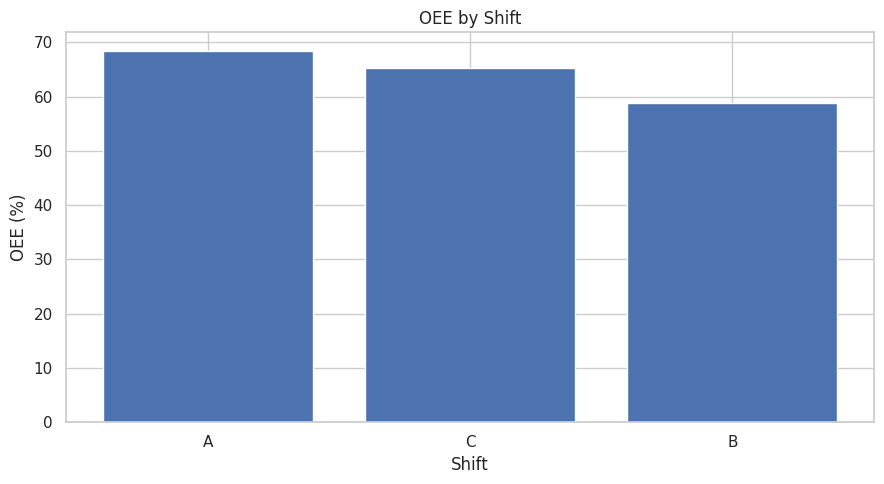

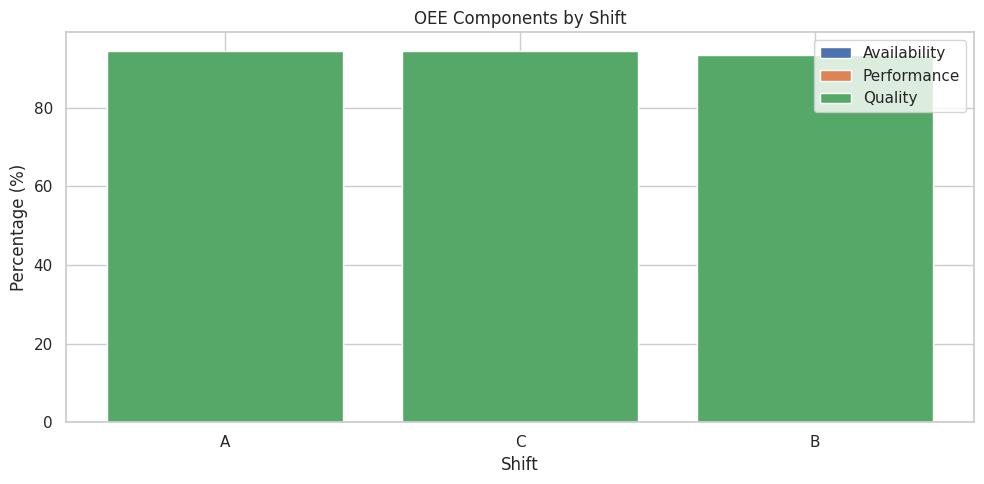

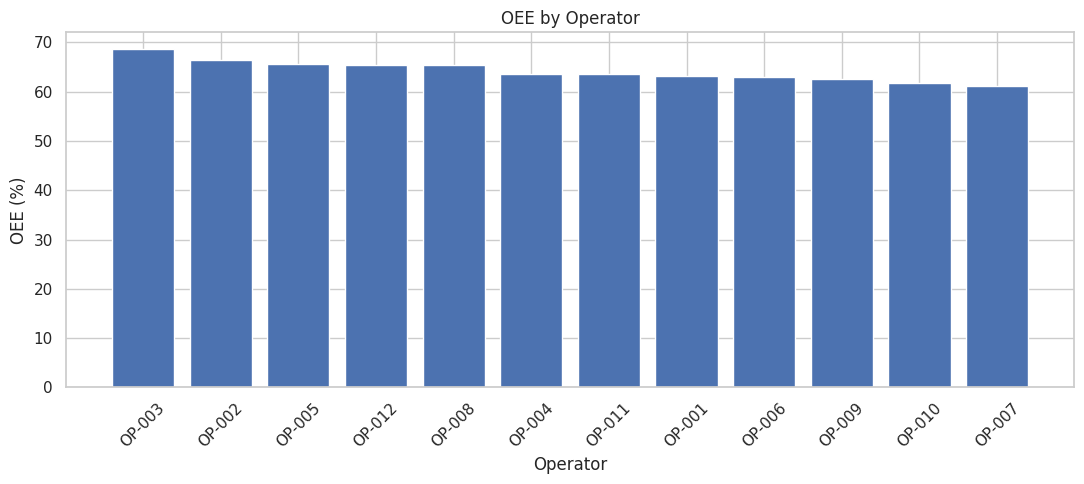


BLOCK 4.2 COMPLETE
Outputs saved to: /datasets/_deepnote_work/root_cause_investigation_outputs


In [8]:

# ============================================================
# BLOCK 4.2: SHIFT AND OPERATOR PERFORMANCE ANALYSIS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("root_cause_investigation_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

if "root_cause_production" not in globals():
    raise NameError("Run Block 4.0 first.")

df = root_cause_production.copy()


# ------------------------------------------------------------
# 1. IDENTIFY REQUIRED COLUMNS
# ------------------------------------------------------------

def find_col(data, candidates, required=True):
    for col in candidates:
        if col in data.columns:
            return col
    if required:
        raise KeyError(
            f"Missing required column. Tried {candidates}. "
            f"Available columns: {list(data.columns)}"
        )
    return None


shift_col = find_col(df, ["Shift", "Shift_Production", "Shift_ID", "Shift_Name"])
operator_col = find_col(
    df, ["Operator_ID", "Operator_ID_Production", "OperatorID"], required=False
)
total_col = find_col(
    df, ["Total_Production_kg", "Total_Production", "Total_kg"]
)
good_col = find_col(
    df, ["Good_Production_kg", "Good_Production", "Good_kg"]
)
scrap_col = find_col(
    df, ["Scrap_kg", "Scrap", "Scrap_Quantity_kg"], required=False
)
planned_col = find_col(
    df, ["Planned_Time_Min", "Planned_Production_Min", "Planned_Minutes"]
)
run_col = find_col(
    df, ["Run_Time_Min", "Runtime_Min", "Operating_Time_Min"]
)
ideal_rate_col = find_col(
    df, ["Ideal_Rate_kg_hr", "Ideal_Rate", "Standard_Rate_kg_hr"]
)
date_col = find_col(
    df, ["Production_Date", "Date", "Shift_Date"], required=False
)

# Numeric conversion.
for col in [total_col, good_col, planned_col, run_col, ideal_rate_col]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if scrap_col:
    df[scrap_col] = pd.to_numeric(df[scrap_col], errors="coerce")
else:
    df["_Calculated_Scrap_kg"] = df[total_col] - df[good_col]
    scrap_col = "_Calculated_Scrap_kg"

# Standardized analysis fields.
df["Analysis_Shift"] = (
    df[shift_col].astype("string").str.strip().fillna("Unknown")
)

if operator_col:
    df["Analysis_Operator"] = (
        df[operator_col].astype("string").str.strip()
        .replace("", pd.NA).fillna("Unknown / Missing")
    )
else:
    df["Analysis_Operator"] = "Operator ID Unavailable"

# Production metrics.
df["Ideal_Planned_kg"] = (
    df[ideal_rate_col] * df[planned_col] / 60
)
df["Ideal_Run_kg"] = (
    df[ideal_rate_col] * df[run_col] / 60
)

df["Availability"] = np.where(
    df[planned_col] > 0,
    df[run_col] / df[planned_col],
    np.nan
)

df["Performance"] = np.where(
    df["Ideal_Run_kg"] > 0,
    df[total_col] / df["Ideal_Run_kg"],
    np.nan
)

df["Quality"] = np.where(
    df[total_col] > 0,
    df[good_col] / df[total_col],
    np.nan
)

df["OEE"] = np.where(
    df["Ideal_Planned_kg"] > 0,
    df[good_col] / df["Ideal_Planned_kg"],
    np.nan
)

df["Scrap_Rate"] = np.where(
    df[total_col] > 0,
    df[scrap_col] / df[total_col],
    np.nan
)


# ------------------------------------------------------------
# 2. AGGREGATION FUNCTION
#    Ratios are calculated from summed numerators/denominators,
#    not by averaging shift-level percentages.
# ------------------------------------------------------------

def summarize_groups(data, group_cols):
    grouped = data.groupby(group_cols, dropna=False).agg(
        Production_Records=(total_col, "size"),
        Planned_Min=(planned_col, "sum"),
        Run_Min=(run_col, "sum"),
        Total_Production_kg=(total_col, "sum"),
        Good_Production_kg=(good_col, "sum"),
        Scrap_kg=(scrap_col, "sum"),
        Ideal_Planned_kg=("Ideal_Planned_kg", "sum"),
        Ideal_Run_kg=("Ideal_Run_kg", "sum"),
    ).reset_index()

    grouped["Availability_Pct"] = (
        grouped["Run_Min"] / grouped["Planned_Min"] * 100
    )
    grouped["Performance_Pct"] = (
        grouped["Total_Production_kg"] / grouped["Ideal_Run_kg"] * 100
    )
    grouped["Quality_Pct"] = (
        grouped["Good_Production_kg"]
        / grouped["Total_Production_kg"] * 100
    )
    grouped["OEE_Pct"] = (
        grouped["Good_Production_kg"]
        / grouped["Ideal_Planned_kg"] * 100
    )
    grouped["Scrap_Rate_Pct"] = (
        grouped["Scrap_kg"]
        / grouped["Total_Production_kg"] * 100
    )

    return grouped


# ------------------------------------------------------------
# 3. SHIFT PERFORMANCE
# ------------------------------------------------------------

shift_summary = summarize_groups(df, ["Analysis_Shift"])

shift_summary = shift_summary.sort_values("OEE_Pct", ascending=False)

print("SHIFT PERFORMANCE")
display(shift_summary)

shift_summary.to_csv(
    OUTPUT_DIR / "shift_performance_analysis.csv", index=False
)


# ------------------------------------------------------------
# 4. OPERATOR PERFORMANCE
# ------------------------------------------------------------

operator_summary = summarize_groups(df, ["Analysis_Operator"])

operator_summary = operator_summary.sort_values(
    "OEE_Pct", ascending=False
)

print("\nOPERATOR PERFORMANCE")
display(operator_summary)

operator_summary.to_csv(
    OUTPUT_DIR / "operator_performance_analysis.csv", index=False
)


# ------------------------------------------------------------
# 5. SHIFT-OPERATOR COMPARISON
# ------------------------------------------------------------

shift_operator_summary = summarize_groups(
    df, ["Analysis_Shift", "Analysis_Operator"]
)

shift_operator_summary = shift_operator_summary.sort_values(
    ["Analysis_Shift", "OEE_Pct"],
    ascending=[True, False]
)

print("\nSHIFT AND OPERATOR COMPARISON")
display(shift_operator_summary)

shift_operator_summary.to_csv(
    OUTPUT_DIR / "shift_operator_performance.csv", index=False
)


# ------------------------------------------------------------
# 6. OPERATOR DATA COVERAGE
# ------------------------------------------------------------

operator_coverage = pd.DataFrame([{
    "Total_Production_Records": len(df),
    "Records_With_Operator_ID": (
        df["Analysis_Operator"].ne("Unknown / Missing")
        & df["Analysis_Operator"].ne("Operator ID Unavailable")
    ).sum(),
    "Records_Missing_Operator_ID": (
        df["Analysis_Operator"].eq("Unknown / Missing")
    ).sum(),
    "Operator_ID_Column_Available": operator_col is not None,
    "Unique_Operator_Labels": df["Analysis_Operator"].nunique(),
}])

print("\nOPERATOR DATA COVERAGE")
display(operator_coverage)

operator_coverage.to_csv(
    OUTPUT_DIR / "operator_data_coverage.csv", index=False
)


# ------------------------------------------------------------
# 7. VISUALIZATIONS
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))
plt.bar(
    shift_summary["Analysis_Shift"].astype(str),
    shift_summary["OEE_Pct"]
)
plt.xlabel("Shift")
plt.ylabel("OEE (%)")
plt.title("OEE by Shift")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "oee_by_shift.png", dpi=150)
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(
    shift_summary["Analysis_Shift"].astype(str),
    shift_summary["Availability_Pct"],
    label="Availability"
)
plt.bar(
    shift_summary["Analysis_Shift"].astype(str),
    shift_summary["Performance_Pct"],
    label="Performance"
)
plt.bar(
    shift_summary["Analysis_Shift"].astype(str),
    shift_summary["Quality_Pct"],
    label="Quality"
)
plt.xlabel("Shift")
plt.ylabel("Percentage (%)")
plt.title("OEE Components by Shift")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "oee_components_by_shift.png", dpi=150)
plt.show()

# Operator chart excludes missing IDs and unavailable operator data.
valid_operator_summary = operator_summary[
    ~operator_summary["Analysis_Operator"].isin(
        ["Unknown / Missing", "Operator ID Unavailable"]
    )
].copy()

if not valid_operator_summary.empty:
    plt.figure(figsize=(11, 5))
    plt.bar(
        valid_operator_summary["Analysis_Operator"].astype(str),
        valid_operator_summary["OEE_Pct"]
    )
    plt.xlabel("Operator")
    plt.ylabel("OEE (%)")
    plt.title("OEE by Operator")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "oee_by_operator.png", dpi=150)
    plt.show()
else:
    print("\nOperator chart skipped: no valid operator IDs available.")


# ------------------------------------------------------------
# 8. EXPORT ANALYSIS DATA
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_DIR / "shift_operator_production_analysis.csv",
    index=False
)

print("\nBLOCK 4.2 COMPLETE")
print(f"Outputs saved to: {OUTPUT_DIR.resolve()}")


PRODUCT-LEVEL LOSS SUMMARY


,Analysis_Product,Analysis_Product_Name,Analysis_Product_Family,Production_Records,Planned_Min,Run_Min,Total_Production_kg,Good_Production_kg,Scrap_kg,Ideal_Planned_kg,Ideal_Run_kg,Availability_Loss_kg,Performance_Loss_kg,Quality_Loss_kg,Total_Loss_kg,Availability_Pct,Performance_Pct,Quality_Pct,OEE_Pct,Scrap_Rate_Pct,Availability_Loss_kg_Share_Pct,Performance_Loss_kg_Share_Pct,Quality_Loss_kg_Share_Pct,Total_Loss_kg_Share_Pct
0,P-1001,Standard Grade,Not Available,71,34080,"29,616.1000","49,058.7600","47,221.4200","1,837.3400","68,160.0000","59,232.2000","8,927.8000","10,173.4400","1,837.3400","20,938.5800",86.9017,82.8245,96.2548,69.2803,3.7452,32.2676,27.6067,22.3104,28.7797
1,P-1002,Flexible Grade,Not Available,58,27840,"24,284.7000","34,100.7500","32,536.3500","1,564.4000","48,720.0000","42,498.2250","6,221.7750","8,397.4750","1,564.4000","16,183.6500",87.2295,80.2404,95.4124,66.7823,4.5876,22.4872,22.7874,18.9962,22.2441
3,P-1004,Filtration Grade,Not Available,62,29760,"26,010.7100","28,474.3400","26,820.0900","1,654.2500","42,160.0000","36,848.5058","5,311.4942","8,374.1658","1,654.2500","15,339.9100",87.4016,77.2741,94.1904,63.6150,5.8096,19.1972,22.7242,20.0872,21.0844
2,P-1003,Specialty Grade,Not Available,39,18720,"15,564.1800","14,390.7000","12,102.5800","2,288.1200","23,400.0000","19,455.2250","3,944.7750","5,064.5250","2,288.1200","11,297.4200",83.1420,73.9683,84.1000,51.7204,15.9000,14.2575,13.7431,27.7841,15.5281
4,P-1005,Specialty Grade,Not Available,40,19200,"16,188.7600","12,696.0400","11,804.8000",891.2400,"20,800.0000","17,537.8233","3,262.1767","4,841.7833",891.2400,"8,995.2000",84.3165,72.3923,92.9802,56.7538,7.0198,11.7904,13.1387,10.8221,12.3637



LOSS RECONCILIATION


,Availability_Loss_kg,Performance_Loss_kg,Quality_Loss_kg,Sum_Of_Loss_Components_kg,Direct_Total_Loss_kg,Reconciliation_Difference_kg
0,"27,668.0208","36,851.3892","8,235.3500","72,754.7600","72,754.7600",0.0000



PRODUCT SCRAP CONTRIBUTION


,Analysis_Product,Total_Production_kg,Production_Share_Pct,Scrap_kg,Scrap_Rate_Pct,Scrap_Contribution_Pct,Scrap_Contribution_vs_Production_pp
2,P-1003,"14,390.7000",10.3739,"2,288.1200",15.9000,27.7841,17.4103
0,P-1001,"49,058.7600",35.3652,"1,837.3400",3.7452,22.3104,-13.0548
3,P-1004,"28,474.3400",20.5264,"1,654.2500",5.8096,20.0872,-0.4392
1,P-1002,"34,100.7500",24.5823,"1,564.4000",4.5876,18.9962,-5.5862
4,P-1005,"12,696.0400",9.1522,891.2400,7.0198,10.8221,1.6699



PROCESS DOWNTIME BY PRODUCT


,Analysis_Product,Process_Event_Count,Process_Downtime_Min,Average_Event_Duration_Min
3,P-1004,35,604.9000,17.2829
2,P-1003,24,522.0400,21.7517
0,P-1001,24,503.0300,20.9596
1,P-1002,23,459.9900,19.9996
4,P-1005,20,421.6600,21.0830



PROCESS DOWNTIME BY PRODUCT AND REASON


,Analysis_Product,Analysis_Process_Reason,Event_Count,Total_Downtime_Min,Average_Duration_Min
9,P-1003,die buildup requiring stop,8,235.1000,29.3875
2,P-1001,melt temperature instability,10,193.0300,19.3030
20,P-1005,dimensional adjustment,7,179.4200,25.6314
14,P-1004,die buildup requiring stop,10,173.1800,17.3180
1,P-1001,dimensional adjustment,8,163.5300,20.4413
17,P-1004,pressure instability,9,162.9200,18.1022
15,P-1004,dimensional adjustment,8,156.2000,19.5250
3,P-1001,pressure instability,4,133.6900,33.4225
7,P-1002,pressure instability,7,127.6300,18.2329
5,P-1002,dimensional adjustment,5,111.8700,22.3740


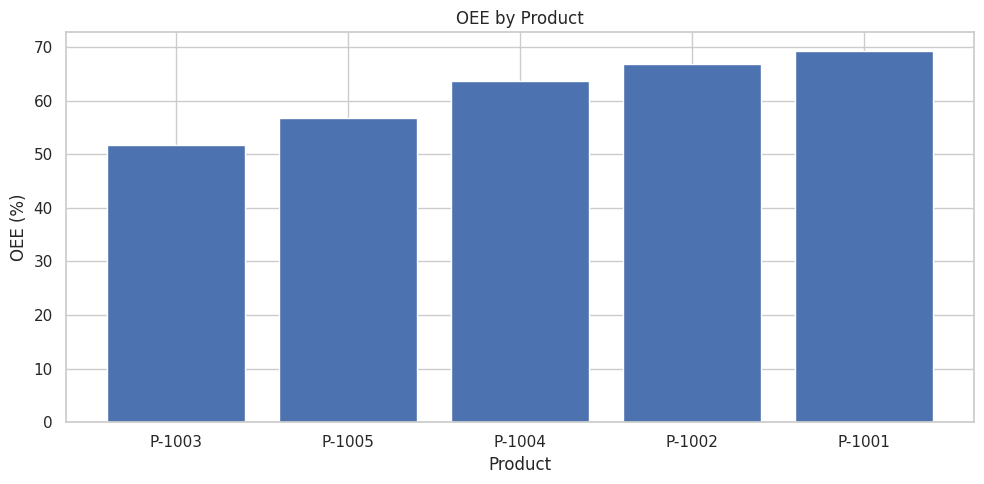

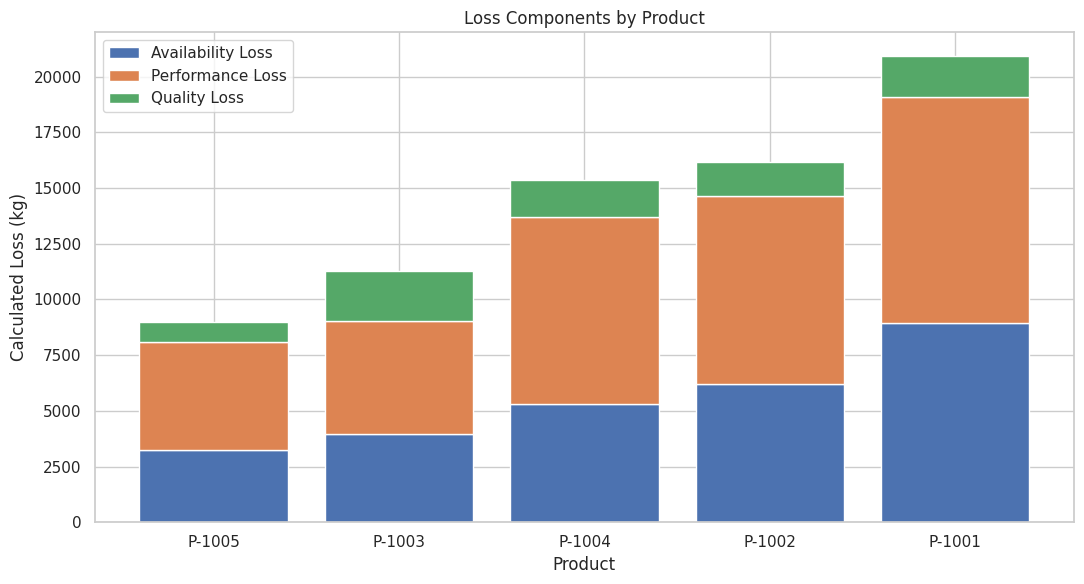

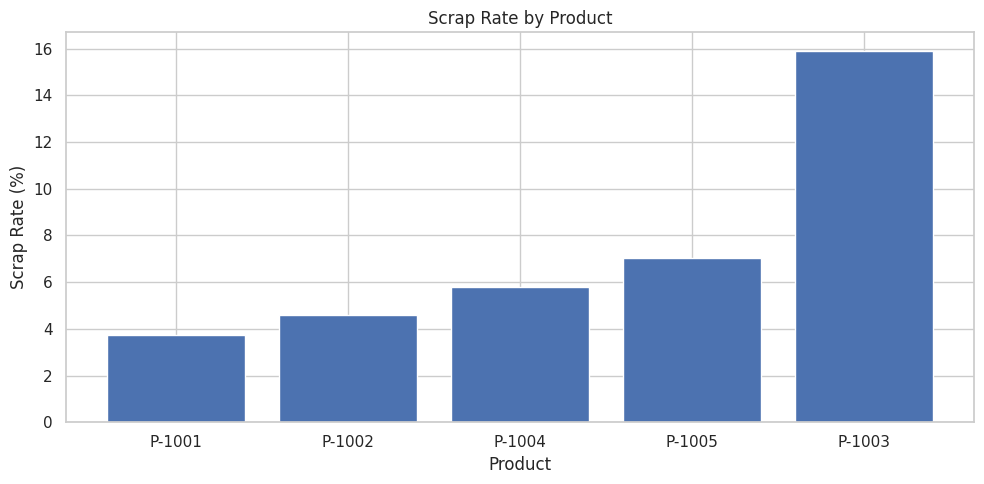


BLOCK 4.3 COMPLETE
Outputs saved to: /datasets/_deepnote_work/root_cause_investigation_outputs


In [9]:

# ============================================================
# BLOCK 4.3: PRODUCT AND PROCESS LOSS ANALYSIS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("root_cause_investigation_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

if "root_cause_production" not in globals():
    raise NameError("Run Block 4.0 first.")

df = root_cause_production.copy()


# ------------------------------------------------------------
# 1. IDENTIFY REQUIRED COLUMNS
# ------------------------------------------------------------

def find_col(data, candidates, required=True):
    for col in candidates:
        if col in data.columns:
            return col
    if required:
        raise KeyError(
            f"Missing required column. Tried {candidates}. "
            f"Available columns: {list(data.columns)}"
        )
    return None


product_col = find_col(df, ["Product_ID", "Product_ID_Production"])
total_col = find_col(
    df, ["Total_Production_kg", "Total_Production", "Total_kg"]
)
good_col = find_col(
    df, ["Good_Production_kg", "Good_Production", "Good_kg"]
)
scrap_col = find_col(
    df, ["Scrap_kg", "Scrap", "Scrap_Quantity_kg"], required=False
)
planned_col = find_col(
    df, ["Planned_Time_Min", "Planned_Production_Min", "Planned_Minutes"]
)
run_col = find_col(
    df, ["Run_Time_Min", "Runtime_Min", "Operating_Time_Min"]
)
ideal_rate_col = find_col(
    df, ["Ideal_Rate_kg_hr", "Ideal_Rate", "Standard_Rate_kg_hr"]
)
product_name_col = find_col(
    df, ["Product_Name", "Product_Description"], required=False
)
family_col = find_col(
    df, ["Product_Family", "Family", "Material_Family"], required=False
)

for col in [total_col, good_col, planned_col, run_col, ideal_rate_col]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if scrap_col:
    df[scrap_col] = pd.to_numeric(df[scrap_col], errors="coerce")
else:
    df["_Calculated_Scrap_kg"] = df[total_col] - df[good_col]
    scrap_col = "_Calculated_Scrap_kg"

df["Analysis_Product"] = (
    df[product_col].astype("string").str.strip().fillna("Unknown")
)

if product_name_col:
    df["Analysis_Product_Name"] = (
        df[product_name_col].astype("string").str.strip()
    )
else:
    df["Analysis_Product_Name"] = df["Analysis_Product"]

if family_col:
    df["Analysis_Product_Family"] = (
        df[family_col].astype("string").str.strip().fillna("Unknown")
    )
else:
    df["Analysis_Product_Family"] = "Not Available"


# ------------------------------------------------------------
# 2. CALCULATE PRODUCT-SPECIFIC IDEAL PRODUCTION
# ------------------------------------------------------------

df["Ideal_Planned_kg"] = (
    df[ideal_rate_col] * df[planned_col] / 60
)

df["Ideal_Run_kg"] = (
    df[ideal_rate_col] * df[run_col] / 60
)

# Loss components use the same definitions as Block 3.
df["Availability_Loss_kg"] = (
    df["Ideal_Planned_kg"] - df["Ideal_Run_kg"]
)

df["Performance_Loss_kg"] = (
    df["Ideal_Run_kg"] - df[total_col]
)

df["Quality_Loss_kg"] = (
    df[total_col] - df[good_col]
)

df["Total_Loss_kg"] = (
    df["Ideal_Planned_kg"] - df[good_col]
)

df["Loss_Component_Sum_kg"] = (
    df["Availability_Loss_kg"]
    + df["Performance_Loss_kg"]
    + df["Quality_Loss_kg"]
)

df["Loss_Reconciliation_Difference_kg"] = (
    df["Total_Loss_kg"] - df["Loss_Component_Sum_kg"]
)

# Ratios.
df["Availability_Pct"] = np.where(
    df[planned_col] > 0,
    df[run_col] / df[planned_col] * 100,
    np.nan
)

df["Performance_Pct"] = np.where(
    df["Ideal_Run_kg"] > 0,
    df[total_col] / df["Ideal_Run_kg"] * 100,
    np.nan
)

df["Quality_Pct"] = np.where(
    df[total_col] > 0,
    df[good_col] / df[total_col] * 100,
    np.nan
)

df["OEE_Pct"] = np.where(
    df["Ideal_Planned_kg"] > 0,
    df[good_col] / df["Ideal_Planned_kg"] * 100,
    np.nan
)

df["Scrap_Rate_Pct"] = np.where(
    df[total_col] > 0,
    df[scrap_col] / df[total_col] * 100,
    np.nan
)


# ------------------------------------------------------------
# 3. PRODUCT-LEVEL LOSS SUMMARY
# ------------------------------------------------------------

product_summary = (
    df.groupby(
        [
            "Analysis_Product",
            "Analysis_Product_Name",
            "Analysis_Product_Family"
        ],
        dropna=False
    )
    .agg(
        Production_Records=(total_col, "size"),
        Planned_Min=(planned_col, "sum"),
        Run_Min=(run_col, "sum"),
        Total_Production_kg=(total_col, "sum"),
        Good_Production_kg=(good_col, "sum"),
        Scrap_kg=(scrap_col, "sum"),
        Ideal_Planned_kg=("Ideal_Planned_kg", "sum"),
        Ideal_Run_kg=("Ideal_Run_kg", "sum"),
        Availability_Loss_kg=("Availability_Loss_kg", "sum"),
        Performance_Loss_kg=("Performance_Loss_kg", "sum"),
        Quality_Loss_kg=("Quality_Loss_kg", "sum"),
        Total_Loss_kg=("Total_Loss_kg", "sum"),
    )
    .reset_index()
)

product_summary["Availability_Pct"] = (
    product_summary["Run_Min"] / product_summary["Planned_Min"] * 100
)

product_summary["Performance_Pct"] = (
    product_summary["Total_Production_kg"]
    / product_summary["Ideal_Run_kg"] * 100
)

product_summary["Quality_Pct"] = (
    product_summary["Good_Production_kg"]
    / product_summary["Total_Production_kg"] * 100
)

product_summary["OEE_Pct"] = (
    product_summary["Good_Production_kg"]
    / product_summary["Ideal_Planned_kg"] * 100
)

product_summary["Scrap_Rate_Pct"] = (
    product_summary["Scrap_kg"]
    / product_summary["Total_Production_kg"] * 100
)

# Contribution to total losses.
for col in [
    "Availability_Loss_kg",
    "Performance_Loss_kg",
    "Quality_Loss_kg",
    "Total_Loss_kg",
]:
    denominator = product_summary[col].sum()
    product_summary[f"{col}_Share_Pct"] = np.where(
        denominator != 0,
        product_summary[col] / denominator * 100,
        np.nan
    )

product_summary = product_summary.sort_values(
    "Total_Loss_kg", ascending=False
)

print("PRODUCT-LEVEL LOSS SUMMARY")
display(product_summary)

product_summary.to_csv(
    OUTPUT_DIR / "product_process_loss_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 4. LOSS RECONCILIATION CHECK
# ------------------------------------------------------------

reconciliation = pd.DataFrame([{
    "Availability_Loss_kg": df["Availability_Loss_kg"].sum(),
    "Performance_Loss_kg": df["Performance_Loss_kg"].sum(),
    "Quality_Loss_kg": df["Quality_Loss_kg"].sum(),
    "Sum_Of_Loss_Components_kg": df["Loss_Component_Sum_kg"].sum(),
    "Direct_Total_Loss_kg": df["Total_Loss_kg"].sum(),
    "Reconciliation_Difference_kg": (
        df["Loss_Reconciliation_Difference_kg"].sum()
    ),
}])

print("\nLOSS RECONCILIATION")
display(reconciliation)

reconciliation.to_csv(
    OUTPUT_DIR / "product_loss_reconciliation.csv",
    index=False
)


# ------------------------------------------------------------
# 5. PRODUCT CONTRIBUTION TO SCRAP
# ------------------------------------------------------------

total_scrap = product_summary["Scrap_kg"].sum()
total_production = product_summary["Total_Production_kg"].sum()

product_summary["Production_Share_Pct"] = (
    product_summary["Total_Production_kg"]
    / total_production * 100
)

product_summary["Scrap_Contribution_Pct"] = np.where(
    total_scrap != 0,
    product_summary["Scrap_kg"] / total_scrap * 100,
    np.nan
)

product_summary["Scrap_Contribution_vs_Production_pp"] = (
    product_summary["Scrap_Contribution_Pct"]
    - product_summary["Production_Share_Pct"]
)

scrap_contribution = product_summary[
    [
        "Analysis_Product",
        "Total_Production_kg",
        "Production_Share_Pct",
        "Scrap_kg",
        "Scrap_Rate_Pct",
        "Scrap_Contribution_Pct",
        "Scrap_Contribution_vs_Production_pp",
    ]
].sort_values("Scrap_kg", ascending=False)

print("\nPRODUCT SCRAP CONTRIBUTION")
display(scrap_contribution)

scrap_contribution.to_csv(
    OUTPUT_DIR / "product_scrap_contribution.csv",
    index=False
)


# ------------------------------------------------------------
# 6. PROCESS-RELATED DOWNTIME BY PRODUCT
# ------------------------------------------------------------

if "root_cause_events" not in globals():
    raise NameError("root_cause_events from Block 4.0 was not found.")

events = root_cause_events.copy()

event_category_col = find_col(
    events,
    ["Event_Category_Normalized", "Event_Category"],
    required=False
)

event_reason_col = find_col(
    events,
    ["Event_Reason_Normalized", "Event_Reason"],
    required=False
)

event_duration_col = find_col(
    events,
    ["Duration_Min"],
    required=False
)

event_product_col = find_col(
    events,
    ["Product_ID", "Product_ID_Production"],
    required=False
)

if event_category_col and event_duration_col and event_product_col:
    events[event_duration_col] = pd.to_numeric(
        events[event_duration_col], errors="coerce"
    )

    category_text = (
        events[event_category_col]
        .astype("string").str.lower().fillna("")
    )

    process_events = events[
        category_text.str.contains("process", regex=False)
    ].copy()

    process_events["Analysis_Product"] = (
        process_events[event_product_col]
        .astype("string").str.strip().fillna("Unknown")
    )

    if event_reason_col:
        process_events["Analysis_Process_Reason"] = (
            process_events[event_reason_col]
            .astype("string").str.strip()
            .replace("", pd.NA)
            .fillna("Unknown / Missing")
        )
    else:
        process_events["Analysis_Process_Reason"] = (
            "Reason Not Available"
        )

    process_product_summary = (
        process_events.groupby("Analysis_Product", dropna=False)
        .agg(
            Process_Event_Count=(event_duration_col, "size"),
            Process_Downtime_Min=(event_duration_col, "sum"),
            Average_Event_Duration_Min=(event_duration_col, "mean"),
        )
        .reset_index()
        .sort_values("Process_Downtime_Min", ascending=False)
    )

    process_reason_summary = (
        process_events.groupby(
            ["Analysis_Product", "Analysis_Process_Reason"],
            dropna=False
        )
        .agg(
            Event_Count=(event_duration_col, "size"),
            Total_Downtime_Min=(event_duration_col, "sum"),
            Average_Duration_Min=(event_duration_col, "mean"),
        )
        .reset_index()
        .sort_values("Total_Downtime_Min", ascending=False)
    )

    print("\nPROCESS DOWNTIME BY PRODUCT")
    display(process_product_summary)

    print("\nPROCESS DOWNTIME BY PRODUCT AND REASON")
    display(process_reason_summary)

    process_product_summary.to_csv(
        OUTPUT_DIR / "process_downtime_by_product.csv",
        index=False
    )

    process_reason_summary.to_csv(
        OUTPUT_DIR / "process_downtime_by_product_reason.csv",
        index=False
    )

else:
    process_product_summary = pd.DataFrame()
    process_reason_summary = pd.DataFrame()
    print(
        "\nProcess-event analysis skipped: required category, "
        "duration, or product columns were not available."
    )


# ------------------------------------------------------------
# 7. VISUALIZATIONS
# ------------------------------------------------------------

# OEE by product.
plot_data = product_summary.sort_values("OEE_Pct")

plt.figure(figsize=(10, 5))
plt.bar(
    plot_data["Analysis_Product"].astype(str),
    plot_data["OEE_Pct"]
)
plt.xlabel("Product")
plt.ylabel("OEE (%)")
plt.title("OEE by Product")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "oee_by_product.png", dpi=150)
plt.show()

# Loss components by product.
loss_columns = [
    "Availability_Loss_kg",
    "Performance_Loss_kg",
    "Quality_Loss_kg",
]

plot_data = product_summary.sort_values("Total_Loss_kg")

plt.figure(figsize=(11, 6))
bottom = np.zeros(len(plot_data))

for col in loss_columns:
    values = plot_data[col].to_numpy()
    plt.bar(
        plot_data["Analysis_Product"].astype(str),
        values,
        bottom=bottom,
        label=col.replace("_kg", "").replace("_", " ")
    )
    bottom += values

plt.xlabel("Product")
plt.ylabel("Calculated Loss (kg)")
plt.title("Loss Components by Product")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "loss_components_by_product.png", dpi=150)
plt.show()

# Scrap rate by product.
plot_data = product_summary.sort_values("Scrap_Rate_Pct")

plt.figure(figsize=(10, 5))
plt.bar(
    plot_data["Analysis_Product"].astype(str),
    plot_data["Scrap_Rate_Pct"]
)
plt.xlabel("Product")
plt.ylabel("Scrap Rate (%)")
plt.title("Scrap Rate by Product")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "scrap_rate_by_product.png", dpi=150)
plt.show()


# ------------------------------------------------------------
# 8. EXPORT ANALYSIS-READY PRODUCTION DATA
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_DIR / "product_process_production_analysis.csv",
    index=False
)

print("\nBLOCK 4.3 COMPLETE")
print(f"Outputs saved to: {OUTPUT_DIR.resolve()}")


OVERALL CHANGEOVER SUMMARY


,Changeover_Event_Count,Total_Changeover_Downtime_Min,Total_Changeover_Downtime_Hours,Average_Duration_Min,Median_Duration_Min,Minimum_Duration_Min,Maximum_Duration_Min,Invalid_Duration_Rows_Excluded
0,133,"4,430.8400",73.8473,33.3146,31.7600,18.0500,59.9800,0



CHANGEOVER REASONS


,Changeover_Reason,Event_Count,Total_Downtime_Min,Average_Duration_Min,Median_Duration_Min,Maximum_Duration_Min,Downtime_Share_Pct,Event_Share_Pct,Cumulative_Downtime_Share_Pct
1,material grade change,49,"1,641.5900",33.5018,32.1600,59.9800,37.0492,36.8421,37.0492
2,product specification change,42,"1,391.5500",33.1321,31.7050,52.8800,31.4060,31.5789,68.4552
0,color purge change,37,"1,207.0300",32.6224,30.5300,52.6600,27.2416,27.8195,95.6968
3,unknown missing,5,190.6700,38.1340,42.5600,52.4700,4.3032,3.7594,100.0000



CHANGEOVER PERFORMANCE BY SHIFT


,Analysis_Shift,Event_Count,Total_Downtime_Min,Average_Duration_Min,Median_Duration_Min,Downtime_Share_Pct
1,B,66,"2,200.5800",33.3421,33.0750,49.6651
0,A,35,"1,206.9200",34.4834,32.8400,27.2391
2,C,32,"1,023.3400",31.9794,28.9200,23.0958


... (2 outputs left out)


WEEKLY CHANGEOVER TREND


,Analysis_Week,Event_Count,Total_Downtime_Min,Average_Duration_Min,Median_Duration_Min,Total_Downtime_Hours
0,2025-12-29,3,78.5300,26.1767,26.3300,1.3088
1,2026-01-05,16,614.6400,38.4150,39.4500,10.2440
2,2026-01-12,9,348.3800,38.7089,42.5600,5.8063
3,2026-01-19,10,260.2500,26.0250,23.7800,4.3375
4,2026-01-26,10,326.7400,32.6740,33.1300,5.4457
5,2026-02-02,12,351.5900,29.2992,26.9050,5.8598
6,2026-02-09,13,393.4400,30.2646,24.6700,6.5573
7,2026-02-16,12,463.0800,38.5900,40.5850,7.7180
8,2026-02-23,6,191.0900,31.8483,30.9700,3.1848
9,2026-03-02,14,449.3600,32.0971,31.7050,7.4893



No changeover standard-duration field was found. Actual duration will be analyzed descriptively only.

CHANGEOVER DURATION DISTRIBUTION


,Duration_Band,Event_Count,Total_Downtime_Min,Event_Share_Pct,Downtime_Share_Pct
0,0-15 min,0,0.0000,0.0000,0.0000
1,15-30 min,58,"1,353.0200",43.6090,30.5364
2,30-60 min,75,"3,077.8200",56.3910,69.4636
3,60-90 min,0,0.0000,0.0000,0.0000
4,90-120 min,0,0.0000,0.0000,0.0000
5,2-4 hours,0,0.0000,0.0000,0.0000
6,Over 4 hours,0,0.0000,0.0000,0.0000


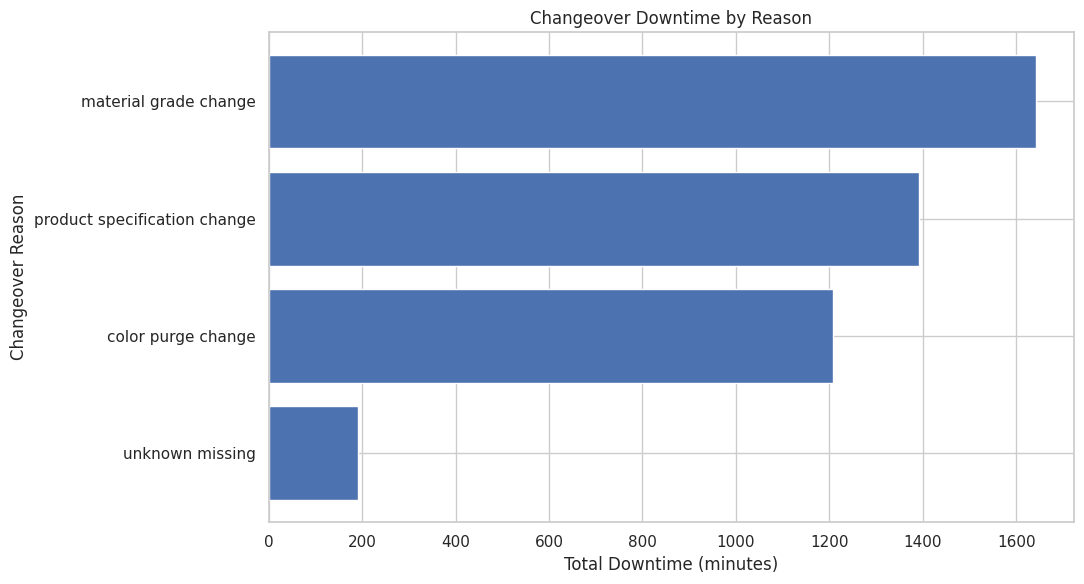

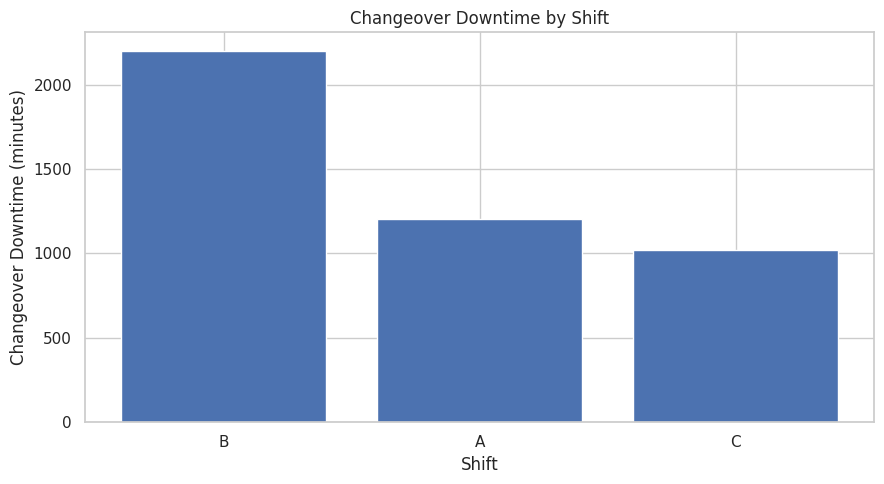

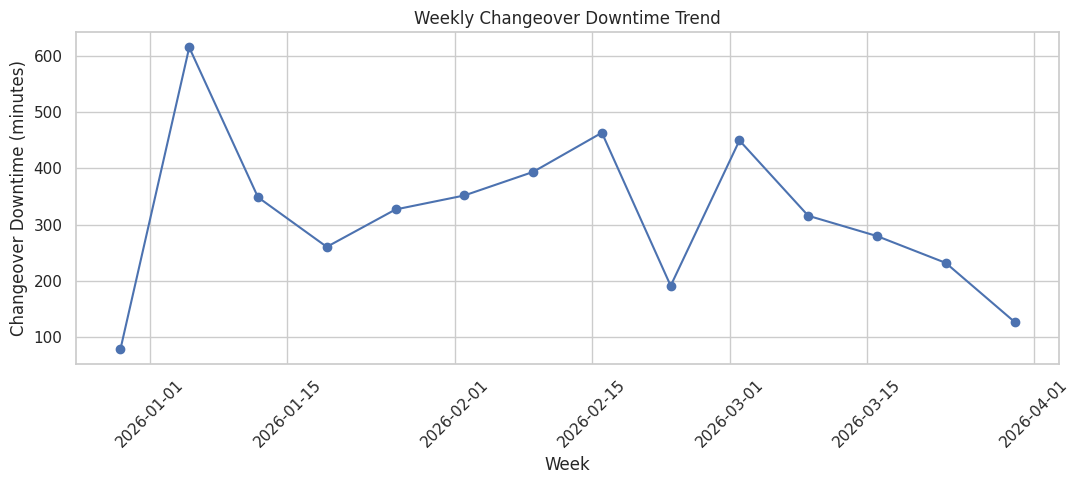

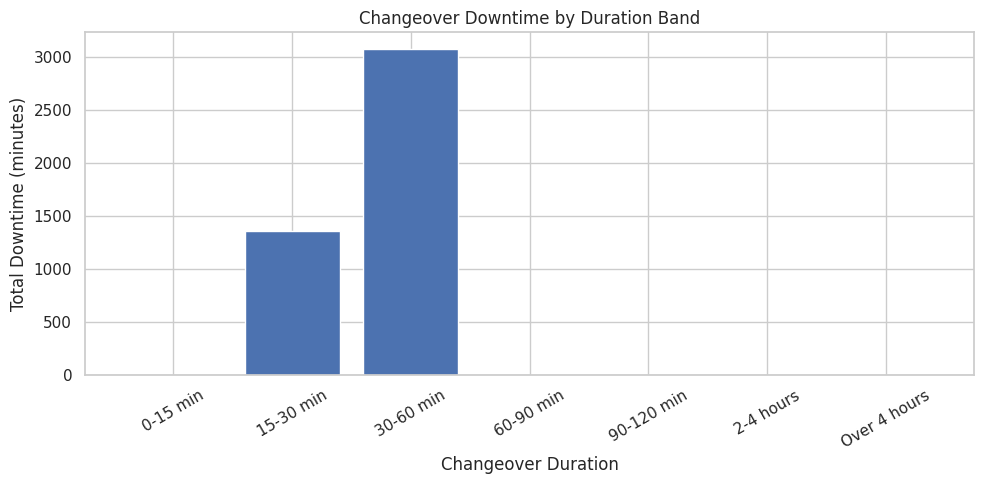


BLOCK 4.4: CHANGEOVER ANALYSIS COMPLETE
Changeover events analyzed: 133
Total changeover downtime: 4,430.8 minutes
Total changeover downtime: 73.85 hours
Average duration: 33.3 minutes
Median duration: 31.8 minutes
Outputs saved to: /datasets/_deepnote_work/root_cause_investigation_outputs


In [10]:

# ============================================================
# BLOCK 4.4: CHANGEOVER EFFECTIVENESS ANALYSIS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("root_cause_investigation_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

if "root_cause_events" not in globals():
    raise NameError("Run Block 4.0 first.")

events = root_cause_events.copy()


# ------------------------------------------------------------
# 1. IDENTIFY REQUIRED COLUMNS
# ------------------------------------------------------------

def find_col(data, candidates, required=True):
    for col in candidates:
        if col in data.columns:
            return col
    if required:
        raise KeyError(
            f"Missing required column. Tried {candidates}. "
            f"Available columns: {list(data.columns)}"
        )
    return None


duration_col = find_col(events, ["Duration_Min"])
group_col = find_col(
    events, ["Analysis_Group"], required=False
)
category_col = find_col(
    events,
    ["Event_Category_Normalized", "Event_Category"],
    required=False
)
reason_col = find_col(
    events,
    ["Event_Reason_Normalized", "Event_Reason"],
    required=False
)
shift_col = find_col(
    events,
    ["Shift", "Shift_Production", "Shift_ID", "Shift_Name"],
    required=False
)
product_col = find_col(
    events, ["Product_ID", "Product_ID_Production"], required=False
)
date_col = find_col(
    events,
    [
        "Event_Start",
        "Start_Time",
        "Downtime_Start",
        "Production_Date",
        "Production_Date_Production",
        "Date",
    ],
    required=False
)

# Optional standard-duration fields. These are only used if present.
standard_col = find_col(
    events,
    [
        "Changeover_Standard_Min",
        "Standard_Changeover_Min",
        "Target_Changeover_Min",
        "Changeover_Target_Min",
    ],
    required=False
)

events[duration_col] = pd.to_numeric(
    events[duration_col], errors="coerce"
)

invalid_duration_count = (
    events[duration_col].isna()
    | (events[duration_col] < 0)
).sum()

events = events[
    events[duration_col].notna()
    & (events[duration_col] >= 0)
].copy()


# ------------------------------------------------------------
# 2. FILTER CHANGEOVER EVENTS
# ------------------------------------------------------------

if group_col:
    changeovers = events[
        events[group_col].astype("string").str.lower().eq("changeover")
    ].copy()

elif category_col:
    changeovers = events[
        events[category_col].astype("string").str.lower()
        .str.contains("changeover", na=False)
    ].copy()

else:
    raise KeyError(
        "Cannot identify changeover events. "
        "Expected Analysis_Group or Event_Category."
    )

if changeovers.empty:
    raise ValueError(
        "No changeover events were identified. "
        "Review the Block 4.0 event grouping and source categories."
    )

changeovers["Changeover_Duration_Min"] = (
    changeovers[duration_col]
)

if reason_col:
    changeovers["Changeover_Reason"] = (
        changeovers[reason_col]
        .astype("string").str.strip()
        .replace("", pd.NA)
        .fillna("Unknown / Missing")
    )
else:
    changeovers["Changeover_Reason"] = "Reason Not Available"

if shift_col:
    changeovers["Analysis_Shift"] = (
        changeovers[shift_col]
        .astype("string").str.strip().fillna("Unknown")
    )
else:
    changeovers["Analysis_Shift"] = "Unknown"

if product_col:
    changeovers["Analysis_Product"] = (
        changeovers[product_col]
        .astype("string").str.strip().fillna("Unknown")
    )
else:
    changeovers["Analysis_Product"] = "Unknown"


# ------------------------------------------------------------
# 3. OVERALL CHANGEOVER KPIs
# ------------------------------------------------------------

total_events = len(changeovers)
total_minutes = changeovers["Changeover_Duration_Min"].sum()

overall_summary = pd.DataFrame([{
    "Changeover_Event_Count": total_events,
    "Total_Changeover_Downtime_Min": total_minutes,
    "Total_Changeover_Downtime_Hours": total_minutes / 60,
    "Average_Duration_Min": (
        changeovers["Changeover_Duration_Min"].mean()
    ),
    "Median_Duration_Min": (
        changeovers["Changeover_Duration_Min"].median()
    ),
    "Minimum_Duration_Min": (
        changeovers["Changeover_Duration_Min"].min()
    ),
    "Maximum_Duration_Min": (
        changeovers["Changeover_Duration_Min"].max()
    ),
    "Invalid_Duration_Rows_Excluded": invalid_duration_count,
}])

print("OVERALL CHANGEOVER SUMMARY")
display(overall_summary)

overall_summary.to_csv(
    OUTPUT_DIR / "changeover_overall_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 4. CHANGEOVER REASON ANALYSIS
# ------------------------------------------------------------

reason_summary = (
    changeovers.groupby("Changeover_Reason", dropna=False)
    .agg(
        Event_Count=("Changeover_Duration_Min", "size"),
        Total_Downtime_Min=("Changeover_Duration_Min", "sum"),
        Average_Duration_Min=("Changeover_Duration_Min", "mean"),
        Median_Duration_Min=("Changeover_Duration_Min", "median"),
        Maximum_Duration_Min=("Changeover_Duration_Min", "max"),
    )
    .reset_index()
    .sort_values("Total_Downtime_Min", ascending=False)
)

reason_summary["Downtime_Share_Pct"] = (
    reason_summary["Total_Downtime_Min"] / total_minutes * 100
)

reason_summary["Event_Share_Pct"] = (
    reason_summary["Event_Count"] / total_events * 100
)

reason_summary["Cumulative_Downtime_Share_Pct"] = (
    reason_summary["Downtime_Share_Pct"].cumsum()
)

print("\nCHANGEOVER REASONS")
display(reason_summary)

reason_summary.to_csv(
    OUTPUT_DIR / "changeover_reason_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 5. SHIFT ANALYSIS
# ------------------------------------------------------------

shift_summary = (
    changeovers.groupby("Analysis_Shift", dropna=False)
    .agg(
        Event_Count=("Changeover_Duration_Min", "size"),
        Total_Downtime_Min=("Changeover_Duration_Min", "sum"),
        Average_Duration_Min=("Changeover_Duration_Min", "mean"),
        Median_Duration_Min=("Changeover_Duration_Min", "median"),
    )
    .reset_index()
    .sort_values("Total_Downtime_Min", ascending=False)
)

shift_summary["Downtime_Share_Pct"] = (
    shift_summary["Total_Downtime_Min"] / total_minutes * 100
)

print("\nCHANGEOVER PERFORMANCE BY SHIFT")
display(shift_summary)

shift_summary.to_csv(
    OUTPUT_DIR / "changeover_by_shift.csv",
    index=False
)


# ------------------------------------------------------------
# 6. PRODUCT ANALYSIS
# ------------------------------------------------------------

product_summary = (
    changeovers.groupby("Analysis_Product", dropna=False)
    .agg(
        Event_Count=("Changeover_Duration_Min", "size"),
        Total_Downtime_Min=("Changeover_Duration_Min", "sum"),
        Average_Duration_Min=("Changeover_Duration_Min", "mean"),
        Median_Duration_Min=("Changeover_Duration_Min", "median"),
    )
    .reset_index()
    .sort_values("Total_Downtime_Min", ascending=False)
)

product_summary["Downtime_Share_Pct"] = (
    product_summary["Total_Downtime_Min"] / total_minutes * 100
)

print("\nCHANGEOVER EVENTS BY ASSOCIATED PRODUCT")
display(product_summary)

product_summary.to_csv(
    OUTPUT_DIR / "changeover_by_product.csv",
    index=False
)


# ------------------------------------------------------------
# 7. WEEKLY CHANGEOVER TREND
# ------------------------------------------------------------

if date_col:
    changeovers["Analysis_Date"] = pd.to_datetime(
        changeovers[date_col], errors="coerce"
    )
else:
    changeovers["Analysis_Date"] = pd.NaT

# If the selected date column is unavailable, try the production date.
if changeovers["Analysis_Date"].isna().all():
    fallback_date_col = find_col(
        changeovers,
        ["Production_Date", "Production_Date_Production", "Date"],
        required=False
    )

    if fallback_date_col:
        changeovers["Analysis_Date"] = pd.to_datetime(
            changeovers[fallback_date_col], errors="coerce"
        )

changeovers["Analysis_Week"] = (
    changeovers["Analysis_Date"].dt.to_period("W").dt.start_time
)

dated_changeovers = changeovers[
    changeovers["Analysis_Week"].notna()
].copy()

if not dated_changeovers.empty:
    weekly_summary = (
        dated_changeovers.groupby("Analysis_Week")
        .agg(
            Event_Count=("Changeover_Duration_Min", "size"),
            Total_Downtime_Min=("Changeover_Duration_Min", "sum"),
            Average_Duration_Min=("Changeover_Duration_Min", "mean"),
            Median_Duration_Min=("Changeover_Duration_Min", "median"),
        )
        .reset_index()
        .sort_values("Analysis_Week")
    )

    weekly_summary["Total_Downtime_Hours"] = (
        weekly_summary["Total_Downtime_Min"] / 60
    )

    print("\nWEEKLY CHANGEOVER TREND")
    display(weekly_summary)

    weekly_summary.to_csv(
        OUTPUT_DIR / "changeover_weekly_trend.csv",
        index=False
    )
else:
    weekly_summary = pd.DataFrame()
    print("\nWeekly trend skipped: no usable changeover dates.")


# ------------------------------------------------------------
# 8. STANDARD VS ACTUAL DURATION, IF AVAILABLE
# ------------------------------------------------------------

if standard_col:
    changeovers["Standard_Duration_Min"] = pd.to_numeric(
        changeovers[standard_col], errors="coerce"
    )

    valid_standard = changeovers[
        changeovers["Standard_Duration_Min"].notna()
        & (changeovers["Standard_Duration_Min"] > 0)
    ].copy()

    if not valid_standard.empty:
        valid_standard["Variance_Min"] = (
            valid_standard["Changeover_Duration_Min"]
            - valid_standard["Standard_Duration_Min"]
        )

        valid_standard["Variance_Pct"] = (
            valid_standard["Variance_Min"]
            / valid_standard["Standard_Duration_Min"] * 100
        )

        valid_standard["Within_Standard"] = (
            valid_standard["Variance_Min"] <= 0
        )

        standard_summary = pd.DataFrame([{
            "Events_With_Valid_Standard": len(valid_standard),
            "Average_Actual_Min": (
                valid_standard["Changeover_Duration_Min"].mean()
            ),
            "Average_Standard_Min": (
                valid_standard["Standard_Duration_Min"].mean()
            ),
            "Average_Variance_Min": (
                valid_standard["Variance_Min"].mean()
            ),
            "Average_Variance_Pct": (
                valid_standard["Variance_Pct"].mean()
            ),
            "Events_Within_Standard": (
                valid_standard["Within_Standard"].sum()
            ),
            "Percent_Within_Standard": (
                valid_standard["Within_Standard"].mean() * 100
            ),
        }])

        print("\nACTUAL VS STANDARD CHANGEOVER DURATION")
        display(standard_summary)

        standard_summary.to_csv(
            OUTPUT_DIR / "changeover_standard_comparison.csv",
            index=False
        )

        valid_standard.to_csv(
            OUTPUT_DIR / "changeover_standard_event_detail.csv",
            index=False
        )
    else:
        print(
            "\nStandard comparison skipped: standard field exists, "
            "but no valid positive standard values were found."
        )
else:
    print(
        "\nNo changeover standard-duration field was found. "
        "Actual duration will be analyzed descriptively only."
    )


# ------------------------------------------------------------
# 9. CHANGEOVER DURATION DISTRIBUTION
# ------------------------------------------------------------

duration_bins = [0, 15, 30, 60, 90, 120, 240, np.inf]
duration_labels = [
    "0-15 min",
    "15-30 min",
    "30-60 min",
    "60-90 min",
    "90-120 min",
    "2-4 hours",
    "Over 4 hours",
]

changeovers["Duration_Band"] = pd.cut(
    changeovers["Changeover_Duration_Min"],
    bins=duration_bins,
    labels=duration_labels,
    right=False,
    include_lowest=True
)

duration_distribution = (
    changeovers.groupby("Duration_Band", observed=False)
    .agg(
        Event_Count=("Changeover_Duration_Min", "size"),
        Total_Downtime_Min=("Changeover_Duration_Min", "sum"),
    )
    .reset_index()
)

duration_distribution["Event_Share_Pct"] = (
    duration_distribution["Event_Count"] / total_events * 100
)

duration_distribution["Downtime_Share_Pct"] = (
    duration_distribution["Total_Downtime_Min"] / total_minutes * 100
)

print("\nCHANGEOVER DURATION DISTRIBUTION")
display(duration_distribution)

duration_distribution.to_csv(
    OUTPUT_DIR / "changeover_duration_distribution.csv",
    index=False
)


# ------------------------------------------------------------
# 10. VISUALIZATIONS
# ------------------------------------------------------------

# Changeover downtime by reason.
reason_plot = reason_summary.sort_values(
    "Total_Downtime_Min", ascending=True
)

plt.figure(figsize=(11, 6))
plt.barh(
    reason_plot["Changeover_Reason"],
    reason_plot["Total_Downtime_Min"]
)
plt.xlabel("Total Downtime (minutes)")
plt.ylabel("Changeover Reason")
plt.title("Changeover Downtime by Reason")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "changeover_downtime_by_reason.png",
    dpi=150
)
plt.show()

# Changeover downtime by shift.
plt.figure(figsize=(9, 5))
plt.bar(
    shift_summary["Analysis_Shift"].astype(str),
    shift_summary["Total_Downtime_Min"]
)
plt.xlabel("Shift")
plt.ylabel("Changeover Downtime (minutes)")
plt.title("Changeover Downtime by Shift")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "changeover_downtime_by_shift.png",
    dpi=150
)
plt.show()

# Weekly changeover trend.
if not weekly_summary.empty:
    plt.figure(figsize=(11, 5))
    plt.plot(
        weekly_summary["Analysis_Week"],
        weekly_summary["Total_Downtime_Min"],
        marker="o"
    )
    plt.xlabel("Week")
    plt.ylabel("Changeover Downtime (minutes)")
    plt.title("Weekly Changeover Downtime Trend")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / "changeover_weekly_trend.png",
        dpi=150
    )
    plt.show()

# Duration distribution.
plt.figure(figsize=(10, 5))
plt.bar(
    duration_distribution["Duration_Band"].astype(str),
    duration_distribution["Total_Downtime_Min"]
)
plt.xlabel("Changeover Duration")
plt.ylabel("Total Downtime (minutes)")
plt.title("Changeover Downtime by Duration Band")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "changeover_duration_distribution.png",
    dpi=150
)
plt.show()


# ------------------------------------------------------------
# 11. EXPORT ANALYSIS-READY CHANGEOVER DATA
# ------------------------------------------------------------

changeovers.to_csv(
    OUTPUT_DIR / "changeover_events_analyzed.csv",
    index=False
)

print("\n" + "=" * 65)
print("BLOCK 4.4: CHANGEOVER ANALYSIS COMPLETE")
print("=" * 65)

print(f"Changeover events analyzed: {total_events:,}")
print(f"Total changeover downtime: {total_minutes:,.1f} minutes")
print(f"Total changeover downtime: {total_minutes / 60:,.2f} hours")
print(
    "Average duration: "
    f"{changeovers['Changeover_Duration_Min'].mean():,.1f} minutes"
)
print(
    "Median duration: "
    f"{changeovers['Changeover_Duration_Min'].median():,.1f} minutes"
)
print(f"Outputs saved to: {OUTPUT_DIR.resolve()}")


In [11]:

# ============================================================
# BLOCK 5.0: INTEGRATED OPERATIONAL ASSESSMENT
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

OUTPUT_DIR = Path("integrated_operational_assessment")
OUTPUT_DIR.mkdir(exist_ok=True)

if "root_cause_production" not in globals():
    raise NameError("Run Block 4.0 first.")

if "root_cause_events" not in globals():
    raise NameError("Run Block 4.0 first.")

prod = root_cause_production.copy()
events = root_cause_events.copy()

def find_col(data, candidates, required=True):
    for col in candidates:
        if col in data.columns:
            return col
    if required:
        raise KeyError(
            f"Missing column. Tried {candidates}. "
            f"Available: {list(data.columns)}"
        )
    return None

def clean_label(series):
    return (
        series.astype("string")
        .str.strip()
        .replace("", pd.NA)
        .fillna("Unknown / Missing")
    )

# ------------------------------------------------------------
# 1. PRODUCTION INPUTS
# ------------------------------------------------------------

product_col = find_col(prod, ["Product_ID", "Product_ID_Production"])
shift_col = find_col(prod, ["Shift", "Shift_Production", "Shift_ID", "Shift_Name"])
total_col = find_col(prod, ["Total_Production_kg", "Total_Production", "Total_kg"])
good_col = find_col(prod, ["Good_Production_kg", "Good_Production", "Good_kg"])
scrap_col = find_col(prod, ["Scrap_kg", "Scrap", "Scrap_Quantity_kg"], False)
planned_col = find_col(prod, ["Planned_Time_Min", "Planned_Production_Min", "Planned_Minutes"])
run_col = find_col(prod, ["Run_Time_Min", "Runtime_Min", "Operating_Time_Min"])
rate_col = find_col(prod, ["Ideal_Rate_kg_hr", "Ideal_Rate", "Standard_Rate_kg_hr"])

for col in [total_col, good_col, planned_col, run_col, rate_col]:
    prod[col] = pd.to_numeric(prod[col], errors="coerce")

if scrap_col is None:
    prod["_Calculated_Scrap_kg"] = prod[total_col] - prod[good_col]
    scrap_col = "_Calculated_Scrap_kg"
else:
    prod[scrap_col] = pd.to_numeric(prod[scrap_col], errors="coerce")

prod["Analysis_Product"] = clean_label(prod[product_col])
prod["Analysis_Shift"] = clean_label(prod[shift_col])

prod["Ideal_Planned_kg"] = prod[rate_col] * prod[planned_col] / 60
prod["Ideal_Run_kg"] = prod[rate_col] * prod[run_col] / 60

prod["Availability_Loss_kg"] = (
    prod["Ideal_Planned_kg"] - prod["Ideal_Run_kg"]
)
prod["Performance_Loss_kg"] = (
    prod["Ideal_Run_kg"] - prod[total_col]
)
prod["Quality_Loss_kg"] = prod[total_col] - prod[good_col]
prod["Total_Loss_kg"] = prod["Ideal_Planned_kg"] - prod[good_col]

# ------------------------------------------------------------
# 2. OVERALL PERFORMANCE
# ------------------------------------------------------------

planned_total = prod[planned_col].sum()
run_total = prod[run_col].sum()
production_total = prod[total_col].sum()
good_total = prod[good_col].sum()
scrap_total = prod[scrap_col].sum()

ideal_planned_total = prod["Ideal_Planned_kg"].sum()
ideal_run_total = prod["Ideal_Run_kg"].sum()

availability_loss_total = prod["Availability_Loss_kg"].sum()
performance_loss_total = prod["Performance_Loss_kg"].sum()
quality_loss_total = prod["Quality_Loss_kg"].sum()
total_loss_total = prod["Total_Loss_kg"].sum()

overall_availability = ideal_run_total / ideal_planned_total * 100
overall_performance = production_total / ideal_run_total * 100
overall_quality = good_total / production_total * 100
overall_oee = good_total / ideal_planned_total * 100
overall_scrap_rate = scrap_total / production_total * 100

scorecard = pd.DataFrame([
    ["Production records", len(prod), "records"],
    ["Planned production time", planned_total / 60, "hours"],
    ["Run time", run_total / 60, "hours"],
    ["Total production", production_total, "kg"],
    ["Good production", good_total, "kg"],
    ["Scrap", scrap_total, "kg"],
    ["Availability", overall_availability, "%"],
    ["Performance", overall_performance, "%"],
    ["Quality", overall_quality, "%"],
    ["OEE", overall_oee, "%"],
    ["Scrap rate", overall_scrap_rate, "%"],
    ["Availability loss", availability_loss_total, "kg"],
    ["Performance loss", performance_loss_total, "kg"],
    ["Quality loss", quality_loss_total, "kg"],
    ["Total calculated loss", total_loss_total, "kg"],
], columns=["Metric", "Value", "Unit"])

print("OVERALL OPERATIONAL SCORECARD")
display(scorecard)

scorecard.to_csv(OUTPUT_DIR / "overall_operational_scorecard.csv", index=False)

# ------------------------------------------------------------
# 3. LOSS CONTRIBUTION AND RECONCILIATION
# ------------------------------------------------------------

loss_summary = pd.DataFrame({
    "Loss_Type": ["Availability", "Performance", "Quality"],
    "Loss_kg": [
        availability_loss_total,
        performance_loss_total,
        quality_loss_total
    ]
})

loss_summary["Loss_Share_Pct"] = (
    loss_summary["Loss_kg"] / total_loss_total * 100
)

loss_summary = loss_summary.sort_values("Loss_kg", ascending=False)

loss_reconciliation = pd.DataFrame([{
    "Availability_Loss_kg": availability_loss_total,
    "Performance_Loss_kg": performance_loss_total,
    "Quality_Loss_kg": quality_loss_total,
    "Sum_Of_Loss_Components_kg": (
        availability_loss_total
        + performance_loss_total
        + quality_loss_total
    ),
    "Direct_Total_Loss_kg": total_loss_total,
    "Difference_kg": (
        total_loss_total
        - availability_loss_total
        - performance_loss_total
        - quality_loss_total
    )
}])

print("\nLOSS CONTRIBUTION")
display(loss_summary)

print("\nLOSS RECONCILIATION")
display(loss_reconciliation)

loss_summary.to_csv(OUTPUT_DIR / "integrated_loss_contribution.csv", index=False)
loss_reconciliation.to_csv(OUTPUT_DIR / "integrated_loss_reconciliation.csv", index=False)

# ------------------------------------------------------------
# 4. GROUPED PRODUCTION SUMMARY FUNCTION
# ------------------------------------------------------------

def summarize_production(data, group_cols):
    result = data.groupby(group_cols, dropna=False).agg(
        Production_Records=(total_col, "size"),
        Planned_Min=(planned_col, "sum"),
        Run_Min=(run_col, "sum"),
        Total_Production_kg=(total_col, "sum"),
        Good_Production_kg=(good_col, "sum"),
        Scrap_kg=(scrap_col, "sum"),
        Ideal_Planned_kg=("Ideal_Planned_kg", "sum"),
        Ideal_Run_kg=("Ideal_Run_kg", "sum"),
        Availability_Loss_kg=("Availability_Loss_kg", "sum"),
        Performance_Loss_kg=("Performance_Loss_kg", "sum"),
        Quality_Loss_kg=("Quality_Loss_kg", "sum"),
        Total_Loss_kg=("Total_Loss_kg", "sum")
    ).reset_index()

    result["Availability_Pct"] = (
        result["Ideal_Run_kg"] / result["Ideal_Planned_kg"] * 100
    )
    result["Performance_Pct"] = (
        result["Total_Production_kg"] / result["Ideal_Run_kg"] * 100
    )
    result["Quality_Pct"] = (
        result["Good_Production_kg"]
        / result["Total_Production_kg"] * 100
    )
    result["OEE_Pct"] = (
        result["Good_Production_kg"]
        / result["Ideal_Planned_kg"] * 100
    )
    result["Scrap_Rate_Pct"] = (
        result["Scrap_kg"] / result["Total_Production_kg"] * 100
    )

    return result

# ------------------------------------------------------------
# 5. SHIFT SUMMARY
# ------------------------------------------------------------

shift_integrated = summarize_production(prod, ["Analysis_Shift"])

# ------------------------------------------------------------
# 6. PRODUCT SUMMARY
# ------------------------------------------------------------

product_integrated = summarize_production(prod, ["Analysis_Product"])

product_integrated["Production_Share_Pct"] = (
    product_integrated["Total_Production_kg"]
    / production_total * 100
)

product_integrated["Scrap_Contribution_Pct"] = (
    product_integrated["Scrap_kg"] / scrap_total * 100
)

product_integrated["Total_Loss_Share_Pct"] = (
    product_integrated["Total_Loss_kg"] / total_loss_total * 100
)

# ------------------------------------------------------------
# 7. EVENT INPUTS AND EVENT GROUP SUMMARY
# ------------------------------------------------------------

duration_col = find_col(events, ["Duration_Min"])
events[duration_col] = pd.to_numeric(events[duration_col], errors="coerce")

events = events[
    events[duration_col].notna()
    & (events[duration_col] >= 0)
].copy()

group_col = find_col(events, ["Analysis_Group"], False)
category_col = find_col(
    events, ["Event_Category_Normalized", "Event_Category"], False
)
reason_col = find_col(
    events, ["Event_Reason_Normalized", "Event_Reason"], False
)
event_shift_col = find_col(
    events, ["Shift", "Shift_Production", "Shift_ID", "Shift_Name"], False
)
event_product_col = find_col(
    events, ["Product_ID", "Product_ID_Production"], False
)

events["Analysis_Event_Group"] = (
    clean_label(events[group_col]) if group_col
    else "Unclassified"
)
events["Analysis_Event_Category"] = (
    clean_label(events[category_col]) if category_col
    else "Unknown / Missing"
)
events["Analysis_Event_Reason"] = (
    clean_label(events[reason_col]) if reason_col
    else "Unknown / Missing"
)
events["Analysis_Event_Shift"] = (
    clean_label(events[event_shift_col]) if event_shift_col
    else "Unknown / Missing"
)
events["Analysis_Event_Product"] = (
    clean_label(events[event_product_col]) if event_product_col
    else "Unknown / Missing"
)

event_group_summary = events.groupby(
    "Analysis_Event_Group", dropna=False
).agg(
    Event_Count=(duration_col, "size"),
    Total_Downtime_Min=(duration_col, "sum"),
    Average_Duration_Min=(duration_col, "mean"),
    Median_Duration_Min=(duration_col, "median")
).reset_index()

event_group_summary["Downtime_Share_Pct"] = (
    event_group_summary["Total_Downtime_Min"]
    / events[duration_col].sum() * 100
)

# ------------------------------------------------------------
# 8. EVENT-LEVEL SHIFT AND PRODUCT SUMMARIES
# ------------------------------------------------------------

def event_group_metrics(data, group_col_name, output_col):
    rows = []

    for group_value, subset in data.groupby(group_col_name, dropna=False):
        rows.append({
            output_col: group_value,
            "Event_Count": len(subset),
            "Event_Downtime_Min": subset[duration_col].sum(),
            "Mechanical_Downtime_Min": subset.loc[
                subset["Analysis_Event_Group"].str.lower().eq("mechanical"),
                duration_col
            ].sum(),
            "Changeover_Downtime_Min": subset.loc[
                subset["Analysis_Event_Group"].str.lower().eq("changeover"),
                duration_col
            ].sum(),
            "Process_Downtime_Min": subset.loc[
                subset["Analysis_Event_Category"].str.lower().str.contains(
                    "process", na=False
                ),
                duration_col
            ].sum()
        })

    return pd.DataFrame(rows)

event_shift_summary = event_group_metrics(
    events, "Analysis_Event_Shift", "Analysis_Shift"
)

event_product_summary = event_group_metrics(
    events, "Analysis_Event_Product", "Analysis_Product"
)

shift_integrated = shift_integrated.merge(
    event_shift_summary, on="Analysis_Shift", how="left"
)

product_integrated = product_integrated.merge(
    event_product_summary, on="Analysis_Product", how="left"
)

# ------------------------------------------------------------
# 9. CHANGEOVER STANDARD COMPARISON
# ------------------------------------------------------------

changeovers = events[
    events["Analysis_Event_Group"].str.lower().eq("changeover")
].copy()

standard_col = find_col(
    changeovers,
    [
        "Typical_Changeover_Min",
        "Changeover_Standard_Min",
        "Standard_Changeover_Min",
        "Target_Changeover_Min",
        "Changeover_Target_Min"
    ],
    required=False
)

changeover_standard_summary = pd.DataFrame()

if standard_col:
    changeovers["Standard_Min"] = pd.to_numeric(
        changeovers[standard_col], errors="coerce"
    )

    valid_standard = changeovers[
        changeovers["Standard_Min"].notna()
        & (changeovers["Standard_Min"] > 0)
    ].copy()

    valid_standard["Variance_Min"] = (
        valid_standard[duration_col] - valid_standard["Standard_Min"]
    )

    valid_standard["Variance_Pct"] = (
        valid_standard["Variance_Min"]
        / valid_standard["Standard_Min"] * 100
    )

    changeover_standard_summary = pd.DataFrame([{
        "Events_Analyzed": len(valid_standard),
        "Actual_Downtime_Min": valid_standard[duration_col].sum(),
        "Standard_Downtime_Min": valid_standard["Standard_Min"].sum(),
        "Variance_Min": valid_standard["Variance_Min"].sum(),
        "Average_Actual_Min": valid_standard[duration_col].mean(),
        "Average_Standard_Min": valid_standard["Standard_Min"].mean(),
        "Events_Within_Standard": (
            valid_standard["Variance_Min"].le(0).sum()
        ),
        "Events_Above_Standard": (
            valid_standard["Variance_Min"].gt(0).sum()
        )
    }])

    valid_standard.to_csv(
        OUTPUT_DIR / "changeover_standard_event_detail.csv",
        index=False
    )

    changeover_standard_summary.to_csv(
        OUTPUT_DIR / "integrated_changeover_standard_comparison.csv",
        index=False
    )

# ------------------------------------------------------------
# 10. DISPLAY AND EXPORT
# ------------------------------------------------------------

print("\nINTEGRATED SHIFT ASSESSMENT")
display(shift_integrated)

print("\nINTEGRATED PRODUCT ASSESSMENT")
display(product_integrated.sort_values("OEE_Pct"))

print("\nINTEGRATED EVENT SUMMARY")
display(event_group_summary)

if not changeover_standard_summary.empty:
    print("\nCHANGEOVER STANDARD COMPARISON")
    display(changeover_standard_summary)
else:
    print("\nNo recognized changeover standard field was found.")

shift_integrated.to_csv(
    OUTPUT_DIR / "integrated_shift_assessment.csv", index=False
)
product_integrated.to_csv(
    OUTPUT_DIR / "integrated_product_assessment.csv", index=False
)
event_group_summary.to_csv(
    OUTPUT_DIR / "integrated_event_loss_summary.csv", index=False
)

prod.to_csv(OUTPUT_DIR / "integrated_production_analysis.csv", index=False)
events.to_csv(OUTPUT_DIR / "integrated_event_analysis.csv", index=False)

print("\nBLOCK 5.0 COMPLETE")
print(f"Overall OEE: {overall_oee:.2f}%")
print(f"Total calculated loss: {total_loss_total:,.2f} kg")
print(f"Outputs saved to: {OUTPUT_DIR.resolve()}")


OVERALL OPERATIONAL SCORECARD


,Metric,Value,Unit
0,Production records,270.0000,records
1,Planned production time,"2,160.0000",hours
2,Run time,"1,861.0742",hours
3,Total production,"138,720.5900",kg
4,Good production,"130,485.2400",kg
5,Scrap,"8,235.3500",kg
6,Availability,86.3865,%
7,Performance,79.0107,%
8,Quality,94.0634,%
9,OEE,64.2025,%



LOSS CONTRIBUTION


,Loss_Type,Loss_kg,Loss_Share_Pct
1,Performance,"36,851.3892",50.6515
0,Availability,"27,668.0208",38.0292
2,Quality,"8,235.3500",11.3193



LOSS RECONCILIATION


,Availability_Loss_kg,Performance_Loss_kg,Quality_Loss_kg,Sum_Of_Loss_Components_kg,Direct_Total_Loss_kg,Difference_kg
0,"27,668.0208","36,851.3892","8,235.3500","72,754.7600","72,754.7600",0.0000


... (5 outputs left out)

,Analysis_Event_Group,Event_Count,Total_Downtime_Min,Average_Duration_Min,Median_Duration_Min,Downtime_Share_Pct
0,Changeover,133,"4,430.8400",33.3146,31.7600,24.1371
1,Mechanical,159,"6,849.4500",43.0783,38.4500,37.3125
2,Minor Stop,158,264.6400,1.6749,1.6350,1.4416
3,Other Identified,374,"6,812.0500",18.2140,15.1950,37.1088



CHANGEOVER STANDARD COMPARISON


,Events_Analyzed,Actual_Downtime_Min,Standard_Downtime_Min,Variance_Min,Average_Actual_Min,Average_Standard_Min,Events_Within_Standard,Events_Above_Standard
0,133,"4,430.8400",2532,"1,898.8400",33.3146,19.0376,0,133



BLOCK 5.0 COMPLETE
Overall OEE: 64.20%
Total calculated loss: 72,754.76 kg
Outputs saved to: /datasets/_deepnote_work/integrated_operational_assessment


In [12]:

# ============================================================
# BLOCK 5.1 — IMPROVEMENT INITIATIVE REGISTER
# Purpose:
# Convert operational findings into actionable improvement
# initiatives with business outcomes and validation measures.
# ============================================================

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("integrated_operational_assessment")
OUTPUT_DIR.mkdir(exist_ok=True)

initiatives = [
    {
        "Initiative_ID": "I-01",
        "Initiative": "Extrusion Throughput Improvement",
        "Business_Problem": "Production performance deteriorated over the 90-day period.",
        "Measured_Evidence": (
            "Performance declined from 82.34% in the first 15 days "
            "to 74.74% in the final 15 days. Performance losses "
            "represented approximately 50.7% of calculated production losses."
        ),
        "Proposed_Solution": (
            "Conduct a structured extrusion-rate improvement project. "
            "Review actual versus ideal production rates, process settings, "
            "material conditions, equipment constraints, and minor stops. "
            "Run controlled trials to establish sustainable operating conditions."
        ),
        "Primary_Operational_Outcome": "Increase sustained production rate and reduce performance losses.",
        "Recommended_Activities": (
            "Validate ideal rates; identify rate-limiting conditions; "
            "analyze minor stops; conduct controlled trials; standardize "
            "validated process settings."
        ),
        "Responsible_Functions": "Process Engineering; Operations; Maintenance; Quality",
        "Primary_KPIs": "Performance; kg/hour; good kg/shift; minor-stop minutes",
        "Validation_Period": "30–90 days",
        "Management_Decision": (
            "Authorize a focused engineering improvement project and "
            "controlled production trials."
        ),
        "Evidence_Confidence": "High",
        "Financial_Data_Required": "Contribution margin per kg; demand; labor and trial costs"
    },
    {
        "Initiative_ID": "I-02",
        "Initiative": "P-1003 Scrap and Process Stabilization",
        "Business_Problem": "P-1003 has disproportionately high scrap and lower OEE.",
        "Measured_Evidence": (
            "P-1003 scrap rate was 15.90%, compared with 3.75%–7.02% "
            "for the other products. It represented approximately 10.37% "
            "of production but 27.78% of total scrap."
        ),
        "Proposed_Solution": (
            "Implement a product-specific process stabilization project. "
            "Review startup conditions, die buildup, material handling, "
            "process parameters, and quality results. Establish a controlled "
            "startup and operating window."
        ),
        "Primary_Operational_Outcome": "Reduce P-1003 scrap and improve first-pass quality.",
        "Recommended_Activities": (
            "Review startup scrap; investigate die buildup; verify material "
            "conditions; analyze process settings; conduct controlled trials; "
            "document a validated startup procedure."
        ),
        "Responsible_Functions": "Process Engineering; Production; Quality; Materials",
        "Primary_KPIs": "P-1003 scrap rate; startup scrap kg; good kg; product OEE",
        "Validation_Period": "30–60 days",
        "Management_Decision": (
            "Authorize a targeted product-specific process improvement project."
        ),
        "Evidence_Confidence": "High",
        "Financial_Data_Required": "Material cost per kg; conversion cost; scrap disposition cost"
    },
    {
        "Initiative_ID": "I-03",
        "Initiative": "Extrusion Mechanical Reliability Improvement",
        "Business_Problem": "Recurring mechanical failures are consuming production time.",
        "Measured_Evidence": (
            "159 mechanical events accounted for approximately 6,849 minutes "
            "(114.2 hours) of recorded downtime. Drive coupling, bearing "
            "temperature, and screw drive issues represented approximately "
            "78.9% of mechanical downtime."
        ),
        "Proposed_Solution": (
            "Launch a targeted reliability improvement program focused on "
            "the three highest-contributing failure modes. Review failure "
            "history, inspect equipment, identify failure mechanisms, and "
            "implement corrective maintenance or engineering changes."
        ),
        "Primary_Operational_Outcome": "Reduce repeat mechanical failures and improve equipment availability.",
        "Recommended_Activities": (
            "Review work orders; inspect couplings and drive components; "
            "review bearing temperature trends; investigate screw drive faults; "
            "implement corrective actions; monitor repeat failures."
        ),
        "Responsible_Functions": "Maintenance; Reliability Engineering; Process Engineering; Operations",
        "Primary_KPIs": "Mechanical downtime hours; repeat failures; MTBF; MTTR; availability",
        "Validation_Period": "60–90 days",
        "Management_Decision": (
            "Authorize a targeted reliability project, with capital requests "
            "subject to a separate engineering business case."
        ),
        "Evidence_Confidence": "High",
        "Financial_Data_Required": "Maintenance labor; parts costs; downtime contribution value"
    },
    {
        "Initiative_ID": "I-04",
        "Initiative": "Changeover Time Reduction",
        "Business_Problem": "Recorded changeovers exceed listed product-specific standards.",
        "Measured_Evidence": (
            "133 changeover events accounted for approximately 4,431 minutes. "
            "The recorded total exceeded the sum of listed product-specific "
            "standards by approximately 1,899 minutes. Standard applicability "
            "must be confirmed for each transition."
        ),
        "Proposed_Solution": (
            "Implement a structured changeover reduction project using "
            "direct observation, setup task analysis, preparation of materials "
            "and tooling, and standardized work."
        ),
        "Primary_Operational_Outcome": "Reduce changeover duration and recover available production time.",
        "Recommended_Activities": (
            "Validate standards; observe representative changeovers; "
            "separate internal and external setup tasks; identify waiting "
            "and rework; test standardized setup sequences."
        ),
        "Responsible_Functions": "Production; Process Engineering; Materials; Maintenance",
        "Primary_KPIs": "Changeover minutes/event; changeover variation; production time recovered",
        "Validation_Period": "30–60 days",
        "Management_Decision": (
            "Authorize a focused changeover improvement project using "
            "existing operational resources."
        ),
        "Evidence_Confidence": "Moderate",
        "Financial_Data_Required": "Contribution margin per production hour; project labor cost"
    },
    {
        "Initiative_ID": "I-05",
        "Initiative": "Shift B Operational Performance Improvement",
        "Business_Problem": "Shift B has lower OEE than the other operating shifts.",
        "Measured_Evidence": (
            "Shift B OEE was 58.83%, compared with 68.43% for Shift A "
            "and 65.29% for Shift C. Shift B also had the highest recorded "
            "mechanical and changeover downtime."
        ),
        "Proposed_Solution": (
            "Conduct a shift-specific operating improvement project. "
            "Compare product mix, equipment condition, staffing, startup "
            "practices, maintenance response, and operating procedures "
            "before implementing targeted standardization."
        ),
        "Primary_Operational_Outcome": "Improve Shift B OEE and reduce avoidable shift-level losses.",
        "Recommended_Activities": (
            "Compare like-for-like products and equipment conditions; "
            "review shift handoffs; observe operating practices; review "
            "maintenance response; standardize effective practices."
        ),
        "Responsible_Functions": "Operations; Production Leadership; Maintenance; Process Engineering",
        "Primary_KPIs": "Shift OEE; availability; performance; quality; downtime by reason",
        "Validation_Period": "30–90 days",
        "Management_Decision": (
            "Authorize a shift-level performance improvement project "
            "with cross-shift operational review."
        ),
        "Evidence_Confidence": "Moderate",
        "Financial_Data_Required": "Shift labor cost; production contribution; overtime and support costs"
    }
]

initiative_register = pd.DataFrame(initiatives)

output_file = OUTPUT_DIR / "improvement_initiative_register.csv"
initiative_register.to_csv(output_file, index=False)

print("BLOCK 5.1 COMPLETE")
print(f"Initiatives created: {len(initiative_register)}")
print(f"Saved: {output_file}")
display(initiative_register[
    ["Initiative_ID", "Initiative", "Primary_Operational_Outcome",
     "Management_Decision"]
])


BLOCK 5.1 COMPLETE
Initiatives created: 5
Saved: integrated_operational_assessment/improvement_initiative_register.csv


,Initiative_ID,Initiative,Primary_Operational_Outcome,Management_Decision
0,I-01,Extrusion Throughput Improvement,Increase sustained production rate and reduce ...,Authorize a focused engineering improvement pr...
1,I-02,P-1003 Scrap and Process Stabilization,Reduce P-1003 scrap and improve first-pass qua...,Authorize a targeted product-specific process ...
2,I-03,Extrusion Mechanical Reliability Improvement,Reduce repeat mechanical failures and improve ...,"Authorize a targeted reliability project, with..."
3,I-04,Changeover Time Reduction,Reduce changeover duration and recover availab...,Authorize a focused changeover improvement pro...
4,I-05,Shift B Operational Performance Improvement,Improve Shift B OEE and reduce avoidable shift...,Authorize a shift-level performance improvemen...


In [13]:

# ============================================================
# BLOCK 5.2 — REVISED OPERATIONAL IMPROVEMENT INVESTMENT MODEL
#
# Purpose:
# 1. Rank improvement initiatives using transparent criteria.
# 2. Separate evidence of the problem from confidence in the solution.
# 3. Include implementation cost, feasibility, and resource demand.
# 4. Identify dependencies and potential project sequencing.
# 5. Preserve financial inputs for a future ROI business case.
#
# IMPORTANT:
# Ratings are initial engineering/management judgments.
# They are not automatically calculated from operational data.
# ============================================================

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("integrated_operational_assessment")
OUTPUT_DIR.mkdir(exist_ok=True)

# ------------------------------------------------------------
# 1. VALIDATE REQUIRED INPUT
# ------------------------------------------------------------

if "initiative_register" not in globals():
    raise NameError(
        "initiative_register is missing. Run Block 5.1 first."
    )

if initiative_register["Initiative_ID"].duplicated().any():
    raise ValueError("Duplicate Initiative_ID values found.")

# ------------------------------------------------------------
# 2. DEFINE SCORING WEIGHTS
#
# Every criterion is scored from 1 to 5.
# Higher scores are always more favorable.
# ------------------------------------------------------------

weights = {
    "Operational_Impact": 0.20,
    "Problem_Evidence_Confidence": 0.15,
    "Solution_Confidence": 0.15,
    "Time_to_Benefit": 0.10,
    "Implementation_Affordability": 0.10,
    "Execution_Feasibility": 0.15,
    "Strategic_Alignment": 0.15
}

if abs(sum(weights.values()) - 1.0) > 0.000001:
    raise ValueError("Scoring weights must total 100%.")

# ------------------------------------------------------------
# 3. SCORING DEFINITIONS
#
# 1 = Very unfavorable
# 2 = Unfavorable
# 3 = Moderate
# 4 = Favorable
# 5 = Very favorable
#
# Important distinctions:
#
# Problem evidence:
# How strongly does the data demonstrate the problem?
#
# Solution confidence:
# How confident are we that the proposed intervention
# will actually improve the problem?
#
# Affordability:
# 5 means low expected incremental cost.
# 1 means high expected incremental cost.
#
# Time to benefit:
# 5 means benefits could be realized quickly.
# 1 means benefits are expected to take much longer.
# ------------------------------------------------------------

scoring_definitions = [
    {
        "Criterion": "Operational Impact",
        "Weight": weights["Operational_Impact"],
        "Score_1": "Very limited operational improvement",
        "Score_3": "Moderate operational improvement",
        "Score_5": "Major operational improvement potential"
    },
    {
        "Criterion": "Problem Evidence Confidence",
        "Weight": weights["Problem_Evidence_Confidence"],
        "Score_1": "Weak or incomplete evidence",
        "Score_3": "Some supporting operational evidence",
        "Score_5": "Strong, repeatable supporting evidence"
    },
    {
        "Criterion": "Solution Confidence",
        "Weight": weights["Solution_Confidence"],
        "Score_1": "Proposed intervention is highly uncertain",
        "Score_3": "Plausible intervention requiring validation",
        "Score_5": "Solution is well established and validated"
    },
    {
        "Criterion": "Time to Benefit",
        "Weight": weights["Time_to_Benefit"],
        "Score_1": "Long time before measurable benefit",
        "Score_3": "Moderate implementation timeline",
        "Score_5": "Potential for rapid measurable benefit"
    },
    {
        "Criterion": "Implementation Affordability",
        "Weight": weights["Implementation_Affordability"],
        "Score_1": "High expected incremental cost",
        "Score_3": "Moderate resource or cost requirement",
        "Score_5": "Low incremental cost using existing resources"
    },
    {
        "Criterion": "Execution Feasibility",
        "Weight": weights["Execution_Feasibility"],
        "Score_1": "Difficult to execute",
        "Score_3": "Manageable with coordination",
        "Score_5": "Straightforward to implement"
    },
    {
        "Criterion": "Strategic Alignment",
        "Weight": weights["Strategic_Alignment"],
        "Score_1": "Limited alignment with plant objectives",
        "Score_3": "Moderate alignment",
        "Score_5": "Strong alignment with operational objectives"
    }
]

scoring_definitions_df = pd.DataFrame(scoring_definitions)

# ------------------------------------------------------------
# 4. INITIAL MANAGEMENT SCORING ASSUMPTIONS
#
# These ratings should be challenged and adjusted by management.
# They represent an initial assessment based on the synthetic
# project's findings and proposed improvement activities.
# ------------------------------------------------------------

scoring_assumptions = [
    {
        "Initiative_ID": "I-01",

        "Operational_Impact": 5,
        "Problem_Evidence_Confidence": 5,
        "Solution_Confidence": 3,
        "Time_to_Benefit": 3,
        "Implementation_Affordability": 3,
        "Execution_Feasibility": 3,
        "Strategic_Alignment": 5,

        "Estimated_Resource_Demand": "High",
        "Potential_Capital_Requirement": "Possible",
        "Project_Dependency": (
            "Requires validated production rates and identification "
            "of rate-limiting conditions before larger interventions."
        ),
        "Recommended_Execution_Approach": (
            "Develop baseline and controlled trials before approving "
            "larger equipment or process investments."
        ),
        "Scoring_Rationale": (
            "Largest calculated loss category and a statistically "
            "supported declining performance trend. The specific "
            "solution remains to be validated."
        )
    },
    {
        "Initiative_ID": "I-02",

        "Operational_Impact": 4,
        "Problem_Evidence_Confidence": 5,
        "Solution_Confidence": 3,
        "Time_to_Benefit": 4,
        "Implementation_Affordability": 4,
        "Execution_Feasibility": 4,
        "Strategic_Alignment": 5,

        "Estimated_Resource_Demand": "Moderate",
        "Potential_Capital_Requirement": "Unlikely initially",
        "Project_Dependency": (
            "Requires review of startup conditions, die buildup, "
            "material conditions, and process parameters."
        ),
        "Recommended_Execution_Approach": (
            "Launch a focused product-specific process stabilization "
            "pilot using existing engineering and production resources."
        ),
        "Scoring_Rationale": (
            "Strong product-specific scrap evidence. Process stabilization "
            "is a plausible intervention, but the precise corrective "
            "actions still require validation."
        )
    },
    {
        "Initiative_ID": "I-03",

        "Operational_Impact": 5,
        "Problem_Evidence_Confidence": 5,
        "Solution_Confidence": 3,
        "Time_to_Benefit": 3,
        "Implementation_Affordability": 2,
        "Execution_Feasibility": 3,
        "Strategic_Alignment": 5,

        "Estimated_Resource_Demand": "High",
        "Potential_Capital_Requirement": "Possible",
        "Project_Dependency": (
            "Requires maintenance history review, equipment inspection, "
            "and identification of failure mechanisms."
        ),
        "Recommended_Execution_Approach": (
            "Start with targeted inspections and corrective maintenance. "
            "Evaluate equipment modifications separately."
        ),
        "Scoring_Rationale": (
            "Substantial recorded mechanical downtime and concentrated "
            "failure modes. Corrective work may require maintenance "
            "capacity, parts, and engineering changes."
        )
    },
    {
        "Initiative_ID": "I-04",

        "Operational_Impact": 4,
        "Problem_Evidence_Confidence": 4,
        "Solution_Confidence": 4,
        "Time_to_Benefit": 5,
        "Implementation_Affordability": 5,
        "Execution_Feasibility": 5,
        "Strategic_Alignment": 4,

        "Estimated_Resource_Demand": "Low",
        "Potential_Capital_Requirement": "Unlikely",
        "Project_Dependency": (
            "Requires validation that product-specific standards "
            "are applicable to the actual changeover transitions."
        ),
        "Recommended_Execution_Approach": (
            "Launch an early operational pilot using changeover "
            "observation and standardized setup practices."
        ),
        "Scoring_Rationale": (
            "Potentially practical improvement using observation "
            "and standardized work. The standard-time comparison "
            "requires validation before savings are claimed."
        )
    },
    {
        "Initiative_ID": "I-05",

        "Operational_Impact": 4,
        "Problem_Evidence_Confidence": 4,
        "Solution_Confidence": 3,
        "Time_to_Benefit": 4,
        "Implementation_Affordability": 4,
        "Execution_Feasibility": 3,
        "Strategic_Alignment": 4,

        "Estimated_Resource_Demand": "Moderate",
        "Potential_Capital_Requirement": "Unlikely initially",
        "Project_Dependency": (
            "Requires like-for-like comparison of product mix, "
            "equipment conditions, staffing, and operating practices."
        ),
        "Recommended_Execution_Approach": (
            "Conduct a shift-level assessment and implement "
            "targeted operating practice improvements."
        ),
        "Scoring_Rationale": (
            "Shift B has the lowest OEE and higher recorded losses. "
            "Operating conditions must be compared before assigning "
            "causes or selecting corrective actions."
        )
    }
]

scoring_df = pd.DataFrame(scoring_assumptions)

# ------------------------------------------------------------
# 5. VALIDATE SCORING INPUTS
# ------------------------------------------------------------

rating_columns = list(weights.keys())

if set(scoring_df["Initiative_ID"]) != set(
    initiative_register["Initiative_ID"]
):
    raise ValueError(
        "Scoring assumptions and initiative register IDs do not match."
    )

for col in rating_columns:
    if not scoring_df[col].between(1, 5).all():
        raise ValueError(
            f"{col} must contain ratings between 1 and 5."
        )

# ------------------------------------------------------------
# 6. CALCULATE WEIGHTED PRIORITY SCORE
# ------------------------------------------------------------

scoring_df["Weighted_Score"] = sum(
    scoring_df[col] * weight
    for col, weight in weights.items()
)

scoring_df["Weighted_Score"] = (
    scoring_df["Weighted_Score"].round(2)
)

# ------------------------------------------------------------
# 7. COMBINE SCORING AND INITIATIVE INFORMATION
# ------------------------------------------------------------

prioritization = initiative_register.merge(
    scoring_df,
    on="Initiative_ID",
    how="left",
    validate="one_to_one"
)

prioritization = prioritization.sort_values(
    "Weighted_Score",
    ascending=False
).reset_index(drop=True)

prioritization["Rank"] = range(
    1, len(prioritization) + 1
)

# ------------------------------------------------------------
# 8. ASSIGN PRIORITY CATEGORIES
# ------------------------------------------------------------

def classify_priority(score):
    if score >= 4.25:
        return "Very High"
    elif score >= 3.75:
        return "High"
    elif score >= 3.00:
        return "Moderate"
    else:
        return "Lower"

prioritization["Priority_Category"] = (
    prioritization["Weighted_Score"].apply(classify_priority)
)

# ------------------------------------------------------------
# 9. IDENTIFY NEAR-TIED OPPORTUNITIES
#
# Scores within 0.15 points are flagged as close.
# This is a management discussion threshold, not a
# statistical significance test.
# ------------------------------------------------------------

prioritization["Score_Gap_From_Previous"] = (
    prioritization["Weighted_Score"].shift(1)
    - prioritization["Weighted_Score"]
)

prioritization["Ranking_Caution"] = (
    prioritization["Score_Gap_From_Previous"].apply(
        lambda x: (
            "Near tie — review underlying assumptions"
            if pd.notna(x) and x <= 0.15
            else "No immediate near-tie flag"
        )
    )
)

# ------------------------------------------------------------
# 10. ADD FINANCIAL BUSINESS-CASE INPUT FIELDS
#
# These remain blank until actual facility financial data
# is provided. Do not interpret blanks as zero.
# ------------------------------------------------------------

prioritization["Estimated_Annual_Benefit_USD"] = pd.NA
prioritization["Estimated_Implementation_Cost_USD"] = pd.NA
prioritization["Estimated_Annual_Net_Benefit_USD"] = pd.NA
prioritization["Estimated_Payback_Months"] = pd.NA

prioritization["Financial_Validation_Status"] = (
    "Not yet quantified"
)

# ------------------------------------------------------------
# 11. MANAGEMENT RECOMMENDATIONS
# ------------------------------------------------------------

management_actions = {
    "I-01": (
        "Authorize a throughput improvement project with a defined "
        "baseline, controlled trials, and a separate capital review "
        "if equipment modifications are proposed."
    ),
    "I-02": (
        "Authorize a targeted P-1003 process stabilization pilot "
        "using existing engineering and production resources."
    ),
    "I-03": (
        "Authorize a targeted mechanical reliability project. "
        "Evaluate parts and equipment modifications through "
        "separate cost approvals."
    ),
    "I-04": (
        "Authorize an early changeover reduction pilot after "
        "validating the applicable standard times."
    ),
    "I-05": (
        "Authorize a shift-level performance improvement pilot "
        "after completing a like-for-like operating comparison."
    )
}

prioritization["Recommended_Management_Action"] = (
    prioritization["Initiative_ID"].map(management_actions)
)

# ------------------------------------------------------------
# 12. ADD PROPOSED EXECUTION SEQUENCE
#
# This is a suggested management approach, not an automatic
# consequence of the weighted score.
#
# Changeover is proposed as an early operational pilot because
# it appears relatively affordable and feasible.
# P-1003 is proposed as an early targeted process project.
# Other projects require additional coordination or validation.
# ------------------------------------------------------------

execution_sequence = {
    "I-04": {
        "Execution_Wave": "Wave 1 — Early operational pilot",
        "Sequence_Rationale": (
            "Potential quick improvement using existing resources, "
            "subject to standard-time validation."
        )
    },
    "I-02": {
        "Execution_Wave": "Wave 1 — Early targeted project",
        "Sequence_Rationale": (
            "Strong scrap evidence and a focused product-specific "
            "process improvement opportunity."
        )
    },
    "I-01": {
        "Execution_Wave": "Wave 2 — Strategic improvement project",
        "Sequence_Rationale": (
            "Large operational opportunity requiring additional "
            "process investigation and controlled trials."
        )
    },
    "I-03": {
        "Execution_Wave": "Wave 2 — Reliability improvement project",
        "Sequence_Rationale": (
            "Significant downtime opportunity requiring maintenance "
            "capacity and potential parts or equipment expenditure."
        )
    },
    "I-05": {
        "Execution_Wave": "Wave 1 — Diagnostic and operating pilot",
        "Sequence_Rationale": (
            "Can begin with a shift comparison and targeted operating "
            "improvements, subject to resource availability."
        )
    }
}

prioritization["Execution_Wave"] = (
    prioritization["Initiative_ID"].map(
        lambda x: execution_sequence[x]["Execution_Wave"]
    )
)

prioritization["Sequence_Rationale"] = (
    prioritization["Initiative_ID"].map(
        lambda x: execution_sequence[x]["Sequence_Rationale"]
    )
)

# ------------------------------------------------------------
# 13. CREATE MANAGEMENT-FACING OUTPUT TABLES
# ------------------------------------------------------------

detailed_file = (
    OUTPUT_DIR / "investment_prioritization_detailed.csv"
)

summary_file = (
    OUTPUT_DIR / "investment_prioritization_summary.csv"
)

weights_file = (
    OUTPUT_DIR / "investment_scoring_weights.csv"
)

definitions_file = (
    OUTPUT_DIR / "investment_scoring_definitions.csv"
)

prioritization.to_csv(
    detailed_file,
    index=False
)

prioritization[
    [
        "Rank",
        "Initiative_ID",
        "Initiative",
        "Weighted_Score",
        "Priority_Category",
        "Ranking_Caution",
        "Execution_Wave",
        "Recommended_Management_Action",
        "Financial_Validation_Status"
    ]
].to_csv(summary_file, index=False)

pd.DataFrame([
    {
        "Scoring_Criterion": criterion,
        "Weight_Percent": weight * 100
    }
    for criterion, weight in weights.items()
]).to_csv(weights_file, index=False)

scoring_definitions_df.to_csv(
    definitions_file,
    index=False
)

# ------------------------------------------------------------
# 14. EXPORT RESOURCE AND DEPENDENCY REGISTER
# ------------------------------------------------------------

resource_register = prioritization[
    [
        "Initiative_ID",
        "Initiative",
        "Estimated_Resource_Demand",
        "Potential_Capital_Requirement",
        "Project_Dependency",
        "Sequence_Rationale"
    ]
].copy()

resource_file = (
    OUTPUT_DIR / "investment_resource_and_dependency_register.csv"
)

resource_register.to_csv(
    resource_file,
    index=False
)

# ------------------------------------------------------------
# 15. DISPLAY RESULTS
# ------------------------------------------------------------

print("BLOCK 5.2 — REVISED INVESTMENT MODEL COMPLETE")

print("\nSCORING WEIGHTS:")
display(
    pd.DataFrame([
        {
            "Criterion": k,
            "Weight": f"{v:.0%}"
        }
        for k, v in weights.items()
    ])
)

print("\nINVESTMENT PRIORITY RANKING:")

display(
    prioritization[
        [
            "Rank",
            "Initiative",
            "Weighted_Score",
            "Priority_Category",
            "Ranking_Caution",
            "Execution_Wave"
        ]
    ]
)

print("\nRESOURCE AND DEPENDENCY REVIEW:")

display(resource_register)

print("\nFINANCIAL VALIDATION:")
print(
    "Financial benefits, project costs, net benefits, "
    "and payback periods remain unquantified."
)

print("\nOUTPUT FILES:")
print(detailed_file)
print(summary_file)
print(weights_file)
print(definitions_file)
print(resource_file)

print("\nNEXT STEP:")
print(
    "Run revised Block 5.3 and Block 5.4 so their roadmaps "
    "and executive summaries reflect these updated rankings."
)


BLOCK 5.2 — REVISED INVESTMENT MODEL COMPLETE

SCORING WEIGHTS:


,Criterion,Weight
0,Operational_Impact,20%
1,Problem_Evidence_Confidence,15%
2,Solution_Confidence,15%
3,Time_to_Benefit,10%
4,Implementation_Affordability,10%
5,Execution_Feasibility,15%
6,Strategic_Alignment,15%



INVESTMENT PRIORITY RANKING:


,Rank,Initiative,Weighted_Score,Priority_Category,Ranking_Caution,Execution_Wave
0,1,Changeover Time Reduction,4.3500,Very High,No immediate near-tie flag,Wave 1 — Early operational pilot
1,2,P-1003 Scrap and Process Stabilization,4.1500,High,No immediate near-tie flag,Wave 1 — Early targeted project
2,3,Extrusion Throughput Improvement,4.0000,High,No immediate near-tie flag,Wave 2 — Strategic improvement project
3,4,Extrusion Mechanical Reliability Improvement,3.9000,High,Near tie — review underlying assumptions,Wave 2 — Reliability improvement project
4,5,Shift B Operational Performance Improvement,3.7000,Moderate,No immediate near-tie flag,Wave 1 — Diagnostic and operating pilot



RESOURCE AND DEPENDENCY REVIEW:


,Initiative_ID,Initiative,Estimated_Resource_Demand,Potential_Capital_Requirement,Project_Dependency,Sequence_Rationale
0,I-04,Changeover Time Reduction,Low,Unlikely,Requires validation that product-specific stan...,Potential quick improvement using existing res...
1,I-02,P-1003 Scrap and Process Stabilization,Moderate,Unlikely initially,"Requires review of startup conditions, die bui...",Strong scrap evidence and a focused product-sp...
2,I-01,Extrusion Throughput Improvement,High,Possible,Requires validated production rates and identi...,Large operational opportunity requiring additi...
3,I-03,Extrusion Mechanical Reliability Improvement,High,Possible,"Requires maintenance history review, equipment...",Significant downtime opportunity requiring mai...
4,I-05,Shift B Operational Performance Improvement,Moderate,Unlikely initially,Requires like-for-like comparison of product m...,Can begin with a shift comparison and targeted...



FINANCIAL VALIDATION:
Financial benefits, project costs, net benefits, and payback periods remain unquantified.

OUTPUT FILES:
integrated_operational_assessment/investment_prioritization_detailed.csv
integrated_operational_assessment/investment_prioritization_summary.csv
integrated_operational_assessment/investment_scoring_weights.csv
integrated_operational_assessment/investment_scoring_definitions.csv
integrated_operational_assessment/investment_resource_and_dependency_register.csv

NEXT STEP:
Run revised Block 5.3 and Block 5.4 so their roadmaps and executive summaries reflect these updated rankings.


In [14]:

# ============================================================
# BLOCK 5.3 — 90-DAY INVESTMENT IMPLEMENTATION ROADMAP
# Purpose:
# Translate prioritized initiatives into bounded projects,
# deliverables, milestones, and management decisions.
# ============================================================

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("integrated_operational_assessment")
OUTPUT_DIR.mkdir(exist_ok=True)

if "prioritization" not in globals():
    raise NameError("Run Block 5.2 before running Block 5.3.")

roadmap_actions = [
    # --------------------------------------------------------
    # DAYS 1–30: VALIDATE AND LAUNCH
    # --------------------------------------------------------
    {
        "Initiative_ID": "I-01",
        "Initiative": "Extrusion Throughput Improvement",
        "Phase": "Days 1–30",
        "Action": "Validate production rates and establish baseline conditions",
        "Responsible_Function": "Process Engineering",
        "Deliverable": "Validated rate baseline and list of limiting conditions",
        "Success_Measure": "Approved baseline by product and operating condition",
        "Resource_Level": "Existing engineering and operations resources",
        "Management_Gate": "Approve controlled trial plan"
    },
    {
        "Initiative_ID": "I-02",
        "Initiative": "P-1003 Scrap and Process Stabilization",
        "Phase": "Days 1–30",
        "Action": "Review P-1003 scrap, startup conditions, and die buildup",
        "Responsible_Function": "Process Engineering and Quality",
        "Deliverable": "Documented failure mechanisms and trial plan",
        "Success_Measure": "Baseline scrap rate and validated suspected causes",
        "Resource_Level": "Existing engineering and quality resources",
        "Management_Gate": "Approve process stabilization trials"
    },
    {
        "Initiative_ID": "I-03",
        "Initiative": "Extrusion Mechanical Reliability Improvement",
        "Phase": "Days 1–30",
        "Action": "Review failure records and inspect the three highest-contributing failure modes",
        "Responsible_Function": "Maintenance and Reliability Engineering",
        "Deliverable": "Failure-mode review and corrective action proposals",
        "Success_Measure": "Inspection findings and prioritized corrective actions",
        "Resource_Level": "Maintenance and engineering time; parts subject to approval",
        "Management_Gate": "Approve corrective maintenance actions"
    },
    {
        "Initiative_ID": "I-04",
        "Initiative": "Changeover Time Reduction",
        "Phase": "Days 1–30",
        "Action": "Validate changeover standards and observe representative transitions",
        "Responsible_Function": "Production and Process Engineering",
        "Deliverable": "Validated standard comparison and observed changeover baseline",
        "Success_Measure": "Representative changeover observations completed",
        "Resource_Level": "Existing production and engineering resources",
        "Management_Gate": "Approve changeover pilot"
    },
    {
        "Initiative_ID": "I-05",
        "Initiative": "Shift B Operational Performance Improvement",
        "Phase": "Days 1–30",
        "Action": "Compare shift conditions, product mix, equipment, and operating practices",
        "Responsible_Function": "Production Leadership",
        "Deliverable": "Shift comparison and list of controllable differences",
        "Success_Measure": "Documented like-for-like shift comparison",
        "Resource_Level": "Existing production and engineering resources",
        "Management_Gate": "Approve targeted operating changes"
    },

    # --------------------------------------------------------
    # DAYS 31–60: IMPLEMENT PILOTS
    # --------------------------------------------------------
    {
        "Initiative_ID": "I-01",
        "Initiative": "Extrusion Throughput Improvement",
        "Phase": "Days 31–60",
        "Action": "Run controlled production-rate trials",
        "Responsible_Function": "Process Engineering and Operations",
        "Deliverable": "Trial results and recommended operating window",
        "Success_Measure": "Repeatable performance improvement without quality deterioration",
        "Resource_Level": "Engineering and production trial time",
        "Management_Gate": "Approve validated process changes"
    },
    {
        "Initiative_ID": "I-02",
        "Initiative": "P-1003 Scrap and Process Stabilization",
        "Phase": "Days 31–60",
        "Action": "Run controlled process and startup improvement trials",
        "Responsible_Function": "Process Engineering and Quality",
        "Deliverable": "Validated startup procedure and process settings",
        "Success_Measure": "Reduced scrap against baseline without adverse product quality",
        "Resource_Level": "Engineering, quality, and production trial time",
        "Management_Gate": "Approve standardized process conditions"
    },
    {
        "Initiative_ID": "I-03",
        "Initiative": "Extrusion Mechanical Reliability Improvement",
        "Phase": "Days 31–60",
        "Action": "Implement approved corrective maintenance and engineering actions",
        "Responsible_Function": "Maintenance and Reliability Engineering",
        "Deliverable": "Completed corrective actions and equipment history",
        "Success_Measure": "Reduced recurrence of targeted failure modes",
        "Resource_Level": "Approved maintenance labor and parts",
        "Management_Gate": "Review need for additional equipment investment"
    },
    {
        "Initiative_ID": "I-04",
        "Initiative": "Changeover Time Reduction",
        "Phase": "Days 31–60",
        "Action": "Pilot standardized setup and preparation procedures",
        "Responsible_Function": "Production and Process Engineering",
        "Deliverable": "Revised changeover procedure and pilot results",
        "Success_Measure": "Reduced changeover duration against validated baseline",
        "Resource_Level": "Existing production resources",
        "Management_Gate": "Approve standard work rollout"
    },
    {
        "Initiative_ID": "I-05",
        "Initiative": "Shift B Operational Performance Improvement",
        "Phase": "Days 31–60",
        "Action": "Pilot targeted operating and shift-handoff improvements",
        "Responsible_Function": "Production Leadership",
        "Deliverable": "Updated shift practices and pilot results",
        "Success_Measure": "Improved shift-level loss measures against baseline",
        "Resource_Level": "Existing production resources",
        "Management_Gate": "Approve broader operating practice changes"
    },

    # --------------------------------------------------------
    # DAYS 61–90: VERIFY AND SCALE
    # --------------------------------------------------------
    {
        "Initiative_ID": "I-01",
        "Initiative": "Extrusion Throughput Improvement",
        "Phase": "Days 61–90",
        "Action": "Verify sustained performance and standardize successful changes",
        "Responsible_Function": "Process Engineering and Operations",
        "Deliverable": "Final throughput improvement report",
        "Success_Measure": "Sustained performance improvement with quality maintained",
        "Resource_Level": "Existing engineering and operations resources",
        "Management_Gate": "Decide whether to scale or fund additional changes"
    },
    {
        "Initiative_ID": "I-02",
        "Initiative": "P-1003 Scrap and Process Stabilization",
        "Phase": "Days 61–90",
        "Action": "Verify scrap reduction and standardize validated process controls",
        "Responsible_Function": "Process Engineering and Quality",
        "Deliverable": "Updated control plan and process documentation",
        "Success_Measure": "Sustained reduction in P-1003 scrap",
        "Resource_Level": "Existing engineering and quality resources",
        "Management_Gate": "Decide whether to expand improvements to other products"
    },
    {
        "Initiative_ID": "I-03",
        "Initiative": "Extrusion Mechanical Reliability Improvement",
        "Phase": "Days 61–90",
        "Action": "Review repeat failures and verify downtime improvement",
        "Responsible_Function": "Maintenance and Reliability Engineering",
        "Deliverable": "Reliability effectiveness review",
        "Success_Measure": "Reduced targeted mechanical downtime and recurrence",
        "Resource_Level": "Existing maintenance and engineering resources",
        "Management_Gate": "Approve, defer, or reject further capital requests"
    },
    {
        "Initiative_ID": "I-04",
        "Initiative": "Changeover Time Reduction",
        "Phase": "Days 61–90",
        "Action": "Verify pilot results and roll out effective standard work",
        "Responsible_Function": "Production Leadership",
        "Deliverable": "Approved standard changeover procedure",
        "Success_Measure": "Sustained reduction in changeover duration",
        "Resource_Level": "Existing production resources",
        "Management_Gate": "Approve broader implementation"
    },
    {
        "Initiative_ID": "I-05",
        "Initiative": "Shift B Operational Performance Improvement",
        "Phase": "Days 61–90",
        "Action": "Evaluate shift-level results and standardize effective practices",
        "Responsible_Function": "Production Leadership",
        "Deliverable": "Shift performance review and standard work updates",
        "Success_Measure": "Improvement in Shift B OEE components against baseline",
        "Resource_Level": "Existing production resources",
        "Management_Gate": "Approve continued shift improvement actions"
    }
]

roadmap = pd.DataFrame(roadmap_actions)

# Attach the current prioritization rank to each action.
rank_lookup = prioritization[
    ["Initiative_ID", "Rank", "Weighted_Score"]
].drop_duplicates()

roadmap = roadmap.merge(
    rank_lookup,
    on="Initiative_ID",
    how="left",
    validate="many_to_one"
)

roadmap = roadmap.sort_values(
    ["Rank", "Phase"]
).reset_index(drop=True)

roadmap_file = OUTPUT_DIR / "90_day_investment_implementation_roadmap.csv"
roadmap.to_csv(roadmap_file, index=False)

# Separate management gate summary.
management_gates = roadmap[
    [
        "Initiative_ID",
        "Initiative",
        "Phase",
        "Management_Gate",
        "Deliverable"
    ]
].copy()

gates_file = OUTPUT_DIR / "management_decision_gates.csv"
management_gates.to_csv(gates_file, index=False)

print("BLOCK 5.3 COMPLETE")
print(f"Roadmap actions: {len(roadmap)}")
print("\nActions by phase:")
display(roadmap.groupby("Phase").size().reset_index(name="Action_Count"))

print("\nRoadmap preview:")
display(
    roadmap[
        [
            "Rank",
            "Initiative",
            "Phase",
            "Action",
            "Management_Gate"
        ]
    ].head(10)
)

print(f"\nSaved:\n{roadmap_file}\n{gates_file}")


BLOCK 5.3 COMPLETE
Roadmap actions: 15

Actions by phase:


,Phase,Action_Count
0,Days 1–30,5
1,Days 31–60,5
2,Days 61–90,5



Roadmap preview:


,Rank,Initiative,Phase,Action,Management_Gate
0,1,Changeover Time Reduction,Days 1–30,Validate changeover standards and observe repr...,Approve changeover pilot
1,1,Changeover Time Reduction,Days 31–60,Pilot standardized setup and preparation proce...,Approve standard work rollout
2,1,Changeover Time Reduction,Days 61–90,Verify pilot results and roll out effective st...,Approve broader implementation
3,2,P-1003 Scrap and Process Stabilization,Days 1–30,"Review P-1003 scrap, startup conditions, and d...",Approve process stabilization trials
4,2,P-1003 Scrap and Process Stabilization,Days 31–60,Run controlled process and startup improvement...,Approve standardized process conditions
5,2,P-1003 Scrap and Process Stabilization,Days 61–90,Verify scrap reduction and standardize validat...,Decide whether to expand improvements to other...
6,3,Extrusion Throughput Improvement,Days 1–30,Validate production rates and establish baseli...,Approve controlled trial plan
7,3,Extrusion Throughput Improvement,Days 31–60,Run controlled production-rate trials,Approve validated process changes
8,3,Extrusion Throughput Improvement,Days 61–90,Verify sustained performance and standardize s...,Decide whether to scale or fund additional cha...
9,4,Extrusion Mechanical Reliability Improvement,Days 1–30,Review failure records and inspect the three h...,Approve corrective maintenance actions



Saved:
integrated_operational_assessment/90_day_investment_implementation_roadmap.csv
integrated_operational_assessment/management_decision_gates.csv


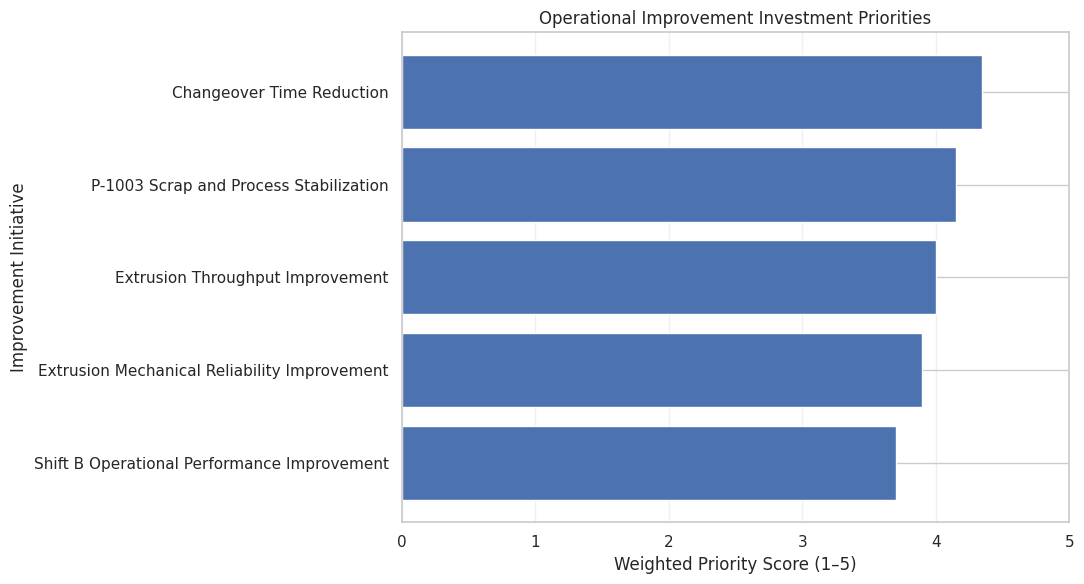

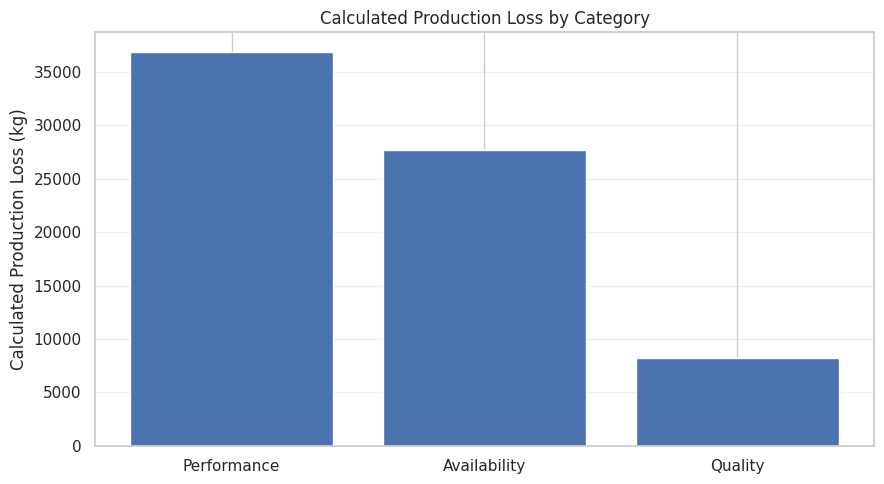

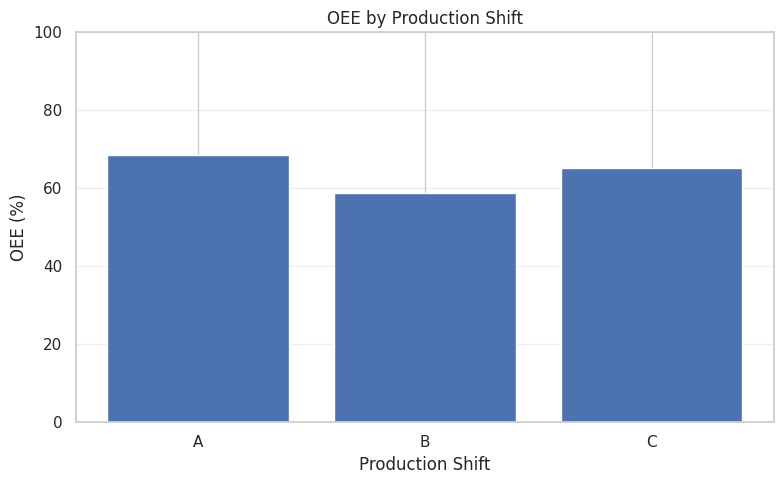

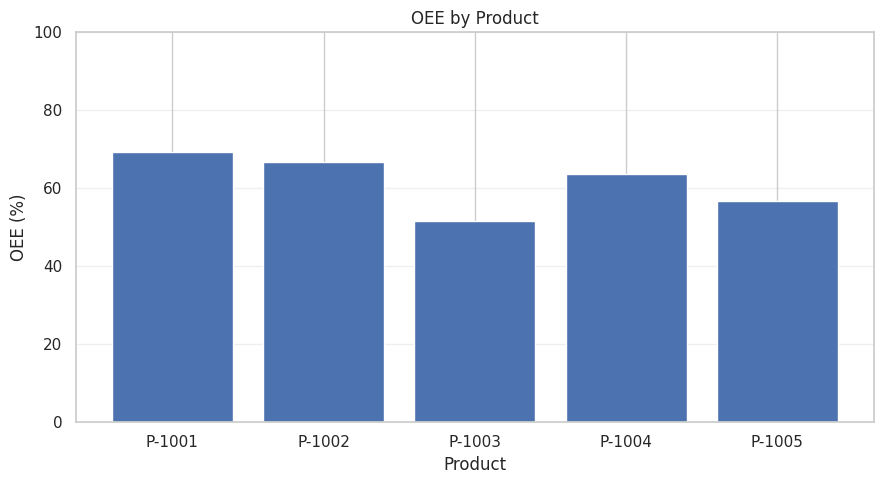

BLOCK 5.4 COMPLETE

TOP INVESTMENT OPPORTUNITIES:


,Rank,Initiative,Weighted_Score,Priority_Category
0,1,Changeover Time Reduction,4.3500,Very High
1,2,P-1003 Scrap and Process Stabilization,4.1500,High
2,3,Extrusion Throughput Improvement,4.0000,High
3,4,Extrusion Mechanical Reliability Improvement,3.9000,High
4,5,Shift B Operational Performance Improvement,3.7000,Moderate



FINANCIAL DATA STILL REQUIRED:


,Required_Input,Purpose,Required_From
0,Contribution margin per kg,Estimate financial value of recovered production,Finance / Operations
1,Material cost per kg,Estimate direct material savings from scrap re...,Finance / Procurement
2,Conversion cost per kg,Estimate production conversion cost associated...,Finance / Operations
3,Maintenance labor and parts cost,Estimate mechanical reliability project cost,Maintenance / Finance
4,Engineering and production project hours,Estimate internal implementation resource requ...,Engineering / Production
5,Capital expenditure estimates,Evaluate equipment modifications or upgrades,Engineering / Finance
6,Available demand and production constraints,Determine whether recovered capacity can gener...,Sales / Planning / Operations



EXECUTIVE SUMMARY:
NORTHSTAR POLYMER MANUFACTURING
OPERATIONAL IMPROVEMENT INVESTMENT ASSESSMENT

PROJECT CONTEXT
This assessment uses a synthetic 90-day extrusion manufacturing dataset.
The findings are illustrative and do not represent actual facility results.

OPERATIONAL PERFORMANCE
Overall OEE: 64.20%
Weighted availability: 86.39%
Performance: 79.01%
Quality: 94.06%

KEY OPERATIONAL FINDINGS
1. Performance losses represented approximately 50.7% of calculated production losses.
2. P-1003 recorded a 15.90% scrap rate.
3. Mechanical downtime totaled approximately 114.2 hours.
4. Changeover event duration totaled approximately 73.85 hours.
5. Shift B recorded the lowest OEE at 58.83%.

TOP-RANKED IMPROVEMENT INITIATIVE
Changeover Time Reduction
Weighted priority score: 4.35 / 5
Recommended action: Authorize an early changeover reduction pilot after validating the applicable standard times.

INVESTMENT CONSIDERATIONS
The weighted priority score is a screening and decision-support tool

,Output_File,Description
0,executive_metrics.csv,Executive operational metrics
1,executive_investment_prioritization.csv,Ranked improvement investment opportunities
2,investment_priority_ranking.png,Investment priority chart
3,executive_loss_contribution.csv,Calculated production loss data
4,executive_loss_contribution.png,Production loss contribution chart
5,executive_shift_oee.csv,OEE by shift data
6,executive_shift_oee.png,Shift OEE chart
7,executive_product_oee.csv,OEE by product data
8,executive_product_oee.png,Product OEE chart
9,executive_roadmap_summary.csv,90-day roadmap summary


In [15]:

# ============================================================
# BLOCK 5.4 — EXECUTIVE INVESTMENT SUMMARY AND VISUALIZATIONS
# Purpose:
# Create management-facing outputs from the investment model.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("integrated_operational_assessment")
OUTPUT_DIR.mkdir(exist_ok=True)

# ------------------------------------------------------------
# 1. Validate required upstream blocks
# ------------------------------------------------------------

required_variables = [
    "prioritization",
    "roadmap",
    "initiative_register"
]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"{variable} is missing. Run Blocks 5.1, 5.2, and 5.3 first."
        )

# ------------------------------------------------------------
# 2. Define measured operational metrics
#
# These values come from the completed analysis of the
# synthetic Northstar Polymer Manufacturing dataset.
# They are not real facility results or external benchmarks.
# ------------------------------------------------------------

executive_metrics = pd.DataFrame([
    {
        "Metric": "Overall OEE",
        "Value": 64.20,
        "Unit": "%",
        "Interpretation": "Mixed-product weighted OEE"
    },
    {
        "Metric": "Availability",
        "Value": 86.39,
        "Unit": "%",
        "Interpretation": "Weighted availability used in OEE calculation"
    },
    {
        "Metric": "Performance",
        "Value": 79.01,
        "Unit": "%",
        "Interpretation": "Production rate relative to illustrative ideal rates"
    },
    {
        "Metric": "Quality",
        "Value": 94.06,
        "Unit": "%",
        "Interpretation": "Good production as a share of total production"
    },
    {
        "Metric": "Mechanical Downtime",
        "Value": 114.2,
        "Unit": "hours",
        "Interpretation": "Recorded mechanical event duration"
    },
    {
        "Metric": "Changeover Downtime",
        "Value": 73.85,
        "Unit": "hours",
        "Interpretation": "Recorded changeover event duration"
    },
    {
        "Metric": "Calculated Performance Loss",
        "Value": 36851.39,
        "Unit": "kg",
        "Interpretation": "Theoretical production loss relative to ideal rate"
    },
    {
        "Metric": "Calculated Availability Loss",
        "Value": 27668.02,
        "Unit": "kg",
        "Interpretation": "Theoretical production loss associated with availability"
    },
    {
        "Metric": "Calculated Quality Loss",
        "Value": 8235.35,
        "Unit": "kg",
        "Interpretation": "Recorded scrap quantity"
    }
])

metrics_file = OUTPUT_DIR / "executive_metrics.csv"
executive_metrics.to_csv(metrics_file, index=False)

# ------------------------------------------------------------
# 3. Create ranked investment summary
# ------------------------------------------------------------

investment_summary = prioritization[
    [
        "Rank",
        "Initiative_ID",
        "Initiative",
        "Weighted_Score",
        "Priority_Category",
        "Recommended_Management_Action",
        "Estimated_Annual_Benefit_USD",
        "Estimated_Implementation_Cost_USD",
        "Financial_Validation_Status"
    ]
].copy()

investment_summary_file = (
    OUTPUT_DIR / "executive_investment_prioritization.csv"
)

investment_summary.to_csv(investment_summary_file, index=False)

# ------------------------------------------------------------
# 4. Create opportunity scoring visualization
# ------------------------------------------------------------

plot_data = prioritization.sort_values(
    "Weighted_Score",
    ascending=True
)

plt.figure(figsize=(11, 6))
plt.barh(
    plot_data["Initiative"],
    plot_data["Weighted_Score"]
)
plt.xlabel("Weighted Priority Score (1–5)")
plt.ylabel("Improvement Initiative")
plt.title("Operational Improvement Investment Priorities")
plt.xlim(0, 5)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

priority_chart = OUTPUT_DIR / "investment_priority_ranking.png"
plt.savefig(priority_chart, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 5. Create operational loss contribution visualization
# ------------------------------------------------------------

loss_data = pd.DataFrame({
    "Loss_Category": [
        "Performance",
        "Availability",
        "Quality"
    ],
    "Loss_kg": [
        36851.39,
        27668.02,
        8235.35
    ]
})

loss_data["Share_Percent"] = (
    loss_data["Loss_kg"] / loss_data["Loss_kg"].sum() * 100
)

loss_file = OUTPUT_DIR / "executive_loss_contribution.csv"
loss_data.to_csv(loss_file, index=False)

plt.figure(figsize=(9, 5))
plt.bar(
    loss_data["Loss_Category"],
    loss_data["Loss_kg"]
)
plt.ylabel("Calculated Production Loss (kg)")
plt.title("Calculated Production Loss by Category")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

loss_chart = OUTPUT_DIR / "executive_loss_contribution.png"
plt.savefig(loss_chart, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 6. Create shift OEE visualization
# ------------------------------------------------------------

shift_oee = pd.DataFrame({
    "Shift": ["A", "B", "C"],
    "OEE_Percent": [68.43, 58.83, 65.29]
})

shift_file = OUTPUT_DIR / "executive_shift_oee.csv"
shift_oee.to_csv(shift_file, index=False)

plt.figure(figsize=(8, 5))
plt.bar(shift_oee["Shift"], shift_oee["OEE_Percent"])
plt.ylabel("OEE (%)")
plt.xlabel("Production Shift")
plt.title("OEE by Production Shift")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

shift_chart = OUTPUT_DIR / "executive_shift_oee.png"
plt.savefig(shift_chart, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 7. Create product OEE visualization
# ------------------------------------------------------------

product_oee = pd.DataFrame({
    "Product": ["P-1001", "P-1002", "P-1003", "P-1004", "P-1005"],
    "OEE_Percent": [69.28, 66.78, 51.72, 63.62, 56.75]
})

product_file = OUTPUT_DIR / "executive_product_oee.csv"
product_oee.to_csv(product_file, index=False)

plt.figure(figsize=(9, 5))
plt.bar(product_oee["Product"], product_oee["OEE_Percent"])
plt.ylabel("OEE (%)")
plt.xlabel("Product")
plt.title("OEE by Product")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

product_chart = OUTPUT_DIR / "executive_product_oee.png"
plt.savefig(product_chart, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------------------
# 8. Create 90-day roadmap summary
# ------------------------------------------------------------

roadmap_summary = (
    roadmap.groupby(
        ["Phase", "Initiative_ID", "Initiative"],
        as_index=False
    )
    .agg(
        Action_Count=("Action", "count"),
        Responsible_Functions=(
            "Responsible_Function",
            lambda x: "; ".join(sorted(set(x)))
        )
    )
)

roadmap_summary_file = OUTPUT_DIR / "executive_roadmap_summary.csv"
roadmap_summary.to_csv(roadmap_summary_file, index=False)

# ------------------------------------------------------------
# 9. Create financial data requirements register
# ------------------------------------------------------------

financial_requirements = pd.DataFrame([
    {
        "Required_Input": "Contribution margin per kg",
        "Purpose": "Estimate financial value of recovered production",
        "Required_From": "Finance / Operations"
    },
    {
        "Required_Input": "Material cost per kg",
        "Purpose": "Estimate direct material savings from scrap reduction",
        "Required_From": "Finance / Procurement"
    },
    {
        "Required_Input": "Conversion cost per kg",
        "Purpose": "Estimate production conversion cost associated with scrap",
        "Required_From": "Finance / Operations"
    },
    {
        "Required_Input": "Maintenance labor and parts cost",
        "Purpose": "Estimate mechanical reliability project cost",
        "Required_From": "Maintenance / Finance"
    },
    {
        "Required_Input": "Engineering and production project hours",
        "Purpose": "Estimate internal implementation resource requirements",
        "Required_From": "Engineering / Production"
    },
    {
        "Required_Input": "Capital expenditure estimates",
        "Purpose": "Evaluate equipment modifications or upgrades",
        "Required_From": "Engineering / Finance"
    },
    {
        "Required_Input": "Available demand and production constraints",
        "Purpose": "Determine whether recovered capacity can generate value",
        "Required_From": "Sales / Planning / Operations"
    }
])

financial_requirements_file = (
    OUTPUT_DIR / "financial_business_case_data_requirements.csv"
)

financial_requirements.to_csv(
    financial_requirements_file,
    index=False
)

# ------------------------------------------------------------
# 10. Generate executive summary text
# ------------------------------------------------------------

top_opportunity = prioritization.iloc[0]

summary_lines = [
    "NORTHSTAR POLYMER MANUFACTURING",
    "OPERATIONAL IMPROVEMENT INVESTMENT ASSESSMENT",
    "",
    "PROJECT CONTEXT",
    "This assessment uses a synthetic 90-day extrusion manufacturing dataset.",
    "The findings are illustrative and do not represent actual facility results.",
    "",
    "OPERATIONAL PERFORMANCE",
    "Overall OEE: 64.20%",
    "Weighted availability: 86.39%",
    "Performance: 79.01%",
    "Quality: 94.06%",
    "",
    "KEY OPERATIONAL FINDINGS",
    "1. Performance losses represented approximately 50.7% of calculated production losses.",
    "2. P-1003 recorded a 15.90% scrap rate.",
    "3. Mechanical downtime totaled approximately 114.2 hours.",
    "4. Changeover event duration totaled approximately 73.85 hours.",
    "5. Shift B recorded the lowest OEE at 58.83%.",
    "",
    "TOP-RANKED IMPROVEMENT INITIATIVE",
    f"{top_opportunity['Initiative']}",
    f"Weighted priority score: {top_opportunity['Weighted_Score']} / 5",
    f"Recommended action: {top_opportunity['Recommended_Management_Action']}",
    "",
    "INVESTMENT CONSIDERATIONS",
    "The weighted priority score is a screening and decision-support tool.",
    "It is not a financial return calculation or proof of recoverable savings.",
    "Actual implementation costs, contribution margins, demand, and resource",
    "requirements must be established before approving major investment.",
    "",
    "RECOMMENDED MANAGEMENT APPROACH",
    "1. Approve bounded improvement pilots with defined deliverables.",
    "2. Establish baseline and post-implementation KPIs.",
    "3. Review pilot results at defined management gates.",
    "4. Develop separate financial business cases for capital requests.",
    "",
    "FINANCIAL VALIDATION",
    "Financial benefits and ROI have not yet been quantified."
]

executive_summary_text = "\n".join(summary_lines)

summary_text_file = OUTPUT_DIR / "executive_investment_summary.txt"

with open(summary_text_file, "w", encoding="utf-8") as f:
    f.write(executive_summary_text)

# ------------------------------------------------------------
# 11. Export a complete output inventory
# ------------------------------------------------------------

output_inventory = pd.DataFrame({
    "Output_File": [
        metrics_file.name,
        investment_summary_file.name,
        priority_chart.name,
        loss_file.name,
        loss_chart.name,
        shift_file.name,
        shift_chart.name,
        product_file.name,
        product_chart.name,
        roadmap_summary_file.name,
        financial_requirements_file.name,
        summary_text_file.name
    ],
    "Description": [
        "Executive operational metrics",
        "Ranked improvement investment opportunities",
        "Investment priority chart",
        "Calculated production loss data",
        "Production loss contribution chart",
        "OEE by shift data",
        "Shift OEE chart",
        "OEE by product data",
        "Product OEE chart",
        "90-day roadmap summary",
        "Financial data needed for business cases",
        "Management-facing executive summary"
    ]
})

inventory_file = OUTPUT_DIR / "block_5_4_output_inventory.csv"
output_inventory.to_csv(inventory_file, index=False)

# ------------------------------------------------------------
# 12. Display final results
# ------------------------------------------------------------

print("BLOCK 5.4 COMPLETE")
print("\nTOP INVESTMENT OPPORTUNITIES:")
display(
    prioritization[
        [
            "Rank",
            "Initiative",
            "Weighted_Score",
            "Priority_Category"
        ]
    ]
)

print("\nFINANCIAL DATA STILL REQUIRED:")
display(financial_requirements)

print("\nEXECUTIVE SUMMARY:")
print(executive_summary_text)

print(f"\nAll outputs saved in: {OUTPUT_DIR.resolve()}")
print("\nGenerated output inventory:")
display(output_inventory)


In [16]:
# ============================================================
# BLOCK 6.0 — PHASE 3: IMPORTING FINANCIAL ASSUMPTIONS
# ============================================================

from pathlib import Path
import os
import re
import pandas as pd
import numpy as np

try:
    from IPython.display import display
except ImportError:
    display = print

# ------------------------------------------------------------
# 1. LOCATE THE WORKBOOK
#
# Set FINANCIAL_WORKBOOK_PATH to an explicit path if the workbook is
# stored somewhere outside the common project/data directories.
# ------------------------------------------------------------

EXPECTED_WORKBOOK_NAME = (
    "manufacturing_financial_business_case_inputs_prefilled.xlsx"
)


def locate_financial_workbook():
    """Find the requested workbook without assuming one fixed working directory."""
    candidates = []

    env_path = os.environ.get("FINANCIAL_WORKBOOK_PATH")
    if env_path:
        candidates.append(Path(env_path).expanduser())

    cwd = Path.cwd()
    direct_paths = [
        Path(EXPECTED_WORKBOOK_NAME),
        Path("work/financial_inputs") / EXPECTED_WORKBOOK_NAME,
        cwd / EXPECTED_WORKBOOK_NAME,
        cwd / "work" / "financial_inputs" / EXPECTED_WORKBOOK_NAME,
        cwd / "financial_inputs" / EXPECTED_WORKBOOK_NAME,
        cwd / "data" / EXPECTED_WORKBOOK_NAME,
        cwd / "datasets" / EXPECTED_WORKBOOK_NAME,
        cwd.parent / "work" / "financial_inputs" / EXPECTED_WORKBOOK_NAME,
        cwd.parent / "financial_inputs" / EXPECTED_WORKBOOK_NAME,
        Path("/datasets") / EXPECTED_WORKBOOK_NAME,
        Path("/datasets/work/financial_inputs") / EXPECTED_WORKBOOK_NAME,
        Path("/datasets/financial_inputs") / EXPECTED_WORKBOOK_NAME,
        Path("/mnt/data") / EXPECTED_WORKBOOK_NAME,
        Path("/content") / EXPECTED_WORKBOOK_NAME,
        Path("/work/financial_inputs") / EXPECTED_WORKBOOK_NAME,
    ]
    candidates.extend(direct_paths)

    seen = set()
    for candidate in candidates:
        try:
            resolved = candidate.resolve()
        except OSError:
            resolved = candidate
        key = str(resolved).casefold()
        if key not in seen:
            seen.add(key)
            if resolved.is_file():
                return resolved

    # Search common project roots for an exact filename, then accept a
    # uniquely named financial/business-case input workbook if it was renamed.
    possible_roots = [
        cwd,
        cwd.parent,
        Path("/datasets"),
        Path("/mnt/data"),
        Path("/content"),
        Path("/work"),
    ]
    roots = []
    for root in possible_roots:
        try:
            root = root.resolve()
        except OSError:
            continue
        if not root.is_dir():
            continue
        # Avoid walking a nested root more than once.
        if any(root == existing or existing in root.parents for existing in roots):
            continue
        roots.append(root)

    excluded_dirs = {
        ".git", ".ipynb_checkpoints", ".venv", "venv", "node_modules",
        "__pycache__", "site-packages", "proc", "sys", "dev"
    }
    exact_matches = []
    renamed_matches = []

    for root in roots:
        root_depth = len(root.parts)

        def ignore_walk_error(_error):
            # Permission errors or transient inaccessible folders should not
            # prevent searching the remaining project directories.
            return None

        for current_dir, dirs, files in os.walk(
            root, topdown=True, onerror=ignore_walk_error
        ):
            current_path = Path(current_dir)
            depth = len(current_path.parts) - root_depth
            dirs[:] = [
                directory for directory in dirs
                if directory.casefold() not in excluded_dirs and depth < 7
            ]

            for filename in files:
                if not filename.lower().endswith(".xlsx"):
                    continue
                workbook = current_path / filename
                if filename.casefold() == EXPECTED_WORKBOOK_NAME.casefold():
                    exact_matches.append(workbook)
                else:
                    normalized_name = re.sub(
                        r"[^a-z0-9]+", "_", Path(filename).stem.lower()
                    )
                    if (
                        "financial" in normalized_name
                        and "input" in normalized_name
                        and (
                            "business" in normalized_name
                            or "assumption" in normalized_name
                        )
                    ):
                        renamed_matches.append(workbook)

    if exact_matches:
        return exact_matches[0].resolve()

    # Only use a renamed workbook when the match is unambiguous.
    unique_renamed_matches = list(dict.fromkeys(renamed_matches))
    if len(unique_renamed_matches) == 1:
        return unique_renamed_matches[0].resolve()

    return None


WORKBOOK_PATH = locate_financial_workbook()

if WORKBOOK_PATH is None:
    # Do not fabricate assumptions. Leave explicit empty dataframes so this
    # notebook cell completes and the missing workbook is clearly reported.
    print("Financial assumptions workbook was not found.")
    print(
        f"Expected filename: {EXPECTED_WORKBOOK_NAME}\n"
        "Upload it to the project, or set the FINANCIAL_WORKBOOK_PATH "
        "environment variable to its full path, then rerun this block."
    )

    financial_sheets = {}
    facility_inputs = pd.DataFrame()
    initiative_inputs = pd.DataFrame(columns=["initiative_id"])
    benefit_assumptions = pd.DataFrame(columns=["initiative_id"])
    scenario_settings = pd.DataFrame()

    working_sheets = {
        "Facility Inputs": facility_inputs,
        "Initiative Inputs": initiative_inputs,
        "Benefit Assumptions": benefit_assumptions,
        "Scenario Settings": scenario_settings,
    }

    financial_import_summary = pd.DataFrame({
        "Worksheet": list(working_sheets.keys()),
        "Rows Imported": [0] * len(working_sheets),
        "Columns Imported": [0] * len(working_sheets),
        "Import Status": ["Not imported — workbook not found"] * len(working_sheets),
    })

else:
    print("Workbook found:")
    print(WORKBOOK_PATH)

    # ------------------------------------------------------------
    # 2. IMPORT WORKSHEETS WITHOUT ASSUMING HEADERS ARE ON ROW 1
    # ------------------------------------------------------------

    try:
        raw_financial_sheets = pd.read_excel(
            WORKBOOK_PATH,
            sheet_name=None,
            header=None,
            engine="openpyxl"
        )
    except Exception as exc:
        raise RuntimeError(
            f"Could not read the financial assumptions workbook at "
            f"{WORKBOOK_PATH}. Confirm it is a valid .xlsx file and that "
            f"openpyxl is installed. Original error: {exc}"
        ) from exc

    def normalize_header(value):
        """Normalize a cell/header for matching and column naming."""
        if pd.isna(value):
            return ""
        return re.sub(
            r"[^a-z0-9]+", "_", str(value).strip().lower()
        ).strip("_")

    def find_header_row(raw_df, required_token=None):
        """Find a worksheet header row, preferring an explicitly required column."""
        if raw_df.empty:
            raise ValueError("Cannot find a header row in an empty worksheet.")

        if required_token:
            for row_index, row in enumerate(
                raw_df.itertuples(index=False, name=None)
            ):
                tokens = [normalize_header(value) for value in row]
                if any(
                    token == required_token
                    or token.startswith(required_token + "_")
                    for token in tokens
                ):
                    return row_index

        header_words = {
            "id", "input", "initiative", "name", "value", "unit",
            "description", "source", "assumption", "scenario", "parameter",
            "category", "cost", "benefit", "rate", "volume", "hours",
            "percent", "percentage", "status", "notes", "owner", "type",
            "low", "base", "high", "enabled", "weight"
        }

        best_index = None
        best_score = None
        for row_index, row in enumerate(
            raw_df.itertuples(index=False, name=None)
        ):
            populated = [
                value for value in row
                if not pd.isna(value) and str(value).strip()
            ]
            if len(populated) < 2:
                continue

            text_values = [value for value in populated if isinstance(value, str)]
            word_hits = sum(
                len(set(normalize_header(value).split("_")) & header_words)
                for value in text_values
            )
            text_ratio = len(text_values) / len(populated)
            score = (word_hits, len(populated), text_ratio, -row_index)

            if best_score is None or score > best_score:
                best_score = score
                best_index = row_index

        return 0 if best_index is None else best_index

    def parse_worksheet(raw_df, sheet_name, required_token=None):
        """Promote the detected worksheet header and standardize its columns."""
        header_index = find_header_row(raw_df, required_token=required_token)
        raw_headers = raw_df.iloc[header_index].tolist()

        headers = []
        for column_index, value in enumerate(raw_headers):
            header = normalize_header(value)
            headers.append(header if header else f"unnamed_{column_index}")

        # Make duplicate/blank labels unique for deterministic downstream use.
        seen = {}
        unique_headers = []
        for header in headers:
            count = seen.get(header, 0)
            seen[header] = count + 1
            unique_headers.append(
                header if count == 0 else f"{header}_{count + 1}"
            )

        dataframe = raw_df.iloc[header_index + 1:].copy()
        dataframe.columns = unique_headers
        dataframe = dataframe.dropna(how="all").reset_index(drop=True)

        if dataframe.empty:
            raise ValueError(
                f"No data rows were found below the detected header in {sheet_name}."
            )
        return dataframe

    required_sheets = [
        "Start Here",
        "Facility Inputs",
        "Initiative Inputs",
        "Benefit Assumptions",
        "Scenario Settings"
    ]

    missing_sheets = [
        sheet for sheet in required_sheets
        if sheet not in raw_financial_sheets
    ]
    if missing_sheets:
        raise ValueError(
            f"Missing required worksheets: {missing_sheets}. "
            f"Worksheets found: {list(raw_financial_sheets)}"
        )

    required_header_tokens = {
        "Initiative Inputs": "initiative_id",
        "Benefit Assumptions": "initiative_id"
    }

    financial_sheets = {
        sheet_name: parse_worksheet(
            raw_df,
            sheet_name,
            required_token=required_header_tokens.get(sheet_name)
        )
        for sheet_name, raw_df in raw_financial_sheets.items()
    }

    print("\nImported worksheets (after locating table headers):")
    for sheet_name, dataframe in financial_sheets.items():
        print(
            f"- {sheet_name}: {dataframe.shape[0]} rows × "
            f"{dataframe.shape[1]} columns"
        )

    # ------------------------------------------------------------
    # 3. ASSIGN WORKSHEETS TO WORKING DATAFRAMES
    # ------------------------------------------------------------

    facility_inputs = financial_sheets["Facility Inputs"].copy()
    initiative_inputs = financial_sheets["Initiative Inputs"].copy()
    benefit_assumptions = financial_sheets["Benefit Assumptions"].copy()
    scenario_settings = financial_sheets["Scenario Settings"].copy()

    # ------------------------------------------------------------
    # 4. STANDARDIZE COLUMN HEADERS
    # ------------------------------------------------------------

    def standardize_columns(df):
        df = df.copy()
        df.columns = (
            pd.Index(df.columns)
            .astype(str)
            .str.strip()
            .str.lower()
            .str.replace(r"[^a-z0-9]+", "_", regex=True)
            .str.strip("_")
        )
        return df

    facility_inputs = standardize_columns(facility_inputs)
    initiative_inputs = standardize_columns(initiative_inputs)
    benefit_assumptions = standardize_columns(benefit_assumptions)
    scenario_settings = standardize_columns(scenario_settings)

    # ------------------------------------------------------------
    # 5. REVIEW WORKSHEET STRUCTURE
    # ------------------------------------------------------------

    print("\nFACILITY INPUTS — COLUMNS")
    print(facility_inputs.columns.tolist())
    print("\nINITIATIVE INPUTS — COLUMNS")
    print(initiative_inputs.columns.tolist())
    print("\nBENEFIT ASSUMPTIONS — COLUMNS")
    print(benefit_assumptions.columns.tolist())
    print("\nSCENARIO SETTINGS — COLUMNS")
    print(scenario_settings.columns.tolist())

    # ------------------------------------------------------------
    # 6. VALIDATE REQUIRED DATA
    # ------------------------------------------------------------

    working_sheets = {
        "Facility Inputs": facility_inputs,
        "Initiative Inputs": initiative_inputs,
        "Benefit Assumptions": benefit_assumptions,
        "Scenario Settings": scenario_settings
    }

    for sheet_name, dataframe in working_sheets.items():
        if dataframe.empty:
            raise ValueError(f"{sheet_name} contains no data.")

    initiative_id_columns = {
        "Initiative Inputs": "initiative_id",
        "Benefit Assumptions": "initiative_id"
    }

    for sheet_name, column_name in initiative_id_columns.items():
        dataframe = working_sheets[sheet_name]
        if column_name not in dataframe.columns:
            raise ValueError(
                f"Expected column '{column_name}' was not found in {sheet_name}. "
                f"Available columns: {dataframe.columns.tolist()}"
            )
        if dataframe[column_name].isna().any():
            raise ValueError(f"Missing initiative IDs detected in {sheet_name}.")
        if dataframe[column_name].astype(str).str.strip().eq("").any():
            raise ValueError(f"Blank initiative IDs detected in {sheet_name}.")

    # ------------------------------------------------------------
    # 7. CHECK INITIATIVE COVERAGE
    # ------------------------------------------------------------

    input_initiatives = set(
        initiative_inputs["initiative_id"].dropna().astype(str).str.strip()
    )
    benefit_initiatives = set(
        benefit_assumptions["initiative_id"].dropna().astype(str).str.strip()
    )

    print("\nINITIATIVE COVERAGE")
    print("Initiatives in cost inputs:", sorted(input_initiatives))
    print("Initiatives in benefit inputs:", sorted(benefit_initiatives))
    print(
        "Initiatives with cost inputs but no benefit assumptions:",
        sorted(input_initiatives - benefit_initiatives)
    )
    print(
        "Initiatives with benefit assumptions but no cost inputs:",
        sorted(benefit_initiatives - input_initiatives)
    )

    # ------------------------------------------------------------
    # 8. CHECK FOR DUPLICATE INITIATIVE RECORDS
    # ------------------------------------------------------------

    for sheet_name in ["Initiative Inputs", "Benefit Assumptions"]:
        dataframe = working_sheets[sheet_name]
        duplicate_count = dataframe["initiative_id"].duplicated().sum()
        print(f"{sheet_name}: {duplicate_count} duplicate initiative IDs")

    # ------------------------------------------------------------
    # 9. DISPLAY IMPORTED ASSUMPTIONS
    # ------------------------------------------------------------

    print("\nFACILITY INPUTS")
    display(facility_inputs)
    print("\nINITIATIVE COST INPUTS")
    display(initiative_inputs)
    print("\nBENEFIT ASSUMPTIONS")
    display(benefit_assumptions)
    print("\nSCENARIO SETTINGS")
    display(scenario_settings)

    # ------------------------------------------------------------
    # 10. CREATE IMPORT SUMMARY
    # ------------------------------------------------------------

    financial_import_summary = pd.DataFrame({
        "Worksheet": list(working_sheets.keys()),
        "Rows Imported": [len(df) for df in working_sheets.values()],
        "Columns Imported": [len(df.columns) for df in working_sheets.values()],
        "Import Status": ["Imported"] * len(working_sheets)
    })

print("\nFINANCIAL ASSUMPTION IMPORT SUMMARY")
display(financial_import_summary)

if WORKBOOK_PATH is None:
    print(
        "\nBlock 6.0 completed in workbook-missing mode. No financial "
        "assumptions were fabricated or imported."
    )
else:
    print("\nBlock 6.0 import completed.")

Workbook found:
/datasets/_deepnote_work/financial_inputs/manufacturing_financial_business_case_inputs_prefilled.xlsx

Imported worksheets (after locating table headers):
- Start Here: 12 rows × 2 columns
- Facility Inputs: 13 rows × 6 columns
- Initiative Inputs: 40 rows × 11 columns
- Benefit Assumptions: 5 rows × 12 columns
- Scenario Settings: 3 rows × 5 columns

FACILITY INPUTS — COLUMNS
['input_id', 'input', 'value', 'unit', 'definition_guidance', 'source_owner_date']

INITIATIVE INPUTS — COLUMNS
['initiative_id', 'initiative', 'cost_category', 'description_basis', 'quantity', 'unit', 'unit_cost_usd', 'one_time_cost_usd', 'annual_recurring_cost_usd', 'timing_year', 'source_owner_date']

BENEFIT ASSUMPTIONS — COLUMNS
['initiative_id', 'initiative', 'benefit_driver', 'baseline_quantity', 'baseline_unit', 'addressable_share', 'expected_improvement_of_addressable_portion', 'annualization_factor', 'annual_benefit_quantity', 'unit', 'key_constraint_validation_needed', 'source_owner_dat

,input_id,input,value,unit,definition_guidance,source_owner_date
0,F01,Material cost,2.5000,USD/kg,Direct material cost for the relevant product(...,NaN
1,F02,Conversion cost,1.2000,USD/kg,Incremental conversion cost per kg. Clarify wh...,NaN
2,F03,Contribution margin,1.8000,USD/kg,Incremental contribution margin on additional ...,NaN
3,F04,Variable labor cost,35,USD/hour,"Incremental labor cost per hour, including bur...",NaN
4,F05,Maintenance labor cost,55,USD/hour,Incremental maintenance labor cost per hour.,NaN
5,F06,Engineering labor cost,75,USD/hour,Incremental engineering labor cost per hour.,NaN
6,F07,Production hours per year,4000,hours/year,Scheduled production hours for the relevant li...,NaN
7,F08,Available demand,100000,kg/year,Additional annual demand that could be served....,NaN
8,F09,Scrap disposition recovery,0,%,Fraction of scrap cost recovered through resal...,NaN
9,F10,Energy cost,0.1200,USD/kWh,Use only if energy consumption changes with th...,NaN



INITIATIVE COST INPUTS


,initiative_id,initiative,cost_category,description_basis,quantity,unit,unit_cost_usd,one_time_cost_usd,annual_recurring_cost_usd,timing_year,source_owner_date
0,I-01,Extrusion Throughput Improvement,Engineering labor,Illustrative engineering analysis and trial pr...,40,hours,75,NaN,NaN,Year 1,NaN
1,I-01,Extrusion Throughput Improvement,Production trial labor,Illustrative operator/production trial support.,24,hours,35,NaN,NaN,Year 1,NaN
2,I-01,Extrusion Throughput Improvement,Maintenance labor,Illustrative maintenance support during trials.,8,hours,55,NaN,NaN,Year 1,NaN
3,I-01,Extrusion Throughput Improvement,Parts / materials,Illustrative trial consumables and minor mater...,1,lot,500,NaN,NaN,Year 1,NaN
4,I-01,Extrusion Throughput Improvement,Equipment / capital,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,I-01,Extrusion Throughput Improvement,Training,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,I-01,Extrusion Throughput Improvement,External services,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,I-01,Extrusion Throughput Improvement,Other,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,I-02,P-1003 Scrap and Process Stabilization,Engineering labor,Illustrative process engineering and trial des...,24,hours,75,NaN,NaN,Year 1,NaN
9,I-02,P-1003 Scrap and Process Stabilization,Production trial labor,Illustrative production support for product tr...,16,hours,35,NaN,NaN,Year 1,NaN



BENEFIT ASSUMPTIONS


,initiative_id,initiative,benefit_driver,baseline_quantity,baseline_unit,addressable_share,expected_improvement_of_addressable_portion,annualization_factor,annual_benefit_quantity,unit,key_constraint_validation_needed,source_owner_date
0,I-01,Extrusion Throughput Improvement,Performance loss / potential recovered production,"36,851.3900",kg per 90-day period,0.2500,0.2000,4,NaN,kg/year,Uses calculated performance loss from syntheti...,Illustrative synthetic case / replace with source
1,I-02,P-1003 Scrap and Process Stabilization,P-1003 scrap quantity,"2,288.1200",kg per 90-day period,0.8000,0.3000,4,NaN,kg/year,Uses P-1003 scrap quantity from synthetic 90-d...,Illustrative synthetic case / replace with source
2,I-03,Extrusion Mechanical Reliability Improvement,Mechanical downtime,114.2000,hours per 90-day period,0.7000,0.3000,4,NaN,hours/year,Uses mechanical downtime hours from synthetic ...,Illustrative synthetic case / replace with source
3,I-04,Changeover Time Reduction,Changeover downtime,73.8500,hours per 90-day period,0.7000,0.2500,4,NaN,hours/year,Uses changeover downtime hours from synthetic ...,Illustrative synthetic case / replace with source
4,I-05,Shift B Operational Performance Improvement,Shift B performance / availability / quality l...,NaN,kg or hours per 90-day period,NaN,NaN,4,NaN,kg or hours/year,Intentionally blank: Shift B losses overlap wi...,Illustrative synthetic case / replace with source



SCENARIO SETTINGS


,scenario,benefit_realization_factor,cost_contingency_factor,description,approved_by_date
0,Conservative,0.5000,1.2500,Lower benefit realization and higher implement...,NaN
1,Expected,0.7500,1.1000,Planning case; replace factors with management...,NaN
2,Optimistic,0.9000,1,Higher benefit realization and lower cost cont...,NaN



FINANCIAL ASSUMPTION IMPORT SUMMARY


,Worksheet,Rows Imported,Columns Imported,Import Status
0,Facility Inputs,13,6,Imported
1,Initiative Inputs,40,11,Imported
2,Benefit Assumptions,5,12,Imported
3,Scenario Settings,3,5,Imported



Block 6.0 import completed.


In [17]:

# ============================================================
# BLOCK 6.1 — PHASE 3: FINANCIAL ASSUMPTION VALIDATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. CREATE OUTPUT DIRECTORY
# ------------------------------------------------------------

FINANCIAL_OUTPUT_DIR = Path("financial_outputs/block_6_1")
FINANCIAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Financial output directory:")
print(FINANCIAL_OUTPUT_DIR.resolve())


# ------------------------------------------------------------
# 2. CONFIRM BLOCK 6.0 DATAFRAMES EXIST
# ------------------------------------------------------------

required_dataframes = {
    "facility_inputs": facility_inputs,
    "initiative_inputs": initiative_inputs,
    "benefit_assumptions": benefit_assumptions,
    "scenario_settings": scenario_settings
}

for name, dataframe in required_dataframes.items():
    if not isinstance(dataframe, pd.DataFrame):
        raise TypeError(f"{name} is not a pandas DataFrame.")

    if dataframe.empty:
        raise ValueError(f"{name} is empty.")

print("\nAll four financial input tables are available.")


# ------------------------------------------------------------
# 3. CREATE VALIDATION LOG
# ------------------------------------------------------------

validation_results = []

def add_validation(category, check, status, details):
    validation_results.append({
        "Category": category,
        "Validation Check": check,
        "Status": status,
        "Details": str(details)
    })


# ------------------------------------------------------------
# 4. CHECK REQUIRED INITIATIVE IDENTIFIERS
# ------------------------------------------------------------

initiative_tables = {
    "Initiative Inputs": initiative_inputs,
    "Benefit Assumptions": benefit_assumptions
}

for table_name, dataframe in initiative_tables.items():

    if "initiative_id" not in dataframe.columns:
        add_validation(
            table_name,
            "Initiative ID column",
            "FAIL",
            "initiative_id column is missing."
        )
        continue

    ids = dataframe["initiative_id"].astype("string").str.strip()

    missing_ids = ids.isna() | ids.eq("")
    duplicate_ids = ids[ids.notna()].duplicated().sum()

    add_validation(
        table_name,
        "Missing initiative IDs",
        "PASS" if missing_ids.sum() == 0 else "FAIL",
        f"{missing_ids.sum()} missing IDs."
    )

    add_validation(
        table_name,
        "Duplicate initiative IDs",
        "PASS" if duplicate_ids == 0 else "WARNING",
        f"{duplicate_ids} duplicate IDs."
    )


# ------------------------------------------------------------
# 5. CHECK INITIATIVE COVERAGE
# ------------------------------------------------------------

cost_ids = set(
    initiative_inputs["initiative_id"]
    .dropna().astype(str).str.strip()
)

benefit_ids = set(
    benefit_assumptions["initiative_id"]
    .dropna().astype(str).str.strip()
)

cost_without_benefit = sorted(cost_ids - benefit_ids)
benefit_without_cost = sorted(benefit_ids - cost_ids)

add_validation(
    "Initiative Coverage",
    "Cost inputs without benefit assumptions",
    "WARNING" if cost_without_benefit else "PASS",
    cost_without_benefit if cost_without_benefit else "None."
)

add_validation(
    "Initiative Coverage",
    "Benefit assumptions without cost inputs",
    "WARNING" if benefit_without_cost else "PASS",
    benefit_without_cost if benefit_without_cost else "None."
)

print("\nInitiatives with cost inputs:", sorted(cost_ids))
print("Initiatives with benefit inputs:", sorted(benefit_ids))


# ------------------------------------------------------------
# 6. CHECK NUMERIC INPUTS AND MISSING VALUES
# ------------------------------------------------------------

financial_tables = {
    "Facility Inputs": facility_inputs,
    "Initiative Inputs": initiative_inputs,
    "Benefit Assumptions": benefit_assumptions,
    "Scenario Settings": scenario_settings
}

missing_value_summary = []

for table_name, dataframe in financial_tables.items():

    for column in dataframe.columns:

        missing_count = dataframe[column].isna().sum()

        missing_value_summary.append({
            "Worksheet": table_name,
            "Column": column,
            "Missing Values": int(missing_count),
            "Total Rows": len(dataframe),
            "Missing Percentage": (
                missing_count / len(dataframe) * 100
                if len(dataframe) else 0
            )
        })

missing_value_summary = pd.DataFrame(missing_value_summary)

print("\nMISSING VALUE REVIEW")
display(
    missing_value_summary[
        missing_value_summary["Missing Values"] > 0
    ]
)


# ------------------------------------------------------------
# 7. CHECK PERCENTAGE AND RATE ASSUMPTIONS
# ------------------------------------------------------------

percentage_keywords = [
    "share",
    "percent",
    "percentage",
    "improvement",
    "reduction",
    "realization",
    "discount",
    "rate"
]

percentage_review = []

for table_name, dataframe in financial_tables.items():

    for column in dataframe.columns:

        column_name = column.lower()

        if any(keyword in column_name for keyword in percentage_keywords):

            numeric_values = pd.to_numeric(
                dataframe[column],
                errors="coerce"
            ).dropna()

            if len(numeric_values) == 0:
                continue

            minimum = numeric_values.min()
            maximum = numeric_values.max()

            # Values above 1 may be expressed as whole percentages
            # (e.g., 25 instead of 0.25). Flag for review, not conversion.
            if minimum < 0:
                status = "FAIL"
                details = "Negative percentage/rate value detected."

            elif maximum > 100:
                status = "FAIL"
                details = "Value exceeds 100; check the input."

            elif maximum > 1:
                status = "REVIEW"
                details = (
                    "Values above 1 detected. Confirm whether these "
                    "are percentages expressed as whole numbers."
                )

            else:
                status = "PASS"
                details = "Values are within the 0–1 range."

            percentage_review.append({
                "Worksheet": table_name,
                "Column": column,
                "Minimum": minimum,
                "Maximum": maximum,
                "Status": status,
                "Details": details
            })

percentage_review = pd.DataFrame(percentage_review)

print("\nPERCENTAGE AND RATE REVIEW")
display(percentage_review)


# ------------------------------------------------------------
# 8. CHECK FOR NEGATIVE NUMERIC ASSUMPTIONS
# ------------------------------------------------------------

negative_value_review = []

for table_name, dataframe in financial_tables.items():

    for column in dataframe.columns:

        numeric_values = pd.to_numeric(
            dataframe[column],
            errors="coerce"
        )

        negative_count = (numeric_values < 0).sum()

        if negative_count > 0:
            negative_value_review.append({
                "Worksheet": table_name,
                "Column": column,
                "Negative Values": int(negative_count)
            })

negative_value_review = pd.DataFrame(negative_value_review)

if negative_value_review.empty:
    print("\nNo negative numeric inputs detected.")
else:
    print("\nNEGATIVE NUMERIC INPUTS — REVIEW REQUIRED")
    display(negative_value_review)


# ------------------------------------------------------------
# 9. REVIEW BENEFIT ASSUMPTIONS BY INITIATIVE
# ------------------------------------------------------------

print("\nBENEFIT ASSUMPTIONS BY INITIATIVE")

benefit_review = benefit_assumptions.copy()

display(benefit_review)

# I-05 is intentionally not assigned a monetized benefit yet.
# Its absence should not automatically be treated as an error.

if "initiative_id" in benefit_review.columns:

    i05_present = (
        benefit_review["initiative_id"]
        .astype(str).str.strip().eq("I-05").any()
    )

    add_validation(
        "Benefit Assumptions",
        "I-05 benefit treatment",
        "PASS",
        (
            "I-05 is represented in the benefit table."
            if i05_present else
            "I-05 has no separate benefit record. This is intentional "
            "until a distinct, non-overlapping benefit is defined."
        )
    )


# ------------------------------------------------------------
# 10. BUILD OVERALL VALIDATION REPORT
# ------------------------------------------------------------

financial_validation_report = pd.DataFrame(validation_results)

print("\nFINANCIAL VALIDATION REPORT")
display(financial_validation_report)

print("\nVALIDATION STATUS COUNTS")
display(
    financial_validation_report["Status"]
    .value_counts()
    .rename_axis("Status")
    .reset_index(name="Count")
)


# ------------------------------------------------------------
# 11. EXPORT VALIDATION OUTPUTS
# ------------------------------------------------------------

financial_validation_report.to_csv(
    FINANCIAL_OUTPUT_DIR / "financial_validation_report.csv",
    index=False
)

missing_value_summary.to_csv(
    FINANCIAL_OUTPUT_DIR / "financial_missing_value_review.csv",
    index=False
)

percentage_review.to_csv(
    FINANCIAL_OUTPUT_DIR / "financial_percentage_review.csv",
    index=False
)

negative_value_review.to_csv(
    FINANCIAL_OUTPUT_DIR / "financial_negative_value_review.csv",
    index=False
)

# Save copies of the imported inputs for traceability.
facility_inputs.to_csv(
    FINANCIAL_OUTPUT_DIR / "facility_inputs_imported.csv",
    index=False
)

initiative_inputs.to_csv(
    FINANCIAL_OUTPUT_DIR / "initiative_inputs_imported.csv",
    index=False
)

benefit_assumptions.to_csv(
    FINANCIAL_OUTPUT_DIR / "benefit_assumptions_imported.csv",
    index=False
)

scenario_settings.to_csv(
    FINANCIAL_OUTPUT_DIR / "scenario_settings_imported.csv",
    index=False
)


# ------------------------------------------------------------
# 12. FINAL STATUS
# ------------------------------------------------------------

print("\nBLOCK 6.1 COMPLETED")
print("Output files saved to:", FINANCIAL_OUTPUT_DIR.resolve())

if (financial_validation_report["Status"] == "FAIL").any():
    print("ACTION REQUIRED: Correct failed validation checks.")
elif (financial_validation_report["Status"] == "WARNING").any():
    print("REVIEW REQUIRED: Investigate warnings before financial modeling.")
else:
    print("No failed or warning checks were identified.")


Financial output directory:
/datasets/_deepnote_work/financial_outputs/block_6_1

All four financial input tables are available.

Initiatives with cost inputs: ['I-01', 'I-02', 'I-03', 'I-04', 'I-05']
Initiatives with benefit inputs: ['I-01', 'I-02', 'I-03', 'I-04', 'I-05']

MISSING VALUE REVIEW


,Worksheet,Column,Missing Values,Total Rows,Missing Percentage
5,Facility Inputs,source_owner_date,13,13,100.0000
9,Initiative Inputs,description_basis,22,40,55.0000
10,Initiative Inputs,quantity,22,40,55.0000
11,Initiative Inputs,unit,22,40,55.0000
12,Initiative Inputs,unit_cost_usd,22,40,55.0000
13,Initiative Inputs,one_time_cost_usd,40,40,100.0000
14,Initiative Inputs,annual_recurring_cost_usd,40,40,100.0000
15,Initiative Inputs,timing_year,22,40,55.0000
16,Initiative Inputs,source_owner_date,40,40,100.0000
20,Benefit Assumptions,baseline_quantity,1,5,20.0000



PERCENTAGE AND RATE REVIEW


,Worksheet,Column,Minimum,Maximum,Status,Details
0,Benefit Assumptions,addressable_share,0.2500,0.8000,PASS,Values are within the 0–1 range.
1,Benefit Assumptions,expected_improvement_of_addressable_portion,0.2000,0.3000,PASS,Values are within the 0–1 range.
2,Scenario Settings,benefit_realization_factor,0.5000,0.9000,PASS,Values are within the 0–1 range.



No negative numeric inputs detected.

BENEFIT ASSUMPTIONS BY INITIATIVE


,initiative_id,initiative,benefit_driver,baseline_quantity,baseline_unit,addressable_share,expected_improvement_of_addressable_portion,annualization_factor,annual_benefit_quantity,unit,key_constraint_validation_needed,source_owner_date
0,I-01,Extrusion Throughput Improvement,Performance loss / potential recovered production,"36,851.3900",kg per 90-day period,0.2500,0.2000,4,NaN,kg/year,Uses calculated performance loss from syntheti...,Illustrative synthetic case / replace with source
1,I-02,P-1003 Scrap and Process Stabilization,P-1003 scrap quantity,"2,288.1200",kg per 90-day period,0.8000,0.3000,4,NaN,kg/year,Uses P-1003 scrap quantity from synthetic 90-d...,Illustrative synthetic case / replace with source
2,I-03,Extrusion Mechanical Reliability Improvement,Mechanical downtime,114.2000,hours per 90-day period,0.7000,0.3000,4,NaN,hours/year,Uses mechanical downtime hours from synthetic ...,Illustrative synthetic case / replace with source
3,I-04,Changeover Time Reduction,Changeover downtime,73.8500,hours per 90-day period,0.7000,0.2500,4,NaN,hours/year,Uses changeover downtime hours from synthetic ...,Illustrative synthetic case / replace with source
4,I-05,Shift B Operational Performance Improvement,Shift B performance / availability / quality l...,NaN,kg or hours per 90-day period,NaN,NaN,4,NaN,kg or hours/year,Intentionally blank: Shift B losses overlap wi...,Illustrative synthetic case / replace with source



FINANCIAL VALIDATION REPORT


,Category,Validation Check,Status,Details
0,Initiative Inputs,Missing initiative IDs,PASS,0 missing IDs.
1,Initiative Inputs,Duplicate initiative IDs,WARNING,35 duplicate IDs.
2,Benefit Assumptions,Missing initiative IDs,PASS,0 missing IDs.
3,Benefit Assumptions,Duplicate initiative IDs,PASS,0 duplicate IDs.
4,Initiative Coverage,Cost inputs without benefit assumptions,PASS,None.
5,Initiative Coverage,Benefit assumptions without cost inputs,PASS,None.
6,Benefit Assumptions,I-05 benefit treatment,PASS,I-05 is represented in the benefit table.



VALIDATION STATUS COUNTS


,Status,Count
0,PASS,6
1,WARNING,1



BLOCK 6.1 COMPLETED
Output files saved to: /datasets/_deepnote_work/financial_outputs/block_6_1
REVIEW REQUIRED: Investigate warnings before financial modeling.


In [18]:

# ============================================================
# BLOCK 6.2 — PHASE 3: INITIATIVE COST AND BENEFIT QUANTITIES
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = Path("financial_outputs/block_6_2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. PREPARE INITIATIVE COST INPUTS
# ------------------------------------------------------------

cost_data = initiative_inputs.copy()

# Convert numeric input columns safely.
for column in ["quantity", "unit_cost_usd"]:
    cost_data[column] = pd.to_numeric(
        cost_data[column],
        errors="coerce"
    )

# A cost row is populated when both quantity and unit cost exist.
cost_data["cost_input_complete"] = (
    cost_data["quantity"].notna()
    & cost_data["unit_cost_usd"].notna()
)

# Calculate one-time cost from the source inputs.
cost_data["calculated_one_time_cost_usd"] = np.where(
    cost_data["cost_input_complete"],
    cost_data["quantity"] * cost_data["unit_cost_usd"],
    np.nan
)

# Preserve incomplete rows for auditability.
cost_data["cost_input_status"] = np.where(
    cost_data["cost_input_complete"],
    "Calculated",
    "No cost input supplied"
)

cost_detail = cost_data[
    [
        "initiative_id",
        "initiative",
        "cost_category",
        "quantity",
        "unit",
        "unit_cost_usd",
        "calculated_one_time_cost_usd",
        "cost_input_status"
    ]
].copy()

print("INITIATIVE COST DETAIL")
display(cost_detail)


# ------------------------------------------------------------
# 3. SUM ONE-TIME COSTS BY INITIATIVE
# ------------------------------------------------------------

cost_summary = (
    cost_data[cost_data["cost_input_complete"]]
    .groupby(["initiative_id", "initiative"], as_index=False)
    ["calculated_one_time_cost_usd"]
    .sum()
    .rename(columns={
        "calculated_one_time_cost_usd": "calculated_one_time_cost_usd"
    })
)

# Count populated cost categories.
cost_counts = (
    cost_data.groupby("initiative_id")["cost_input_complete"]
    .sum()
    .rename("populated_cost_categories")
    .reset_index()
)

cost_summary = cost_summary.merge(
    cost_counts,
    on="initiative_id",
    how="left"
)

# Recurring cost inputs are not populated in the source workbook.
# Do not interpret missing values as confirmed zero recurring cost.
cost_summary["annual_recurring_cost_status"] = (
    "Not supplied — requires confirmation"
)

print("\nONE-TIME COST SUMMARY")
display(cost_summary)


# ------------------------------------------------------------
# 4. CALCULATE ANNUAL BENEFIT QUANTITIES
# ------------------------------------------------------------

benefit_data = benefit_assumptions.copy()

numeric_benefit_columns = [
    "baseline_quantity",
    "addressable_share",
    "expected_improvement_of_addressable_portion",
    "annualization_factor"
]

for column in numeric_benefit_columns:
    benefit_data[column] = pd.to_numeric(
        benefit_data[column],
        errors="coerce"
    )

# Calculate only where all required assumptions are present.
benefit_data["benefit_inputs_complete"] = (
    benefit_data[numeric_benefit_columns].notna().all(axis=1)
)

benefit_data["calculated_annual_benefit_quantity"] = np.where(
    benefit_data["benefit_inputs_complete"],
    (
        benefit_data["baseline_quantity"]
        * benefit_data["addressable_share"]
        * benefit_data["expected_improvement_of_addressable_portion"]
        * benefit_data["annualization_factor"]
    ),
    np.nan
)

benefit_data["benefit_calculation_status"] = np.where(
    benefit_data["benefit_inputs_complete"],
    "Calculated — illustrative assumption",
    "Not calculated — missing or intentionally unassigned inputs"
)

benefit_quantity_summary = benefit_data[
    [
        "initiative_id",
        "initiative",
        "benefit_driver",
        "baseline_quantity",
        "baseline_unit",
        "addressable_share",
        "expected_improvement_of_addressable_portion",
        "annualization_factor",
        "calculated_annual_benefit_quantity",
        "unit",
        "benefit_calculation_status"
    ]
].copy()

print("\nANNUAL BENEFIT QUANTITY SUMMARY")
display(benefit_quantity_summary)


# ------------------------------------------------------------
# 5. RECONCILE COST AND BENEFIT INITIATIVES
# ------------------------------------------------------------

initiative_financial_summary = cost_summary.merge(
    benefit_quantity_summary[
        [
            "initiative_id",
            "calculated_annual_benefit_quantity",
            "unit",
            "benefit_calculation_status"
        ]
    ],
    on="initiative_id",
    how="outer"
)

print("\nCOMBINED INITIATIVE FINANCIAL INPUT SUMMARY")
display(initiative_financial_summary)


# ------------------------------------------------------------
# 6. CREATE CALCULATION CHECKS
# ------------------------------------------------------------

calculation_checks = []

calculation_checks.append({
    "Check": "Cost detail rows with complete inputs",
    "Result": int(cost_data["cost_input_complete"].sum()),
    "Status": "PASS"
})

calculation_checks.append({
    "Check": "Cost detail rows without complete inputs",
    "Result": int((~cost_data["cost_input_complete"]).sum()),
    "Status": "REVIEW — unused or incomplete categories"
})

calculation_checks.append({
    "Check": "Benefit initiatives with calculated annual quantities",
    "Result": int(benefit_data["benefit_inputs_complete"].sum()),
    "Status": "PASS"
})

calculation_checks.append({
    "Check": "Benefit initiatives without calculated quantities",
    "Result": int((~benefit_data["benefit_inputs_complete"]).sum()),
    "Status": "REVIEW — I-05 intentionally unassigned"
})

calculation_checks.append({
    "Check": "Initiative IDs with multiple cost categories",
    "Result": int(cost_data["initiative_id"].nunique()),
    "Status": "Expected — categories are not duplicate initiatives"
})

calculation_checks = pd.DataFrame(calculation_checks)

print("\nCALCULATION CHECKS")
display(calculation_checks)


# ------------------------------------------------------------
# 7. EXPORT RESULTS
# ------------------------------------------------------------

cost_detail.to_csv(
    OUTPUT_DIR / "initiative_cost_detail_calculated.csv",
    index=False
)

cost_summary.to_csv(
    OUTPUT_DIR / "initiative_cost_summary.csv",
    index=False
)

benefit_quantity_summary.to_csv(
    OUTPUT_DIR / "annual_benefit_quantity_summary.csv",
    index=False
)

initiative_financial_summary.to_csv(
    OUTPUT_DIR / "initiative_financial_input_summary.csv",
    index=False
)

calculation_checks.to_csv(
    OUTPUT_DIR / "financial_calculation_checks.csv",
    index=False
)


# ------------------------------------------------------------
# 8. FINAL STATUS
# ------------------------------------------------------------

print("\nBLOCK 6.2 COMPLETED")
print("Output directory:", OUTPUT_DIR.resolve())

print(
    "\nTotal illustrative one-time initiative cost: $",
    f"{cost_summary['calculated_one_time_cost_usd'].sum():,.2f}"
)

print(
    "Annual recurring costs remain unconfirmed."
)


INITIATIVE COST DETAIL


,initiative_id,initiative,cost_category,quantity,unit,unit_cost_usd,calculated_one_time_cost_usd,cost_input_status
0,I-01,Extrusion Throughput Improvement,Engineering labor,40.0000,hours,75.0000,"3,000.0000",Calculated
1,I-01,Extrusion Throughput Improvement,Production trial labor,24.0000,hours,35.0000,840.0000,Calculated
2,I-01,Extrusion Throughput Improvement,Maintenance labor,8.0000,hours,55.0000,440.0000,Calculated
3,I-01,Extrusion Throughput Improvement,Parts / materials,1.0000,lot,500.0000,500.0000,Calculated
4,I-01,Extrusion Throughput Improvement,Equipment / capital,NaN,NaN,NaN,NaN,No cost input supplied
5,I-01,Extrusion Throughput Improvement,Training,NaN,NaN,NaN,NaN,No cost input supplied
6,I-01,Extrusion Throughput Improvement,External services,NaN,NaN,NaN,NaN,No cost input supplied
7,I-01,Extrusion Throughput Improvement,Other,NaN,NaN,NaN,NaN,No cost input supplied
8,I-02,P-1003 Scrap and Process Stabilization,Engineering labor,24.0000,hours,75.0000,"1,800.0000",Calculated
9,I-02,P-1003 Scrap and Process Stabilization,Production trial labor,16.0000,hours,35.0000,560.0000,Calculated



ONE-TIME COST SUMMARY


,initiative_id,initiative,calculated_one_time_cost_usd,populated_cost_categories,annual_recurring_cost_status
0,I-01,Extrusion Throughput Improvement,"4,780.0000",4,Not supplied — requires confirmation
1,I-02,P-1003 Scrap and Process Stabilization,"3,290.0000",5,Not supplied — requires confirmation
2,I-03,Extrusion Mechanical Reliability Improvement,"6,180.0000",4,Not supplied — requires confirmation
3,I-04,Changeover Time Reduction,"2,040.0000",3,Not supplied — requires confirmation
4,I-05,Shift B Operational Performance Improvement,"2,040.0000",2,Not supplied — requires confirmation



ANNUAL BENEFIT QUANTITY SUMMARY


,initiative_id,initiative,benefit_driver,baseline_quantity,baseline_unit,addressable_share,expected_improvement_of_addressable_portion,annualization_factor,calculated_annual_benefit_quantity,unit,benefit_calculation_status
0,I-01,Extrusion Throughput Improvement,Performance loss / potential recovered production,"36,851.3900",kg per 90-day period,0.2500,0.2000,4,"7,370.2780",kg/year,Calculated — illustrative assumption
1,I-02,P-1003 Scrap and Process Stabilization,P-1003 scrap quantity,"2,288.1200",kg per 90-day period,0.8000,0.3000,4,"2,196.5952",kg/year,Calculated — illustrative assumption
2,I-03,Extrusion Mechanical Reliability Improvement,Mechanical downtime,114.2000,hours per 90-day period,0.7000,0.3000,4,95.9280,hours/year,Calculated — illustrative assumption
3,I-04,Changeover Time Reduction,Changeover downtime,73.8500,hours per 90-day period,0.7000,0.2500,4,51.6950,hours/year,Calculated — illustrative assumption
4,I-05,Shift B Operational Performance Improvement,Shift B performance / availability / quality l...,NaN,kg or hours per 90-day period,NaN,NaN,4,NaN,kg or hours/year,Not calculated — missing or intentionally unas...



COMBINED INITIATIVE FINANCIAL INPUT SUMMARY


,initiative_id,initiative,calculated_one_time_cost_usd,populated_cost_categories,annual_recurring_cost_status,calculated_annual_benefit_quantity,unit,benefit_calculation_status
0,I-01,Extrusion Throughput Improvement,"4,780.0000",4,Not supplied — requires confirmation,"7,370.2780",kg/year,Calculated — illustrative assumption
1,I-02,P-1003 Scrap and Process Stabilization,"3,290.0000",5,Not supplied — requires confirmation,"2,196.5952",kg/year,Calculated — illustrative assumption
2,I-03,Extrusion Mechanical Reliability Improvement,"6,180.0000",4,Not supplied — requires confirmation,95.9280,hours/year,Calculated — illustrative assumption
3,I-04,Changeover Time Reduction,"2,040.0000",3,Not supplied — requires confirmation,51.6950,hours/year,Calculated — illustrative assumption
4,I-05,Shift B Operational Performance Improvement,"2,040.0000",2,Not supplied — requires confirmation,NaN,kg or hours/year,Not calculated — missing or intentionally unas...



CALCULATION CHECKS


,Check,Result,Status
0,Cost detail rows with complete inputs,18,PASS
1,Cost detail rows without complete inputs,22,REVIEW — unused or incomplete categories
2,Benefit initiatives with calculated annual qua...,4,PASS
3,Benefit initiatives without calculated quantities,1,REVIEW — I-05 intentionally unassigned
4,Initiative IDs with multiple cost categories,5,Expected — categories are not duplicate initia...



BLOCK 6.2 COMPLETED
Output directory: /datasets/_deepnote_work/financial_outputs/block_6_2

Total illustrative one-time initiative cost: $ 18,330.00
Annual recurring costs remain unconfirmed.


In [19]:

# ============================================================
# BLOCK 6.3 — PHASE 3: QUICK OUTPUT VERIFICATION
# ============================================================

print("ONE-TIME COSTS")
display(cost_summary[
    ["initiative_id", "calculated_one_time_cost_usd"]
])

print("\nANNUAL BENEFIT QUANTITIES")
display(benefit_quantity_summary[
    ["initiative_id", "calculated_annual_benefit_quantity",
     "unit", "benefit_calculation_status"]
])

print("\nTOTAL ONE-TIME COST")
print(
    f"${cost_summary['calculated_one_time_cost_usd'].sum():,.2f}"
)


ONE-TIME COSTS


,initiative_id,calculated_one_time_cost_usd
0,I-01,"4,780.0000"
1,I-02,"3,290.0000"
2,I-03,"6,180.0000"
3,I-04,"2,040.0000"
4,I-05,"2,040.0000"



ANNUAL BENEFIT QUANTITIES


,initiative_id,calculated_annual_benefit_quantity,unit,benefit_calculation_status
0,I-01,"7,370.2780",kg/year,Calculated — illustrative assumption
1,I-02,"2,196.5952",kg/year,Calculated — illustrative assumption
2,I-03,95.9280,hours/year,Calculated — illustrative assumption
3,I-04,51.6950,hours/year,Calculated — illustrative assumption
4,I-05,NaN,kg or hours/year,Not calculated — missing or intentionally unas...



TOTAL ONE-TIME COST
$18,330.00


In [20]:

# ============================================================
# BLOCK 6.4 — PHASE 3: FINANCIAL VALUE CALCULATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. CREATE OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = Path("financial_outputs/block_6_4")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. RETRIEVE FACILITY ASSUMPTIONS
# ------------------------------------------------------------

# Facility inputs are stored as key-value records.
facility_value_map = dict(
    zip(
        facility_inputs["input"].astype(str).str.strip(),
        facility_inputs["value"]
    )
)

def get_facility_value(input_name):
    if input_name not in facility_value_map:
        raise KeyError(
            f"Facility assumption not found: {input_name}"
        )

    value = facility_value_map[input_name]

    if pd.isna(value):
        raise ValueError(
            f"Facility assumption is blank: {input_name}"
        )

    return float(value)


material_cost_per_kg = get_facility_value("Material cost")
contribution_margin_per_kg = get_facility_value("Contribution margin")
available_demand_kg = get_facility_value("Available demand")
scrap_disposition_recovery = get_facility_value(
    "Scrap disposition recovery"
)

print("FACILITY FINANCIAL ASSUMPTIONS")
print(f"Material cost: ${material_cost_per_kg:,.2f}/kg")
print(
    f"Contribution margin: "
    f"${contribution_margin_per_kg:,.2f}/kg"
)
print(f"Available demand: {available_demand_kg:,.0f} kg/year")
print(
    f"Scrap disposition recovery: "
    f"{scrap_disposition_recovery:.1%}"
)


# ------------------------------------------------------------
# 3. PREPARE INITIATIVE COSTS
# ------------------------------------------------------------

costs = cost_summary[
    [
        "initiative_id",
        "initiative",
        "calculated_one_time_cost_usd"
    ]
].copy()

costs = costs.rename(columns={
    "calculated_one_time_cost_usd": "base_one_time_cost_usd"
})

# Recurring costs are not populated in the source workbook.
# Keep them unknown rather than assuming they are zero.
costs["annual_recurring_cost_usd"] = np.nan

print("\nBASE INITIATIVE COSTS")
display(costs)


# ------------------------------------------------------------
# 4. PREPARE ANNUAL BENEFIT QUANTITIES
# ------------------------------------------------------------

benefits = benefit_quantity_summary[
    [
        "initiative_id",
        "initiative",
        "calculated_annual_benefit_quantity",
        "unit",
        "benefit_calculation_status"
    ]
].copy()

benefits = benefits.rename(columns={
    "calculated_annual_benefit_quantity":
        "annual_benefit_quantity"
})

# Merge the cost and benefit information.
initiative_financial_base = costs.merge(
    benefits,
    on="initiative_id",
    how="outer",
    suffixes=("_cost", "_benefit")
)

initiative_financial_base["initiative"] = (
    initiative_financial_base["initiative_cost"]
    .combine_first(initiative_financial_base["initiative_benefit"])
)

initiative_financial_base = initiative_financial_base.drop(
    columns=["initiative_cost", "initiative_benefit"]
)

print("\nINITIATIVE FINANCIAL BASELINE")
display(initiative_financial_base)


# ------------------------------------------------------------
# 5. CALCULATE BASE ANNUAL FINANCIAL VALUE
# ------------------------------------------------------------

def calculate_base_value(row):

    initiative_id = row["initiative_id"]
    quantity = row["annual_benefit_quantity"]
    unit = str(row["unit"]).strip()

    result = {
        "initiative_id": initiative_id,
        "annual_benefit_quantity": quantity,
        "benefit_unit": unit,
        "monetized_annual_benefit_usd": np.nan,
        "financial_treatment": "Not monetized",
        "calculation_notes": ""
    }

    if pd.isna(quantity):
        result["calculation_notes"] = (
            "No distinct annual benefit quantity supplied."
        )
        return pd.Series(result)

    # I-01: Recovered production capacity.
    # Apply the available-demand cap before calculating contribution.
    if initiative_id == "I-01":

        saleable_kg = min(quantity, available_demand_kg)

        result["monetized_annual_benefit_usd"] = (
            saleable_kg * contribution_margin_per_kg
        )

        result["financial_treatment"] = (
            "Potential incremental contribution"
        )

        result["calculation_notes"] = (
            f"{saleable_kg:,.2f} kg capped by available demand "
            f"× ${contribution_margin_per_kg:,.2f}/kg contribution margin."
        )

    # I-02: Scrap reduction.
    # Apply the material cost net of any scrap disposition recovery.
    elif initiative_id == "I-02":

        avoided_material_cost = (
            quantity
            * material_cost_per_kg
            * (1 - scrap_disposition_recovery)
        )

        result["monetized_annual_benefit_usd"] = (
            avoided_material_cost
        )

        result["financial_treatment"] = (
            "Potential avoided material cost"
        )

        result["calculation_notes"] = (
            f"{quantity:,.2f} kg reduced scrap × "
            f"${material_cost_per_kg:,.2f}/kg material cost × "
            f"{1 - scrap_disposition_recovery:.1%} unrecovered portion."
        )

    # I-03 and I-04: Hours are quantified but not monetized.
    elif initiative_id in ["I-03", "I-04"]:

        result["financial_treatment"] = (
            "Recovered capacity — not monetized"
        )

        result["calculation_notes"] = (
            "Recovered hours require validation of usable capacity, "
            "overlap, and demonstrable financial benefit."
        )

    # I-05: No distinct benefit baseline.
    elif initiative_id == "I-05":

        result["financial_treatment"] = (
            "Not monetized — overlapping benefit categories"
        )

        result["calculation_notes"] = (
            "Requires a distinct, non-overlapping benefit measure."
        )

    return pd.Series(result)


base_value_calculations = (
    initiative_financial_base.apply(
        calculate_base_value,
        axis=1
    )
)

initiative_financial_base = pd.concat(
    [
        initiative_financial_base.reset_index(drop=True),
        base_value_calculations.drop(
            columns=[
                "initiative_id",
                "annual_benefit_quantity",
                "benefit_unit"
            ]
        ).reset_index(drop=True)
    ],
    axis=1
)

print("\nBASE ANNUAL FINANCIAL VALUE")
display(initiative_financial_base)


# ------------------------------------------------------------
# 6. IMPORT SCENARIO ASSUMPTIONS
# ------------------------------------------------------------

scenario_data = scenario_settings[
    [
        "scenario",
        "benefit_realization_factor",
        "cost_contingency_factor"
    ]
].copy()

scenario_data["benefit_realization_factor"] = pd.to_numeric(
    scenario_data["benefit_realization_factor"],
    errors="coerce"
)

scenario_data["cost_contingency_factor"] = pd.to_numeric(
    scenario_data["cost_contingency_factor"],
    errors="coerce"
)

if scenario_data.isna().any().any():
    raise ValueError(
        "Scenario settings contain missing or invalid numeric factors."
    )

print("\nSCENARIO ASSUMPTIONS")
display(scenario_data)


# ------------------------------------------------------------
# 7. BUILD SCENARIO FINANCIAL MODEL
# ------------------------------------------------------------

scenario_results = []

for _, scenario in scenario_data.iterrows():

    scenario_name = scenario["scenario"]
    benefit_factor = scenario["benefit_realization_factor"]
    cost_factor = scenario["cost_contingency_factor"]

    for _, initiative in initiative_financial_base.iterrows():

        base_benefit = initiative[
            "monetized_annual_benefit_usd"
        ]

        base_cost = initiative[
            "base_one_time_cost_usd"
        ]

        # Apply benefit realization only to monetized benefits.
        if pd.notna(base_benefit):
            scenario_benefit = base_benefit * benefit_factor
        else:
            scenario_benefit = np.nan

        # Apply cost contingency to one-time implementation cost.
        if pd.notna(base_cost):
            scenario_cost = base_cost * cost_factor
        else:
            scenario_cost = np.nan

        # Simple payback is provisional:
        # it excludes recurring costs and assumes the annual benefit
        # is achieved and sustained.
        if (
            pd.notna(scenario_benefit)
            and scenario_benefit > 0
            and pd.notna(scenario_cost)
        ):
            simple_payback_years = (
                scenario_cost / scenario_benefit
            )
        else:
            simple_payback_years = np.nan

        scenario_results.append({
            "scenario": scenario_name,
            "initiative_id": initiative["initiative_id"],
            "initiative": initiative["initiative"],
            "benefit_realization_factor": benefit_factor,
            "cost_contingency_factor": cost_factor,
            "base_annual_benefit_usd": base_benefit,
            "scenario_annual_benefit_usd": scenario_benefit,
            "base_one_time_cost_usd": base_cost,
            "scenario_one_time_cost_usd": scenario_cost,
            "annual_recurring_cost_usd": np.nan,
            "simple_payback_years_before_recurring_cost":
                simple_payback_years,
            "financial_treatment": initiative[
                "financial_treatment"
            ]
        })

scenario_financial_model = pd.DataFrame(scenario_results)

print("\nSCENARIO FINANCIAL MODEL")
display(scenario_financial_model)


# ------------------------------------------------------------
# 8. SUMMARIZE SCENARIOS
# ------------------------------------------------------------

scenario_summary = (
    scenario_financial_model
    .groupby("scenario", as_index=False)
    .agg(
        total_scenario_annual_benefit_usd=(
            "scenario_annual_benefit_usd", "sum"
        ),
        total_scenario_one_time_cost_usd=(
            "scenario_one_time_cost_usd", "sum"
        )
    )
)

scenario_summary["annual_benefit_status"] = (
    "Partial — only monetized initiatives included"
)

scenario_summary["recurring_cost_status"] = (
    "Not included — recurring costs require confirmation"
)

print("\nSCENARIO SUMMARY")
display(scenario_summary)


# ------------------------------------------------------------
# 9. EXPORT FINANCIAL MODEL OUTPUTS
# ------------------------------------------------------------

initiative_financial_base.to_csv(
    OUTPUT_DIR / "initiative_base_financial_value.csv",
    index=False
)

scenario_financial_model.to_csv(
    OUTPUT_DIR / "initiative_scenario_financial_model.csv",
    index=False
)

scenario_summary.to_csv(
    OUTPUT_DIR / "scenario_financial_summary.csv",
    index=False
)

scenario_data.to_csv(
    OUTPUT_DIR / "scenario_assumptions_used.csv",
    index=False
)


# ------------------------------------------------------------
# 10. FINAL OUTPUT
# ------------------------------------------------------------

print("\nBLOCK 6.4 COMPLETED")
print("Output directory:", OUTPUT_DIR.resolve())

print("\nAnnual financial benefit before scenario adjustments:")
print(
    f"${initiative_financial_base['monetized_annual_benefit_usd'].sum():,.2f}"
)

print("\nScenario summary:")
display(scenario_summary)

print(
    "\nIMPORTANT: These are illustrative potential benefits. "
    "They are not validated cash savings or realized financial returns."
)


FACILITY FINANCIAL ASSUMPTIONS
Material cost: $2.50/kg
Contribution margin: $1.80/kg
Available demand: 100,000 kg/year
Scrap disposition recovery: 0.0%

BASE INITIATIVE COSTS


,initiative_id,initiative,base_one_time_cost_usd,annual_recurring_cost_usd
0,I-01,Extrusion Throughput Improvement,"4,780.0000",NaN
1,I-02,P-1003 Scrap and Process Stabilization,"3,290.0000",NaN
2,I-03,Extrusion Mechanical Reliability Improvement,"6,180.0000",NaN
3,I-04,Changeover Time Reduction,"2,040.0000",NaN
4,I-05,Shift B Operational Performance Improvement,"2,040.0000",NaN



INITIATIVE FINANCIAL BASELINE


,initiative_id,base_one_time_cost_usd,annual_recurring_cost_usd,annual_benefit_quantity,unit,benefit_calculation_status,initiative
0,I-01,"4,780.0000",NaN,"7,370.2780",kg/year,Calculated — illustrative assumption,Extrusion Throughput Improvement
1,I-02,"3,290.0000",NaN,"2,196.5952",kg/year,Calculated — illustrative assumption,P-1003 Scrap and Process Stabilization
2,I-03,"6,180.0000",NaN,95.9280,hours/year,Calculated — illustrative assumption,Extrusion Mechanical Reliability Improvement
3,I-04,"2,040.0000",NaN,51.6950,hours/year,Calculated — illustrative assumption,Changeover Time Reduction
4,I-05,"2,040.0000",NaN,NaN,kg or hours/year,Not calculated — missing or intentionally unas...,Shift B Operational Performance Improvement



BASE ANNUAL FINANCIAL VALUE


,initiative_id,base_one_time_cost_usd,annual_recurring_cost_usd,annual_benefit_quantity,unit,benefit_calculation_status,initiative,monetized_annual_benefit_usd,financial_treatment,calculation_notes
0,I-01,"4,780.0000",NaN,"7,370.2780",kg/year,Calculated — illustrative assumption,Extrusion Throughput Improvement,"13,266.5004",Potential incremental contribution,"7,370.28 kg capped by available demand × $1.80..."
1,I-02,"3,290.0000",NaN,"2,196.5952",kg/year,Calculated — illustrative assumption,P-1003 Scrap and Process Stabilization,"5,491.4880",Potential avoided material cost,"2,196.60 kg reduced scrap × $2.50/kg material ..."
2,I-03,"6,180.0000",NaN,95.9280,hours/year,Calculated — illustrative assumption,Extrusion Mechanical Reliability Improvement,NaN,Recovered capacity — not monetized,Recovered hours require validation of usable c...
3,I-04,"2,040.0000",NaN,51.6950,hours/year,Calculated — illustrative assumption,Changeover Time Reduction,NaN,Recovered capacity — not monetized,Recovered hours require validation of usable c...
4,I-05,"2,040.0000",NaN,NaN,kg or hours/year,Not calculated — missing or intentionally unas...,Shift B Operational Performance Improvement,NaN,Not monetized,No distinct annual benefit quantity supplied.


... (5 outputs left out)

,scenario,total_scenario_annual_benefit_usd,total_scenario_one_time_cost_usd,annual_benefit_status,recurring_cost_status
0,Conservative,"9,378.9942","22,912.5000",Partial — only monetized initiatives included,Not included — recurring costs require confirm...
1,Expected,"14,068.4913","20,163.0000",Partial — only monetized initiatives included,Not included — recurring costs require confirm...
2,Optimistic,"16,882.1896","18,330.0000",Partial — only monetized initiatives included,Not included — recurring costs require confirm...



BLOCK 6.4 COMPLETED
Output directory: /datasets/_deepnote_work/financial_outputs/block_6_4

Annual financial benefit before scenario adjustments:
$18,757.99

Scenario summary:


,scenario,total_scenario_annual_benefit_usd,total_scenario_one_time_cost_usd,annual_benefit_status,recurring_cost_status
0,Conservative,"9,378.9942","22,912.5000",Partial — only monetized initiatives included,Not included — recurring costs require confirm...
1,Expected,"14,068.4913","20,163.0000",Partial — only monetized initiatives included,Not included — recurring costs require confirm...
2,Optimistic,"16,882.1896","18,330.0000",Partial — only monetized initiatives included,Not included — recurring costs require confirm...



IMPORTANT: These are illustrative potential benefits. They are not validated cash savings or realized financial returns.


In [21]:

# ============================================================
# BLOCK 6.5 — PHASE 3: FINANCIAL SENSITIVITY ANALYSIS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. CREATE OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = Path("financial_outputs/block_6_5")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR.resolve())


# ------------------------------------------------------------
# 2. VALIDATE BLOCK 6.4 INPUTS
# ------------------------------------------------------------

required_columns = [
    "initiative_id",
    "initiative",
    "base_one_time_cost_usd",
    "annual_recurring_cost_usd",
    "monetized_annual_benefit_usd",
    "financial_treatment"
]

missing_columns = [
    column for column in required_columns
    if column not in initiative_financial_base.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required Block 6.4 columns: {missing_columns}"
    )

if "scenario" not in scenario_financial_model.columns:
    raise ValueError("Scenario financial model is missing scenario column.")

print("Block 6.4 inputs successfully validated.")


# ------------------------------------------------------------
# 3. PREPARE INITIATIVE FINANCIAL REVIEW
# ------------------------------------------------------------

financial_review = initiative_financial_base.copy()

financial_review["base_one_time_cost_usd"] = pd.to_numeric(
    financial_review["base_one_time_cost_usd"],
    errors="coerce"
)

financial_review["monetized_annual_benefit_usd"] = pd.to_numeric(
    financial_review["monetized_annual_benefit_usd"],
    errors="coerce"
)

financial_review["annual_recurring_cost_usd"] = pd.to_numeric(
    financial_review["annual_recurring_cost_usd"],
    errors="coerce"
)

financial_review["benefit_available"] = (
    financial_review["monetized_annual_benefit_usd"].notna()
)

financial_review["recurring_cost_confirmed"] = (
    financial_review["annual_recurring_cost_usd"].notna()
)

financial_review["financial_readiness"] = np.select(
    [
        financial_review["benefit_available"]
        & financial_review["recurring_cost_confirmed"],

        financial_review["benefit_available"]
        & ~financial_review["recurring_cost_confirmed"],

        ~financial_review["benefit_available"]
    ],
    [
        "Benefit and recurring cost available",
        "Partial — recurring cost missing",
        "Not monetized — additional benefit evidence required"
    ],
    default="Review required"
)

print("\nINITIATIVE FINANCIAL READINESS")
display(
    financial_review[
        [
            "initiative_id",
            "initiative",
            "base_one_time_cost_usd",
            "monetized_annual_benefit_usd",
            "annual_recurring_cost_usd",
            "financial_treatment",
            "financial_readiness"
        ]
    ]
)


# ------------------------------------------------------------
# 4. CALCULATE PRELIMINARY GROSS PAYBACK
# ------------------------------------------------------------

# Gross payback excludes recurring costs.
# It is not a complete investment payback calculation.

financial_review["gross_payback_years"] = np.where(
    (
        financial_review["monetized_annual_benefit_usd"] > 0
    )
    & (
        financial_review["base_one_time_cost_usd"] > 0
    ),
    (
        financial_review["base_one_time_cost_usd"]
        / financial_review["monetized_annual_benefit_usd"]
    ),
    np.nan
)

financial_review["gross_annual_benefit_to_cost_ratio"] = np.where(
    financial_review["base_one_time_cost_usd"] > 0,
    (
        financial_review["monetized_annual_benefit_usd"]
        / financial_review["base_one_time_cost_usd"]
    ),
    np.nan
)

print("\nPRELIMINARY GROSS PAYBACK")
display(
    financial_review[
        [
            "initiative_id",
            "initiative",
            "base_one_time_cost_usd",
            "monetized_annual_benefit_usd",
            "gross_payback_years",
            "gross_annual_benefit_to_cost_ratio"
        ]
    ]
)


# ------------------------------------------------------------
# 5. BUILD BENEFIT REALIZATION SENSITIVITY
# ------------------------------------------------------------

# These factors test alternative levels of benefit realization.
# They are planning scenarios, not statistical probabilities.

benefit_factors = [0.50, 0.75, 0.90, 1.00]

monetized_initiatives = financial_review[
    financial_review["benefit_available"]
].copy()

benefit_sensitivity_rows = []

for _, initiative in monetized_initiatives.iterrows():

    for factor in benefit_factors:

        adjusted_benefit = (
            initiative["monetized_annual_benefit_usd"] * factor
        )

        cost = initiative["base_one_time_cost_usd"]

        if pd.notna(cost) and cost > 0 and adjusted_benefit > 0:
            payback = cost / adjusted_benefit
            benefit_cost_ratio = adjusted_benefit / cost
        else:
            payback = np.nan
            benefit_cost_ratio = np.nan

        benefit_sensitivity_rows.append({
            "initiative_id": initiative["initiative_id"],
            "initiative": initiative["initiative"],
            "benefit_realization_factor": factor,
            "adjusted_annual_benefit_usd": adjusted_benefit,
            "one_time_cost_usd": cost,
            "gross_payback_years": payback,
            "gross_benefit_to_cost_ratio": benefit_cost_ratio
        })

benefit_sensitivity = pd.DataFrame(
    benefit_sensitivity_rows
)

print("\nBENEFIT REALIZATION SENSITIVITY")
display(benefit_sensitivity)


# ------------------------------------------------------------
# 6. BUILD COST CONTINGENCY SENSITIVITY
# ------------------------------------------------------------

cost_factors = [1.00, 1.10, 1.25, 1.50]

cost_sensitivity_rows = []

for _, initiative in monetized_initiatives.iterrows():

    for factor in cost_factors:

        adjusted_cost = (
            initiative["base_one_time_cost_usd"] * factor
        )

        annual_benefit = initiative[
            "monetized_annual_benefit_usd"
        ]

        if adjusted_cost > 0 and annual_benefit > 0:
            payback = adjusted_cost / annual_benefit
        else:
            payback = np.nan

        cost_sensitivity_rows.append({
            "initiative_id": initiative["initiative_id"],
            "initiative": initiative["initiative"],
            "cost_contingency_factor": factor,
            "adjusted_one_time_cost_usd": adjusted_cost,
            "annual_benefit_usd": annual_benefit,
            "gross_payback_years": payback
        })

cost_sensitivity = pd.DataFrame(
    cost_sensitivity_rows
)

print("\nIMPLEMENTATION COST SENSITIVITY")
display(cost_sensitivity)


# ------------------------------------------------------------
# 7. BUILD COMBINED SCENARIO SENSITIVITY
# ------------------------------------------------------------

combined_sensitivity_rows = []

for _, initiative in monetized_initiatives.iterrows():

    base_benefit = initiative[
        "monetized_annual_benefit_usd"
    ]

    base_cost = initiative[
        "base_one_time_cost_usd"
    ]

    for benefit_factor in benefit_factors:

        for cost_factor in cost_factors:

            adjusted_benefit = base_benefit * benefit_factor
            adjusted_cost = base_cost * cost_factor

            payback = (
                adjusted_cost / adjusted_benefit
                if adjusted_benefit > 0 and adjusted_cost > 0
                else np.nan
            )

            combined_sensitivity_rows.append({
                "initiative_id": initiative["initiative_id"],
                "initiative": initiative["initiative"],
                "benefit_realization_factor": benefit_factor,
                "cost_contingency_factor": cost_factor,
                "adjusted_annual_benefit_usd": adjusted_benefit,
                "adjusted_one_time_cost_usd": adjusted_cost,
                "gross_payback_years": payback
            })

combined_sensitivity = pd.DataFrame(
    combined_sensitivity_rows
)

print("\nCOMBINED BENEFIT AND COST SENSITIVITY")
display(combined_sensitivity)


# ------------------------------------------------------------
# 8. CALCULATE BREAK-EVEN BENEFIT REQUIREMENTS
# ------------------------------------------------------------

# Calculate the annual gross benefit needed to recover
# the one-time investment within 1, 2, or 3 years.
# This excludes recurring costs.

break_even_rows = []

for _, initiative in monetized_initiatives.iterrows():

    cost = initiative["base_one_time_cost_usd"]

    for target_years in [1, 2, 3]:

        required_annual_benefit = cost / target_years

        current_benefit = initiative[
            "monetized_annual_benefit_usd"
        ]

        benefit_gap = (
            required_annual_benefit - current_benefit
        )

        break_even_rows.append({
            "initiative_id": initiative["initiative_id"],
            "initiative": initiative["initiative"],
            "target_payback_years": target_years,
            "required_annual_benefit_usd": required_annual_benefit,
            "current_illustrative_annual_benefit_usd": current_benefit,
            "additional_benefit_required_usd": max(benefit_gap, 0),
            "meets_gross_payback_target": (
                current_benefit >= required_annual_benefit
            )
        })

break_even_analysis = pd.DataFrame(
    break_even_rows
)

print("\nBREAK-EVEN BENEFIT REQUIREMENTS")
display(break_even_analysis)


# ------------------------------------------------------------
# 9. REVIEW SCENARIO RESULTS FROM BLOCK 6.4
# ------------------------------------------------------------

scenario_review = (
    scenario_financial_model
    .groupby("scenario", as_index=False)
    .agg(
        annual_benefit_usd=(
            "scenario_annual_benefit_usd", "sum"
        ),
        one_time_cost_usd=(
            "scenario_one_time_cost_usd", "sum"
        )
    )
)

scenario_review["gross_benefit_to_cost_ratio"] = (
    scenario_review["annual_benefit_usd"]
    / scenario_review["one_time_cost_usd"]
)

scenario_review["recurring_cost_included"] = False

scenario_review["interpretation"] = (
    "Partial portfolio view — only monetized benefits included"
)

print("\nSCENARIO REVIEW")
display(scenario_review)


# ------------------------------------------------------------
# 10. IDENTIFY FINANCIAL INFORMATION GAPS
# ------------------------------------------------------------

financial_gaps = pd.DataFrame([
    {
        "Information Required": "Recurring operating costs",
        "Affected Initiatives": "I-01 through I-05",
        "Why It Matters": "Required to calculate net annual benefit and ROI.",
        "Current Status": "Not supplied"
    },
    {
        "Information Required": "Validated material cost",
        "Affected Initiatives": "I-02",
        "Why It Matters": "Determines actual economic value of reduced scrap.",
        "Current Status": "Illustrative assumption"
    },
    {
        "Information Required": "Validated contribution margin",
        "Affected Initiatives": "I-01",
        "Why It Matters": "Determines whether recovered production capacity creates incremental contribution.",
        "Current Status": "Illustrative assumption"
    },
    {
        "Information Required": "Demand and production capacity evidence",
        "Affected Initiatives": "I-01",
        "Why It Matters": "Confirms recovered output can actually be sold and produced.",
        "Current Status": "Additional validation required"
    },
    {
        "Information Required": "Overtime and maintenance expense evidence",
        "Affected Initiatives": "I-03",
        "Why It Matters": "May support a defensible avoided-cost calculation.",
        "Current Status": "Not supplied"
    },
    {
        "Information Required": "Changeover capacity utilization evidence",
        "Affected Initiatives": "I-04",
        "Why It Matters": "Confirms recovered time can be converted into useful capacity.",
        "Current Status": "Not supplied"
    },
    {
        "Information Required": "Distinct Shift B benefit measure",
        "Affected Initiatives": "I-05",
        "Why It Matters": "Prevents double counting with existing loss categories.",
        "Current Status": "Not defined"
    },
    {
        "Information Required": "Implementation cost quotations",
        "Affected Initiatives": "I-01 through I-05",
        "Why It Matters": "Replaces illustrative labor and parts allowances with validated costs.",
        "Current Status": "Illustrative estimates"
    }
])

print("\nFINANCIAL INFORMATION GAPS")
display(financial_gaps)


# ------------------------------------------------------------
# 11. EXPORT BLOCK 6.5 OUTPUTS
# ------------------------------------------------------------

financial_review.to_csv(
    OUTPUT_DIR / "initiative_financial_readiness.csv",
    index=False
)

benefit_sensitivity.to_csv(
    OUTPUT_DIR / "benefit_realization_sensitivity.csv",
    index=False
)

cost_sensitivity.to_csv(
    OUTPUT_DIR / "implementation_cost_sensitivity.csv",
    index=False
)

combined_sensitivity.to_csv(
    OUTPUT_DIR / "combined_financial_sensitivity.csv",
    index=False
)

break_even_analysis.to_csv(
    OUTPUT_DIR / "break_even_benefit_analysis.csv",
    index=False
)

scenario_review.to_csv(
    OUTPUT_DIR / "scenario_financial_review.csv",
    index=False
)

financial_gaps.to_csv(
    OUTPUT_DIR / "financial_information_gaps.csv",
    index=False
)


# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

print("\nBLOCK 6.5 COMPLETED")

print("Output directory:", OUTPUT_DIR.resolve())

print(
    "\nNumber of initiatives with monetized benefits:",
    len(monetized_initiatives)
)

print(
    "Total one-time implementation cost across all initiatives: $",
    f"{financial_review['base_one_time_cost_usd'].sum():,.2f}"
)

print(
    "Annual monetized benefit currently modeled: $",
    f"{financial_review['monetized_annual_benefit_usd'].sum():,.2f}"
)

print(
    "\nNet ROI has not been calculated because recurring costs "
    "and several financial inputs remain unconfirmed."
)


Output directory: /datasets/_deepnote_work/financial_outputs/block_6_5
Block 6.4 inputs successfully validated.

INITIATIVE FINANCIAL READINESS


,initiative_id,initiative,base_one_time_cost_usd,monetized_annual_benefit_usd,annual_recurring_cost_usd,financial_treatment,financial_readiness
0,I-01,Extrusion Throughput Improvement,"4,780.0000","13,266.5004",NaN,Potential incremental contribution,Partial — recurring cost missing
1,I-02,P-1003 Scrap and Process Stabilization,"3,290.0000","5,491.4880",NaN,Potential avoided material cost,Partial — recurring cost missing
2,I-03,Extrusion Mechanical Reliability Improvement,"6,180.0000",NaN,NaN,Recovered capacity — not monetized,Not monetized — additional benefit evidence re...
3,I-04,Changeover Time Reduction,"2,040.0000",NaN,NaN,Recovered capacity — not monetized,Not monetized — additional benefit evidence re...
4,I-05,Shift B Operational Performance Improvement,"2,040.0000",NaN,NaN,Not monetized,Not monetized — additional benefit evidence re...



PRELIMINARY GROSS PAYBACK


,initiative_id,initiative,base_one_time_cost_usd,monetized_annual_benefit_usd,gross_payback_years,gross_annual_benefit_to_cost_ratio
0,I-01,Extrusion Throughput Improvement,"4,780.0000","13,266.5004",0.3603,2.7754
1,I-02,P-1003 Scrap and Process Stabilization,"3,290.0000","5,491.4880",0.5991,1.6691
2,I-03,Extrusion Mechanical Reliability Improvement,"6,180.0000",NaN,NaN,NaN
3,I-04,Changeover Time Reduction,"2,040.0000",NaN,NaN,NaN
4,I-05,Shift B Operational Performance Improvement,"2,040.0000",NaN,NaN,NaN



BENEFIT REALIZATION SENSITIVITY


,initiative_id,initiative,benefit_realization_factor,adjusted_annual_benefit_usd,one_time_cost_usd,gross_payback_years,gross_benefit_to_cost_ratio
0,I-01,Extrusion Throughput Improvement,0.5000,"6,633.2502","4,780.0000",0.7206,1.3877
1,I-01,Extrusion Throughput Improvement,0.7500,"9,949.8753","4,780.0000",0.4804,2.0816
2,I-01,Extrusion Throughput Improvement,0.9000,"11,939.8504","4,780.0000",0.4003,2.4979
3,I-01,Extrusion Throughput Improvement,1.0000,"13,266.5004","4,780.0000",0.3603,2.7754
4,I-02,P-1003 Scrap and Process Stabilization,0.5000,"2,745.7440","3,290.0000",1.1982,0.8346
5,I-02,P-1003 Scrap and Process Stabilization,0.7500,"4,118.6160","3,290.0000",0.7988,1.2519
6,I-02,P-1003 Scrap and Process Stabilization,0.9000,"4,942.3392","3,290.0000",0.6657,1.5022
7,I-02,P-1003 Scrap and Process Stabilization,1.0000,"5,491.4880","3,290.0000",0.5991,1.6691


... (7 outputs left out)

,scenario,annual_benefit_usd,one_time_cost_usd,gross_benefit_to_cost_ratio,recurring_cost_included,interpretation
0,Conservative,"9,378.9942","22,912.5000",0.4093,False,Partial portfolio view — only monetized benefi...
1,Expected,"14,068.4913","20,163.0000",0.6977,False,Partial portfolio view — only monetized benefi...
2,Optimistic,"16,882.1896","18,330.0000",0.9210,False,Partial portfolio view — only monetized benefi...



FINANCIAL INFORMATION GAPS


,Information Required,Affected Initiatives,Why It Matters,Current Status
0,Recurring operating costs,I-01 through I-05,Required to calculate net annual benefit and ROI.,Not supplied
1,Validated material cost,I-02,Determines actual economic value of reduced sc...,Illustrative assumption
2,Validated contribution margin,I-01,Determines whether recovered production capaci...,Illustrative assumption
3,Demand and production capacity evidence,I-01,Confirms recovered output can actually be sold...,Additional validation required
4,Overtime and maintenance expense evidence,I-03,May support a defensible avoided-cost calculat...,Not supplied
5,Changeover capacity utilization evidence,I-04,Confirms recovered time can be converted into ...,Not supplied
6,Distinct Shift B benefit measure,I-05,Prevents double counting with existing loss ca...,Not defined
7,Implementation cost quotations,I-01 through I-05,Replaces illustrative labor and parts allowanc...,Illustrative estimates



BLOCK 6.5 COMPLETED
Output directory: /datasets/_deepnote_work/financial_outputs/block_6_5

Number of initiatives with monetized benefits: 2
Total one-time implementation cost across all initiatives: $ 18,330.00
Annual monetized benefit currently modeled: $ 18,757.99

Net ROI has not been calculated because recurring costs and several financial inputs remain unconfirmed.


In [22]:

# ============================================================
# BLOCK 6.6 — PHASE 3: INVESTMENT BUSINESS CASE
# AND MANAGEMENT RECOMMENDATION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. CREATE OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = Path("financial_outputs/block_6_6")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR.resolve())


# ------------------------------------------------------------
# 2. VALIDATE REQUIRED INPUTS
# ------------------------------------------------------------

required_variables = [
    "initiative_financial_base",
    "scenario_financial_model"
]

for variable_name in required_variables:
    if variable_name not in globals():
        raise NameError(
            f"Required input '{variable_name}' is missing. "
            "Run Blocks 6.0 through 6.5 first."
        )

required_base_columns = [
    "initiative_id",
    "initiative",
    "base_one_time_cost_usd",
    "monetized_annual_benefit_usd",
    "financial_treatment"
]

required_scenario_columns = [
    "scenario",
    "initiative_id",
    "initiative",
    "scenario_annual_benefit_usd",
    "scenario_one_time_cost_usd"
]

for column in required_base_columns:
    if column not in initiative_financial_base.columns:
        raise ValueError(
            f"Missing column in initiative_financial_base: {column}"
        )

for column in required_scenario_columns:
    if column not in scenario_financial_model.columns:
        raise ValueError(
            f"Missing column in scenario_financial_model: {column}"
        )

print("Required financial inputs validated.")


# ------------------------------------------------------------
# 3. DEFINE MONETIZED BUSINESS CASE SCOPE
# ------------------------------------------------------------

# Only I-01 and I-02 currently have monetized benefits.
# Other initiatives remain visible in the management register,
# but are not included in this monetized financial comparison.

monetized_ids = ["I-01", "I-02"]

base_financial = initiative_financial_base.copy()

base_financial["initiative_id"] = (
    base_financial["initiative_id"].astype(str).str.strip()
)

base_financial["base_one_time_cost_usd"] = pd.to_numeric(
    base_financial["base_one_time_cost_usd"],
    errors="coerce"
)

base_financial["monetized_annual_benefit_usd"] = pd.to_numeric(
    base_financial["monetized_annual_benefit_usd"],
    errors="coerce"
)

monetized_business_case = base_financial[
    base_financial["initiative_id"].isin(monetized_ids)
].copy()

if set(monetized_business_case["initiative_id"]) != set(monetized_ids):
    raise ValueError(
        "Expected I-01 and I-02 in the base financial inputs."
    )

print("\nMONETIZED BUSINESS CASE SCOPE")
display(
    monetized_business_case[
        [
            "initiative_id",
            "initiative",
            "base_one_time_cost_usd",
            "monetized_annual_benefit_usd",
            "financial_treatment"
        ]
    ]
)


# ------------------------------------------------------------
# 4. BUILD CORRECTED SCENARIO COMPARISON
# ------------------------------------------------------------

scenario_data = scenario_financial_model.copy()

scenario_data["initiative_id"] = (
    scenario_data["initiative_id"].astype(str).str.strip()
)

# Filter both costs and benefits to the same monetized scope.
scenario_monetized = scenario_data[
    scenario_data["initiative_id"].isin(monetized_ids)
].copy()

scenario_monetized["scenario_annual_benefit_usd"] = pd.to_numeric(
    scenario_monetized["scenario_annual_benefit_usd"],
    errors="coerce"
)

scenario_monetized["scenario_one_time_cost_usd"] = pd.to_numeric(
    scenario_monetized["scenario_one_time_cost_usd"],
    errors="coerce"
)

scenario_business_case = (
    scenario_monetized
    .groupby("scenario", as_index=False)
    .agg(
        annual_benefit_usd=(
            "scenario_annual_benefit_usd", "sum"
        ),
        one_time_investment_usd=(
            "scenario_one_time_cost_usd", "sum"
        )
    )
)

# Calculate matching-scope financial indicators.
scenario_business_case["gross_annual_benefit_to_cost_ratio"] = (
    scenario_business_case["annual_benefit_usd"]
    / scenario_business_case["one_time_investment_usd"]
)

scenario_business_case["gross_payback_years"] = (
    scenario_business_case["one_time_investment_usd"]
    / scenario_business_case["annual_benefit_usd"]
)

scenario_business_case["gross_payback_months"] = (
    scenario_business_case["gross_payback_years"] * 12
)

scenario_business_case["financial_scope"] = (
    "I-01 and I-02 only"
)

scenario_business_case["recurring_costs_included"] = False

print("\nCORRECTED SCENARIO BUSINESS CASE")
display(scenario_business_case)


# ------------------------------------------------------------
# 5. BUILD INITIATIVE-LEVEL BUSINESS CASE
# ------------------------------------------------------------

initiative_business_case = monetized_business_case[
    [
        "initiative_id",
        "initiative",
        "base_one_time_cost_usd",
        "monetized_annual_benefit_usd",
        "financial_treatment"
    ]
].copy()

initiative_business_case["gross_payback_years"] = (
    initiative_business_case["base_one_time_cost_usd"]
    / initiative_business_case["monetized_annual_benefit_usd"]
)

initiative_business_case["gross_payback_months"] = (
    initiative_business_case["gross_payback_years"] * 12
)

initiative_business_case["gross_benefit_to_cost_ratio"] = (
    initiative_business_case["monetized_annual_benefit_usd"]
    / initiative_business_case["base_one_time_cost_usd"]
)

initiative_business_case["recurring_costs_included"] = False

initiative_business_case["approval_status"] = (
    "Conditional — pilot and validate assumptions"
)

print("\nINITIATIVE-LEVEL BUSINESS CASE")
display(initiative_business_case)


# ------------------------------------------------------------
# 6. BUILD ALL-INITIATIVE MANAGEMENT REGISTER
# ------------------------------------------------------------

management_recommendations = pd.DataFrame([
    {
        "initiative_id": "I-01",
        "initiative": "Extrusion Throughput Improvement",
        "current_evidence": (
            "Performance loss is the largest calculated loss category."
        ),
        "financial_status": "Potential incremental contribution modeled",
        "recommended_action": (
            "Conduct a focused throughput improvement pilot."
        ),
        "approval_condition": (
            "Validate customer demand, contribution margin, "
            "production constraints, and sustainable output."
        ),
        "management_decision": (
            "Conditional pilot approval"
        )
    },
    {
        "initiative_id": "I-02",
        "initiative": "P-1003 Scrap and Process Stabilization",
        "current_evidence": (
            "P-1003 has the highest product scrap rate in the dataset."
        ),
        "financial_status": "Potential avoided material cost modeled",
        "recommended_action": (
            "Conduct a targeted scrap-reduction pilot."
        ),
        "approval_condition": (
            "Validate material cost, scrap disposition recovery, "
            "and sustained scrap reduction."
        ),
        "management_decision": (
            "Conditional pilot approval"
        )
    },
    {
        "initiative_id": "I-03",
        "initiative": "Extrusion Mechanical Reliability Improvement",
        "current_evidence": (
            "Mechanical downtime totals approximately 114.2 hours "
            "in the event analysis."
        ),
        "financial_status": "Recovered capacity not monetized",
        "recommended_action": (
            "Investigate recurring failure modes and maintenance actions."
        ),
        "approval_condition": (
            "Validate event-to-downtime reconciliation, "
            "maintenance cost, overtime, and avoided expenses."
        ),
        "management_decision": (
            "Reliability investigation"
        )
    },
    {
        "initiative_id": "I-04",
        "initiative": "Changeover Time Reduction",
        "current_evidence": (
            "Changeover events total approximately 73.85 hours "
            "in the event analysis."
        ),
        "financial_status": "Recovered capacity not monetized",
        "recommended_action": (
            "Run a focused changeover standardization pilot."
        ),
        "approval_condition": (
            "Validate standard times, transition mix, "
            "repeatability, and use of recovered capacity."
        ),
        "management_decision": (
            "Operational pilot"
        )
    },
    {
        "initiative_id": "I-05",
        "initiative": "Shift B Operational Performance Improvement",
        "current_evidence": (
            "Shift B has the lowest calculated OEE among the three shifts."
        ),
        "financial_status": "Not monetized",
        "recommended_action": (
            "Conduct a diagnostic review of shift-level processes "
            "and operating conditions."
        ),
        "approval_condition": (
            "Separate shift-specific losses from existing initiative "
            "benefit categories to prevent double counting."
        ),
        "management_decision": (
            "Diagnostic review"
        )
    }
])

print("\nMANAGEMENT RECOMMENDATION REGISTER")
display(management_recommendations)


# ------------------------------------------------------------
# 7. CALCULATE TOTAL INVESTMENT EXPOSURE
# ------------------------------------------------------------

all_initiative_cost = base_financial[
    base_financial["base_one_time_cost_usd"].notna()
].copy()

total_all_initiative_cost = (
    all_initiative_cost["base_one_time_cost_usd"].sum()
)

monetized_investment_cost = (
    monetized_business_case["base_one_time_cost_usd"].sum()
)

monetized_annual_benefit = (
    monetized_business_case["monetized_annual_benefit_usd"].sum()
)

unmonetized_investment_cost = (
    total_all_initiative_cost - monetized_investment_cost
)

portfolio_exposure = pd.DataFrame([
    {
        "Metric": "Total one-time cost across five initiatives",
        "Value": total_all_initiative_cost,
        "Unit": "USD",
        "Interpretation": (
            "Illustrative cost exposure for all five initiatives."
        )
    },
    {
        "Metric": "One-time cost for monetized initiatives",
        "Value": monetized_investment_cost,
        "Unit": "USD",
        "Interpretation": (
            "I-01 and I-02 only."
        )
    },
    {
        "Metric": "One-time cost for initiatives without monetized benefits",
        "Value": unmonetized_investment_cost,
        "Unit": "USD",
        "Interpretation": (
            "I-03, I-04, and I-05; not included in the monetized business case."
        )
    },
    {
        "Metric": "Base annual monetized benefit",
        "Value": monetized_annual_benefit,
        "Unit": "USD/year",
        "Interpretation": (
            "Potential annual benefit from I-01 and I-02."
        )
    }
])

print("\nPORTFOLIO INVESTMENT EXPOSURE")
display(portfolio_exposure)


# ------------------------------------------------------------
# 8. CREATE FINANCIAL LIMITATIONS REGISTER
# ------------------------------------------------------------

financial_limitations = pd.DataFrame([
    {
        "Limitation": "Illustrative financial input assumptions",
        "Impact": "Results are not verified factory financial performance.",
        "Required_action": "Replace with actual facility costs and rates."
    },
    {
        "Limitation": "Recurring costs are missing",
        "Impact": "Net annual benefit and net ROI cannot be calculated.",
        "Required_action": "Estimate ongoing labor, maintenance, materials, and support costs."
    },
    {
        "Limitation": "Demand assumption is unverified",
        "Impact": "Recovered production capacity may not generate incremental contribution.",
        "Required_action": "Validate sales demand, backlog, and production scheduling."
    },
    {
        "Limitation": "Scrap disposition recovery is assumed",
        "Impact": "Avoided material cost may be overstated if scrap has recovery value.",
        "Required_action": "Validate actual scrap resale, recycling, or rework value."
    },
    {
        "Limitation": "Recovered hours are not monetized",
        "Impact": "I-03 and I-04 benefits are not reflected in annual financial benefit.",
        "Required_action": "Validate overtime, avoided costs, and usable capacity."
    },
    {
        "Limitation": "Shift B benefits overlap",
        "Impact": "A separate financial benefit could double-count existing loss categories.",
        "Required_action": "Define a distinct and non-overlapping benefit measure."
    },
    {
        "Limitation": "Implementation cost estimates are illustrative",
        "Impact": "Actual labor, parts, and training costs may differ.",
        "Required_action": "Obtain quotes and confirm internal resource costs."
    }
])

print("\nFINANCIAL LIMITATIONS")
display(financial_limitations)


# ------------------------------------------------------------
# 9. GENERATE EXECUTIVE MANAGEMENT SUMMARY
# ------------------------------------------------------------

expected_row = scenario_business_case[
    scenario_business_case["scenario"]
    .astype(str).str.lower().eq("expected")
]

if expected_row.empty:
    expected_row = scenario_business_case.iloc[[0]]

expected_benefit = float(
    expected_row["annual_benefit_usd"].iloc[0]
)

expected_cost = float(
    expected_row["one_time_investment_usd"].iloc[0]
)

expected_payback_months = float(
    expected_row["gross_payback_months"].iloc[0]
)

executive_summary = f"""
MANUFACTURING INVESTMENT BUSINESS CASE
Northstar Polymer Manufacturing — Illustrative Case Study

PURPOSE
Evaluate five operational improvement opportunities using synthetic
manufacturing data and illustrative financial assumptions.

CURRENT FINANCIAL SCOPE
Only I-01 (Extrusion Throughput Improvement) and I-02
(P-1003 Scrap and Process Stabilization) currently have monetized
annual benefits.

EXPECTED SCENARIO — MONETIZED INITIATIVES ONLY
Illustrative annual benefit: ${expected_benefit:,.2f}
Illustrative one-time investment: ${expected_cost:,.2f}
Preliminary gross payback: {expected_payback_months:.1f} months

These figures exclude recurring costs and are not net ROI.
They depend on validation of demand, contribution margin, material cost,
scrap recovery, and implementation assumptions.

MANAGEMENT RECOMMENDATION
1. Conduct a targeted P-1003 scrap-reduction pilot.
2. Conduct a throughput improvement pilot, conditional on confirming
   demand and contribution margin.
3. Run a changeover standardization pilot and validate standard times.
4. Investigate mechanical reliability and quantify avoided costs.
5. Diagnose Shift B performance without double-counting existing losses.

INVESTMENT GOVERNANCE
Do not approve a full five-initiative investment program based solely
on these illustrative calculations. Use pilot results, actual cost data,
and verified operating improvements to update the business case.

LIMITATIONS
All operational data and financial assumptions in this case study are
synthetic or illustrative. No actual facility savings, revenue,
or investment returns are claimed.
"""

print("\nEXECUTIVE SUMMARY")
print(executive_summary)


# ------------------------------------------------------------
# 10. EXPORT BLOCK 6.6 OUTPUTS
# ------------------------------------------------------------

scenario_business_case.to_csv(
    OUTPUT_DIR / "corrected_monetized_scenario_business_case.csv",
    index=False
)

initiative_business_case.to_csv(
    OUTPUT_DIR / "initiative_business_case.csv",
    index=False
)

management_recommendations.to_csv(
    OUTPUT_DIR / "management_recommendation_register.csv",
    index=False
)

portfolio_exposure.to_csv(
    OUTPUT_DIR / "portfolio_investment_exposure.csv",
    index=False
)

financial_limitations.to_csv(
    OUTPUT_DIR / "financial_limitations_register.csv",
    index=False
)

with open(
    OUTPUT_DIR / "executive_management_summary.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(executive_summary)


# ------------------------------------------------------------
# 11. FINAL OUTPUT
# ------------------------------------------------------------

print("\nBLOCK 6.6 COMPLETED")
print("Output directory:", OUTPUT_DIR.resolve())

print("\nCorrected monetized scenario business case:")
display(scenario_business_case)

print("\nManagement recommendation register:")
display(management_recommendations)

print(
    "\nIMPORTANT: This is an illustrative investment assessment. "
    "Net ROI and final approval economics require validated recurring "
    "costs and actual facility financial inputs."
)


Output directory: /datasets/_deepnote_work/financial_outputs/block_6_6
Required financial inputs validated.

MONETIZED BUSINESS CASE SCOPE


,initiative_id,initiative,base_one_time_cost_usd,monetized_annual_benefit_usd,financial_treatment
0,I-01,Extrusion Throughput Improvement,"4,780.0000","13,266.5004",Potential incremental contribution
1,I-02,P-1003 Scrap and Process Stabilization,"3,290.0000","5,491.4880",Potential avoided material cost



CORRECTED SCENARIO BUSINESS CASE


,scenario,annual_benefit_usd,one_time_investment_usd,gross_annual_benefit_to_cost_ratio,gross_payback_years,gross_payback_months,financial_scope,recurring_costs_included
0,Conservative,"9,378.9942","10,087.5000",0.9298,1.0755,12.9065,I-01 and I-02 only,False
1,Expected,"14,068.4913","8,877.0000",1.5848,0.6310,7.5718,I-01 and I-02 only,False
2,Optimistic,"16,882.1896","8,070.0000",2.0920,0.4780,5.7362,I-01 and I-02 only,False



INITIATIVE-LEVEL BUSINESS CASE


,initiative_id,initiative,base_one_time_cost_usd,monetized_annual_benefit_usd,financial_treatment,gross_payback_years,gross_payback_months,gross_benefit_to_cost_ratio,recurring_costs_included,approval_status
0,I-01,Extrusion Throughput Improvement,"4,780.0000","13,266.5004",Potential incremental contribution,0.3603,4.3237,2.7754,False,Conditional — pilot and validate assumptions
1,I-02,P-1003 Scrap and Process Stabilization,"3,290.0000","5,491.4880",Potential avoided material cost,0.5991,7.1893,1.6691,False,Conditional — pilot and validate assumptions


... (7 outputs left out)

,scenario,annual_benefit_usd,one_time_investment_usd,gross_annual_benefit_to_cost_ratio,gross_payback_years,gross_payback_months,financial_scope,recurring_costs_included
0,Conservative,"9,378.9942","10,087.5000",0.9298,1.0755,12.9065,I-01 and I-02 only,False
1,Expected,"14,068.4913","8,877.0000",1.5848,0.6310,7.5718,I-01 and I-02 only,False
2,Optimistic,"16,882.1896","8,070.0000",2.0920,0.4780,5.7362,I-01 and I-02 only,False



Management recommendation register:


,initiative_id,initiative,current_evidence,financial_status,recommended_action,approval_condition,management_decision
0,I-01,Extrusion Throughput Improvement,Performance loss is the largest calculated los...,Potential incremental contribution modeled,Conduct a focused throughput improvement pilot.,"Validate customer demand, contribution margin,...",Conditional pilot approval
1,I-02,P-1003 Scrap and Process Stabilization,P-1003 has the highest product scrap rate in t...,Potential avoided material cost modeled,Conduct a targeted scrap-reduction pilot.,"Validate material cost, scrap disposition reco...",Conditional pilot approval
2,I-03,Extrusion Mechanical Reliability Improvement,Mechanical downtime totals approximately 114.2...,Recovered capacity not monetized,Investigate recurring failure modes and mainte...,"Validate event-to-downtime reconciliation, mai...",Reliability investigation
3,I-04,Changeover Time Reduction,Changeover events total approximately 73.85 ho...,Recovered capacity not monetized,Run a focused changeover standardization pilot.,"Validate standard times, transition mix, repea...",Operational pilot
4,I-05,Shift B Operational Performance Improvement,Shift B has the lowest calculated OEE among th...,Not monetized,Conduct a diagnostic review of shift-level pro...,Separate shift-specific losses from existing i...,Diagnostic review



IMPORTANT: This is an illustrative investment assessment. Net ROI and final approval economics require validated recurring costs and actual facility financial inputs.


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=22cd49ea-7e1e-4977-83f7-80ce90796783' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>